## Perceptrón Multicapa (MLP) entrenado para dataset de detección visual de personajes de los Simpsons

> **Dataset nuevo: 64 personajes, una carpeta por personaje. Variante GPU (Windows nativo + RTX 4060 Laptop).** Sigue la misma
> estructura que el notebook del dataset anterior,
> con seis cambios de enfoque:
>
> 1. **Partición propia.** El dataset ya no trae `train` y `test`: el notebook reparte cada personaje en
>    entrenamiento (70 %), validación (20 %) y prueba (10 %).
> 2. **Todas las imágenes, sin tope por personaje.** El desbalance (21:1) se compensa con pesos por clase
>    suavizados en lugar de descartar imágenes de los personajes frecuentes.
> 3. **Imágenes alteradas y parecidas.** Un cuarto de las imágenes de cada personaje tiene una variante con
>    un giro de 10 a 20°, un cambio de color y un filtro de textura. Además, las imágenes casi idénticas a
>    otra del mismo personaje entran con una versión filtrada de la misma forma. Las dos entran por igual en
>    entrenamiento, validación y prueba, así que el modelo se mide en las mismas condiciones en que aprende.
>    Todo lo genera una sola vez `scripts/newDataset/generar_imagenes_alteradas.py` dentro del propio dataset.
> 4. **Descriptores de color y textura** (HSV, Lab, LBP, Gabor y HOG) como entrada del MLP, comparados
>    con los píxeles crudos.
> 5. **Primero el modelo, después las cajas.** El MLP aprende y se evalúa con la imagen completa, y este
>    notebook no usa ningún detector. Al final guarda el modelo con todo lo necesario para usarlo fuera de él
>    (`mlp_final.keras`, `.json`, `_entrada.py` y `_particion.csv`); con esos archivos,
>    `scripts/newDataset/detectar_cajas.py` encuentra después a cada personaje con un detector preentrenado
>    (Grounding DINO) y el modelo nombra cada caja con su confianza, sin anotar nada a mano.
> 6. **Escenas con varios personajes, como referencia.** Los fotogramas de episodio y las imágenes casi
>    idénticas guardadas en la carpeta de otro personaje indican quién más sale en la imagen. No cambian el
>    acierto: alimentan la accuracy por escena, que se informa como referencia.
>
> Antes de ejecutarlo hay que correr una vez el script de alteraciones. El de cajas va después, con el modelo
> ya entrenado, y es opcional; los pasos están en [`README.md`](README.md).

#### Integrantes:

    - DIEGO IGNACIO PEÑA Y LILLO LUHRS
    - VINCENT FARENDEN CERÓN
    - RODRIGO IGNACIO MARTÍNEZ BECKER
    - IVÁN MANUEL PAVÓN BARRÍA

#### Asignatura:

    - TÉCNICAS AVANZADAS DE MACHINE LEARNING_001D

#### Profesor:

    - FRANCISCO JAVIER JEREZ SALAZAR

#### Fecha:

    - 14-09-2026

## 0. Verificación del entorno GPU

Antes de cargar datos o entrenar, esta sección confirma que PyTorch ve la GPU, que la
tarjeta responde y que una operación real se ejecuta en ella (no en la CPU).

El notebook corre en **Windows nativo**, sin WSL. Keras 3 se apoya en el backend de
**PyTorch**, que sí tiene CUDA nativo en Windows; TensorFlow dejó de soportar GPU en
Windows en la versión 2.11. La arquitectura del modelo se sigue definiendo con Keras
(`Dense`, `BatchNormalization`, `Dropout`), pero el bucle de entrenamiento se escribe a
mano sobre PyTorch: medido en este equipo con la entrada de píxeles del dataset anterior, el
bucle propio entrena una época 2,3 veces más rápido que `fit()` a batch 128 y, a batch 512,
lleva la GPU al ~97 % de utilización (ver «Control del entrenamiento»). Con los descriptores de
este notebook la red es mucho más pequeña: a batch 128 la GPU solo trabajó el
29,5 % del tiempo en la corrida del 09-11-2026 (ver «Corrida con la imagen completa del 09-11-2026», al
final del notebook).

Dos ajustes de rendimiento se activan aquí:

- **TF32**: las multiplicaciones de matrices en `float32` pasan por los *tensor cores* de
  la arquitectura Ada sin tocar el modelo ni degradar el resultado de forma apreciable.
- **No se usa precisión mixta (`float16`)**: se midió y resulta *más lenta* en esta red
  (2,50 s/época frente a 1,89 s). A batch pequeño el cuello es el lanzamiento de kernels,
  no el cálculo, y las conversiones a `float16` sólo añaden trabajo.

In [1]:
import os
import subprocess
import sys

# El backend de Keras debe quedar fijado ANTES de importar keras. El kernel
# "simpsons-gpu-win" ya lo trae en su bloque env; esta linea es la red de
# seguridad para cuando el notebook se abre con otro kernel.
os.environ.setdefault("KERAS_BACKEND", "torch")

import keras
import torch

print(f"Python : {sys.version.split()[0]}")
print(f"Keras  : {keras.__version__}   (backend: {keras.backend.backend()})")
print(f"PyTorch: {torch.__version__}   (compilado para CUDA {torch.version.cuda})")

if keras.backend.backend() != "torch":
    raise RuntimeError(
        f'Keras esta usando el backend "{keras.backend.backend()}". Este notebook '
        "necesita el backend de PyTorch: reinicia el kernel para que KERAS_BACKEND=torch "
        "tenga efecto, o selecciona el kernel 'Python 3.13 (Simpsons GPU Windows)'."
    )

try:
    salida_nvidia_smi = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()
    print(f"nvidia-smi: {salida_nvidia_smi}")
except (FileNotFoundError, subprocess.CalledProcessError) as error:
    print(f"nvidia-smi no disponible: {error}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "PyTorch no detecta ninguna GPU. Este notebook se ejecuta en Windows nativo "
        "sobre el entorno .venv-gpu: lanzalo con PMC/scripts/newDataset/ejecutar_notebook_gpu.ps1 y "
        "comprueba que 'nvidia-smi' responde en esa misma terminal."
    )

DISPOSITIVO = "cuda"
mayor, menor = torch.cuda.get_device_capability(0)
propiedades = torch.cuda.get_device_properties(0)
print(f"\nGPUs visibles para PyTorch: {torch.cuda.device_count()}")
print(f"  - {torch.cuda.get_device_name(0)}")
print(f"    compute capability : {mayor}.{menor}")
print(f"    VRAM total         : {propiedades.total_memory / 1024 ** 3:.2f} GB")
print(f"    multiprocesadores  : {propiedades.multi_processor_count}")

# TF32: las multiplicaciones de matrices en float32 pasan por los tensor cores de
# Ada. Se gana velocidad sin cambiar una linea del modelo.
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Prueba real: una multiplicacion de matrices que debe ejecutarse en la GPU.
prueba = torch.randn(4096, 4096, device=DISPOSITIVO)
resultado = prueba @ prueba
torch.cuda.synchronize()
assert resultado.is_cuda, "La operacion de prueba no se ejecuto en la GPU"
print(f"\nOperacion de prueba ejecutada en: {resultado.device}")
del prueba, resultado
torch.cuda.empty_cache()

# Aviso util: con el portatil desenchufado el firmware recorta la potencia de la
# GPU y los tiempos se duplican. Merece la pena verlo antes de entrenar.
try:
    limite, limite_max = subprocess.run(
        ["nvidia-smi", "--query-gpu=power.limit,power.max_limit", "--format=csv,noheader,nounits"],
        capture_output=True, text=True, check=True,
    ).stdout.strip().split(", ")
    print(f"Limite de potencia de la GPU: {float(limite):.0f} W de {float(limite_max):.0f} W posibles")
    if float(limite) < 0.7 * float(limite_max):
        print("  AVISO: limite bajo. Conecta el equipo a la corriente y pon el plan de "
              "energia en maximo rendimiento antes de medir tiempos.")
except Exception:
    pass

print("\nEntorno GPU verificado correctamente.")

Python : 3.13.15
Keras  : 3.15.1   (backend: torch)
PyTorch: 2.14.0+cu130   (compilado para CUDA 13.0)
nvidia-smi: NVIDIA GeForce RTX 4060 Laptop GPU, 617.42, 8188 MiB

GPUs visibles para PyTorch: 1
  - NVIDIA GeForce RTX 4060 Laptop GPU
    compute capability : 8.9
    VRAM total         : 8.00 GB
    multiprocesadores  : 24

Operacion de prueba ejecutada en: cuda:0

Entorno GPU verificado correctamente.


## Definición del Dataset

Nuestro conjunto de datos es una carpeta por personaje, sin una partición previa en entrenamiento y prueba: cada carpeta reúne imágenes de ese personaje desde varios puntos de vista. Se construyó a partir del dataset público de Kaggle y el equipo lo amplió con más personajes y con fotogramas propios. En algunas carpetas hay imágenes cuyo nombre de archivo corresponde a otro personaje: son fotogramas elegidos porque en ellos el protagonista es el personaje de la carpeta. Por eso **la etiqueta de cada imagen la da siempre su carpeta, nunca el nombre del archivo.**

Nosotros escogimos este dataset debido a la gran popularidad de los personajes y porque tienen una identidad gráfica extremadamente reconocible: piel amarilla, siluetas simples, colores fuertes y personajes fáciles de distinguir incluso con pocos detalles. Su diseño es consistente y memorable, lo que hace que la serie destaque inmediatamente frente a otras animaciones.

| Dato | Valor |
|---|---|
| Personajes | 64 |
| Imágenes originales | 56.676 al 09-11-2026 (unos 3,4 GB), casi todas `.jpg`, con 30 `.png` y 2 `.webp` |
| Imágenes por personaje | De 3.118 (`homer_simpson`) a 151 (`maggie_simpson`) |
| Tamaño de las imágenes | De 28 × 42 a 2.700 × 3.600 píxeles; mediana 960 × 720 |

Además de las originales, el script `scripts/newDataset/generar_imagenes_alteradas.py` guarda en cada carpeta una variante alterada de un cuarto de sus imágenes, con el nombre `<original>__alterada.<ext>`, y, para cada imagen casi idéntica a otra del mismo personaje, una versión filtrada `<original>__parecida.<ext>` que el notebook usa en su lugar. El dataset no se versiona en el repositorio.

**Primero el modelo, después las cajas.** El notebook entrena y evalúa el MLP con la imagen completa: no
necesita cajas, ni el script de cajas, ni ningún archivo que este genere. Las cajas son un paso posterior y
separado: `scripts/newDataset/detectar_cajas.py` carga el modelo final que guarda este notebook (`mlp_final.keras`
y sus archivos), encuentra a cada personaje con un detector preentrenado (Grounding DINO) y le pone nombre con
su confianza, sin anotar nada a mano (ver «Probar el modelo con una imagen cualquiera»).

![Homero](../images/homero.png) ![Lisa](../images/lisa.png)

## Problema de negocio, objetivos y KPIs

### Contexto y problema de negocio

Un archivo audiovisual crece mucho mas rapido de lo que un equipo humano puede
catalogarlo. Miles de fotogramas sin etiquetar son material practicamente inservible:
no se pueden buscar, no se pueden reutilizar y no permiten medir nada. Hoy esa
catalogacion se hace a mano, imagen por imagen, y su costo crece de forma lineal con
el tamano del archivo.

**Problema de negocio.** *El archivo de imagenes crece mas rapido de lo que el equipo
puede catalogarlo manualmente, lo que impide buscar material por personaje, encarece
cada proyecto de reutilizacion de contenido y deja sin explotar el catalogo
acumulado.*

Este proyecto aborda ese problema sobre un archivo de **56.676 imagenes (unos 3,4 GB)**
de 64 personajes de Los Simpson: asignar automaticamente el personaje que aparece en
cada imagen, para que el archivo pase de ser un conjunto de ficheros sueltos a un
catalogo consultable.

| Caso de uso | Que habilita el modelo |
|---|---|
| Busqueda en el archivo | Recuperar todos los planos de un personaje para un montaje, un trailer o un recopilatorio tematico. |
| Pre-clasificacion asistida | El modelo propone y una persona valida: convierte trabajo de *etiquetar* en trabajo de *revisar*, que es mucho mas rapido. |
| Metricas de contenido | Cuantificar la presencia en pantalla de cada personaje, dato relevante para licenciamiento y merchandising. |
| Control de uso de marca | Detectar personajes con derechos dentro de material aportado por terceros. |

### Objetivos del proyecto

**Objetivo general.** Implementar y evaluar un Perceptron Multicapa capaz de asignar
a cada imagen RGB uno de los 64 personajes del catalogo, mediante un flujo
reproducible cuyo desempeno se mida frente a referencias triviales y de forma
sensible al desbalance de clases.

**Objetivos especificos.**

1. Indexar las imagenes disponibles y asociar cada ruta con el personaje de su carpeta.
2. Repartir todas las imagenes de cada personaje en entrenamiento (70 %), validacion
   (20 %) y prueba (10 %) de forma estratificada y con semilla fija; cada variante
   alterada acompana a su imagen original, de modo que los tres conjuntos tienen las
   mismas condiciones.
3. Preparar los datos para el MLP: conversion a RGB, redimensionado, descriptores de
   color y textura, normalizacion y codificacion one-hot de las etiquetas.
4. Entrenar un modelo base y compararlo con variantes controladas de representacion de
   entrada, arquitectura e hiperparametros, cambiando un factor a la vez.
5. Seleccionar la configuracion final por F1 macro de validacion y medirla una sola
   vez sobre el conjunto de prueba.
6. Auditar el resultado: metricas por clase, matriz de confusion, aciertos, errores y
   limitaciones del MLP aplicado a imagenes.

### KPIs del proyecto

Los umbrales se fijan **antes** de evaluar el modelo y traducen el escenario de uso a
cantidades medibles sobre los datos. El cumplimiento se verifica al final de la
seccion de evaluacion, con las cifras obtenidas en la prueba final.

**Criterio de acierto.** Cada imagen entra completa al modelo y una prediccion es
correcta solo si nombra al personaje de su carpeta. Con ese criterio se miden la
validacion, todas las metricas de prueba y los KPIs. Nombrar a otro personaje de la
escena no cuenta como acierto: la accuracy por escena, que si lo acepta, se informa
solo como referencia.

| KPI | Que mide en el negocio | Metrica tecnica | Umbral |
|---|---|---|---|
| Cobertura de asistencia | Con que frecuencia el catalogador encuentra la respuesta correcta entre las tres sugerencias del sistema. | Top-3 accuracy en test | >= 0,70 |
| Equidad entre personajes | Que el catalogo sirva para todos los personajes y no solo para los mas frecuentes. | F1 macro en test | >= 0,45 |
| Automatizacion sin revision | Proporcion de imagenes que el sistema resuelve sin intervencion humana. | Accuracy en test | >= 0,50 |
| Ventaja sobre el criterio trivial | Que el sistema aporte informacion real frente a etiquetar todo como el personaje mas comun. | Accuracy / baseline mayoritaria | >= 4x |
| Costo de catalogacion | Capacidad de procesar el archivo completo en un tiempo razonable. | Imagenes por segundo (descriptores + inferencia) | >= 1.000 img/s |

La eleccion de **top-3 accuracy** y **F1 macro** como KPIs principales no es casual:
el sistema esta pensado como asistente de un catalogador, no como reemplazo, y un
catalogo que solo reconoce a los personajes mayoritarios no resuelve el problema de
busqueda. Por eso la seleccion de modelo se hace por F1 macro y no por accuracy.

> Las imagenes se trabajan a 128x128. El modelo base no recibe los 49.152
> pixeles de cada imagen, sino unos 2.460 descriptores de color y textura calculados
> sobre la imagen completa a esa resolucion.

## Definición del problema de clasificación

El problema que abordamos es de **clasificación multiclase de etiqueta única**: dada una imagen RGB que contiene a un personaje de Los Simpsons, el modelo debe asignarle **exactamente una** de las 64 clases posibles (una por personaje), con su confianza. El modelo se entrena y se evalúa con la imagen completa. Las cajas alrededor de cada personaje son un paso posterior y separado: con el modelo ya entrenado, `scripts/newDataset/detectar_cajas.py` encuentra a cada personaje con un detector preentrenado (Grounding DINO), que no sabe quién es, y el modelo nombra cada caja —por ejemplo, `Jasper Beardly · 92 %`—. Ese paso no interviene en el entrenamiento ni en la evaluación de este notebook.

**Alcance verificable del trabajo.** El escenario descrito en la sección anterior es el marco de uso declarado del proyecto, no un encargo de un cliente real: no hay contrato, operación comercial ni cifras económicas que permitan calcular un retorno monetario. Por eso los KPIs se expresan en cantidades medibles sobre los datos disponibles y no en unidades de dinero.

**Variante definida: 64 personajes, una carpeta por personaje.** El dataset ya no trae una partición en `train` y `test`: el notebook recorre cada carpeta y reparte todas sus imágenes originales en entrenamiento (70 %), validación (20 %) y prueba (10 %), de forma estratificada y con semilla fija. Los tres conjuntos conservan la distribución real del dataset y tienen las mismas condiciones: las originales que les tocan, la versión filtrada de las que eran casi idénticas a otra del mismo personaje (ver «Imágenes parecidas») y la variante alterada de un cuarto de ellas, que siempre va al mismo conjunto que su original. No hay tope por personaje: el entrenamiento usa todas las originales que le corresponden.

**Criterios de éxito observables.** El desempeño se interpreta frente a tres referencias que calcula el notebook: accuracy aleatoria (1/64 ≈ 1,6 %), accuracy de predecir siempre la clase mayoritaria (en torno al 5,5 %, la proporción de `homer_simpson` en el dataset) y F1 macro, que da el mismo peso a los 64 personajes. También se reportan precision, recall, F1 por clase, matriz de confusión y top-3 accuracy. No se fijan umbrales nuevos a posteriori: los de los KPIs se declaran antes de entrenar, en la sección «Problema de negocio, objetivos y KPIs», y su cumplimiento se verifica al cerrar la sección de evaluación. Lo mismo vale para el criterio de acierto: en la prueba, una predicción es correcta si nombra al personaje de la carpeta.

**Entrada y salida**

- **Entrada (X):** la imagen RGB completa, de tamaño variable (entre 28 × 42 y 2.700 × 3.600 px; mediana 960 × 720). Se redimensiona a 128 × 128 y se describe de dos formas: como vector de píxeles normalizados (49.152 valores) o como vector de descriptores de color y textura (unos 2.460 valores). El modelo base usa los descriptores; los píxeles se mantienen como experimento de comparación.
- **Salida (y):** vector de 64 probabilidades (activación *softmax*); la clase predicha es la de mayor probabilidad.
- **Función de pérdida:** entropía cruzada categórica (*categorical crossentropy*).

**Conjuntos de datos**

| Conjunto | Contenido | Distribución |
|---|---|---|
| Entrenamiento | 70 % de las originales de cada personaje, más sus variantes alteradas | Real |
| Validación | 20 % de las originales de cada personaje, más sus variantes alteradas | Real |
| Prueba | 10 % de las originales de cada personaje, más sus variantes alteradas | Real |

Las cifras exactas de cada conjunto las imprime la sección de pre-procesamiento.

**Desbalance de clases**

En el dataset completo las clases están muy desbalanceadas: desde 3.118 imágenes de `homer_simpson` hasta 151 de `maggie_simpson` (razón aproximada de 21:1). Esa razón se mantiene en entrenamiento, porque se usan todas las imágenes, y se compensa con pesos por clase **suavizados** (la raíz cuadrada de los balanceados): los personajes pequeños pesan más, sin que el modelo deje de reconocer a los frecuentes. Validación y prueba se miden sobre la distribución real, donde la *accuracy* favorece a los personajes frecuentes y el F1 macro a los escasos.

**Baselines de referencia**

- Clasificador aleatorio: 1/64 ≈ **1,6 %** de accuracy.
- Clasificador de clase mayoritaria (predecir siempre `homer_simpson`): en torno al **5,5 %** en prueba, la proporción de ese personaje en el dataset.

Cualquier modelo útil debe superar claramente estos valores.

**Métricas de evaluación**

Además de la *accuracy* global se reportarán **precision, recall y F1-score por clase**, el **F1 macro** (que pondera igual a todas las clases, mostrando el efecto del desbalance) y la **matriz de confusión**, útil para detectar confusiones sistemáticas entre personajes visualmente parecidos (por ejemplo, Bart y Milhouse, o Lisa y Maggie).

**Dificultades esperadas**

Los personajes aparecen en múltiples poses, con distintos encuadres, escalas y fondos, y con variaciones de color debidas a las diferentes temporadas. A esto se suman personajes parcialmente ocluidos o acompañados por otros en la misma escena. Con 64 personajes aparecen además secundarios muy parecidos entre sí —Patty y Selma, o los distintos miembros de la familia Flanders— y cuatro con menos de 250 imágenes en total.

**Supuestos**

Se asume que cada imagen tiene un único personaje **principal**: el que da nombre a su carpeta. Puede haber otros en el encuadre: el modelo aprende y se evalúa con la etiqueta de la carpeta, y nombrar a cada uno por separado queda para el script de cajas, después del entrenamiento. La sección «Escenas con varios personajes» estima quién más aparece a partir de los fotogramas de episodio y de las imágenes casi idénticas guardadas en la carpeta de otro personaje, pero ya no cambia el acierto: solo alimenta una métrica de referencia. Se comprobó que el dataset no contiene archivos duplicados byte a byte, de modo que una misma imagen no puede caer a la vez en entrenamiento y prueba. Sí contiene imágenes casi idénticas —fotogramas seguidos de una escena, recortes repetidos—: el script las detecta y, de cada grupo, todas menos una entran con una versión filtrada, para que el modelo no acierte en prueba solo porque vio casi la misma imagen al entrenar. Cada variante alterada entra al mismo conjunto que su original: nunca hay una imagen en un conjunto y su variante en otro.

## Pre-Procesamiento de los datos

En esta sección se prepara el dataset para que pueda ser consumido por una red densa: se indexan las carpetas de los personajes, se reparte cada uno en entrenamiento, validación y prueba, se cargan y redimensionan las imágenes, se normalizan y aplanan los píxeles, se calculan los descriptores de color y textura y se codifican las etiquetas.

### Definición del conjunto de datos a utilizar

In [2]:
import os
from datetime import datetime
from pathlib import Path

# Marca de inicio de la corrida. La seccion de rendimiento del final del notebook
# la usa para calcular la hora de termino y la duracion total.
INICIO_CORRIDA = datetime.now()
print(f"Inicio de la corrida: {INICIO_CORRIDA:%Y-%m-%d %H:%M:%S}\n")

# Una carpeta por personaje, sin particion previa. La ruta se puede fijar con la
# variable SIMPSONS_DATASET (la que usa Docker); si no existe, se busca en el escritorio.
DATASET_BASE = Path(
    os.environ.get("SIMPSONS_DATASET", Path.home() / "Desktop" / "simpsons_dataset")
)

SEMILLA = 42
CONJUNTOS = ("train", "val", "test")
# Proporciones sobre TODAS las imagenes originales de cada personaje, sin tope:
# los tres conjuntos conservan la distribucion real del dataset.
PROPORCIONES = {"train": 0.70, "val": 0.20, "test": 0.10}
# Por debajo de este numero de originales un personaje no se puede repartir en tres
# conjuntos estratificados con un minimo de ejemplos en cada uno.
MINIMO_POR_PERSONAJE = 30

if not DATASET_BASE.is_dir():
    raise FileNotFoundError(f"No existe el dataset: {DATASET_BASE}")
if (DATASET_BASE / "train").is_dir() or (DATASET_BASE / "test").is_dir():
    raise ValueError(
        f"{DATASET_BASE} tiene la estructura antigua (train/ y test/). Este notebook trabaja "
        "con una carpeta por personaje; el del dataset anterior esta en PMC/notebooks/oldDataset/."
    )

print(f"Dataset       : {DATASET_BASE}")
print("Entrada       : la imagen completa (las cajas se ponen después, con el modelo ya entrenado)")
print(f"Particion     : {', '.join(f'{nombre} {proporcion:.0%}' for nombre, proporcion in PROPORCIONES.items())}")
print("Tope de train : ninguno, se usan todas las originales")
print(
    "\nEl conjunto de test se reserva intacto: no se usa para ajustar pesos"
    " ni para elegir hiperparámetros, solo para la comprobación final."
)

Inicio de la corrida: 2026-11-09 16:20:13

Dataset       : C:\Users\LaptopWin\Desktop\simpsons_dataset
Entrada       : la imagen completa (las cajas se ponen después, con el modelo ya entrenado)
Particion     : train 70%, val 20%, test 10%
Tope de train : ninguno, se usan todas las originales

El conjunto de test se reserva intacto: no se usa para ajustar pesos ni para elegir hiperparámetros, solo para la comprobación final.


### Carga de imágenes y etiquetas

In [3]:
import pandas as pd

EXTENSIONES_VALIDAS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
# Sufijos con los que el script de alteraciones marca las imagenes que genera: una
# alterada es una variante extra que va al mismo conjunto que su original; una parecida
# reemplaza a su original
MARCA_ALTERADA = "__alterada"
MARCA_PARECIDA = "__parecida"


def construir_indice(directorio):
    """Recorre un directorio con una subcarpeta por personaje y devuelve un DataFrame con
    la ruta de cada imagen, su personaje y, para las alteradas, la original de la que
    provienen. Si el script reemplazó una original casi idéntica a otra por su versión
    __parecida, la fila de esa original apunta a la versión parecida. La etiqueta sale
    siempre de la carpeta, nunca del nombre del archivo."""
    registros = []

    for carpeta_clase in sorted(directorio.iterdir()):
        if not carpeta_clase.is_dir() or carpeta_clase.name.startswith("."):
            continue

        archivos = sorted(carpeta_clase.iterdir())
        nombres = {ruta.name for ruta in archivos}
        for ruta in archivos:
            # Las parecidas no son imágenes nuevas: entran abajo, en el lugar de su original
            if ruta.suffix.lower() not in EXTENSIONES_VALIDAS or ruta.stem.endswith(MARCA_PARECIDA):
                continue
            alterada = ruta.stem.endswith(MARCA_ALTERADA)
            # Para una original, su origen es ella misma
            origen = ruta.stem.removesuffix(MARCA_ALTERADA) + ruta.suffix if alterada else ruta.name
            reemplazo = f"{ruta.stem}{MARCA_PARECIDA}{ruta.suffix}"
            parecida = not alterada and reemplazo in nombres
            registros.append(
                {
                    "ruta": ruta.with_name(reemplazo) if parecida else ruta,
                    "personaje": carpeta_clase.name,
                    "alterada": alterada,
                    "parecida": parecida,
                    "origen": origen,
                }
            )

    if not registros:
        raise FileNotFoundError(f"No se encontraron imagenes en: {directorio}")

    return pd.DataFrame(registros)


# Índice de todo el dataset: originales y alteradas
indice_completo = construir_indice(DATASET_BASE)

resumen = (
    indice_completo.groupby("personaje")
    .agg(
        originales=("alterada", lambda serie: int((~serie).sum())),
        alteradas=("alterada", "sum"),
        parecidas=("parecida", "sum"),
    )
    .astype(int)
    .sort_values("originales", ascending=False)
    .reset_index()
)
resumen["porcentaje"] = (resumen["originales"] / resumen["originales"].sum() * 100).round(2)

n_originales = int(resumen["originales"].sum())
n_alteradas = int(resumen["alteradas"].sum())
n_parecidas = int(resumen["parecidas"].sum())
print(f"Dataset: {n_originales} imagenes originales y {n_alteradas} alteradas en {len(resumen)} personajes")
print(f"De las originales, {n_parecidas} eran casi identicas a otra y entran con su version filtrada (__parecida)")
if n_alteradas == 0:
    print(
        "AVISO: no hay imagenes alteradas. Ejecuta antes "
        "scripts/newDataset/generar_imagenes_alteradas.py; el notebook funciona sin ellas, "
        "pero el entrenamiento no tendra variantes de color y textura."
    )

display(resumen)

Dataset: 56676 imagenes originales y 14179 alteradas en 64 personajes
De las originales, 9042 eran casi identicas a otra y entran con su version filtrada (__parecida)


,personaje,originales,alteradas,parecidas,porcentaje
0,homer_simpson,3118,780,466,5.50
1,bart_simpson,1940,485,316,3.42
2,ned_flanders,1784,446,460,3.15
3,lisa_simpson,1771,443,318,3.12
4,marge_simpson,1766,442,351,3.12
...,...,...,...,...,...
59,dr_nick_riviera,313,78,18,0.55
60,jasper_beardly,247,62,16,0.44
61,judge_snyder,206,52,17,0.36
62,disco_stu,181,45,14,0.32


### Partición y selección por personaje

Con el dataset ya indexado, cada personaje se reparte **antes de cargar ninguna imagen**. Así solo se cargan las imágenes que realmente se van a usar, y la partición no puede depender de nada calculado sobre los píxeles.

1. **Solo se reparten las originales.** Las de cada personaje se dividen en entrenamiento (70 %), validación (20 %) y test (10 %) con `train_test_split` estratificado y semilla fija. Los tres conjuntos conservan así la distribución real del dataset.
2. **Sin tope por personaje.** Se usan todas las originales: ninguna queda fuera del reparto. El desbalance (21:1) no se corrige descartando imágenes de los personajes grandes, sino con pesos por clase (ver «Tratamiento del desbalance de clases»).
3. **Las alteradas siguen a su original.** Cada variante alterada entra al mismo conjunto que su imagen original: entrenamiento, validación o test. Así los tres conjuntos tienen las mismas condiciones —originales, parecidas y alteradas en la misma proporción— y el modelo se mide sobre el mismo tipo de imágenes con que aprende. Nunca hay una imagen en un conjunto y su variante en otro: el modelo no puede acertar en test porque vio casi la misma imagen al entrenar.
4. **Personajes demasiado pequeños.** Un personaje con menos de `MINIMO_POR_PERSONAJE` originales no se puede repartir en tres conjuntos con un mínimo de ejemplos en cada uno; se lista y se excluye.
5. **Las parecidas ocupan el lugar de su original.** Si el script reemplazó una original casi idéntica a otra por su versión filtrada (`__parecida`), esa versión se reparte como cualquier original y puede caer en cualquier conjunto; la original no se usa.

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split

originales = indice_completo[~indice_completo["alterada"]].reset_index(drop=True)
alteradas = indice_completo[indice_completo["alterada"]].reset_index(drop=True)

# Punto 4, que se aplica antes que los demás: personajes con muy pocas originales
# para repartirlos en tres conjuntos
conteo_originales = originales["personaje"].value_counts()
excluidos = sorted(conteo_originales[conteo_originales < MINIMO_POR_PERSONAJE].index)
if excluidos:
    print(f"Personajes excluidos (menos de {MINIMO_POR_PERSONAJE} originales): {', '.join(excluidos)}")
    originales = originales[~originales["personaje"].isin(excluidos)].reset_index(drop=True)
    alteradas = alteradas[~alteradas["personaje"].isin(excluidos)].reset_index(drop=True)

# 1. Reparto estratificado de las originales: primero se separa el 70 % de train, y el
#    30 % restante se divide entre validacion (20 %) y test (10 %).
fraccion_resto = 1 - PROPORCIONES["train"]
indices_train, indices_resto = train_test_split(
    originales.index,
    test_size=fraccion_resto,
    stratify=originales["personaje"],
    random_state=SEMILLA,
)
indices_val, indices_test = train_test_split(
    indices_resto,
    test_size=PROPORCIONES["test"] / fraccion_resto,
    stratify=originales.loc[indices_resto, "personaje"],
    random_state=SEMILLA,
)
originales["conjunto"] = ""
originales.loc[indices_train, "conjunto"] = "train"
originales.loc[indices_val, "conjunto"] = "val"
originales.loc[indices_test, "conjunto"] = "test"

# 2. Sin tope por personaje: todas las originales de train se usan para entrenar.
# 3. Cada alterada va al mismo conjunto que su original, así train, validación y test tienen las
#    mismas condiciones. Solo se descarta una alterada cuya original ya no está en el dataset.
conjunto_de_original = dict(zip(zip(originales["personaje"], originales["origen"]), originales["conjunto"]))
alteradas["conjunto"] = [
    conjunto_de_original.get((personaje, origen), "descartada")
    for personaje, origen in zip(alteradas["personaje"], alteradas["origen"])
]

datos = (
    pd.concat([originales, alteradas], ignore_index=True)
    .query("conjunto != 'descartada'")
    .sort_values(["personaje", "origen", "alterada"])
    .reset_index(drop=True)
)

# Lista ordenada de clases y su mapeo a índices enteros
clases = sorted(datos["personaje"].unique())
clase_a_indice = {clase: indice for indice, clase in enumerate(clases)}
indice_a_clase = {indice: clase for clase, indice in clase_a_indice.items()}

# Etiqueta numérica de cada imagen: la de su carpeta
datos["etiqueta"] = datos["personaje"].map(clase_a_indice)


def contar(filtro):
    return datos[filtro].groupby("personaje").size()


reparto = (
    pd.DataFrame(
        {
            "disponibles": originales.groupby("personaje").size(),
            "train_originales": contar((datos["conjunto"] == "train") & ~datos["alterada"]),
            "train_alteradas": contar((datos["conjunto"] == "train") & datos["alterada"]),
            "val": contar(datos["conjunto"] == "val"),
            "val_alteradas": contar((datos["conjunto"] == "val") & datos["alterada"]),
            "test": contar(datos["conjunto"] == "test"),
            "test_alteradas": contar((datos["conjunto"] == "test") & datos["alterada"]),
        }
    )
    .fillna(0)
    .astype(int)
)
reparto["train_total"] = reparto["train_originales"] + reparto["train_alteradas"]
reparto = reparto.sort_values("disponibles", ascending=False)
display(reparto)

totales = datos["conjunto"].value_counts()
alteradas_por_conjunto = datos[datos["alterada"]].groupby("conjunto").size()
print(
    "   |   ".join(
        f"{nombre}: {totales[nombre]} imagenes ({int(alteradas_por_conjunto.get(nombre, 0))} alteradas)"
        for nombre in CONJUNTOS
    )
    + f"   |   personajes: {len(clases)}"
)
print(
    f"Desbalance en train: {reparto['train_total'].max() / reparto['train_total'].min():.1f}:1"
    f"   (en el dataset completo: {conteo_originales.max() / conteo_originales.min():.1f}:1)"
)
parecidas_por_conjunto = datos[datos["parecida"]].groupby("conjunto").size()
print(
    "Imagenes parecidas (version filtrada en lugar de la original): "
    + "   |   ".join(f"{nombre} {int(parecidas_por_conjunto.get(nombre, 0))}" for nombre in CONJUNTOS)
)
n_por_conjunto = originales["conjunto"].value_counts()
print(
    "Reparto de las originales: "
    + "   |   ".join(f"{nombre} {n_por_conjunto[nombre] / len(originales):.1%}" for nombre in CONJUNTOS)
)

,disponibles,train_originales,train_alteradas,val,val_alteradas,test,test_alteradas,train_total
personaje,,,,,,,,
homer_simpson,3118,2182,543,782,158,391,79,2725
bart_simpson,1940,1358,338,490,102,239,45,1696
ned_flanders,1784,1249,301,451,94,229,51,1550
lisa_simpson,1771,1240,317,438,84,219,42,1557
marge_simpson,1766,1236,300,446,93,226,49,1536
...,...,...,...,...,...,...,...,...
dr_nick_riviera,313,219,56,79,16,37,6,275
jasper_beardly,247,173,49,58,9,29,4,222
judge_snyder,206,144,35,53,11,26,6,179


train: 49625 imagenes (9952 alteradas)   |   val: 14172 imagenes (2837 alteradas)   |   test: 7058 imagenes (1390 alteradas)   |   personajes: 64
Desbalance en train: 21.0:1   (en el dataset completo: 20.6:1)
Imagenes parecidas (version filtrada en lugar de la original): train 6377   |   val 1800   |   test 865
Reparto de las originales: train 70.0%   |   val 20.0%   |   test 10.0%


### Dimensiones de las imágenes

In [5]:
from PIL import Image
import numpy as np

# Dimensiones originales de cada imagen del conjunto (sin cargar los píxeles)
dimensiones = []
for ruta in datos["ruta"]:
    with Image.open(ruta) as img:
        dimensiones.append(img.size)  # (ancho, alto)

datos["ancho"] = [ancho for ancho, _ in dimensiones]
datos["alto"] = [alto for _, alto in dimensiones]

resumen_dimensiones = datos[["ancho", "alto"]].describe().T
resumen_dimensiones["mediana"] = datos[["ancho", "alto"]].median()
resumen_dimensiones = resumen_dimensiones[
    ["count", "min", "25%", "mediana", "75%", "max", "mean", "std"]
].round(1)

display(resumen_dimensiones)

,count,min,25%,mediana,75%,max,mean,std
ancho,70855.0,28.0,454.0,960.0,960.0,2700.0,777.4,333.0
alto,70855.0,42.0,432.0,720.0,720.0,3600.0,597.4,162.8


### Redimensionado a un tamaño fijo

**Elección y justificación del tamaño objetivo**

Las imágenes del conjunto tienen dimensiones variables, mientras que una red densa exige un vector de
entrada de longitud fija. Por lo tanto, el primer paso del pre-procesamiento consiste en llevar todas
las imágenes a una misma resolución.

Este notebook trabaja a **128 x 128 píxeles**, en la GPU RTX 4060 Laptop; la resolución se fija en la celda
siguiente. Cuando la red recibe los píxeles, esa resolución condiciona directamente el tamaño del modelo: al
aplanar la imagen, la capa de entrada queda formada por `alto x ancho x 3` valores (tres canales RGB por
píxel), es decir, **49.152 valores**, y cada uno de ellos se conecta con todas las neuronas de la primera capa
oculta. Con 512 neuronas, esa capa tiene **≈ 25,2 millones de parámetros**.

Eso solo ocurre cuando el MLP recibe los píxeles, que aquí es el experimento R1. El modelo base recibe en
cambio descriptores de color y textura, cuyo número no depende de la resolución —2.462 valores por imagen—:
ahí la resolución solo fija el detalle con que se calculan los histogramas y los filtros.

In [6]:
import time

from joblib import Parallel, delayed

ALTO_OBJETIVO, ANCHO_OBJETIVO = 128, 128
TAMANO_OBJETIVO = (ANCHO_OBJETIVO, ALTO_OBJETIVO)  # PIL usa (ancho, alto)


def cargar_y_redimensionar(ruta, tamano=TAMANO_OBJETIVO):
    """Abre una imagen, la convierte a RGB y la redimensiona completa al tamaño fijo."""
    with Image.open(ruta) as img:
        return np.asarray(img.convert("RGB").resize(tamano, Image.Resampling.BILINEAR), dtype=np.uint8)


# Matriz de imágenes redimensionadas: (n_imagenes, alto, ancho, 3). Cada imagen entra completa.
# Decodificar y redimensionar libera el GIL, así que varios hilos cargan en paralelo.
inicio_carga = time.perf_counter()
imagenes = np.stack(
    Parallel(n_jobs=-1, prefer="threads")(delayed(cargar_y_redimensionar)(ruta) for ruta in datos["ruta"])
)
segundos_carga = time.perf_counter() - inicio_carga
etiquetas = datos["etiqueta"].to_numpy()

print(f"imagenes: {imagenes.shape}  dtype={imagenes.dtype}  ({imagenes.nbytes / 1024 ** 3:.2f} GB)")
print(f"etiquetas: {etiquetas.shape}")
print(f"Carga y redimensionado: {segundos_carga:.1f} s ({len(imagenes) / segundos_carga:,.0f} imagenes/s)")

imagenes: (70855, 128, 128, 3)  dtype=uint8  (3.24 GB)
etiquetas: (70855,)
Carga y redimensionado: 800.2 s (89 imagenes/s)


**Comprobación del redimensionado**

In [7]:
comprobaciones = pd.DataFrame(
    [
        ("Número de imágenes", imagenes.shape[0], len(datos), imagenes.shape[0] == len(datos)),
        ("Alto", imagenes.shape[1], ALTO_OBJETIVO, imagenes.shape[1] == ALTO_OBJETIVO),
        ("Ancho", imagenes.shape[2], ANCHO_OBJETIVO, imagenes.shape[2] == ANCHO_OBJETIVO),
        ("Canales", imagenes.shape[3], 3, imagenes.shape[3] == 3),
        ("Tipo de dato", str(imagenes.dtype), "uint8", imagenes.dtype == np.uint8),
        ("Valor mínimo", int(imagenes.min()), ">= 0", imagenes.min() >= 0),
        ("Valor máximo", int(imagenes.max()), "<= 255", imagenes.max() <= 255),
        ("Etiquetas alineadas", len(etiquetas), imagenes.shape[0], len(etiquetas) == imagenes.shape[0]),
    ],
    columns=["comprobacion", "obtenido", "esperado", "ok"],
)

memoria_mb = imagenes.nbytes / 1024**2
print(f"Memoria ocupada por la matriz de imagenes: {memoria_mb:.1f} MB")
print(f"Neuronas en la capa de entrada tras aplanar: {ALTO_OBJETIVO * ANCHO_OBJETIVO * 3}")

display(comprobaciones)


Memoria ocupada por la matriz de imagenes: 3321.3 MB
Neuronas en la capa de entrada tras aplanar: 49152


,comprobacion,obtenido,esperado,ok
0,Número de imágenes,70855,70855,True
1,Alto,128,128,True
2,Ancho,128,128,True
3,Canales,3,3,True
4,Tipo de dato,uint8,uint8,True
5,Valor mínimo,0,>= 0,True
6,Valor máximo,255,<= 255,True
7,Etiquetas alineadas,70855,70855,True


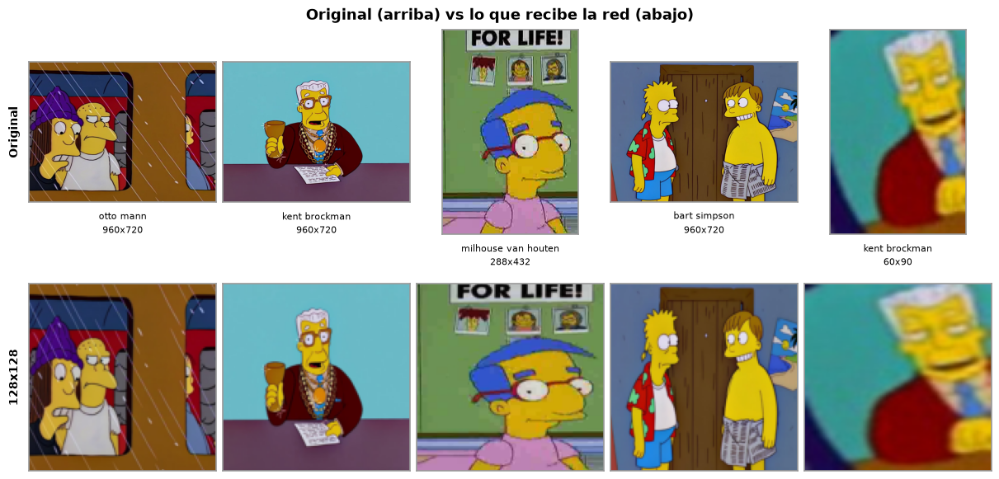

In [8]:
import matplotlib.pyplot as plt

# Comparación visual: la original y lo que recibe la red, para una muestra aleatoria
generador = np.random.default_rng(42)
muestra = generador.choice(len(datos), size=5, replace=False)

figura, ejes = plt.subplots(
    2,
    len(muestra),
    figsize=(2.4 * len(muestra), 5.8),
    layout="constrained",
)
for columna, indice in enumerate(muestra):
    fila = datos.iloc[indice]
    with Image.open(fila["ruta"]) as img:
        original = img.convert("RGB")

    personaje = fila["personaje"].replace("_", " ")
    ejes[0, columna].imshow(original)
    ejes[1, columna].imshow(imagenes[indice])

    # El texto va debajo de la imagen para que no invada la fila de arriba
    ejes[0, columna].set_xlabel(
        f"{personaje}\n{original.size[0]}x{original.size[1]}",
        fontsize=8,
        labelpad=6,
        linespacing=1.5,
    )

    for eje in (ejes[0, columna], ejes[1, columna]):
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor("#999999")
            lado.set_linewidth(1.2)

# Etiqueta de fila a la izquierda, en vez de repetir el mismo título en cada columna
ejes[0, 0].set_ylabel("Original", fontsize=10, fontweight="bold", labelpad=8)
ejes[1, 0].set_ylabel(
    f"{ANCHO_OBJETIVO}x{ALTO_OBJETIVO}", fontsize=10, fontweight="bold", labelpad=8
)

figura.suptitle("Original (arriba) vs lo que recibe la red (abajo)", fontsize=13, fontweight="bold")
plt.show()

### Normalización de los píxeles



**Por qué normalizar**
Al dividir por 255 todas las características de entrada quedan en la misma escala acotada
[0, 1]. Esto evita que unos píxeles pesen más que otros por su magnitud, mejora el
condicionamiento del descenso del gradiente y permite que la inicialización estándar de
los pesos funcione como se espera.

**Dónde se aplica**
El escalado **no se materializa aquí**, sino dentro del modelo, en la capa `Rescaling`
(sección del modelo base), y solo cuando la entrada son los píxeles: en este notebook, el
experimento R1. El motivo es de memoria y de rendimiento: convertir todas las imágenes a
`float32` multiplica por cuatro el espacio ocupado —la celda siguiente imprime las cifras de
esta corrida— y obliga a alimentar el entrenamiento desde la RAM del equipo, copiando cada
lote por el bus en cada paso.

Manteniendo los píxeles en `uint8`, el conjunto **entero cabe en la VRAM de 8 GB de la
tarjeta** y el escalado lo hace la GPU sobre cada lote, a coste despreciable.

Los descriptores de color y textura tienen escalas propias (frecuencias de un histograma,
respuestas de un filtro) y se **estandarizan** de otra forma: se les resta la media y se
dividen por la desviación de cada descriptor en entrenamiento. Se explica en su sección.

Esta celda comprueba sobre una muestra que el escalado de los píxeles es exactamente el esperado.

In [9]:
# Escalado de [0, 255] a [0, 1]: el rango con el que opera la red.
VALOR_MAXIMO_PIXEL = 255.0

# El escalado real lo aplica la capa Rescaling del modelo, ya sobre la GPU.
# Aqui solo se verifica sobre una muestra que la operacion es la esperada.
TAMANO_MUESTRA_NORMALIZACION = 512
tamano_muestra = min(TAMANO_MUESTRA_NORMALIZACION, len(imagenes))
imagenes_norm = imagenes[:tamano_muestra].astype(np.float32) / VALOR_MAXIMO_PIXEL

print(f"imagenes      : {imagenes.shape}  dtype={imagenes.dtype}"
      f"  ->  {imagenes.nbytes / 1024 ** 3:.2f} GB")
print(f"imagenes_norm : {imagenes_norm.shape}  dtype={imagenes_norm.dtype}"
      f"  (muestra de comprobacion)")
print(f"rango: [{imagenes_norm.min():.3f}, {imagenes_norm.max():.3f}]")
print(f"media: {imagenes_norm.mean():.4f}  desviacion: {imagenes_norm.std():.4f}")
print(
    f"\nEl conjunto completo en float32 ocuparia {imagenes.nbytes * 4 / 1024 ** 3:.2f} GB;"
    f" en uint8 ocupa {imagenes.nbytes / 1024 ** 3:.2f} GB y cabe entero en la VRAM."
)

imagenes      : (70855, 128, 128, 3)  dtype=uint8  ->  3.24 GB
imagenes_norm : (512, 128, 128, 3)  dtype=float32  (muestra de comprobacion)
rango: [0.000, 1.000]
media: 0.4389  desviacion: 0.2392

El conjunto completo en float32 ocuparia 12.97 GB; en uint8 ocupa 3.24 GB y cabe entero en la VRAM.


**Comprobación de la normalización**

In [10]:
indice_prueba = 0

comprobaciones_norm = pd.DataFrame(
    [
        (
            "Forma conservada (sobre la muestra)",
            str(imagenes_norm.shape),
            str(imagenes[:tamano_muestra].shape),
            imagenes_norm.shape == imagenes[:tamano_muestra].shape,
        ),
        (
            "Tipo de dato",
            str(imagenes_norm.dtype),
            "float32",
            imagenes_norm.dtype == np.float32,
        ),
        (
            "Valor mínimo",
            round(float(imagenes_norm.min()), 4),
            ">= 0.0",
            imagenes_norm.min() >= 0.0,
        ),
        (
            "Valor máximo",
            round(float(imagenes_norm.max()), 4),
            "<= 1.0",
            imagenes_norm.max() <= 1.0,
        ),
        (
            "Sin NaN ni infinitos",
            bool(np.isfinite(imagenes_norm).all()),
            True,
            bool(np.isfinite(imagenes_norm).all()),
        ),
        (
            "Escalado exacto (x255 == original)",
            "imagenes_norm * 255",
            "imagenes",
            np.allclose(
                imagenes_norm[indice_prueba] * VALOR_MAXIMO_PIXEL,
                imagenes[indice_prueba].astype(np.float32),
            ),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_norm)

if not comprobaciones_norm["Correcto"].all():
    raise ValueError("La normalización no cumple alguna de las comprobaciones.")

print("Normalización verificada correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Forma conservada (sobre la muestra),"(512, 128, 128, 3)","(512, 128, 128, 3)",True
1,Tipo de dato,float32,float32,True
2,Valor mínimo,0.0,>= 0.0,True
3,Valor máximo,1.0,<= 1.0,True
4,Sin NaN ni infinitos,True,True,True
5,Escalado exacto (x255 == original),imagenes_norm * 255,imagenes,True


Normalización verificada correctamente.


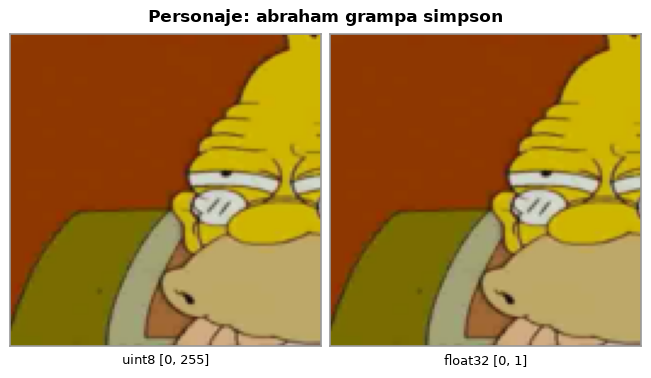

In [11]:
# La imagen normalizada debe verse idéntica a la original: solo cambia la escala numérica
figura, ejes = plt.subplots(1, 2, figsize=(6.4, 3.6), layout="constrained")

paneles = (
    (imagenes[indice_prueba], "uint8 [0, 255]"),
    (imagenes_norm[indice_prueba], "float32 [0, 1]"),
)
for eje, (imagen, etiqueta) in zip(ejes, paneles):
    eje.imshow(imagen)
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor("#999999")
        lado.set_linewidth(1.2)
    eje.set_xlabel(etiqueta, fontsize=9, labelpad=6)

personaje = datos.iloc[indice_prueba]["personaje"].replace("_", " ")
figura.suptitle(f"Personaje: {personaje}", fontsize=12, fontweight="bold")
plt.show()


### Vectorización (aplanado) de las imágenes

**Por qué aplanar y qué implica**

Una capa densa (`Dense`) recibe un vector: cada neurona se conecta con **todas** las entradas mediante
un peso. No tiene forma de aprovechar que dos píxeles estén uno al lado del otro, porque en su interior
todas las entradas son intercambiables. Por eso la imagen de `alto x ancho x 3` debe convertirse en un
único vector de longitud fija `alto * ancho * 3`.

Con la configuración ejecutada en "Redimensionado a un tamaño fijo" esto da **128 x 128 x 3 = 49 152** valores por imagen, que es la
dimensión de la capa de entrada del MLP cuando recibe píxeles (experimento R1); el modelo base
recibe en cambio los descriptores de la sección siguiente.

El aplanado es el paso donde se **pierde la estructura espacial**: el modelo ya no sabe que el píxel
`(0, 0)` y el `(0, 1)` eran vecinos. Esta es precisamente la limitación que se discute en "Limitaciones del MLP en imágenes y propuestas de mejora"
y el motivo por el que una CNN, que sí preserva esa vecindad, resulta más adecuada para imágenes.



**Por qué `X` tiene dos dimensiones e `y` solo una**

`X` es una **matriz**: una fila por imagen y una columna por característica de entrada. Su forma
`(N, 49152)` se lee como "N ejemplos, cada uno descrito por 49 152 números", donde N es el
número de imágenes elegidas en la partición. La primera
dimensión siempre cuenta ejemplos y la segunda las características de cada uno; es el formato que Keras
espera para alimentar una capa densa, que procesa las filas por lotes (batches).

`y` es un **vector**: su forma `(N,)` significa "N etiquetas", una por fila de `X`. Para
describir a qué personaje corresponde una imagen basta con un único número (el índice de la clase), así
que no hace falta una segunda dimensión. Lo único imprescindible es que `X.shape[0] == y.shape[0]` y que
el orden coincida: la etiqueta `y[i]` corresponde a la imagen `X[i]`.

Esa asimetría es solo del estado actual de los datos, no una regla: en "Codificación de las etiquetas"
se aplicará one-hot encoding y `y` pasará a ser también una matriz `(N, 64)`, con una columna por
personaje, que es lo que exige la pérdida `categorical_crossentropy`.

El orden del aplanado es `C` (por filas: fila a fila, y dentro de cada fila los tres canales RGB de cada
píxel). Lo importante no es el orden concreto, sino que sea **el mismo para todas las imágenes** y para
los conjuntos de train y test, cosa que `reshape` garantiza al aplicarse sobre el arreglo completo.


In [12]:
# Cada imagen (alto, ancho, 3) pasa a ser un vector de alto * ancho * 3 valores
DIMENSION_PIXELES = ALTO_OBJETIVO * ANCHO_OBJETIVO * 3

# Los vectores quedan en uint8: el escalado a [0, 1] lo hace la capa Rescaling
# del modelo, ya sobre la GPU. Asi el conjunto completo cabe en la VRAM de 8 GB.
X = imagenes.reshape(imagenes.shape[0], -1)
y = etiquetas

print(f"X: {X.shape}  dtype={X.dtype}")
print(f"y: {y.shape}")
print(f"Dimension del vector de pixeles: {DIMENSION_PIXELES}")
print(f"rango de X: [{int(X.min())}, {int(X.max())}]  (uint8; se escala dentro del modelo)")

X: (70855, 49152)  dtype=uint8
y: (70855,)
Dimension del vector de pixeles: 49152
rango de X: [0, 255]  (uint8; se escala dentro del modelo)


**Comprobación del aplanado**

In [13]:
# El aplanado debe ser reversible: recuperar la imagen original desde su vector
imagen_reconstruida = X[indice_prueba].reshape(ALTO_OBJETIVO, ANCHO_OBJETIVO, 3)

comprobaciones_aplanado = pd.DataFrame(
    [
        (
            "Número de imágenes",
            X.shape[0],
            imagenes.shape[0],
            X.shape[0] == imagenes.shape[0],
        ),
        (
            "Longitud del vector",
            X.shape[1],
            DIMENSION_PIXELES,
            X.shape[1] == DIMENSION_PIXELES,
        ),
        ("Número de dimensiones", X.ndim, 2, X.ndim == 2),
        ("Tipo de dato", str(X.dtype), "uint8", X.dtype == np.uint8),
        (
            "Rango conservado [0, 255]",
            f"[{int(X.min())}, {int(X.max())}]",
            "[0, 255]",
            bool(X.min() >= 0 and X.max() <= 255),
        ),
        (
            "Aplanado reversible",
            "X[i].reshape(alto, ancho, 3)",
            "imagenes[i]",
            np.array_equal(imagen_reconstruida, imagenes[indice_prueba]),
        ),
        ("Etiquetas alineadas", len(y), X.shape[0], len(y) == X.shape[0]),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_aplanado)

if not comprobaciones_aplanado["Correcto"].all():
    raise ValueError("El aplanado no cumple alguna de las comprobaciones.")

print("Aplanado verificado correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Número de imágenes,70855,70855,True
1,Longitud del vector,49152,49152,True
2,Número de dimensiones,2,2,True
3,Tipo de dato,uint8,uint8,True
4,"Rango conservado [0, 255]","[0, 255]","[0, 255]",True
5,Aplanado reversible,"X[i].reshape(alto, ancho, 3)",imagenes[i],True
6,Etiquetas alineadas,70855,70855,True


Aplanado verificado correctamente.


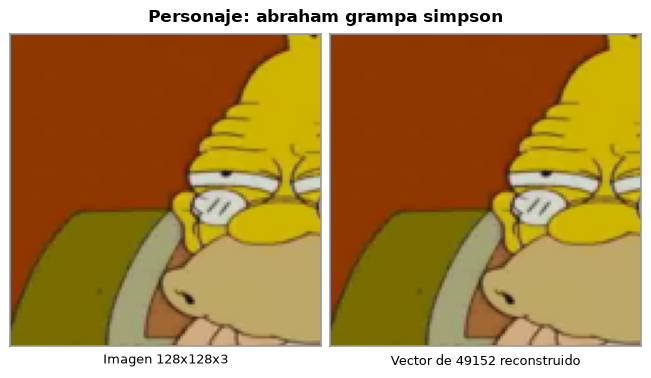

In [14]:
# Al reconstruir el vector se recupera exactamente la misma imagen
figura, ejes = plt.subplots(1, 2, figsize=(6.4, 3.6), layout="constrained")

paneles = (
    (imagenes[indice_prueba], f"Imagen {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}x3"),
    (imagen_reconstruida, f"Vector de {DIMENSION_PIXELES} reconstruido"),
)
for eje, (imagen, etiqueta) in zip(ejes, paneles):
    eje.imshow(imagen)
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor("#999999")
        lado.set_linewidth(1.2)
    eje.set_xlabel(etiqueta, fontsize=9, labelpad=6)

personaje = datos.iloc[indice_prueba]["personaje"].replace("_", " ")
figura.suptitle(f"Personaje: {personaje}", fontsize=12, fontweight="bold")
plt.show()

### Descriptores de color y textura

Un MLP sobre píxeles aplanados no sabe qué píxel estaba junto a cuál, y cada peso de su primera capa
queda atado a una posición fija del encuadre. Los descriptores atacan ese problema desde la entrada: en
lugar de 49.152 valores de color en posiciones fijas, cada imagen se resume en unos 2.460 números
que describen **qué colores y qué texturas aparecen**, y en qué zona aproximada de la imagen.

| Bloque | Qué mide | Cómo se calcula | Valores |
|---|---|---|---|
| **Color HSV** | Tono, saturación y brillo dominantes: la piel amarilla, el pelo azul de Marge | Histogramas de H (18 intervalos), S (8) y V (8) sobre la imagen completa y sobre una rejilla 2 × 2 | 170 |
| **Color Lab** | El color en un espacio perceptual, donde las distancias se parecen a las que percibe el ojo | Histogramas de L (8), a* (16) y b* (16) en las mismas cinco zonas | 200 |
| **Textura LBP** | Microtexturas: bordes finos, zonas lisas, rayas (pelo, barba, ropa) | *Local Binary Patterns* uniformes con P=8, R=1 en una rejilla 4 × 4 y con P=16, R=2 en una rejilla 2 × 2 | 232 |
| **Textura Gabor** | Patrones periódicos con una orientación y una escala concretas | Banco de 12 filtros (4 orientaciones × 3 frecuencias); media y desviación de cada respuesta en la rejilla 2 × 2 | 96 |
| **Bordes HOG** | Forma y silueta: hacia dónde apuntan los bordes en cada zona | *Histogram of Oriented Gradients* con 9 orientaciones en una rejilla de 8 × 8 celdas | 1.764 |

Con ellos se construyen cuatro **representaciones** que la experimentación compara entre sí: `pixeles`
(el vector de la sección anterior), `color` (HSV + Lab), `textura` (LBP + Gabor + HOG) y `color_textura`
(todo junto), que es la que usa el modelo base.

**Sobre la imagen completa.** Los descriptores se calculan sobre el fotograma entero: el fondo y los demás
personajes del encuadre también entran en los histogramas. Es una de las limitaciones del MLP con descriptores
(ver «Limitaciones del MLP en imágenes y propuestas de mejora»); las cajas de cada personaje se ponen después,
con el modelo ya entrenado.

**Por qué pueden ayudar a un MLP.** Un histograma no cambia si el personaje se desplaza dentro de su
zona, así que buena parte de la sensibilidad al encuadre desaparece. Además, con la misma primera capa de
512 neuronas, la entrada es unas 20 veces más pequeña que con píxeles, y la capa también. El precio es que
los filtros se eligen a mano: la red ya no aprende sus propias características, solo combina las que se
le dan.

**Estandarización.** Cada bloque tiene su propia escala: frecuencias entre 0 y 1, respuestas de filtro,
magnitudes de gradiente. Antes de entrar a la red, cada descriptor se centra y se escala con la media y
la desviación **del conjunto de entrenamiento**. Esa operación vive dentro del modelo, en una capa
`Normalization`, como el escalado de los píxeles.

In [15]:
from scipy.signal import fftconvolve
from skimage.color import rgb2gray, rgb2hsv, rgb2lab
from skimage.feature import hog, local_binary_pattern
from skimage.filters import gabor_kernel

# Color: intervalos de cada histograma y rejillas (1 = imagen completa, 2 = rejilla 2 x 2)
INTERVALOS_HSV = (18, 8, 8)
INTERVALOS_LAB = (8, 16, 16)
RANGOS_HSV = ((0, 1), (0, 1), (0, 1))
RANGOS_LAB = ((0, 100), (-128, 127), (-128, 127))
REJILLAS_COLOR = (1, 2)
# Textura: (puntos vecinos P, radio R, lado de la rejilla) de cada LBP
CONFIGURACION_LBP = ((8, 1, 4), (16, 2, 2))
# Banco de Gabor: 4 orientaciones x 3 frecuencias (ciclos por píxel)
ORIENTACIONES_GABOR = np.arange(4) * np.pi / 4
FRECUENCIAS_GABOR = (0.1, 0.2, 0.3)
NUCLEOS_GABOR = [
    np.real(gabor_kernel(frecuencia, theta=orientacion))
    for frecuencia in FRECUENCIAS_GABOR
    for orientacion in ORIENTACIONES_GABOR
]
# HOG: celdas de lado/8 píxeles, así la rejilla es de 8 x 8 celdas a cualquier resolución
ORIENTACIONES_HOG = 9
CELDAS_HOG = 8


def regiones(alto, ancho, lado):
    """Divide la imagen en una rejilla lado x lado y devuelve cada zona como un par de slices."""
    filas = np.linspace(0, alto, lado + 1, dtype=int)
    columnas = np.linspace(0, ancho, lado + 1, dtype=int)
    return [
        (slice(filas[i], filas[i + 1]), slice(columnas[j], columnas[j + 1]))
        for i in range(lado)
        for j in range(lado)
    ]


def frecuencias(codigos, intervalos):
    """Histograma normalizado de una zona cuyos valores ya son enteros entre 0 e intervalos - 1.
    np.bincount es mucho más rápido que np.histogram y aquí se llama decenas de veces por imagen."""
    return np.bincount(codigos.ravel(), minlength=intervalos) / codigos.size


def cuantizar(canal, intervalos, rango):
    """Intervalo (0 .. intervalos - 1) al que pertenece cada valor del canal dentro del rango."""
    minimo, maximo = rango
    indices = ((canal - minimo) * (intervalos / (maximo - minimo))).astype(np.int64)
    return np.clip(indices, 0, intervalos - 1)


def histogramas_color(canales, intervalos, rangos):
    """Histograma normalizado de cada canal en cada zona de cada rejilla."""
    alto, ancho = canales.shape[:2]
    cuantizados = [
        cuantizar(canales[..., indice], n, rango)
        for indice, (n, rango) in enumerate(zip(intervalos, rangos))
    ]
    partes = []
    for lado in REJILLAS_COLOR:
        for zona in regiones(alto, ancho, lado):
            for codigos, n in zip(cuantizados, intervalos):
                partes.append(frecuencias(codigos[zona], n))
    return np.concatenate(partes)


def descriptor_lbp(gris_uint8):
    """Histograma de códigos LBP uniformes en cada zona: el método "uniform" da P + 2 códigos."""
    partes = []
    for puntos, radio, lado in CONFIGURACION_LBP:
        codigos = local_binary_pattern(gris_uint8, puntos, radio, method="uniform").astype(np.int64)
        for zona in regiones(*gris_uint8.shape, lado):
            partes.append(frecuencias(codigos[zona], puntos + 2))
    return np.concatenate(partes)


def descriptor_gabor(gris):
    """Media y desviación de la respuesta de cada filtro de Gabor en cada zona de la rejilla 2 x 2."""
    zonas = regiones(*gris.shape, 2)
    partes = []
    for nucleo in NUCLEOS_GABOR:
        respuesta = np.abs(fftconvolve(gris, nucleo, mode="same"))
        for zona in zonas:
            partes.extend((respuesta[zona].mean(), respuesta[zona].std()))
    return np.asarray(partes)


def descriptor_hog(gris):
    alto, ancho = gris.shape
    return hog(
        gris,
        orientations=ORIENTACIONES_HOG,
        pixels_per_cell=(alto // CELDAS_HOG, ancho // CELDAS_HOG),
        cells_per_block=(2, 2),
        feature_vector=True,
    )


def extraer_caracteristicas(imagen):
    """Descriptores de color y textura de una imagen RGB uint8 de forma (alto, ancho, 3)."""
    gris = rgb2gray(imagen)
    gris_uint8 = np.round(gris * 255).astype(np.uint8)
    return np.concatenate(
        (
            histogramas_color(rgb2hsv(imagen), INTERVALOS_HSV, RANGOS_HSV),
            histogramas_color(rgb2lab(imagen), INTERVALOS_LAB, RANGOS_LAB),
            descriptor_lbp(gris_uint8),
            descriptor_gabor(gris),
            descriptor_hog(gris),
        )
    ).astype(np.float32)


# Posición de cada bloque dentro del vector: sirve para armar las representaciones y
# para medir después cuánto aporta cada bloque al modelo
zonas_color = sum(lado ** 2 for lado in REJILLAS_COLOR)
TAMANOS_BLOQUES = {
    "color_hsv": sum(INTERVALOS_HSV) * zonas_color,
    "color_lab": sum(INTERVALOS_LAB) * zonas_color,
    "textura_lbp": sum((puntos + 2) * lado ** 2 for puntos, _, lado in CONFIGURACION_LBP),
    "textura_gabor": len(NUCLEOS_GABOR) * 2 * 4,
    "bordes_hog": (CELDAS_HOG - 1) ** 2 * 2 * 2 * ORIENTACIONES_HOG,
}
BLOQUES = {}
inicio_bloque = 0
for nombre_bloque, tamano_bloque in TAMANOS_BLOQUES.items():
    BLOQUES[nombre_bloque] = slice(inicio_bloque, inicio_bloque + tamano_bloque)
    inicio_bloque += tamano_bloque

# Qué bloques forma cada representación de descriptores, en el orden de sus columnas
BLOQUES_POR_REPRESENTACION = {
    "color": ["color_hsv", "color_lab"],
    "textura": ["textura_lbp", "textura_gabor", "bordes_hog"],
    "color_textura": list(BLOQUES),
}
COLUMNAS_COLOR = np.r_[BLOQUES["color_hsv"], BLOQUES["color_lab"]]
COLUMNAS_TEXTURA = np.r_[BLOQUES["textura_lbp"], BLOQUES["textura_gabor"], BLOQUES["bordes_hog"]]


def columnas_de(representacion):
    """Columnas del vector completo de descriptores que usa cada representación."""
    return {"color": COLUMNAS_COLOR, "textura": COLUMNAS_TEXTURA}.get(representacion, slice(None))


def extraer_representacion(imagen, representacion="color_textura"):
    """Solo los bloques que usa una representación, en el mismo orden de columnas que
    F[:, columnas_de(representacion)]. Con "color_textura" equivale a extraer_caracteristicas;
    con "color" se ahorra la textura y los bordes, que son la parte más cara del cálculo."""
    bloques = BLOQUES_POR_REPRESENTACION[representacion]
    partes = []
    if "color_hsv" in bloques:
        partes.append(histogramas_color(rgb2hsv(imagen), INTERVALOS_HSV, RANGOS_HSV))
    if "color_lab" in bloques:
        partes.append(histogramas_color(rgb2lab(imagen), INTERVALOS_LAB, RANGOS_LAB))
    if any(bloque in bloques for bloque in ("textura_lbp", "textura_gabor", "bordes_hog")):
        gris = rgb2gray(imagen)
        if "textura_lbp" in bloques:
            partes.append(descriptor_lbp(np.round(gris * 255).astype(np.uint8)))
        if "textura_gabor" in bloques:
            partes.append(descriptor_gabor(gris))
        if "bordes_hog" in bloques:
            partes.append(descriptor_hog(gris))
    return np.concatenate(partes).astype(np.float32)


display(pd.DataFrame({"bloque": list(TAMANOS_BLOQUES), "valores": list(TAMANOS_BLOQUES.values())}))
print(f"Descriptores por imagen: {sum(TAMANOS_BLOQUES.values())}")

,bloque,valores
0,color_hsv,170
1,color_lab,200
2,textura_lbp,232
3,textura_gabor,96
4,bordes_hog,1764


Descriptores por imagen: 2462


In [16]:
def extraer_lote(lote, representacion="color_textura"):
    return np.stack([extraer_representacion(imagen, representacion) for imagen in lote])


# Cálculo en paralelo por lotes: cada proceso recibe un bloque de imágenes y no una a
# una, para que el costo de enviar los datos entre procesos no supere al del cálculo.
TAMANO_LOTE_DESCRIPTORES = 256
inicio_descriptores = time.perf_counter()
F = np.concatenate(
    Parallel(n_jobs=-1)(
        delayed(extraer_lote)(imagenes[inicio:inicio + TAMANO_LOTE_DESCRIPTORES])
        for inicio in range(0, len(imagenes), TAMANO_LOTE_DESCRIPTORES)
    )
)
segundos_descriptores = time.perf_counter() - inicio_descriptores

REPRESENTACIONES = {
    "pixeles": X,
    **{nombre: F[:, columnas_de(nombre)] for nombre in ("color", "textura", "color_textura")},
}
DIMENSIONES = {nombre: matriz.shape[1] for nombre, matriz in REPRESENTACIONES.items()}
REPRESENTACION_BASE = "color_textura"
DIMENSION_ENTRADA = DIMENSIONES[REPRESENTACION_BASE]

print(f"F: {F.shape}  dtype={F.dtype}  ({F.nbytes / 1024 ** 2:.0f} MB)")
print(
    f"Descriptores calculados en {segundos_descriptores:.1f} s"
    f" ({len(imagenes) / segundos_descriptores:,.0f} imagenes/s)"
)
display(
    pd.DataFrame(
        {"representacion": list(DIMENSIONES), "valores_por_imagen": list(DIMENSIONES.values())}
    )
)
print(f"Representacion del modelo base: {REPRESENTACION_BASE} ({DIMENSION_ENTRADA} valores)")

F: (70855, 2462)  dtype=float32  (665 MB)
Descriptores calculados en 165.8 s (427 imagenes/s)


,representacion,valores_por_imagen
0,pixeles,49152
1,color,370
2,textura,2092
3,color_textura,2462


Representacion del modelo base: color_textura (2462 valores)


**Comprobación de los descriptores**

In [17]:
# Los descriptores calculados en paralelo deben coincidir con los de una llamada directa
repeticion = extraer_caracteristicas(imagenes[indice_prueba])
suma_hsv = F[:, BLOQUES["color_hsv"]].sum(axis=1)
zonas_por_canal = len(INTERVALOS_HSV) * zonas_color

comprobaciones_descriptores = pd.DataFrame(
    [
        ("Una fila por imagen", F.shape[0], len(imagenes), F.shape[0] == len(imagenes)),
        (
            "Bloques completos",
            F.shape[1],
            sum(TAMANOS_BLOQUES.values()),
            F.shape[1] == sum(TAMANOS_BLOQUES.values()),
        ),
        ("Tipo de dato", str(F.dtype), "float32", F.dtype == np.float32),
        ("Sin NaN ni infinitos", bool(np.isfinite(F).all()), True, bool(np.isfinite(F).all())),
        (
            "Histogramas HSV normalizados",
            round(float(suma_hsv.mean()), 4),
            f"{zonas_por_canal} (cada histograma suma 1)",
            bool(np.allclose(suma_hsv, zonas_por_canal, atol=1e-3)),
        ),
        (
            "Determinista (misma imagen, mismo vector)",
            "extraer de nuevo",
            "F[i]",
            bool(np.array_equal(repeticion, F[indice_prueba])),
        ),
        (
            "Representaciones alineadas con las etiquetas",
            len(REPRESENTACIONES[REPRESENTACION_BASE]),
            len(y),
            len(REPRESENTACIONES[REPRESENTACION_BASE]) == len(y),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_descriptores)

if not comprobaciones_descriptores["Correcto"].all():
    raise ValueError("Los descriptores no cumplen alguna de las comprobaciones.")

print("Descriptores verificados correctamente.")

,Comprobacion,Obtenido,Esperado,Correcto
0,Una fila por imagen,70855,70855,True
1,Bloques completos,2462,2462,True
2,Tipo de dato,float32,float32,True
3,Sin NaN ni infinitos,True,True,True
4,Histogramas HSV normalizados,15.0,15 (cada histograma suma 1),True
5,"Determinista (misma imagen, mismo vector)",extraer de nuevo,F[i],True
6,Representaciones alineadas con las etiquetas,70855,70855,True


Descriptores verificados correctamente.


**Qué mide cada descriptor**

La figura siguiente descompone una imagen de entrenamiento en lo que miden los bloques. Los canales H y
S y los canales a* y b* de Lab son la materia prima de los histogramas de color. El mapa LBP asigna a cada
píxel un código según cómo se compara con sus vecinos: las zonas lisas y los bordes producen códigos
distintos. Las respuestas de Gabor se encienden donde hay patrones con la orientación y la escala del
filtro, y el dibujo de HOG muestra hacia dónde apuntan los bordes dominantes en cada celda.

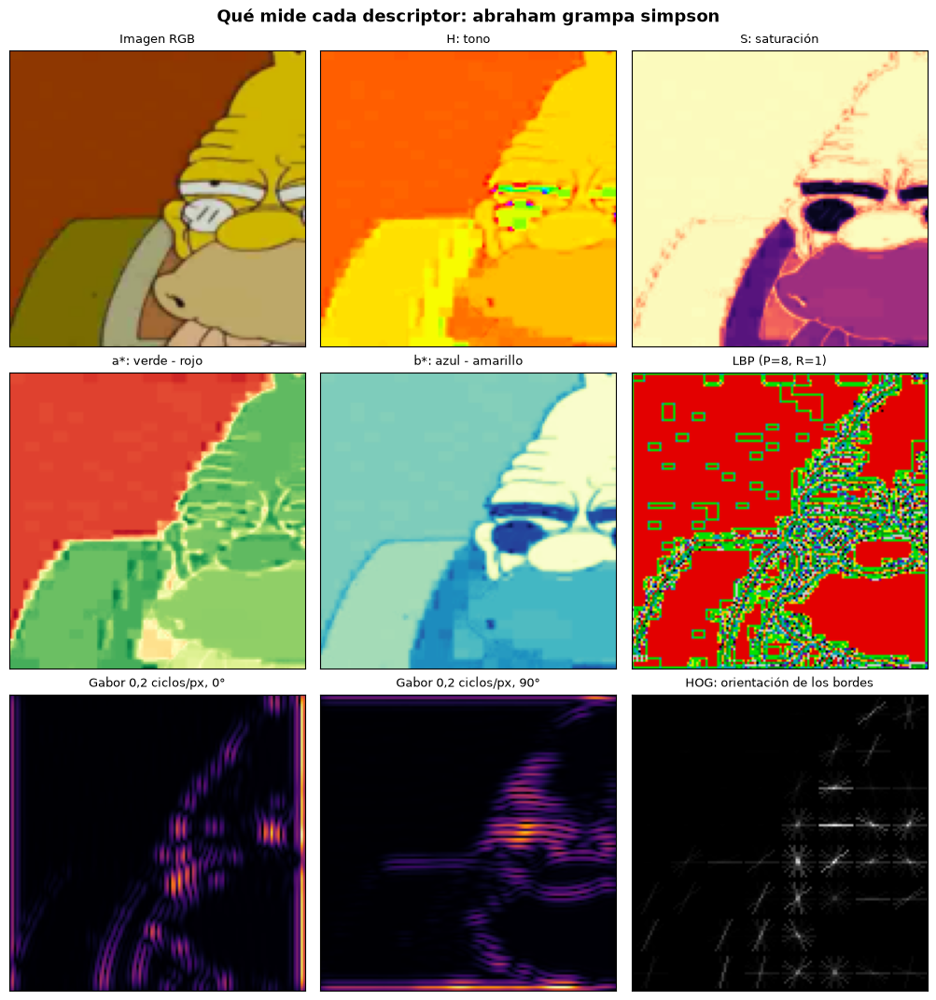

In [18]:
# Una imagen de entrenamiento descompuesta en lo que miden los descriptores
indice_demo_descriptores = int(np.flatnonzero(datos["conjunto"].to_numpy() == "train")[0])
imagen_demo = imagenes[indice_demo_descriptores]
gris_demo = rgb2gray(imagen_demo)
hsv_demo = rgb2hsv(imagen_demo)
lab_demo = rgb2lab(imagen_demo)
lbp_demo = local_binary_pattern(np.round(gris_demo * 255).astype(np.uint8), 8, 1, method="uniform")
_, hog_demo = hog(
    gris_demo,
    orientations=ORIENTACIONES_HOG,
    pixels_per_cell=(ALTO_OBJETIVO // CELDAS_HOG, ANCHO_OBJETIVO // CELDAS_HOG),
    cells_per_block=(2, 2),
    visualize=True,
)
# Núcleos 4 y 6 del banco: frecuencia 0,2 ciclos/píxel, orientaciones de 0 y 90 grados
gabor_demo = [np.abs(fftconvolve(gris_demo, NUCLEOS_GABOR[i], mode="same")) for i in (4, 6)]

paneles = [
    (imagen_demo, None, "Imagen RGB"),
    (hsv_demo[..., 0], "hsv", "H: tono"),
    (hsv_demo[..., 1], "magma", "S: saturación"),
    (lab_demo[..., 1], "RdYlGn_r", "a*: verde - rojo"),
    (lab_demo[..., 2], "YlGnBu_r", "b*: azul - amarillo"),
    (lbp_demo, "nipy_spectral", "LBP (P=8, R=1)"),
    (gabor_demo[0], "inferno", "Gabor 0,2 ciclos/px, 0°"),
    (gabor_demo[1], "inferno", "Gabor 0,2 ciclos/px, 90°"),
    (hog_demo, "gray", "HOG: orientación de los bordes"),
]

figura, ejes = plt.subplots(3, 3, figsize=(10, 10.6), layout="constrained")
for eje, (panel, mapa, titulo) in zip(np.ravel(ejes), paneles):
    eje.imshow(panel, cmap=mapa)
    eje.set_title(titulo, fontsize=9)
    eje.set_xticks([])
    eje.set_yticks([])

personaje = datos.iloc[indice_demo_descriptores]["personaje"].replace("_", " ")
figura.suptitle(f"Qué mide cada descriptor: {personaje}", fontsize=13, fontweight="bold")
plt.show()

**Imágenes alteradas por el script**

El script `scripts/newDataset/generar_imagenes_alteradas.py` aplica a cada imagen elegida un giro de 10 a
20 grados (recortando las esquinas que quedan vacías), un cambio de color (brillo, contraste, saturación
o tono) y un filtro de textura (desenfoque, nitidez, ruido o realce de bordes), con rangos moderados para
que el personaje siga siendo reconocible. La galería muestra
algunas parejas de entrenamiento, original arriba y alterada abajo, con la transformación que registró el
script en `_alteraciones.csv`.

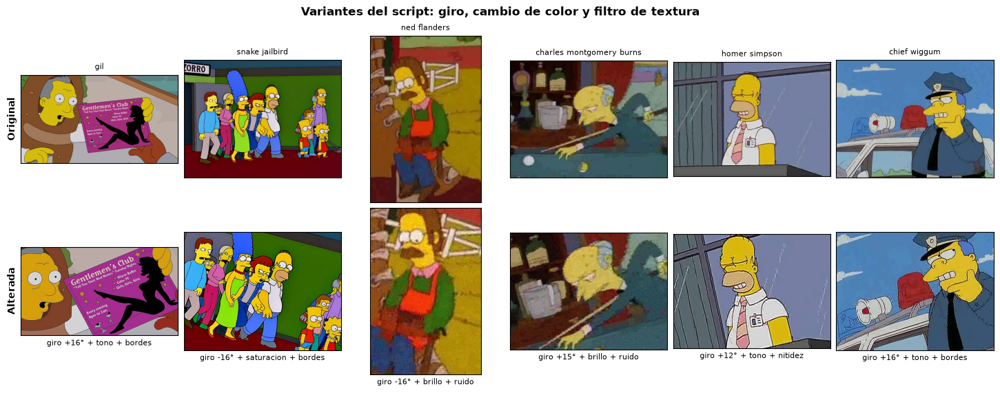

Imagenes alteradas en entrenamiento: 9952 (20.1% del conjunto)


In [19]:
# Parejas original / alterada del conjunto de entrenamiento, con la transformación aplicada
alteradas_train = datos[datos["alterada"] & (datos["conjunto"] == "train")]

if alteradas_train.empty:
    print("No hay imagenes alteradas en entrenamiento: ejecuta antes el script de alteraciones.")
else:
    transformaciones = {}
    registro_alteraciones = DATASET_BASE / "_alteraciones.csv"
    if registro_alteraciones.exists():
        registro_script = pd.read_csv(registro_alteraciones)
        con_giro = "rotacion" in registro_script.columns
        transformaciones = {
            (fila.personaje, fila.alterada): (f"giro {fila.rotacion:+.0f}° + " if con_giro else "")
            + f"{fila.color} + {fila.textura}"
            for fila in registro_script.itertuples()
        }

    muestra_alteradas = alteradas_train.sample(n=min(6, len(alteradas_train)), random_state=SEMILLA)
    figura, ejes = plt.subplots(
        2,
        len(muestra_alteradas),
        figsize=(2.4 * len(muestra_alteradas), 5.6),
        layout="constrained",
        squeeze=False,
    )
    for columna, fila in enumerate(muestra_alteradas.itertuples()):
        ruta_original = fila.ruta.with_name(fila.origen)
        for eje, ruta in ((ejes[0, columna], ruta_original), (ejes[1, columna], fila.ruta)):
            with Image.open(ruta) as img:
                eje.imshow(img.convert("RGB"))
            eje.set_xticks([])
            eje.set_yticks([])
        ejes[0, columna].set_title(fila.personaje.replace("_", " "), fontsize=8)
        ejes[1, columna].set_xlabel(
            transformaciones.get((fila.personaje, fila.ruta.name), "alterada"), fontsize=8
        )

    ejes[0, 0].set_ylabel("Original", fontsize=10, fontweight="bold")
    ejes[1, 0].set_ylabel("Alterada", fontsize=10, fontweight="bold")
    figura.suptitle(
        "Variantes del script: giro, cambio de color y filtro de textura", fontsize=12, fontweight="bold"
    )
    plt.show()

    proporcion = len(alteradas_train) / int((datos["conjunto"] == "train").sum())
    print(f"Imagenes alteradas en entrenamiento: {len(alteradas_train)} ({proporcion:.1%} del conjunto)")

**Imágenes parecidas**

Muchas imágenes del dataset son casi idénticas a otra del mismo personaje: fotogramas seguidos de una
misma escena o recortes repetidos. Si una cae en entrenamiento y su gemela en prueba, el modelo puede
acertar solo porque ya vio casi la misma imagen. El script compara las imágenes de cada personaje con
miniaturas a color de 16 x 16 (similitud coseno, umbral 0,90 por defecto) y agrupa las casi idénticas. En
cada grupo una queda intacta y cada una de las demás se reemplaza por una versión con giro, cambio de
color y filtro de textura (`<original>__parecida.<ext>`), que se vuelve a sortear hasta que deja de
parecerse a las del grupo. El notebook usa esa versión **en lugar** de la original, en cualquier
conjunto. La galería muestra algunos grupos: la imagen que quedó intacta, su casi idéntica y la versión
con la que esta entra al notebook.

Imagenes parecidas reemplazadas: 9042 en 6293 grupos   |   similitud mediana con su gemela: 0.98 antes y 0.55 despues del filtro


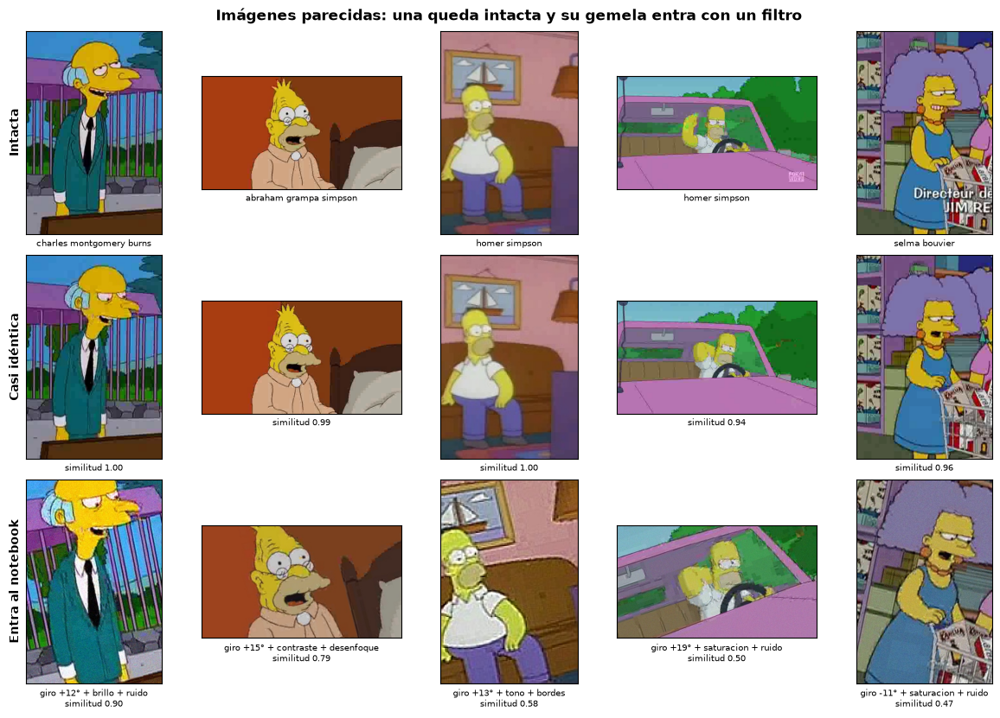

In [20]:
# Grupos de imágenes parecidas: la representante queda intacta y cada casi idéntica entra
# al notebook con su versión filtrada
registro_parecidas = DATASET_BASE / "_parecidas.csv"
if not registro_parecidas.exists():
    print("No hay registro de imagenes parecidas: ejecuta antes el script de alteraciones.")
else:
    parecidas_script = pd.read_csv(registro_parecidas)
    print(
        f"Imagenes parecidas reemplazadas: {len(parecidas_script)} en {parecidas_script['grupo'].nunique()} grupos"
        f"   |   similitud mediana con su gemela: {parecidas_script['similitud_original'].median():.2f} antes"
        f" y {parecidas_script['similitud_final'].median():.2f} despues del filtro"
    )
    muestra_parecidas = parecidas_script.sample(n=min(5, len(parecidas_script)), random_state=SEMILLA)
    figura, ejes = plt.subplots(
        3,
        len(muestra_parecidas),
        figsize=(2.4 * len(muestra_parecidas), 8.2),
        layout="constrained",
        squeeze=False,
    )
    for columna, fila in enumerate(muestra_parecidas.itertuples()):
        carpeta = DATASET_BASE / fila.personaje
        paneles = (
            (fila.representante, fila.personaje.replace("_", " ")),
            (fila.original, f"similitud {fila.similitud_original:.2f}"),
            (
                fila.parecida,
                f"giro {fila.rotacion:+.0f}° + {fila.color} + {fila.textura}\nsimilitud {fila.similitud_final:.2f}",
            ),
        )
        for numero_fila, (nombre_archivo, texto) in enumerate(paneles):
            eje = ejes[numero_fila, columna]
            with Image.open(carpeta / nombre_archivo) as img:
                eje.imshow(img.convert("RGB"))
            eje.set_xticks([])
            eje.set_yticks([])
            eje.set_xlabel(texto, fontsize=7)

    ejes[0, 0].set_ylabel("Intacta", fontsize=10, fontweight="bold")
    ejes[1, 0].set_ylabel("Casi idéntica", fontsize=10, fontweight="bold")
    ejes[2, 0].set_ylabel("Entra al notebook", fontsize=10, fontweight="bold")
    figura.suptitle(
        "Imágenes parecidas: una queda intacta y su gemela entra con un filtro", fontsize=12, fontweight="bold"
    )
    plt.show()

### Codificación de las etiquetas

**De nombre de carpeta a vector one-hot**

Las etiquetas nacen como texto (el nombre de la carpeta, por ejemplo `homer_simpson`) y una red no opera
con texto, así que hay que convertirlas a números. La conversión se hace en dos pasos:

1. **Índice entero.** Ya se construyó en "Carga de imágenes y etiquetas": `clases` es la lista de
   personajes ordenada alfabéticamente y `clase_a_indice` asigna a cada uno un entero de 0 a 63. Ese
   mapeo se reutiliza aquí en lugar de recalcularlo, porque debe ser **idéntico en train y en test**: si
   el índice 3 significara un personaje distinto en cada conjunto, la evaluación no tendría sentido.

2. **One-hot encoding.** El índice entero por sí solo es engañoso para el modelo: sugiere un **orden** y
   una **distancia** que no existen (que la clase 5 este "entre" la 4 y la 6, o que la 63 sea "mayor" que
   la 1). Los personajes son categorías nominales, sin orden. El one-hot elimina ese artefacto
   representando cada etiqueta como un vector de 64 posiciones con un 1 en la clase correcta y 0 en el
   resto, de modo que todas las clases quedan a la misma distancia entre sí.

Además, esta forma es la que corresponde a la salida de la red: la capa final tiene 64 neuronas con
`softmax`, que produce un vector de 64 probabilidades. La pérdida `categorical_crossentropy` compara ese
vector con el one-hot real, penalizando la probabilidad asignada a la clase verdadera.

> Existe la alternativa de dejar `y` como enteros y usar `sparse_categorical_crossentropy`, que es
> equivalente y ahorra memoria. Aquí se usa one-hot explícito porque hace visible la correspondencia con
> las 64 neuronas de salida, que es justamente lo que interesa mostrar en este trabajo.


In [21]:
NUMERO_CLASES = len(clases)

# One-hot: la fila i de la matriz identidad es el vector con un 1 en la posición i
# Equivale a keras.utils.to_categorical(y, NUMERO_CLASES), sin cargar TensorFlow todavía
y_onehot = np.eye(NUMERO_CLASES, dtype=np.float32)[y]

print(f"Numero de clases: {NUMERO_CLASES}")
print(f"y (indices):  {y.shape}  dtype={y.dtype}")
print(f"y_onehot:     {y_onehot.shape}  dtype={y_onehot.dtype}")

# Correspondencia para una imagen concreta
posicion_activa = int(y_onehot[indice_prueba].argmax())
print(
    f"\nEjemplo (imagen {indice_prueba}): '{datos.iloc[indice_prueba]['personaje']}'"
    f" -> indice {y[indice_prueba]} -> posicion activa {posicion_activa}"
)
print(f"vector one-hot: {y_onehot[indice_prueba].astype(int)}")


Numero de clases: 64
y (indices):  (70855,)  dtype=int64
y_onehot:     (70855, 64)  dtype=float32

Ejemplo (imagen 0): 'abraham_grampa_simpson' -> indice 0 -> posicion activa 0
vector one-hot: [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


**Comprobación de la codificación**

In [22]:
comprobaciones_etiquetas = pd.DataFrame(
    [
        (
            "Número de ejemplos",
            y_onehot.shape[0],
            X.shape[0],
            y_onehot.shape[0] == X.shape[0],
        ),
        (
            "Columnas = número de clases",
            y_onehot.shape[1],
            NUMERO_CLASES,
            y_onehot.shape[1] == NUMERO_CLASES,
        ),
        ("Tipo de dato", str(y_onehot.dtype), "float32", y_onehot.dtype == np.float32),
        (
            "Un único 1 por fila",
            float(y_onehot.sum(axis=1).min()),
            1.0,
            bool(np.all(y_onehot.sum(axis=1) == 1.0)),
        ),
        (
            "Solo valores 0 o 1",
            sorted(np.unique(y_onehot).tolist()),
            [0.0, 1.0],
            bool(np.isin(np.unique(y_onehot), [0.0, 1.0]).all()),
        ),
        (
            "Coincide con el índice entero",
            "y_onehot.argmax(axis=1)",
            "y",
            bool(np.array_equal(y_onehot.argmax(axis=1), y)),
        ),
        (
            "Todas las clases presentes",
            int((y_onehot.sum(axis=0) > 0).sum()),
            NUMERO_CLASES,
            int((y_onehot.sum(axis=0) > 0).sum()) == NUMERO_CLASES,
        ),
        (
            "Mapeo estable (índice -> nombre)",
            indice_a_clase[0],
            clases[0],
            indice_a_clase[0] == clases[0],
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_etiquetas)

if not comprobaciones_etiquetas["Correcto"].all():
    raise ValueError("La codificación de etiquetas no cumple alguna de las comprobaciones.")

print("Codificación verificada correctamente.")


,Comprobacion,Obtenido,Esperado,Correcto
0,Número de ejemplos,70855,70855,True
1,Columnas = número de clases,64,64,True
2,Tipo de dato,float32,float32,True
3,Un único 1 por fila,1.0,1.0,True
4,Solo valores 0 o 1,"[0.0, 1.0]","[0.0, 1.0]",True
5,Coincide con el índice entero,y_onehot.argmax(axis=1),y,True
6,Todas las clases presentes,64,64,True
7,Mapeo estable (índice -> nombre),abraham_grampa_simpson,abraham_grampa_simpson,True


Codificación verificada correctamente.


In [23]:
# Diccionario de clases: índice, nombre y ejemplos disponibles
tabla_clases = pd.DataFrame(
    {
        "indice": range(NUMERO_CLASES),
        "personaje": clases,
        "imagenes": [int((y == indice).sum()) for indice in range(NUMERO_CLASES)],
    }
)
tabla_clases["porcentaje"] = (tabla_clases["imagenes"] / len(y) * 100).round(2)

display(tabla_clases)


,indice,personaje,imagenes,porcentaje
0,0,abraham_grampa_simpson,1299,1.83
1,1,agnes_skinner,739,1.04
2,2,apu_nahasapeemapetilon,1001,1.41
3,3,barney_gumble,1196,1.69
4,4,bart_simpson,2425,3.42
...,...,...,...,...
59,59,sideshow_mel,784,1.11
60,60,snake_jailbird,834,1.18
61,61,todd_flanders,405,0.57
62,62,troy_mcclure,755,1.07


### Escenas con varios personajes

La etiqueta de cada imagen es su carpeta, pero un fotograma puede mostrar a más de un personaje: Lou junto
a Wiggum, Smithers junto a Burns, Barney en el bar de Moe. El modelo ve la imagen completa, así que puede
nombrar al otro personaje de la escena; con el criterio de acierto, nombrar a otro es un error.

Esta sección se conserva para una **métrica de referencia**, la accuracy por escena, que acepta como acierto
nombrar a un personaje presente. Es lo que medían como acierto las corridas anteriores, sin su verificación por
imagen, y permite compararlas. Los **fotogramas de episodio** del dataset traen en su nombre el episodio y el
instante (`personaje__S02E15__t0675633.jpg`, con `t` en milisegundos), y con eso se estima quién más aparece en
la escena sin anotar nada a mano:

- **Otro personaje en la misma escena.** Si la carpeta de otro personaje tiene un fotograma del mismo
  episodio a menos de `VENTANA_ESCENA_MS` (3 s), se asume que ese personaje también está en la escena. Es
  una heurística: tres segundos suelen ser el mismo plano, pero un corte de cámara puede caer en medio.
- **Nombre de archivo de otro personaje.** Los fotogramas que el equipo movió a la carpeta de su
  protagonista conservan el nombre del personaje con el que se extrajeron, que también está en el
  encuadre.
- **Gemela en la carpeta de otro personaje.** El script de alteraciones compara las imágenes de carpetas
  distintas y registra en `_gemelas.csv` las casi idénticas (similitud ≥ 0,90): es la misma escena
  guardada dos veces, así que los dos personajes están en ella. Esta fuente también alcanza a las
  imágenes de Kaggle.

Las imágenes que vienen del dataset de Kaggle (`homer_simpson_0001.jpg`) no traen episodio ni instante:
solo tienen acompañantes si tienen una gemela.

**Cómo se usa.** No se usa al entrenar: el objetivo de cada imagen es el one-hot de su carpeta, con el
suavizado de 0,1. Al evaluar, solo alimenta la accuracy por escena, que se informa como referencia. Por eso
la escena se calcula con todos los fotogramas y todas las gemelas: se lee después de predecir y no influye en
el modelo.

In [24]:
import re

# Fotogramas de episodio: <personaje>__<episodio>__t<milisegundos>
PATRON_FOTOGRAMA = re.compile(r"^(?P<nombre>.+?)__(?P<episodio>S\d+E\d+)__t(?P<ms>\d+)$", re.IGNORECASE)
VENTANA_ESCENA_MS = 3000


def leer_fotograma(nombre_archivo):
    """(personaje del nombre, episodio, ms) de un fotograma de episodio, o None si no lo es."""
    coincidencia = PATRON_FOTOGRAMA.match(Path(nombre_archivo).stem)
    if coincidencia is None:
        return None
    return coincidencia["nombre"], coincidencia["episodio"].upper(), int(coincidencia["ms"])


def construir_lineas_tiempo(tabla):
    """Fotogramas de cada episodio ordenados por instante: {episodio: (instantes, personajes)}."""
    por_episodio = {}
    for personaje, origen in zip(tabla["personaje"], tabla["origen"]):
        fotograma = leer_fotograma(origen)
        if fotograma is not None:
            por_episodio.setdefault(fotograma[1], []).append((fotograma[2], personaje))
    lineas = {}
    for episodio, fotogramas in por_episodio.items():
        fotogramas.sort()
        lineas[episodio] = (np.array([ms for ms, _ in fotogramas]), [p for _, p in fotogramas])
    return lineas


def personajes_en_escena(personaje, origen, lineas_tiempo):
    """Personajes que probablemente acompañan al de la carpeta en esa imagen (sin incluirlo)."""
    fotograma = leer_fotograma(origen)
    if fotograma is None:
        return frozenset()
    nombre, episodio, ms = fotograma
    acompanantes = {nombre} if nombre != personaje and nombre in clase_a_indice else set()
    if episodio in lineas_tiempo:
        instantes, personajes = lineas_tiempo[episodio]
        desde = np.searchsorted(instantes, ms - VENTANA_ESCENA_MS, side="left")
        hasta = np.searchsorted(instantes, ms + VENTANA_ESCENA_MS, side="right")
        acompanantes.update(otro for otro in personajes[desde:hasta] if otro != personaje)
    return frozenset(acompanantes)


# Gemelas entre personajes: la misma escena guardada en la carpeta de otro personaje. Las detecta el
# script de alteraciones comparando las originales de carpetas distintas
registro_gemelas = DATASET_BASE / "_gemelas.csv"
GEMELAS = {}
n_pares_gemelas = 0
if registro_gemelas.exists():
    pares_gemelas = pd.read_csv(registro_gemelas)
    pares_gemelas = pares_gemelas[
        pares_gemelas["personaje"].isin(clase_a_indice) & pares_gemelas["otro_personaje"].isin(clase_a_indice)
    ]
    n_pares_gemelas = len(pares_gemelas)
    for fila in pares_gemelas.itertuples():
        GEMELAS.setdefault((fila.personaje, fila.original), set()).add((fila.otro_personaje, fila.otro_original))
        GEMELAS.setdefault((fila.otro_personaje, fila.otro_original), set()).add((fila.personaje, fila.original))
else:
    print("No hay registro de gemelas entre personajes: ejecuta antes el script de alteraciones.")


def personajes_gemelos(personaje, origen):
    """Personajes en cuya carpeta hay una imagen casi idéntica a esta."""
    return frozenset(otro for otro, _ in GEMELAS.get((personaje, origen), ()))


# Línea de tiempo con todos los fotogramas originales del dataset: la escena solo se lee después de predecir,
# para la métrica de referencia, y no influye en el modelo
originales_indexados = indice_completo[
    ~indice_completo["alterada"] & indice_completo["personaje"].isin(clase_a_indice)
]
LINEAS_TIEMPO_COMPLETAS = construir_lineas_tiempo(originales_indexados)
escena_evaluacion = [
    personajes_en_escena(p, o, LINEAS_TIEMPO_COMPLETAS) | personajes_gemelos(p, o)
    for p, o in zip(datos["personaje"], datos["origen"])
]
datos["escena"] = [", ".join(sorted(acompanantes)) for acompanantes in escena_evaluacion]

es_fotograma = np.array([leer_fotograma(origen) is not None for origen in datos["origen"]])
con_gemela = np.array([bool(personajes_gemelos(p, o)) for p, o in zip(datos["personaje"], datos["origen"])])
con_escena_evaluacion = np.array([bool(acompanantes) for acompanantes in escena_evaluacion])

resumen_escena = pd.DataFrame(
    [
        (
            nombre,
            int(mascara.sum()),
            int(es_fotograma[mascara].sum()),
            int(con_gemela[mascara].sum()),
            int(con_escena_evaluacion[mascara].sum()),
        )
        for nombre in CONJUNTOS
        for mascara in [(datos["conjunto"] == nombre).to_numpy()]
    ],
    columns=["conjunto", "imagenes", "fotogramas", "con_gemela", "escena_compartida"],
)
display(resumen_escena)

# Parejas de personajes que más comparten escena (solo originales)
pares_escena = (
    pd.DataFrame(
        [
            (personaje, otro)
            for personaje, acompanantes, alterada in zip(datos["personaje"], escena_evaluacion, datos["alterada"])
            if not alterada
            for otro in acompanantes
        ],
        columns=["personaje", "acompanante"],
    )
    .value_counts()
    .head(10)
    .reset_index(name="imagenes")
)
display(pares_escena)

if not all(p not in a for p, a in zip(datos["personaje"], escena_evaluacion)):
    raise ValueError("Alguna imagen aparece acompañada por el personaje de su propia carpeta.")

print(
    f"Fotogramas de episodio: {int(es_fotograma.sum())} de {len(datos)} imagenes"
    f"   |   con gemela en otra carpeta: {int(con_gemela.sum())} ({n_pares_gemelas} pares)"
    f"   |   con escena compartida: {int(con_escena_evaluacion.sum())}"
)

,conjunto,imagenes,fotogramas,con_gemela,escena_compartida
0,train,49625,30252,6145,12003
1,val,14172,8607,1727,3345
2,test,7058,4279,860,1674


,personaje,acompanante,imagenes
0,lou,chief_wiggum,354
1,chief_wiggum,lou,313
2,patty_bouvier,selma_bouvier,307
3,selma_bouvier,patty_bouvier,299
4,gary_chalmers,principal_skinner,276
5,fat_tony,louie,234
6,louie,fat_tony,220
7,rod_flanders,todd_flanders,212
8,jimbo_jones,kearney_zzyzwicz,201
9,carl_carlson,lenny_leonard,194


Fotogramas de episodio: 43138 de 70855 imagenes   |   con gemela en otra carpeta: 8732 (6222 pares)   |   con escena compartida: 17022


### Partición train / validación / test

**Por qué hacen falta tres conjuntos y no dos**

Entrenar mirando el conjunto de prueba es hacer trampa: en cuanto se usa para decidir cuántas capas
poner, cuándo detener el entrenamiento o qué representación elegir, deja de ser una estimación honesta
del desempeño con datos nuevos, porque esas decisiones ya lo incorporaron. Ese fenómeno se conoce como
fuga de información.

Por eso cada personaje se repartió, en «Partición y selección por personaje», en tres conjuntos:

- **Entrenamiento (70 % de las originales):** las imágenes con las que se ajustan los pesos.
- **Validación (20 % de las originales):** imágenes que nunca actualizan pesos, pero que se miden en
  cada época. Sirven para trazar las curvas de aprendizaje, detectar sobreajuste, activar la parada
  temprana y comparar las configuraciones de la experimentación.
- **Test (10 % de las originales):** se reserva intacto y se abre **una sola vez**, en la evaluación
  final del modelo elegido.

Cada conjunto lleva además las variantes alteradas de sus propias originales y la versión filtrada de las
casi idénticas, así que los tres tienen las mismas condiciones.

**Partición estratificada.** Validación y test conservan, para cada personaje, la misma proporción que
tiene en el dataset completo. Con 64 clases muy desbalanceadas, un reparto aleatorio simple podría dejar
a un personaje minoritario con muy pocos ejemplos de validación —o con ninguno—, y entonces su métrica
sería pura casualidad.

**Semilla fija.** `random_state=SEMILLA` garantiza que la partición sea siempre la misma. Es un
requisito de la metodología de experimentación: al cambiar un solo factor por vez, la diferencia
observada debe deberse a ese factor y no a que le tocó un reparto de datos distinto.

La celda siguiente solo materializa esa partición: separa las filas de cada matriz según el conjunto
que se asignó a cada imagen.

In [25]:
# La partición ya está decidida en la columna "conjunto" de datos: aquí solo se
# separan las filas de cada matriz
MASCARAS = {nombre: (datos["conjunto"] == nombre).to_numpy() for nombre in CONJUNTOS}

_particiones = {}


def particion(representacion):
    """Filas de train, validación y test de una representación. Se calculan la primera vez
    que se piden: la de píxeles ocupa bastante memoria y solo la usa el experimento R1."""
    if representacion not in _particiones:
        matriz = REPRESENTACIONES[representacion]
        _particiones[representacion] = {
            nombre: matriz[mascara] for nombre, mascara in MASCARAS.items()
        }
    return _particiones[representacion]


# Etiquetas e imágenes de cada conjunto (las de test se usan en el análisis de errores).
# Los tres conjuntos usan el one-hot de la carpeta: cada imagen es la de su personaje.
y_train, y_val, y_test = (y_onehot[MASCARAS[nombre]] for nombre in CONJUNTOS)
y_train_idx, y_val_idx, y_test_idx = (y[MASCARAS[nombre]] for nombre in CONJUNTOS)
imagenes_test = imagenes[MASCARAS["test"]]
datos_test = datos[MASCARAS["test"]].reset_index(drop=True)

# Matrices de la representación del modelo base
X_train, X_val, X_test = (particion(REPRESENTACION_BASE)[nombre] for nombre in CONJUNTOS)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")
# Las proporciones se miden sobre las originales: las alteradas son variantes extra que van
# al mismo conjunto que su original
es_alterada = datos["alterada"].to_numpy()
n_originales = {nombre: int((MASCARAS[nombre] & ~es_alterada).sum()) for nombre in CONJUNTOS}
n_alteradas = {nombre: int((MASCARAS[nombre] & es_alterada).sum()) for nombre in CONJUNTOS}
total = sum(n_originales.values())
print(
    "\nReparto de las originales: "
    + " / ".join(f"{n_originales[nombre]} {nombre} ({n_originales[nombre] / total * 100:.1f} %)" for nombre in CONJUNTOS)
)
for nombre in CONJUNTOS:
    print(
        f"{nombre:<5}: {n_originales[nombre]} originales + {n_alteradas[nombre]} alteradas"
        f" = {n_originales[nombre] + n_alteradas[nombre]} imagenes"
    )
print(f"Representacion del modelo base: {REPRESENTACION_BASE} ({X_train.shape[1]} valores por imagen)")

X_train: (49625, 2462)   y_train: (49625, 64)
X_val:   (14172, 2462)   y_val:   (14172, 64)
X_test:  (7058, 2462)   y_test:  (7058, 64)

Reparto de las originales: 39673 train (70.0 %) / 11335 val (20.0 %) / 5668 test (10.0 %)
train: 39673 originales + 9952 alteradas = 49625 imagenes
val  : 11335 originales + 2837 alteradas = 14172 imagenes
test : 5668 originales + 1390 alteradas = 7058 imagenes
Representacion del modelo base: color_textura (2462 valores por imagen)


**Comprobación de la partición**

In [26]:
# Proporción de cada personaje en el dataset completo frente a validación y test
proporcion_dataset = originales["personaje"].value_counts(normalize=True)
proporciones = pd.DataFrame(
    {
        "personaje": clases,
        "dataset_%": [round(float(proporcion_dataset[clase]) * 100, 2) for clase in clases],
        "val_%": [round((y_val_idx == i).mean() * 100, 2) for i in range(NUMERO_CLASES)],
        "test_%": [round((y_test_idx == i).mean() * 100, 2) for i in range(NUMERO_CLASES)],
        "n_train": [int((y_train_idx == i).sum()) for i in range(NUMERO_CLASES)],
        "n_val": [int((y_val_idx == i).sum()) for i in range(NUMERO_CLASES)],
        "n_test": [int((y_test_idx == i).sum()) for i in range(NUMERO_CLASES)],
    }
)
proporciones["desviacion_%"] = (
    proporciones[["val_%", "test_%"]].sub(proporciones["dataset_%"], axis=0).abs().max(axis=1).round(2)
)

display(proporciones)

# Una imagen y sus variantes se identifican por (personaje, original de la que salen)
origenes = {
    nombre: set(zip(datos.loc[MASCARAS[nombre], "personaje"], datos.loc[MASCARAS[nombre], "origen"]))
    for nombre in CONJUNTOS
}
compartidas = (
    len(origenes["train"] & origenes["val"])
    + len(origenes["train"] & origenes["test"])
    + len(origenes["val"] & origenes["test"])
)
# Mismas condiciones en los tres conjuntos: cuántas alteradas y parecidas hay por cada original
TOLERANCIA_CONDICIONES = 0.03


def por_original(columna):
    return {
        nombre: float(datos.loc[MASCARAS[nombre], columna].sum())
        / max(int((MASCARAS[nombre] & ~datos["alterada"].to_numpy()).sum()), 1)
        for nombre in CONJUNTOS
    }


alteradas_por_original = por_original("alterada")
parecidas_por_original = por_original("parecida")
proporciones_obtenidas = {
    nombre: (MASCARAS[nombre] & ~datos["alterada"].to_numpy()).sum() / (~datos["alterada"]).sum()
    for nombre in CONJUNTOS
}
clases_por_conjunto = [len(np.unique(indices)) for indices in (y_train_idx, y_val_idx, y_test_idx)]

comprobaciones_particion = pd.DataFrame(
    [
        (
            "Cada imagen en un solo conjunto",
            int(sum(mascara.sum() for mascara in MASCARAS.values())),
            len(datos),
            int(sum(mascara.sum() for mascara in MASCARAS.values())) == len(datos),
        ),
        ("Sin imágenes compartidas entre conjuntos", compartidas, 0, compartidas == 0),
        *[
            (
                f"{nombre} por original en train / val / test",
                " / ".join(f"{proporciones_tipo[conjunto]:.1%}" for conjunto in CONJUNTOS),
                f"iguales (± {TOLERANCIA_CONDICIONES:.0%})",
                all(
                    abs(proporciones_tipo[conjunto] - proporciones_tipo["train"]) <= TOLERANCIA_CONDICIONES
                    for conjunto in CONJUNTOS
                ),
            )
            for nombre, proporciones_tipo in (
                ("Alteradas", alteradas_por_original),
                ("Parecidas", parecidas_por_original),
            )
        ],
        (
            "Todas las originales repartidas (sin tope)",
            int((~datos["alterada"]).sum()),
            len(originales),
            int((~datos["alterada"]).sum()) == len(originales),
        ),
        (
            "Proporciones train / val / test de las originales",
            " / ".join(f"{proporciones_obtenidas[nombre]:.1%}" for nombre in CONJUNTOS),
            " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS),
            all(abs(proporciones_obtenidas[nombre] - PROPORCIONES[nombre]) < 0.005 for nombre in CONJUNTOS),
        ),
        (
            "Dimensión de entrada intacta",
            X_train.shape[1],
            DIMENSION_ENTRADA,
            X_train.shape[1] == DIMENSION_ENTRADA,
        ),
        ("X e y alineados en train", len(y_train), len(X_train), len(y_train) == len(X_train)),
        ("X e y alineados en validación", len(y_val), len(X_val), len(y_val) == len(X_val)),
        ("X e y alineados en test", len(y_test), len(X_test), len(y_test) == len(X_test)),
        (
            "One-hot coherente con índices",
            "y_val.argmax(axis=1)",
            "y_val_idx",
            bool(np.array_equal(np.argmax(y_val, axis=1), y_val_idx)),
        ),
        (
            "Todas las clases en train / val / test",
            " / ".join(str(n) for n in clases_por_conjunto),
            NUMERO_CLASES,
            all(n == NUMERO_CLASES for n in clases_por_conjunto),
        ),
        (
            "Estratificación de val y test (desviación máxima)",
            f"{proporciones['desviacion_%'].max():.2f} %",
            "< 1 %",
            bool(proporciones["desviacion_%"].max() < 1.0),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_particion)

if not comprobaciones_particion["Correcto"].all():
    raise ValueError("La partición no cumple alguna de las comprobaciones.")

print("Partición verificada correctamente.")

,personaje,dataset_%,val_%,test_%,n_train,n_val,n_test,desviacion_%
0,abraham_grampa_simpson,1.83,1.83,1.88,906,260,133,0.05
1,agnes_skinner,1.04,1.09,1.05,511,154,74,0.05
2,apu_nahasapeemapetilon,1.41,1.45,1.33,702,205,94,0.08
3,barney_gumble,1.69,1.69,1.70,836,240,120,0.01
4,bart_simpson,3.42,3.46,3.39,1696,490,239,0.04
...,...,...,...,...,...,...,...,...
59,sideshow_mel,1.11,1.08,1.05,557,153,74,0.06
60,snake_jailbird,1.18,1.22,1.12,582,173,79,0.06
61,todd_flanders,0.57,0.57,0.54,286,81,38,0.03
62,troy_mcclure,1.07,1.07,1.05,530,151,74,0.02


,Comprobacion,Obtenido,Esperado,Correcto
0,Cada imagen en un solo conjunto,70855,70855,True
1,Sin imágenes compartidas entre conjuntos,0,0,True
2,Alteradas por original en train / val / test,25.1% / 25.0% / 24.5%,iguales (± 3%),True
3,Parecidas por original en train / val / test,16.1% / 15.9% / 15.3%,iguales (± 3%),True
4,Todas las originales repartidas (sin tope),56676,56676,True
5,Proporciones train / val / test de las originales,70.0% / 20.0% / 10.0%,70% / 20% / 10%,True
6,Dimensión de entrada intacta,2462,2462,True
7,X e y alineados en train,49625,49625,True
8,X e y alineados en validación,14172,14172,True
9,X e y alineados en test,7058,7058,True


Partición verificada correctamente.


### Tratamiento del desbalance de clases

**El problema**

Como se describió en "Definición del problema de clasificación", el dataset está muy desbalanceado
(razón aproximada 21:1 entre `homer_simpson` y `maggie_simpson`). Esto sesga el entrenamiento: la pérdida es un
promedio sobre los ejemplos del batch, así que los personajes abundantes dominan el gradiente y el
modelo aprende que, ante la duda, conviene predecir una clase mayoritaria. El resultado típico es un
accuracy global aceptable acompañado de un recall muy bajo en las clases pequeñas, que es precisamente
lo que el **F1 macro** —promedio no ponderado entre clases— deja al descubierto.

**Opciones consideradas**

| Estrategia | Qué hace | Por qué se descarta o se elige |
|---|---|---|
| Submuestreo de mayoritarias | Limita cada personaje a un tope de originales en entrenamiento | Se descarta: una corrida anterior con un tope de 300 dejaba sin usar unas 12.700 imágenes, y los personajes frecuentes, recortados en entrenamiento pero completos en validación y test, caían por debajo de un 20 % de recall (Homero 0,16, Bart 0,15) |
| Sobremuestreo por duplicado | Repite imágenes de las clases pequeñas | Se descarta: los duplicados exactos favorecen el sobreajuste a esas imágenes |
| **Aumento de datos** | Añade variantes alteradas con un giro de 10 a 20°, un cambio de color y un filtro de textura | **Se elige:** las genera una sola vez el script `generar_imagenes_alteradas.py` para un cuarto de las imágenes de cada personaje. Cada una va al mismo conjunto que su original: en entrenamiento aumenta los datos, y en validación y prueba hace que el modelo se mida en las mismas condiciones |
| **Pesos por clase suavizados** | Pondera la pérdida según la frecuencia de cada clase | **Se elige:** compensa el desbalance sin descartar datos. Se usa la raíz cuadrada del peso balanceado: con 21:1 en entrenamiento, el balanceado completo daría a `maggie_simpson` unas 21 veces el peso de Homero y empujaría al modelo a no predecir a los frecuentes. Los experimentos P1 y P2 comparan sin pesos y con los balanceados completos |

**Cómo funciona `class_weight`.** Keras multiplica la pérdida de cada ejemplo por el peso de su clase, de
modo que equivocarse en un personaje raro cuesta más que equivocarse en uno frecuente. Se usa la fórmula
`n_muestras / (n_clases * n_ejemplos_de_la_clase)`, que da peso 1 a una clase de tamaño medio, mayor que 1
a las minoritarias y menor que 1 a las mayoritarias. El modelo base usa su **raíz cuadrada**, reescalada
para que el peso medio por imagen siga siendo 1: la pérdida conserva su escala y la razón entre el peso
mayor y el menor baja de unas 21 a unas 4,6 veces.

**Advertencia importante.** Los pesos se calculan **solo con `y_train`**, nunca con el conjunto completo
ni con validación: usar información de validación para ajustar el entrenamiento sería otra forma de fuga.
Y se aplican **solo durante el entrenamiento**: las métricas de validación y test se miden sin pesos,
porque deben reflejar el desempeño sobre la distribución real de los datos.

El efecto conjunto de estas tres decisiones se lee en la evaluación, comparando la accuracy con el F1
macro en test.

In [27]:
from sklearn.utils.class_weight import compute_class_weight

# Los pesos se calculan SOLO con las etiquetas de entrenamiento
pesos_balanceados = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUMERO_CLASES),
    y=y_train_idx,
)
conteos_train = np.bincount(y_train_idx, minlength=NUMERO_CLASES)

# Pesos suavizados: raíz cuadrada del balanceado, reescalada para que el peso medio por
# imagen de entrenamiento sea 1 y la pérdida conserve su escala
pesos_raiz = np.sqrt(pesos_balanceados)
pesos_raiz = pesos_raiz * len(y_train_idx) / (pesos_raiz * conteos_train).sum()

# Esquemas que compara la experimentación (P1 y P2); el modelo base usa ESQUEMA_PESOS.
# Keras espera un diccionario {indice_de_clase: peso}
ESQUEMA_PESOS = "raiz"
PESOS_POR_ESQUEMA = {
    "ninguno": None,
    "raiz": {indice: float(peso) for indice, peso in enumerate(pesos_raiz)},
    "balanceado": {indice: float(peso) for indice, peso in enumerate(pesos_balanceados)},
}
pesos = pesos_raiz
pesos_por_clase = PESOS_POR_ESQUEMA[ESQUEMA_PESOS]

tabla_pesos = pd.DataFrame(
    {
        "indice": range(NUMERO_CLASES),
        "personaje": clases,
        "n_train": conteos_train,
        "porcentaje": (conteos_train / conteos_train.sum() * 100).round(2),
        "peso_balanceado": np.round(pesos_balanceados, 3),
        "peso": np.round(pesos, 3),
    }
).sort_values("n_train", ascending=False, ignore_index=True)

display(tabla_pesos)

razon_desbalance = conteos_train.max() / conteos_train.min()
print(f"Clase mayoritaria: {clases[int(conteos_train.argmax())]} ({conteos_train.max()} imagenes)")
print(f"Clase minoritaria: {clases[int(conteos_train.argmin())]} ({conteos_train.min()} imagenes)")
print(f"Razon de desbalance: {razon_desbalance:.1f}:1")
print(f"Rango de pesos (raiz, los del modelo base): [{pesos.min():.3f}, {pesos.max():.3f}]")
print(f"Rango de pesos balanceados completos      : [{pesos_balanceados.min():.3f}, {pesos_balanceados.max():.3f}]")


,indice,personaje,n_train,porcentaje,peso_balanceado,peso
0,22,homer_simpson,2725,5.49,0.285,0.554
1,4,bart_simpson,1696,3.42,0.457,0.702
2,33,lisa_simpson,1557,3.14,0.498,0.733
3,46,ned_flanders,1550,3.12,0.500,0.735
4,38,marge_simpson,1536,3.10,0.505,0.738
...,...,...,...,...,...,...
59,14,dr_nick_riviera,275,0.55,2.820,1.744
60,23,jasper_beardly,222,0.45,3.493,1.941
61,25,judge_snyder,179,0.36,4.332,2.162
62,11,disco_stu,159,0.32,4.877,2.294


Clase mayoritaria: homer_simpson (2725 imagenes)
Clase minoritaria: maggie_simpson (130 imagenes)
Razon de desbalance: 21.0:1
Rango de pesos (raiz, los del modelo base): [0.554, 2.537]
Rango de pesos balanceados completos      : [0.285, 5.965]


**Comprobación de los pesos y baselines de referencia**

In [28]:
comprobaciones_pesos = pd.DataFrame(
    [
        (
            "Un peso por clase",
            len(pesos_por_clase),
            NUMERO_CLASES,
            len(pesos_por_clase) == NUMERO_CLASES,
        ),
        (
            "Todos los pesos positivos",
            round(float(pesos.min()), 3),
            "> 0",
            bool((pesos > 0).all()),
        ),
        (
            "Mayor peso a la clase minoritaria",
            clases[int(pesos.argmax())],
            clases[int(conteos_train.argmin())],
            int(pesos.argmax()) == int(conteos_train.argmin()),
        ),
        (
            "Menor peso a la clase mayoritaria",
            clases[int(pesos.argmin())],
            clases[int(conteos_train.argmax())],
            int(pesos.argmin()) == int(conteos_train.argmax()),
        ),
        (
            "Peso inverso a la frecuencia",
            "corr(peso, n_train)",
            "negativa",
            bool(float(np.corrcoef(pesos, conteos_train)[0, 1]) < 0),
        ),
        (
            "Calculados solo con train",
            len(y_train_idx),
            len(X_train),
            len(y_train_idx) == len(X_train),
        ),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_pesos)

if not comprobaciones_pesos["Correcto"].all():
    raise ValueError("Los pesos por clase no cumplen alguna de las comprobaciones.")

# Baselines contra los que se comparará el modelo final. La clase mayoritaria se mide
# sobre validación, que conserva la distribución real del dataset (sus alteradas son un
# cuarto de las originales de cada personaje, igual que en train).
conteos_val = np.bincount(y_val_idx, minlength=NUMERO_CLASES)
baseline_azar = 100 / NUMERO_CLASES
baseline_mayoritaria = conteos_val.max() / conteos_val.sum() * 100

print(f"\nBaseline por azar (1/{NUMERO_CLASES}): {baseline_azar:.1f} % de accuracy")
print(f"Baseline de clase mayoritaria:  {baseline_mayoritaria:.1f} % de accuracy")
print("El modelo solo aporta valor si supera claramente ambos.")


,Comprobacion,Obtenido,Esperado,Correcto
0,Un peso por clase,64,64,True
1,Todos los pesos positivos,0.554,> 0,True
2,Mayor peso a la clase minoritaria,maggie_simpson,maggie_simpson,True
3,Menor peso a la clase mayoritaria,homer_simpson,homer_simpson,True
4,Peso inverso a la frecuencia,"corr(peso, n_train)",negativa,True
5,Calculados solo con train,49625,49625,True



Baseline por azar (1/64): 1.6 % de accuracy
Baseline de clase mayoritaria:  5.5 % de accuracy
El modelo solo aporta valor si supera claramente ambos.


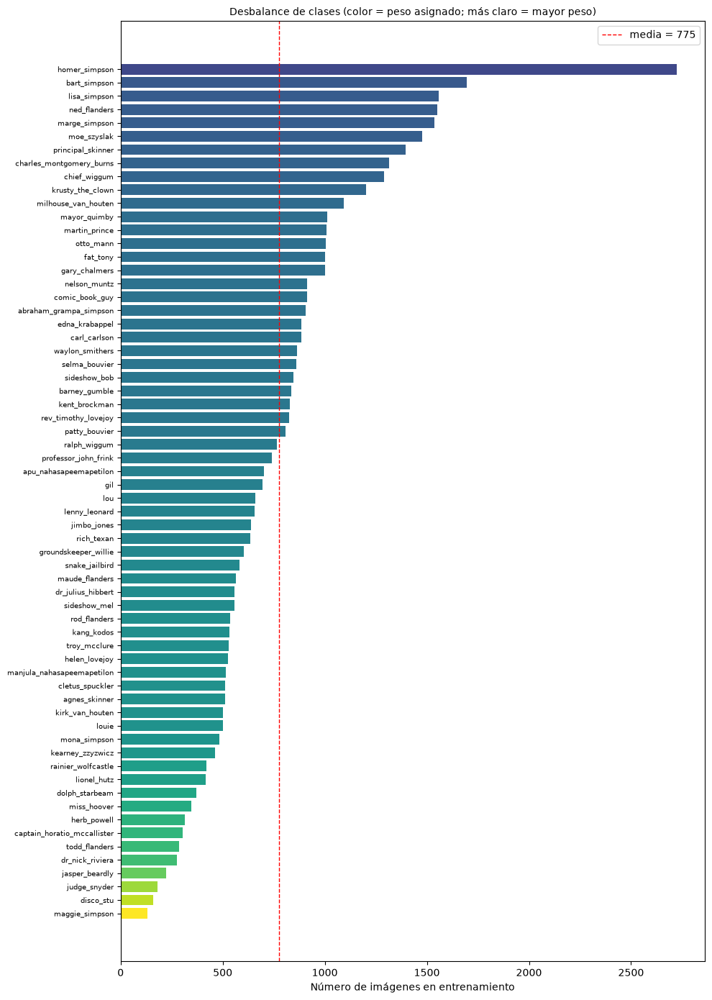

In [29]:
import matplotlib

# Distribución de imágenes por personaje en el conjunto de entrenamiento
figura, eje = plt.subplots(figsize=(10, 14))

orden = np.argsort(conteos_train)
eje.barh(
    [clases[i] for i in orden],
    conteos_train[orden],
    color=matplotlib.colormaps["viridis"](pesos[orden] / pesos.max()),
)
eje.set_xlabel("Número de imágenes en entrenamiento")
eje.set_title("Desbalance de clases (color = peso asignado; más claro = mayor peso)", fontsize=10)
eje.tick_params(axis="y", labelsize=7)
eje.axvline(
    conteos_train.mean(),
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"media = {conteos_train.mean():.0f}",
)
eje.legend()

plt.tight_layout()
plt.show()


## Fundamentos: estructura de una red neuronal profunda

### Capas y neuronas

**Qué es una neurona**

La unidad básica de la red es la neurona artificial, inspirada de forma muy simplificada en la neurona
biológica: recibe varias señales de entrada, las combina dando más importancia a unas que a otras y
produce una única señal de salida. Toda su "inteligencia" está en esos pesos, que son números que se
ajustan durante el entrenamiento.

**Cómo se organizan en capas**

Las neuronas no trabajan sueltas, sino agrupadas en capas, y cada capa recibe como entrada la salida de
la anterior. Una red **densa** o *fully connected* es aquella en la que cada neurona de una capa se
conecta con **todas** las neuronas de la capa siguiente. Un Perceptrón Multicapa es exactamente eso:
una pila de capas densas.

| Capa | Papel en la red | En este proyecto |
|---|---|---|
| **Entrada** | No calcula nada; solo define la forma del dato que entra | Unos 2.460 descriptores de color y textura en el modelo base; 49 152 píxeles en el experimento R1 |
| **Ocultas** | Transforman progresivamente la entrada en representaciones más útiles para separar las clases | Una o varias capas densas con activación ReLU |
| **Salida** | Produce la predicción en el formato del problema | 64 neuronas con softmax, una por personaje |

**Por qué "profunda" y qué aprenden las capas ocultas**

Se llama profunda a una red con más de una capa oculta. La idea es que la composición de capas construye
una **jerarquía de representaciones**: la primera capa detecta patrones muy simples a partir de los
píxeles (zonas de color, contrastes), y cada capa posterior combina los patrones de la anterior en
conceptos más abstractos que, idealmente, terminan siendo características discriminantes entre
personajes. Ninguna de esas características se programa: emergen del ajuste de los pesos.

Se las llama "ocultas" simplemente porque no se observan desde fuera; solo vemos lo que entra y lo que
sale de la red.

**Ancho, profundidad y su costo**

Dos decisiones de diseño definen la arquitectura:

- **Profundidad** (cuántas capas ocultas): más capas permiten representar funciones más complejas, pero
  dificultan el entrenamiento y aumentan el riesgo de sobreajuste.
- **Ancho** (cuántas neuronas por capa): más neuronas dan más capacidad a cada nivel, a costa de muchos
  más parámetros.

Ese costo depende sobre todo de la entrada. Como la conexión es total, la primera capa oculta concentra
la mayoría de los parámetros, y su tamaño es proporcional a la dimensión de la entrada: 49 152
valores con píxeles, unos 2.460 con descriptores. La siguiente celda lo cuantifica para las dos.


In [30]:
# Cuántos parámetros implica cada elección de ancho en la primera capa oculta,
# con la entrada de píxeles y con la de descriptores
anchos_posibles = [64, 128, 256, 512, 1024]
entradas = {"pixeles": DIMENSION_PIXELES, REPRESENTACION_BASE: DIMENSION_ENTRADA}

tabla_costo = pd.DataFrame({"neuronas_capa_1": anchos_posibles})
for nombre, dimension in entradas.items():
    # pesos (entrada x neuronas) + un sesgo por neurona
    tabla_costo[f"capa_1 ({nombre})"] = [dimension * n + n for n in anchos_posibles]
tabla_costo["parametros_salida"] = [n * NUMERO_CLASES + NUMERO_CLASES for n in anchos_posibles]
tabla_costo["reduccion_capa_1"] = (
    tabla_costo["capa_1 (pixeles)"] / tabla_costo[f"capa_1 ({REPRESENTACION_BASE})"]
).round(1)

display(tabla_costo)

print(f"Entrada con pixeles      : {DIMENSION_PIXELES} valores")
print(f"Entrada con descriptores : {DIMENSION_ENTRADA} valores")
print(f"Neuronas de salida       : {NUMERO_CLASES} (una por personaje)")
print(
    "\nCon pixeles, la primera capa oculta concentra casi todos los parametros: es la unica"
    f"\nconectada al vector de entrada. Con descriptores la entrada es {DIMENSION_PIXELES / DIMENSION_ENTRADA:.0f}"
    " veces mas corta y esa capa se reduce en la misma proporcion."
)

,neuronas_capa_1,capa_1 (pixeles),capa_1 (color_textura),parametros_salida,reduccion_capa_1
0,64,3145792,157632,4160,20.0
1,128,6291584,315264,8256,20.0
2,256,12583168,630528,16448,20.0
3,512,25166336,1261056,32832,20.0
4,1024,50332672,2522112,65600,20.0


Entrada con pixeles      : 49152 valores
Entrada con descriptores : 2462 valores
Neuronas de salida       : 64 (una por personaje)

Con pixeles, la primera capa oculta concentra casi todos los parametros: es la unica
conectada al vector de entrada. Con descriptores la entrada es 20 veces mas corta y esa capa se reduce en la misma proporcion.


### Pesos, sesgos y propagación hacia adelante

**El cálculo de una neurona**

Cada neurona hace siempre lo mismo, en dos pasos:

1. **Combinación lineal (preactivación).** Multiplica cada entrada por su peso, suma todo y añade el
   sesgo:

   $$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \mathbf{w} \cdot \mathbf{x} + b$$

2. **Activación.** Pasa ese número por una función no lineal: $a = f(z)$.

**Qué significan los pesos y el sesgo**

- El **peso** $w_i$ mide cuánto influye la entrada $x_i$ en esta neurona. Un peso grande y positivo
  indica que esa entrada empuja a la neurona a activarse; uno negativo, que la inhibe; uno cercano a cero,
  que esa entrada le resulta irrelevante. Con píxeles, cada peso de la primera capa está asociado a un
  canal de color de un píxel concreto; con descriptores, a un intervalo de un histograma o a la
  respuesta de un filtro en una zona de la imagen.
- El **sesgo** $b$ desplaza el umbral de activación. Sin él, toda neurona estaría obligada a dar 0 cuando
  la entrada es 0, y todas las fronteras de decisión tendrían que pasar por el origen. El sesgo le da
  libertad para activarse aun con entradas débiles, o para exigir una evidencia mayor.

**Pesos y sesgos son lo que el modelo aprende.** Todo lo demas -- número de capas, neuronas, activaciones,
learning rate -- lo fijamos nosotros antes de entrenar y por eso se llaman hiperparámetros. Los parámetros
propiamente dichos son estos números, que empiezan con valores aleatorios pequeños y se van corrigiendo.

**De una neurona a una capa: forma matricial**

Escribir el cálculo neurona por neurona sería impracticable. Como todas las neuronas de una capa hacen la
misma operación sobre la misma entrada, se agrupan sus pesos en una matriz $W$ y sus sesgos en un vector
$\mathbf{b}$, y la capa entera se calcula de un golpe:

$$\mathbf{a}^{(l)} = f\left(\mathbf{a}^{(l-1)} W^{(l)} + \mathbf{b}^{(l)}\right)$$

Esto no es solo notación elegante: es lo que permite procesar un **batch** completo de imágenes en una
sola multiplicación de matrices, que es justo la operación que GPU y CPU ejecutan de forma optimizada.

**Propagación hacia adelante (forward pass)**

Se llama así al recorrido completo: la imagen entra como vector, cada capa aplica su transformación y
pasa el resultado a la siguiente, hasta que la capa de salida produce las 64 probabilidades. Es lo que
ocurre cada vez que el modelo predice, y también el primer paso de cada iteración de entrenamiento: sin
saber qué predijo la red no se puede medir cuánto se equivocó.

La celda siguiente reproduce ese recorrido a mano con NumPy, sobre una imagen real del dataset, para ver
las formas de cada matriz y comprobar que la salida es una distribución de probabilidad.


In [31]:
# Forward pass "a mano" con una arquitectura mínima: DIMENSION_PIXELES -> 64 -> NUMERO_CLASES
generador_pesos = np.random.default_rng(SEMILLA)
NEURONAS_DEMO = 64


def inicializar_capa(entradas, neuronas):
    """Pesos pequeños aleatorios (escala de He, la que usa Keras con ReLU) y sesgos a cero."""
    W = generador_pesos.normal(0, np.sqrt(2 / entradas), size=(entradas, neuronas)).astype(np.float32)
    b = np.zeros(neuronas, dtype=np.float32)
    return W, b


W1, b1 = inicializar_capa(DIMENSION_PIXELES, NEURONAS_DEMO)
W2, b2 = inicializar_capa(NEURONAS_DEMO, NUMERO_CLASES)

# Una imagen real del conjunto de entrenamiento como vector de píxeles, escalada a
# [0, 1] igual que hace la capa Rescaling dentro del modelo. La demostración usa
# píxeles porque se pueden volver a dibujar como imagen; con descriptores el
# recorrido es idéntico, solo cambia la longitud del vector de entrada.
entrada = np.asarray(X[np.flatnonzero(MASCARAS["train"])[0]], dtype=np.float32) / VALOR_MAXIMO_PIXEL

# Capa oculta: combinación lineal + ReLU
z1 = entrada @ W1 + b1
a1 = np.maximum(0, z1)

# Capa de salida: combinación lineal + softmax (se resta el máximo por estabilidad numérica)
z2 = a1 @ W2 + b2
exponenciales = np.exp(z2 - z2.max())
salida = exponenciales / exponenciales.sum()

recorrido = pd.DataFrame(
    [
        ("entrada (imagen aplanada)", str(entrada.shape), entrada.size),
        ("W1 (pesos capa oculta)", str(W1.shape), W1.size),
        ("b1 (sesgos capa oculta)", str(b1.shape), b1.size),
        ("z1 = entrada @ W1 + b1", str(z1.shape), z1.size),
        ("a1 = ReLU(z1)", str(a1.shape), a1.size),
        ("W2 (pesos capa salida)", str(W2.shape), W2.size),
        ("b2 (sesgos capa salida)", str(b2.shape), b2.size),
        ("z2 = a1 @ W2 + b2", str(z2.shape), z2.size),
        ("salida = softmax(z2)", str(salida.shape), salida.size),
    ],
    columns=["Paso", "Forma", "Número de valores"],
)

display(recorrido)

print(f"Parametros entrenables de esta red minima: {W1.size + b1.size + W2.size + b2.size:,}")

,Paso,Forma,Número de valores
0,entrada (imagen aplanada),"(49152,)",49152
1,W1 (pesos capa oculta),"(49152, 64)",3145728
2,b1 (sesgos capa oculta),"(64,)",64
3,z1 = entrada @ W1 + b1,"(64,)",64
4,a1 = ReLU(z1),"(64,)",64
5,W2 (pesos capa salida),"(64, 64)",4096
6,b2 (sesgos capa salida),"(64,)",64
7,z2 = a1 @ W2 + b2,"(64,)",64
8,salida = softmax(z2),"(64,)",64


Parametros entrenables de esta red minima: 3,149,952


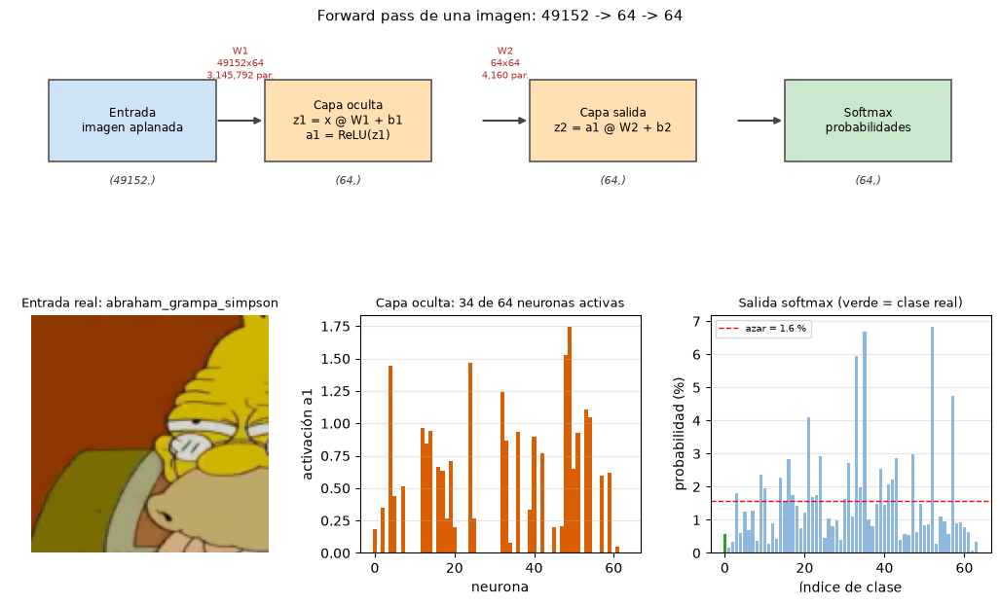


Sin entrenar, la red predice 'rainier_wolfcastle' con 6.8 % de confianza,
cuando la clase real es 'abraham_grampa_simpson', a la que asigna solo 0.6 %.

El reparto responde unicamente a los pesos aleatorios, no a la imagen: la referencia de azar es 1.6 %.

Entrenar consiste en ajustar W1, b1, W2 y b2 para que la barra verde crezca y las demas bajen.



In [32]:
# Recorrido de la señal a través de la red, paso a paso
figura = plt.figure(figsize=(13, 7))
malla = figura.add_gridspec(2, 3, height_ratios=[1, 1.25], hspace=0.45, wspace=0.25)

# --- Fila superior: esquema del flujo de datos con las formas de cada tensor ---
esquema = figura.add_subplot(malla[0, :])
esquema.set_xlim(0, 10)
esquema.set_ylim(0, 3)
esquema.axis("off")

bloques = [
    (0.4, "Entrada\nimagen aplanada", f"({DIMENSION_PIXELES},)", "#cfe3f7"),
    (2.6, "Capa oculta\nz1 = x @ W1 + b1\na1 = ReLU(z1)", f"({NEURONAS_DEMO},)", "#ffe0b3"),
    (5.3, "Capa salida\nz2 = a1 @ W2 + b2", f"({NUMERO_CLASES},)", "#ffe0b3"),
    (7.9, "Softmax\nprobabilidades", f"({NUMERO_CLASES},)", "#c9e8cd"),
]

for x, texto, forma, color in bloques:
    esquema.add_patch(
        plt.Rectangle((x, 0.9), 1.7, 1.3, facecolor=color, edgecolor="#555", linewidth=1.2)
    )
    esquema.text(x + 0.85, 1.55, texto, ha="center", va="center", fontsize=8.5)
    esquema.text(x + 0.85, 0.6, forma, ha="center", va="center", fontsize=8, style="italic", color="#333")

pesos_entre = [
    (2.1, f"W1\n{W1.shape[0]}x{W1.shape[1]}\n{W1.size + b1.size:,} par."),
    (4.8, f"W2\n{W2.shape[0]}x{W2.shape[1]}\n{W2.size + b2.size:,} par."),
    (7.4, ""),
]
for x, etiqueta in pesos_entre:
    esquema.annotate(
        "",
        xy=(x + 0.5, 1.55),
        xytext=(x, 1.55),
        arrowprops=dict(arrowstyle="-|>", linewidth=1.5, color="#444"),
    )
    if etiqueta:
        esquema.text(x + 0.25, 2.45, etiqueta, ha="center", va="center", fontsize=7.5, color="#b03030")

esquema.set_title(
    f"Forward pass de una imagen: {DIMENSION_PIXELES} -> {NEURONAS_DEMO} -> {NUMERO_CLASES}",
    fontsize=11,
)

# --- Abajo izquierda: la imagen que entra a la red ---
eje_imagen = figura.add_subplot(malla[1, 0])
eje_imagen.imshow(entrada.reshape(ALTO_OBJETIVO, ANCHO_OBJETIVO, 3))
eje_imagen.set_title(f"Entrada real: {clases[int(y_train_idx[0])]}", fontsize=9)
eje_imagen.axis("off")

# --- Abajo centro: activaciones de la capa oculta ---
eje_ocultas = figura.add_subplot(malla[1, 1])
colores_ocultas = ["#d95f02" if valor > 0 else "#bbbbbb" for valor in a1]
eje_ocultas.bar(range(NEURONAS_DEMO), a1, color=colores_ocultas, width=1.0)
eje_ocultas.set_title(
    f"Capa oculta: {(a1 > 0).sum()} de {NEURONAS_DEMO} neuronas activas", fontsize=9
)
eje_ocultas.set_xlabel("neurona")
eje_ocultas.set_ylabel("activación a1")
eje_ocultas.grid(alpha=0.3, axis="y")

# --- Abajo derecha: distribución de probabilidad de salida ---
eje_salida = figura.add_subplot(malla[1, 2])
clase_real = int(y_train_idx[0])
colores_salida = ["#2ca02c" if i == clase_real else "#8fb8de" for i in range(NUMERO_CLASES)]
eje_salida.bar(range(NUMERO_CLASES), salida * 100, color=colores_salida)
eje_salida.axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
eje_salida.set_title("Salida softmax (verde = clase real)", fontsize=9)
eje_salida.set_xlabel("índice de clase")
eje_salida.set_ylabel("probabilidad (%)")
eje_salida.legend(fontsize=7)
eje_salida.grid(alpha=0.3, axis="y")

plt.show()

print(f"""
Sin entrenar, la red predice '{clases[int(salida.argmax())]}' con {salida.max() * 100:.1f} % de confianza,
cuando la clase real es '{clases[clase_real]}', a la que asigna solo {salida[clase_real] * 100:.1f} %.
    
El reparto responde unicamente a los pesos aleatorios, no a la imagen: la referencia de azar es {100 / NUMERO_CLASES:.1f} %.
    
Entrenar consiste en ajustar W1, b1, W2 y b2 para que la barra verde crezca y las demas bajen.
""")


### Funciones de activación

**Por qué hace falta la no linealidad**

Si se quitaran las funciones de activación, cada capa sería solo una multiplicación de matrices y la red
entera colapsaría en una sola: la composición de funciones lineales es otra función lineal. Una red de
diez capas sin activaciones tendría exactamente el mismo poder expresivo que una regresión lineal, y sería
incapaz de separar clases que no se puedan dividir con un hiperplano. La activación no lineal es lo que
permite que apilar capas sirva de algo.

**Comparación de las activaciones para las capas ocultas**

| Función | Fórmula | Rango | Ventaja | Problema |
|---|---|---|---|---|
| **Sigmoide** | $1/(1+e^{-z})$ | (0, 1) | Interpretable como probabilidad | Se satura: para $\|z\|$ grande el gradiente tiende a 0 y el aprendizaje se detiene |
| **Tanh** | $(e^z-e^{-z})/(e^z+e^{-z})$ | (-1, 1) | Centrada en cero, converge mejor que la sigmoide | También se satura en los extremos |
| **ReLU** | $\max(0, z)$ | [0, inf) | Gradiente constante 1 para $z>0$: no se satura; muy barata de calcular; produce activaciones dispersas | "Neuronas muertas": si una unidad queda siempre en $z<0$, su gradiente es 0 y no vuelve a aprender |

**Elección: ReLU en las capas ocultas.** El problema de la saturación es decisivo. En una red profunda,
los gradientes se multiplican capa a capa al retropropagarse; si cada factor es menor que 1 -- como pasa
con sigmoide, cuya derivada máxima es 0,25 -- el gradiente se desvanece antes de llegar a las primeras
capas, que son justamente las que deben aprender de los píxeles. ReLU mantiene el gradiente en 1 en toda
su zona activa, y además su cálculo es una simple comparación, lo que acelera el entrenamiento. Es el
valor por defecto razonable para capas ocultas, y de ahí partimos.

**Elección: softmax en la salida.** La capa final no busca una no linealidad cualquiera, sino convertir 64
números sin escala definida en una distribución de probabilidad:

$$\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{64} e^{z_j}}$$

Sus dos propiedades son las que necesita un problema multiclase de etiqueta única: todas las salidas son
positivas y **suman exactamente 1**. Eso introduce competencia entre clases -- si sube la probabilidad de
un personaje, baja la de los demas -- que es correcto aquí, porque cada imagen tiene un único personaje.
Si el problema fuera multietiqueta habría que usar sigmoides independientes en la salida.


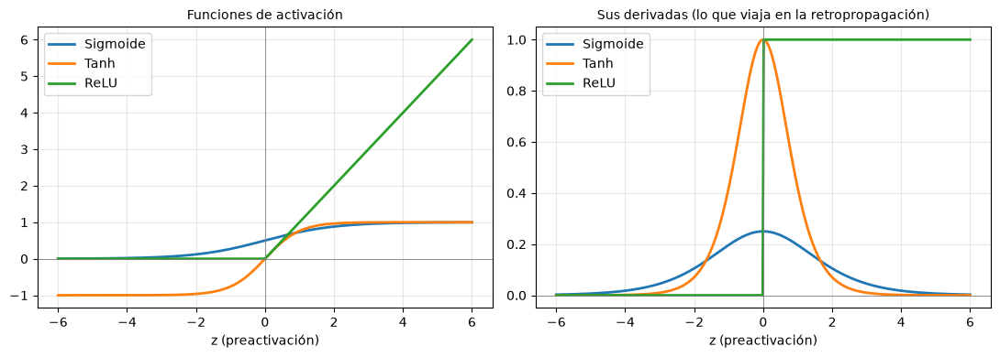

En el gráfico de la derecha se ve el problema de la saturación: las derivadas de sigmoide y tanh
caen a cero en los extremos (el gradiente se desvanece), mientras que la de ReLU vale 1 para
todo z > 0. Nótese además que la derivada de la sigmoide no supera 0.25.


In [33]:
z = np.linspace(-6, 6, 400)

activaciones = {
    "Sigmoide": (1 / (1 + np.exp(-z)), lambda s: s * (1 - s)),
    "Tanh": (np.tanh(z), lambda s: 1 - s ** 2),
    "ReLU": (np.maximum(0, z), lambda s: (z > 0).astype(float)),
}

figura, ejes = plt.subplots(1, 2, figsize=(11, 4))

for nombre, (valores, derivada) in activaciones.items():
    ejes[0].plot(z, valores, label=nombre, linewidth=2)
    ejes[1].plot(z, derivada(valores), label=nombre, linewidth=2)

ejes[0].set_title("Funciones de activación", fontsize=10)
ejes[1].set_title("Sus derivadas (lo que viaja en la retropropagación)", fontsize=10)

for eje in ejes:
    eje.axhline(0, color="gray", linewidth=0.6)
    eje.axvline(0, color="gray", linewidth=0.6)
    eje.set_xlabel("z (preactivación)")
    eje.grid(alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.show()

print(
    "En el gráfico de la derecha se ve el problema de la saturación: las derivadas de sigmoide y tanh"
    "\ncaen a cero en los extremos (el gradiente se desvanece), mientras que la de ReLU vale 1 para"
    "\ntodo z > 0. Nótese además que la derivada de la sigmoide no supera 0.25."
)


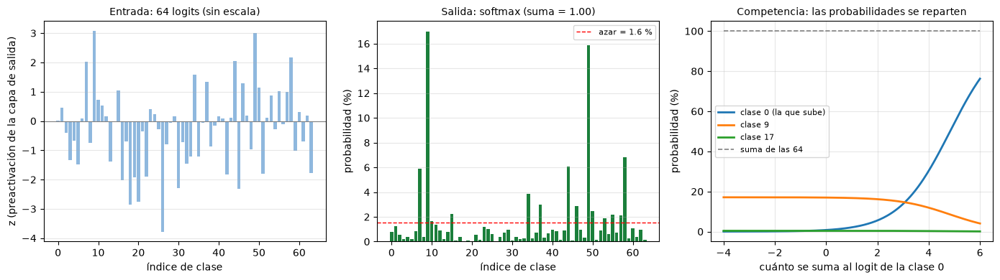

Softmax no se puede dibujar junto a ReLU o tanh porque no transforma un número en otro:
toma el vector completo de logits y devuelve una distribución. El denominador -- la suma
de todas las exponenciales -- es lo que acopla las salidas entre si.

Clase predicha: 9 con 17.0 % de probabilidad   |   suma de las 64 salidas = 1.000000
En el gráfico de la derecha se ve la propiedad clave para etiqueta única: al crecer el logit
de una clase, su probabilidad sube y la de las demas baja, mientras la suma se mantiene en 100 %.


In [34]:
# Softmax se gráfica aparte: no es una activación elemento a elemento como las anteriores,
# sino una función vectorial que mira todas las salidas a la vez y las convierte en una distribución.
generador = np.random.default_rng(7)
logits_demo = generador.normal(0, 1.5, NUMERO_CLASES)
logits_demo[min(9, NUMERO_CLASES - 1)] += 4.0  # una clase claramente favorecida por la red


def softmax(z, temperatura=1.0):
    """Softmax numéricamente estable: se resta el máximo antes de exponenciar."""
    escalado = np.asarray(z, dtype=float) / temperatura
    exponenciales = np.exp(escalado - escalado.max())
    return exponenciales / exponenciales.sum()


probabilidades_demo = softmax(logits_demo)

figura, ejes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Los logits: números sin escala definida, positivos y negativos
ejes[0].bar(range(NUMERO_CLASES), logits_demo, color="#8fb8de")
ejes[0].axhline(0, color="gray", linewidth=0.8)
ejes[0].set_title(f"Entrada: {NUMERO_CLASES} logits (sin escala)", fontsize=10)
ejes[0].set_ylabel("z (preactivación de la capa de salida)")

# 2. La misma información después de softmax: probabilidades que suman 1
ejes[1].bar(range(NUMERO_CLASES), probabilidades_demo * 100, color="#1b7f3b")
ejes[1].axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
ejes[1].set_title(
    f"Salida: softmax (suma = {probabilidades_demo.sum():.2f})", fontsize=10
)
ejes[1].set_ylabel("probabilidad (%)")
ejes[1].legend(fontsize=8)

for eje in ejes[:2]:
    eje.set_xlabel("índice de clase")
    eje.grid(alpha=0.3, axis="y")

# 3. La competencia entre clases: subir el logit de una hunde a todas las demas
desplazamientos = np.linspace(-4, 6, 200)
seguidas = sorted({0, min(9, NUMERO_CLASES - 1), min(17, NUMERO_CLASES - 1)})  # clases a seguir
curvas = np.array(
    [softmax(np.concatenate(([logits_demo[0] + d], logits_demo[1:]))) for d in desplazamientos]
)

for indice in seguidas:
    ejes[2].plot(
        desplazamientos,
        curvas[:, indice] * 100,
        linewidth=2,
        label=f"clase {indice}" + (" (la que sube)" if indice == 0 else ""),
    )

ejes[2].plot(
    desplazamientos,
    curvas.sum(axis=1) * 100,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label=f"suma de las {NUMERO_CLASES}",
)
ejes[2].set_title("Competencia: las probabilidades se reparten", fontsize=10)
ejes[2].set_xlabel("cuánto se suma al logit de la clase 0")
ejes[2].set_ylabel("probabilidad (%)")
ejes[2].grid(alpha=0.3)
ejes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(
    "Softmax no se puede dibujar junto a ReLU o tanh porque no transforma un número en otro:"
    "\ntoma el vector completo de logits y devuelve una distribución. El denominador -- la suma"
    "\nde todas las exponenciales -- es lo que acopla las salidas entre si."
)
print(
    f"\nClase predicha: {int(probabilidades_demo.argmax())} con {probabilidades_demo.max() * 100:.1f} %"
    f" de probabilidad   |   suma de las {NUMERO_CLASES} salidas = {probabilidades_demo.sum():.6f}"
)
print(
    "En el gráfico de la derecha se ve la propiedad clave para etiqueta única: al crecer el logit"
    "\nde una clase, su probabilidad sube y la de las demas baja, mientras la suma se mantiene en 100 %."
)


### Función de pérdida, backpropagation y optimizador

El forward pass produce una predicción, pero por sí solo no enseña nada. El aprendizaje necesita tres
piezas más: una forma de **medir** el error, una forma de **repartir la culpa** de ese error entre los
parámetros, y una **regla** para corregirlos.

**1. Función de pérdida: entropía cruzada categórica**

Mide la distancia entre la distribución predicha por softmax y el vector one-hot real. Como el one-hot
tiene un 1 en la clase correcta y 0 en el resto, la suma se reduce a un único término:

$$L = -\sum_{i=1}^{64} y_i \log(\hat{y}_i) = -\log(\hat{y}_{\text{clase correcta}})$$

Es decir: la pérdida de un ejemplo depende **solo de la probabilidad que la red asignó a la clase
verdadera**. Si le dio 0,99, la pérdida es casi 0; si le dio 0,01, la pérdida se dispara. Ese crecimiento
logarítmico penaliza con dureza los errores cometidos con mucha confianza, que es el comportamiento
deseable. La pérdida del batch es el promedio de las pérdidas individuales -- y es ahí donde `class_weight`
interviene, ponderando cada término según la frecuencia de su clase.

Por qué no usar accuracy como función a minimizar: el accuracy es escalonado, su gradiente es cero en casi
todas partes y no distingue entre acertar con 0,51 o con 0,99. Sirve para interpretar resultados, no para
optimizar. Por eso se monitorean ambos: se **optimiza** la pérdida y se **lee** el accuracy.

**2. Backpropagation: de dónde viene el error**

Conocida la pérdida, hace falta saber cuánto contribuyó cada uno de los parámetros. Eso es la derivada
parcial $\partial L / \partial w$, y calcularla directamente para cientos de miles de pesos sería
inviable. La retropropagación lo resuelve aplicando la **regla de la cadena** en sentido inverso: parte
del error en la salida y lo propaga hacia atras capa por capa, reutilizando en cada paso lo ya calculado
en la capa posterior. Esto es lo que hace posible entrenar redes grandes, y también la razón de que la
derivada de la activación importe tanto: aparece como factor multiplicativo en cada capa que se atraviesa
(de ahí el desvanecimiento del gradiente con sigmoide y la ventaja de ReLU).

El resultado es el **gradiente**: un vector que indica, para cada parámetro, en qué dirección habría que
moverlo para que la pérdida aumente. Se avanza en la dirección contraria.

**3. Optimizador: cómo se corrigen los pesos**

La regla básica es el **descenso del gradiente**:

$$w \leftarrow w - \eta \frac{\partial L}{\partial w}$$

donde $\eta$ es la **tasa de aprendizaje** (learning rate), el tamaño del paso. Demasiado grande y el
entrenamiento oscila o diverge; demasiado pequeño y avanza con una lentitud inútil. En la práctica no se
calcula el gradiente sobre todo el dataset (caro) ni sobre un solo ejemplo (ruidoso), sino sobre **batches**
de unas decenas o centenas de imágenes: es el descenso del gradiente por mini-lotes. Una **época** es una
pasada completa por el conjunto de entrenamiento, es decir, muchas actualizaciones de pesos.

**Elección: Adam.** Mejora el descenso del gradiente clásico en dos aspectos: acumula un **momento** de los
gradientes anteriores, lo que suaviza las oscilaciones, y adapta el tamaño del paso **para cada parámetro**
según la magnitud típica de su gradiente. En la práctica converge más rápido y es mucho menos sensible a
la elección inicial del learning rate, razón por la que se usa como punto de partida en la mayoría de los
trabajos. Se parte de su valor por defecto, 0,001, y su efecto se contrasta en la experimentación.

**El ciclo completo de entrenamiento**

Para cada batch, y repitiendolo época tras época:

`forward pass` -> `calcular la perdida` -> `backpropagation` -> `el optimizador actualiza los pesos`


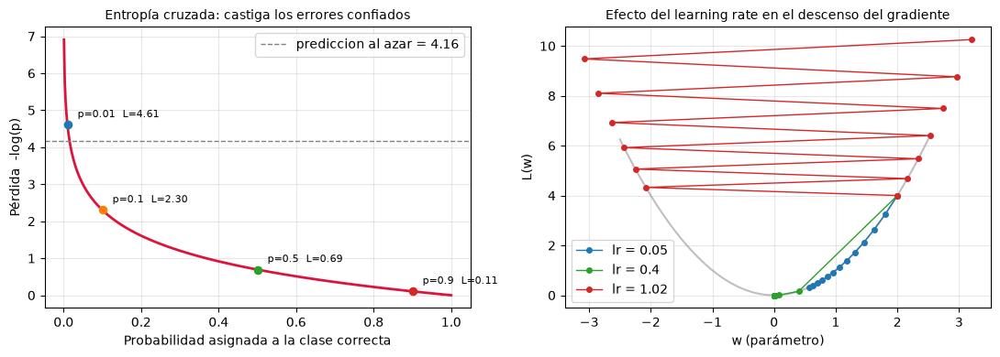

Perdida esperada de un modelo sin entrenar (1/64 a cada clase): 4.159
Es el valor de referencia con el que debería arrancar el entrenamiento en la primera época.

En el gráfico de la derecha: un lr pequeño (azul) converge pero lento, uno adecuado (verde)
llega rápido al mínimo, y uno demasiado grande (rojo) se aleja y diverge.


In [35]:
# Pérdida de un ejemplo según la probabilidad asignada a la clase correcta
probabilidades = np.linspace(0.001, 1.0, 500)
perdidas = -np.log(probabilidades)

figura, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(probabilidades, perdidas, color="crimson", linewidth=2)
ejes[0].set_xlabel("Probabilidad asignada a la clase correcta")
ejes[0].set_ylabel("Pérdida  -log(p)")
ejes[0].set_title("Entropía cruzada: castiga los errores confiados", fontsize=10)
ejes[0].grid(alpha=0.3)

for probabilidad in (0.01, 0.1, 0.5, 0.9):
    ejes[0].scatter([probabilidad], [-np.log(probabilidad)], zorder=3, s=35)
    ejes[0].annotate(
        f"p={probabilidad}  L={-np.log(probabilidad):.2f}",
        (probabilidad, -np.log(probabilidad)),
        textcoords="offset points",
        xytext=(8, 6),
        fontsize=8,
    )

# Referencias del problema: pérdida esperada al predecir al azar entre todas las clases
perdida_azar = -np.log(1 / NUMERO_CLASES)
ejes[0].axhline(
    perdida_azar,
    color="gray",
    linestyle="--",
    linewidth=1,
    label=f"prediccion al azar = {perdida_azar:.2f}",
)
ejes[0].legend()

# Efecto del learning rate sobre el descenso del gradiente en una parabola L(w) = w^2
ejes[1].plot(np.linspace(-2.5, 2.5, 200), np.linspace(-2.5, 2.5, 200) ** 2, color="gray", alpha=0.5)

for tasa, color in ((0.05, "tab:blue"), (0.4, "tab:green"), (1.02, "tab:red")):
    w = 2.0
    trayectoria = [w]
    for _ in range(12):
        w = w - tasa * 2 * w  # derivada de w^2
        trayectoria.append(w)
    trayectoria = np.array(trayectoria)
    ejes[1].plot(
        trayectoria,
        trayectoria ** 2,
        "o-",
        color=color,
        markersize=4,
        linewidth=1,
        label=f"lr = {tasa}",
    )

ejes[1].set_xlabel("w (parámetro)")
ejes[1].set_ylabel("L(w)")
ejes[1].set_title("Efecto del learning rate en el descenso del gradiente", fontsize=10)
ejes[1].grid(alpha=0.3)
ejes[1].legend()

plt.tight_layout()
plt.show()

print(f"Perdida esperada de un modelo sin entrenar (1/{NUMERO_CLASES} a cada clase): {perdida_azar:.3f}")
print("Es el valor de referencia con el que debería arrancar el entrenamiento en la primera época.")
print(
    "\nEn el gráfico de la derecha: un lr pequeño (azul) converge pero lento, uno adecuado (verde)"
    "\nllega rápido al mínimo, y uno demasiado grande (rojo) se aleja y diverge."
)


## Modelo base: Perceptrón Multicapa (MLP)

### Configuración y alcance de la implementación

El modelo base recibe el vector de **descriptores de color y textura** (unos 2.460 valores por imagen, calculados sobre la imagen completa a 128 × 128) y tiene dos capas ocultas de **512 → 256** neuronas, ReLU, Batch Normalization y Dropout de 0,3. La salida tiene 64 neuronas con `softmax`; el entrenamiento usa `categorical_crossentropy` con suavizado de etiquetas de 0,1, Adam con tasa `1e-3`, batch de 128, hasta 60 épocas y pesos por clase suavizados (raíz cuadrada de los balanceados). Todos esos valores se declaran en las celdas de arquitectura, compilación y entrenamiento que siguen.

El modelo base no se presenta como una elección arbitraria. Se compara con tres variantes que cambian la representación de entrada (píxeles, solo color y solo textura), con seis que cambian una sola decisión de arquitectura u optimización (número de capas, activación, tasa de aprendizaje, batch o dropout) y con cuatro que cambian el tratamiento de los datos (pesos por clase, suavizado e imágenes alteradas). Al final, una configuración combina los cambios que mejoraron al modelo base. La regla de selección es el F1 macro de validación.

### Definición de la arquitectura

La arquitectura del modelo base traduce a código lo descrito en los fundamentos: una capa de entrada con
el vector de la representación elegida, dos capas ocultas densas con ReLU y una capa de salida softmax
con una neurona por personaje. Antes de las capas ocultas, la entrada se lleva a una escala común:

- **Píxeles:** `Rescaling(1/255)` lleva los valores de [0, 255] a [0, 1]. Los píxeles viajan a la
  GPU en `uint8` y la tarjeta los escala sobre cada lote.
- **Descriptores:** una capa `Normalization` resta a cada descriptor su media y lo divide por su
  desviación, ambas calculadas **solo con el conjunto de entrenamiento**. Al vivir dentro del modelo, el
  archivo `.keras` guardado recibe los descriptores tal como salen de `extraer_caracteristicas`.

Entre las capas ocultas se intercalan dos mecanismos de regularización:

- **Normalización por lotes (`BatchNormalization`).** Reescala las activaciones de cada capa para que
  mantengan una media y una varianza estables a lo largo del entrenamiento. Evita que la distribución que
  ve cada capa se desplace batch a batch, lo que permite usar una tasa de aprendizaje mayor y acelera la
  convergencia.
- **`Dropout`.** Durante el entrenamiento apaga al azar una fracción de las neuronas de la capa. Así
  ninguna neurona puede depender de la presencia de otra en particular y la red se ve obligada a
  distribuir la representación. Es la defensa principal contra el sobreajuste en una red densa con más
  de un millón de parámetros y unas 50.000 imágenes de entrenamiento.

La función `construir_mlp` deja como parámetros los factores que se modificarán en la experimentación
(representación de entrada, número y ancho de las capas ocultas, activación y tasa de dropout), de modo
que todas las configuraciones comparadas se generen exactamente con el mismo código.

In [36]:
import keras
from keras import layers

# Fija las semillas de Python, NumPy y PyTorch para que el entrenamiento sea reproducible
keras.utils.set_random_seed(SEMILLA)

NEURONAS_OCULTAS = (512, 256)
ACTIVACION = "relu"
TASA_DROPOUT = 0.3
# Suelo de la varianza al estandarizar: un intervalo de histograma casi siempre vacío
# tiene varianza casi nula y, sin este suelo, cualquier valor distinto de cero en
# validación o en test se amplificaría hasta valores enormes.
VARIANZA_MINIMA = 1e-4

_estadisticas = {}


def estadisticas_entrada(representacion):
    """Media y varianza de cada descriptor, calculadas SOLO con el conjunto de entrenamiento."""
    if representacion not in _estadisticas:
        entrenamiento = particion(representacion)["train"]
        _estadisticas[representacion] = (
            entrenamiento.mean(axis=0),
            np.maximum(entrenamiento.var(axis=0), VARIANZA_MINIMA),
        )
    return _estadisticas[representacion]


def construir_mlp(
    neuronas_ocultas=NEURONAS_OCULTAS,
    activacion=ACTIVACION,
    tasa_dropout=TASA_DROPOUT,
    representacion=REPRESENTACION_BASE,
    numero_clases=NUMERO_CLASES,
    nombre="mlp_base",
):
    """Construye un Perceptrón Multicapa: entrada (píxeles o descriptores) -> escala común ->
    capas ocultas densas (activación + BatchNorm + Dropout) -> salida softmax con una neurona por clase."""
    modelo = keras.Sequential(name=nombre)
    modelo.add(layers.Input(shape=(DIMENSIONES[representacion],), name="entrada"))
    if representacion == "pixeles":
        # El escalado a [0, 1] vive dentro del modelo: los datos viajan a la GPU en
        # uint8 (cuatro veces menos memoria) y la tarjeta los escala sobre cada lote.
        modelo.add(layers.Rescaling(1.0 / 255, name="escalado"))
    else:
        media, varianza = estadisticas_entrada(representacion)
        modelo.add(layers.Normalization(mean=media, variance=varianza, name="estandarizacion"))

    for posicion, neuronas in enumerate(neuronas_ocultas, start=1):
        modelo.add(layers.Dense(neuronas, activation=activacion, name=f"oculta_{posicion}"))
        modelo.add(layers.BatchNormalization(name=f"norm_{posicion}"))
        modelo.add(layers.Dropout(tasa_dropout, name=f"dropout_{posicion}"))

    modelo.add(layers.Dense(numero_clases, activation="softmax", name="salida"))
    return modelo


modelo_base = construir_mlp()

modelo_base = modelo_base.to(DISPOSITIVO)

capas_texto = " -> ".join(str(n) for n in NEURONAS_OCULTAS)
print(f"Keras {keras.__version__} sobre backend {keras.backend.backend()}")
print(f"Entrada: {REPRESENTACION_BASE}, estandarizada con la media y la desviacion de train")
print(f"Arquitectura: {DIMENSION_ENTRADA} -> {capas_texto} -> {NUMERO_CLASES}")
print(f"Activacion oculta: {ACTIVACION}   |   Dropout: {TASA_DROPOUT}   |   Salida: softmax")

Keras 3.15.1 sobre backend torch
Entrada: color_textura, estandarizada con la media y la desviacion de train
Arquitectura: 2462 -> 512 -> 256 -> 64
Activacion oculta: relu   |   Dropout: 0.3   |   Salida: softmax


### Justificación técnica de la arquitectura y de los hiperparámetros iniciales

Cada decisión del modelo base responde al problema concreto ya descrito: unos 2.460 descriptores de
entrada, 64 clases desbalanceadas y unas 50.000 imágenes de entrenamiento (el 70 % de las originales de
cada personaje, más sus variantes alteradas).

| Hiperparámetro | Valor elegido | Justificación |
|---|---|---|
| **Entrada** | Descriptores de color y textura (`color_textura`) | Resumen la imagen en histogramas de color y de textura, menos sensibles al encuadre que los píxeles, y reducen la primera capa unas 20 veces. Los píxeles, el color solo y la textura sola se comparan en los experimentos R1–R3 |
| **Capas ocultas** | 2 | Con una sola capa la red es prácticamente un clasificador lineal sobre los descriptores; con muchas más, en un dataset de este tamaño el sobreajuste y el costo crecen más rápido que la ganancia. Dos capas permiten componer dos niveles de abstracción |
| **Neuronas por capa** | 512 y 256 | Un embudo decreciente: con unos 2.460 descriptores, la primera capa tiene ≈ 1,3 millones de parámetros, y la segunda refina esa representación antes de la salida. Reducir progresivamente obliga a la red a resumir en lugar de copiar la entrada |
| **Activación oculta** | ReLU | No se satura, su derivada vale 1 para z > 0 y es la más barata de calcular (ver "Funciones de activación"). Con sigmoide o tanh, dos capas ya bastan para que el gradiente empiece a atenuarse |
| **Activación de salida** | Softmax (64 neuronas) | Convierte las puntuaciones en una distribución de probabilidad que suma 1, que es la forma correcta para una clasificación multiclase de etiqueta única |
| **Dropout** | 0,3 | Valor intermedio: con más de un millón de parámetros para unas 50.000 imágenes el riesgo de memorización es alto, pero una tasa de 0,5 retrasa demasiado la convergencia |
| **BatchNormalization** | Tras cada capa oculta | Estabiliza la escala de las activaciones y permite un learning rate mayor sin que el entrenamiento se vuelva inestable |
| **Optimizador** | Adam | Adapta el paso por parámetro combinando momento y escalado según la magnitud histórica del gradiente. Con entradas de naturaleza muy distinta —histogramas, respuestas de filtro, gradientes— converge bastante más rápido que el SGD puro |
| **Tasa de aprendizaje** | 0,001 | Valor por defecto de Adam y punto de partida estándar; se contrasta explícitamente en la experimentación |
| **Función de pérdida** | Categorical crossentropy con suavizado 0,1 | Corresponde a etiquetas one-hot (o con escena) y salida softmax. El suavizado reparte el 10 % del objetivo entre todas las clases: el modelo deja de empujar sus probabilidades a 0 y 1, razonable cuando parte de las etiquetas es ambigua (escenas con varios personajes, Patty y Selma). El experimento S1 lo compara con el one-hot puro |
| **Tamaño de batch** | 128 | Compromiso entre el ruido del gradiente (batches pequeños) y la estabilidad y el aprovechamiento de memoria (batches grandes) |
| **`class_weight`** | Raíz cuadrada de los pesos balanceados | Compensa el desbalance de 21:1 sin anular a los personajes frecuentes; P1 y P2 comparan sin pesos y con los balanceados completos |

### Compilación del modelo

In [37]:
TASA_APRENDIZAJE = 1e-3
# Suavizado de etiquetas: fracción del objetivo de entrenamiento que se reparte entre todas las clases
SUAVIZADO_ETIQUETAS = 0.1


def compilar(modelo, tasa_aprendizaje=TASA_APRENDIZAJE):
    """Asocia al modelo la función de pérdida y las métricas.

    El entrenamiento NO usa `fit()`, sino el bucle propio de la sección siguiente.
    Se compila igualmente porque `predict()` y `evaluate()` sí se aprovechan: son
    llamadas puntuales sobre unos pocos miles de imágenes, donde el sobrecoste del
    bucle de Keras es irrelevante, y evitan reescribir código ya verificado."""
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
        loss="categorical_crossentropy",
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.TopKCategoricalAccuracy(k=3, name="top_3"),
        ],
    )
    return modelo


compilar(modelo_base)

configuracion_base = pd.DataFrame(
    [
        ("Entrada", f"descriptores de la imagen completa, a {ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"),
        ("Optimizador", "Adam"),
        ("Tasa de aprendizaje", TASA_APRENDIZAJE),
        ("Función de pérdida", "categorical_crossentropy"),
        ("Suavizado de etiquetas (solo entrenamiento)", SUAVIZADO_ETIQUETAS),
        ("Pesos por clase", ESQUEMA_PESOS),
        ("Metricas", "accuracy, top_3"),
        ("Neuronas ocultas", str(NEURONAS_OCULTAS)),
        ("Activación oculta", ACTIVACION),
        ("Dropout", TASA_DROPOUT),
        ("Neuronas de salida", NUMERO_CLASES),
    ],
    columns=["Elemento", "Valor"],
)

display(configuracion_base)

,Elemento,Valor
0,Entrada,"descriptores de la imagen completa, a 128x128"
1,Optimizador,Adam
2,Tasa de aprendizaje,0.001
3,Función de pérdida,categorical_crossentropy
4,Suavizado de etiquetas (solo entrenamiento),0.1
5,Pesos por clase,raiz
6,Metricas,"accuracy, top_3"
7,Neuronas ocultas,"(512, 256)"
8,Activación oculta,relu
9,Dropout,0.3


### Resumen del modelo

In [38]:
modelo_base.summary()

# Reparto de los parámetros entre las capas
detalle_capas = pd.DataFrame(
    [
        (
            capa.name,
            capa.__class__.__name__,
            str(capa.output.shape),
            int(sum(np.prod(peso.shape) for peso in capa.trainable_weights)),
        )
        for capa in modelo_base.layers
    ],
    columns=["capa", "tipo", "forma_salida", "parametros"],
)
detalle_capas["% del total"] = (
    detalle_capas["parametros"] / max(detalle_capas["parametros"].sum(), 1) * 100
).round(1)

display(detalle_capas)

total_parametros = int(detalle_capas["parametros"].sum())
print(f"Parametros entrenables: {total_parametros:,}")
print(f"Imagenes de entrenamiento: {len(X_train):,}")
print(f"Razon parametros / ejemplos: {total_parametros / len(X_train):.0f} a 1")
print(
    "\nLa primera capa oculta concentra la mayor parte de los parámetros porque es la única"
    f"\nconectada a los {DIMENSION_ENTRADA} valores del vector de entrada. Esa razon de"
    "\nparámetros por ejemplo es la que justifica el Dropout y la parada temprana."
)

Model: "mlp_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ estandarizacion (Normalization) │ (None, 2462)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 512)            │     1,261,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_1 (BatchNormalization)     │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ norm_2 (BatchNormalization)     │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 64)             │        16,448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,411,904 (5.39 MB)

 Trainable params: 1,410,368 (5.38 MB)

 Non-trainable params: 1,536 (6.00 KB)

,capa,tipo,forma_salida,parametros,% del total
0,estandarizacion,Normalization,"(None, 2462)",0,0.0
1,oculta_1,Dense,"(None, 512)",1261056,89.4
2,norm_1,BatchNormalization,"(None, 512)",1024,0.1
3,dropout_1,Dropout,"(None, 512)",0,0.0
4,oculta_2,Dense,"(None, 256)",131328,9.3
5,norm_2,BatchNormalization,"(None, 256)",512,0.0
6,dropout_2,Dropout,"(None, 256)",0,0.0
7,salida,Dense,"(None, 64)",16448,1.2


Parametros entrenables: 1,410,368
Imagenes de entrenamiento: 49,625
Razon parametros / ejemplos: 28 a 1

La primera capa oculta concentra la mayor parte de los parámetros porque es la única
conectada a los 2462 valores del vector de entrada. Esa razon de
parámetros por ejemplo es la que justifica el Dropout y la parada temprana.


## Entrenamiento del modelo

### Configuración del entrenamiento

### Control del entrenamiento

El entrenamiento se controla con tres decisiones y tres mecanismos de parada y ajuste.

| Decisión | Valor | Por qué |
| --- | --- | --- |
| Épocas máximas | 60 | Techo generoso: quien decide cuándo parar es la parada temprana, no este número |
| Tamaño de lote | 128 | El mismo que usa la CNN, para que los tiempos de las dos redes sean comparables |
| Pesos por clase | Raíz cuadrada del `class_weight` balanceado | Compensa el desbalance de 21:1 sin anular a los personajes frecuentes |
| Suavizado de etiquetas | 0,1 | Solo en la pérdida de entrenamiento: la de validación usa la etiqueta estricta, así que la parada temprana se decide con la misma vara en todas las configuraciones |

**Dónde viven los datos.** Las matrices se suben **enteras a la VRAM de la tarjeta**. Los
descriptores ocupan poco —unos 2.460 valores `float32` por imagen— y los píxeles del
experimento R1 viajan en `uint8`: ambos caben de sobra en los 8 GB de la RTX 4060 y, al estar
ya en la GPU, ningún paso tiene que esperar a que le copien el lote desde la RAM del equipo.

**Por qué un bucle propio en lugar de `fit()`.** `fit()` devuelve el control al intérprete
de Python entre paso y paso, y la GPU se queda esperando. Medido en este equipo con el
dataset anterior y la entrada de píxeles:

| | s/época | utilización GPU | potencia |
| --- | ---: | ---: | ---: |
| `model.fit()`, batch 128 | 1,89 | 65 % | 50 W |
| Bucle propio, batch 128 | 0,81 | 62 % | 53 W |
| `model.fit()`, batch 512 | 0,65 | 67 % | 54 W |
| **Bucle propio, batch 512** | **0,24** | **97 %** | **74 W** |

El modelo se sigue definiendo con Keras (`Dense`, `BatchNormalization`, `Dropout`): un
`keras.Sequential` sobre el backend de PyTorch *es* un `torch.nn.Module`, así que puede
entrenarse con un bucle escrito a mano sin renunciar a la API de Keras para construirlo,
guardarlo o usarlo después.

La función `entrenar()` reproduce el comportamiento de los tres *callbacks* del original:

| Mecanismo | Qué hace | Por qué |
| --- | --- | --- |
| `EarlyStopping` | Detiene el entrenamiento si `val_loss` no mejora en 12 épocas y restaura los pesos de la mejor época | Evita seguir entrenando cuando el modelo ya solo memoriza |
| `ReduceLROnPlateau` | Divide el learning rate a la mitad si `val_loss` se estanca 4 épocas | Pasos grandes al principio y ajustes finos al final, cerca del mínimo |
| `ModelCheckpoint` | Guarda en `models_gpu/newDataset/` los pesos de la mejor época | Deja el modelo persistido en disco, reutilizable sin reentrenar |

**Por qué la paciencia es 12 y no 8.** La paciencia se fijó con el dataset anterior, cuya
`val_loss` era ruidosa: una época afortunada podía marcar un mínimo que tardaba mucho en
repetirse, y la paciencia se consumía esperándolo. Medido entonces sobre
tres barajados distintos, la mejor `val_loss` alcanzada mejora al pasar de 8 a 12 épocas de
paciencia (1,9612 → 1,8735 en uno de ellos; 1,8892 → 1,8684 en otro) y no mejora más al
subir a 16.

El cambio es seguro por construcción: como los pesos devueltos son siempre los de la mejor
época (`restore_best_weights`), **esperar más nunca puede devolver un modelo peor**, sólo
gastar más épocas. Y con el bucle propio cada época cuesta menos de un segundo, así que esa
exploración extra es prácticamente gratis.

In [39]:
import copy
import time
from pathlib import Path

import torch

EPOCAS_MAXIMAS = 60
TAMANO_BATCH = 128
# Modelos de esta corrida. El final, mlp_final.keras, lo usa después scripts/newDataset/detectar_cajas.py para
# nombrar cada caja; el notebook no depende de ese script
DIRECTORIO_MODELOS = Path("../models_gpu/newDataset")
DIRECTORIO_MODELOS.mkdir(parents=True, exist_ok=True)


class Historial:
    """Misma interfaz que el objeto que devuelve keras.Model.fit(): un atributo
    .history con un diccionario {metrica: [valor por epoca]}."""

    def __init__(self):
        self.history = {}

    def anotar(self, **metricas):
        for nombre, valor in metricas.items():
            self.history.setdefault(nombre, []).append(float(valor))


def _pasada(modelo, X, y, batch, entrenando, optimizador=None, pesos=None, generador=None, suavizado=0.0):
    """Recorre el conjunto una vez y devuelve (perdida, accuracy, top_3).

    Los acumuladores son tensores en la GPU: convertirlos a float en cada lote
    obligaria a sincronizar con la CPU en cada paso y es justo lo que se quiere evitar.
    """
    modelo.train(entrenando)
    n = len(X)
    if entrenando:
        orden = torch.randperm(n, device=X.device, generator=generador)
    else:
        orden = torch.arange(n, device=X.device)

    suma_perdida = torch.zeros((), device=X.device)
    suma_top1 = torch.zeros((), device=X.device)
    suma_top3 = torch.zeros((), device=X.device)

    for i in range(0, n, batch):
        indices = orden[i:i + batch]
        lote_x, lote_y = X[indices], y[indices]
        objetivo = lote_y.argmax(1)
        if entrenando and suavizado:
            # Suavizado de etiquetas: solo al entrenar; validación mide con la etiqueta estricta
            lote_y = lote_y * (1 - suavizado) + suavizado / lote_y.shape[1]

        with torch.set_grad_enabled(entrenando):
            probabilidades = modelo(lote_x, training=entrenando)
            # Entropia cruzada categorica, muestra a muestra
            perdida_muestra = -(lote_y * torch.log(probabilidades.clamp_min(1e-7))).sum(1)
            if pesos is not None:
                # class_weight: cada ejemplo pesa segun su clase real
                perdida_muestra = perdida_muestra * pesos[objetivo]
            perdida = perdida_muestra.mean()

        if entrenando:
            optimizador.zero_grad(set_to_none=True)
            perdida.backward()
            optimizador.step()

        with torch.no_grad():
            suma_perdida += perdida_muestra.sum()
            suma_top1 += (probabilidades.argmax(1) == objetivo).sum()
            suma_top3 += (probabilidades.topk(3, dim=1).indices
                          == objetivo.unsqueeze(1)).any(1).sum()

    return (float(suma_perdida) / n, float(suma_top1) / n, float(suma_top3) / n)


def entrenar(
    modelo,
    X_entrena,
    y_entrena,
    X_valida,
    y_valida,
    epocas=EPOCAS_MAXIMAS,
    batch=TAMANO_BATCH,
    tasa_aprendizaje=TASA_APRENDIZAJE,
    pesos_por_clase=None,
    suavizado=SUAVIZADO_ETIQUETAS,
    paciencia=12,
    factor_lr=0.5,
    paciencia_lr=4,
    lr_minimo=1e-5,
    ruta_modelo=None,
    semilla=SEMILLA,
    verbose=2,
):
    """Entrena el modelo y devuelve un Historial equivalente al de model.fit().

    Reproduce los tres callbacks del notebook original: EarlyStopping con
    restore_best_weights, ReduceLROnPlateau y el guardado de la mejor epoca.
    """
    optimizador = torch.optim.Adam(modelo.parameters(), lr=tasa_aprendizaje, fused=True)

    generador = torch.Generator(device=X_entrena.device)
    generador.manual_seed(semilla)

    pesos = None
    if pesos_por_clase is not None:
        pesos = torch.tensor(
            [pesos_por_clase[i] for i in range(len(pesos_por_clase))],
            dtype=torch.float32, device=X_entrena.device,
        )

    historial = Historial()
    mejor_perdida = float("inf")
    mejor_epoca = 0
    sin_mejora_parada = 0
    sin_mejora_lr = 0
    mejores_pesos = None

    for epoca in range(1, epocas + 1):
        inicio = time.perf_counter()
        perdida, acierto, top3 = _pasada(
            modelo, X_entrena, y_entrena, batch, True, optimizador, pesos, generador, suavizado
        )
        val_perdida, val_acierto, val_top3 = _pasada(
            modelo, X_valida, y_valida, batch, False
        )
        duracion = time.perf_counter() - inicio

        historial.anotar(
            loss=perdida, accuracy=acierto, top_3=top3,
            val_loss=val_perdida, val_accuracy=val_acierto, val_top_3=val_top3,
            learning_rate=optimizador.param_groups[0]["lr"],
        )

        if val_perdida < mejor_perdida - 1e-6:
            mejor_perdida, mejor_epoca = val_perdida, epoca
            sin_mejora_parada = sin_mejora_lr = 0
            # Los mejores pesos se guardan en la RAM del equipo: una copia de los
            # parametros en la VRAM competiria con el propio entrenamiento.
            mejores_pesos = {
                nombre: tensor.detach().cpu().clone()
                for nombre, tensor in modelo.state_dict().items()
            }
        else:
            sin_mejora_parada += 1
            sin_mejora_lr += 1

        if verbose >= 2:
            print(f"Epoca {epoca:3d}/{epocas}  {duracion:5.2f}s"
                  f"  loss={perdida:.4f}  acc={acierto:.4f}"
                  f"  val_loss={val_perdida:.4f}  val_acc={val_acierto:.4f}")

        # ReduceLROnPlateau
        if sin_mejora_lr >= paciencia_lr:
            lr_actual = optimizador.param_groups[0]["lr"]
            lr_nuevo = max(lr_actual * factor_lr, lr_minimo)
            if lr_nuevo < lr_actual:
                for grupo in optimizador.param_groups:
                    grupo["lr"] = lr_nuevo
                if verbose:
                    print(f"  ReduceLROnPlateau: learning rate {lr_actual:.2e} -> {lr_nuevo:.2e}")
            sin_mejora_lr = 0

        # EarlyStopping
        if sin_mejora_parada >= paciencia:
            if verbose:
                print(f"  EarlyStopping en la epoca {epoca}: val_loss no mejora "
                      f"desde la epoca {mejor_epoca}")
            break

    # restore_best_weights: se vuelve a la mejor epoca antes de devolver el modelo
    if mejores_pesos is not None:
        modelo.load_state_dict({
            nombre: tensor.to(X_entrena.device) for nombre, tensor in mejores_pesos.items()
        })

    # Equivalente a ModelCheckpoint(save_best_only=True): el archivo que queda en
    # disco es el de la mejor epoca. Se escribe una sola vez, al final, en lugar de
    # en cada mejora: el contenido es identico y no se paga la escritura de 100 MB
    # en mitad de la medicion de tiempos.
    if ruta_modelo is not None:
        modelo.save(ruta_modelo)

    return historial


# Los datos se suben ENTEROS a la VRAM: los descriptores en float32 y los pixeles
# del experimento R1 en uint8. Al vivir ya en la tarjeta, ningun paso espera a que
# le copien el lote desde la RAM del equipo: es lo que sube la utilizacion del ~65 %
# al ~97 %.
def a_gpu(arreglo):
    return torch.as_tensor(np.ascontiguousarray(arreglo)).to(DISPOSITIVO)


_matrices_gpu = {}


def matrices_gpu(representacion):
    """Train, validación y test de una representación, ya en la VRAM (con caché)."""
    if representacion not in _matrices_gpu:
        _matrices_gpu[representacion] = {
            nombre: a_gpu(matriz) for nombre, matriz in particion(representacion).items()
        }
    return _matrices_gpu[representacion]


X_train = matrices_gpu(REPRESENTACION_BASE)["train"]
X_val = matrices_gpu(REPRESENTACION_BASE)["val"]
y_train = a_gpu(y_train)
y_val = a_gpu(y_val)
# Filas de train que son originales: el experimento A1 entrena sin las alteradas
filas_originales_train = a_gpu(~datos.loc[MASCARAS["train"], "alterada"].to_numpy())

print(f"X_train: {tuple(X_train.shape)}  {X_train.dtype}  en {X_train.device}")
print(f"X_val  : {tuple(X_val.shape)}  {X_val.dtype}  en {X_val.device}")
print(f"VRAM ocupada por los datos: {torch.cuda.memory_allocated() / 1024 ** 3:.2f} GB\n")

# El tiempo se cronometra aquí para el resumen de rendimiento del final del notebook
inicio_entrenamiento_base = time.perf_counter()
historial_base = entrenar(
    modelo_base,
    X_train,
    y_train,
    X_val,
    y_val,
    epocas=EPOCAS_MAXIMAS,
    batch=TAMANO_BATCH,
    pesos_por_clase=pesos_por_clase,
    ruta_modelo=DIRECTORIO_MODELOS / "mlp_base.keras",
)
segundos_entrenamiento_base = time.perf_counter() - inicio_entrenamiento_base

epocas_ejecutadas = len(historial_base.history["loss"])
mejor_epoca = int(np.argmin(historial_base.history["val_loss"])) + 1
print(f"\nEpocas ejecutadas: {epocas_ejecutadas} de {EPOCAS_MAXIMAS} (parada temprana)")
print(f"Mejor epoca segun val_loss: {mejor_epoca}")
print(
    f"Tiempo de entrenamiento: {segundos_entrenamiento_base:.1f} s"
    f"  ({segundos_entrenamiento_base / epocas_ejecutadas:.2f} s por epoca)"
)
print(f"VRAM maxima usada: {torch.cuda.max_memory_allocated() / 1024 ** 3:.2f} GB")

X_train: (49625, 2462)  torch.float32  en cuda:0
X_val  : (14172, 2462)  torch.float32  en cuda:0
VRAM ocupada por los datos: 0.68 GB

Epoca   1/60   3.06s  loss=3.7633  acc=0.1663  val_loss=2.8083  val_acc=0.3101
Epoca   2/60   2.89s  loss=2.9873  acc=0.3320  val_loss=2.5552  val_acc=0.3657
Epoca   3/60   2.78s  loss=2.7002  acc=0.4047  val_loss=2.4228  val_acc=0.3950
Epoca   4/60   2.78s  loss=2.5142  acc=0.4520  val_loss=2.3552  val_acc=0.4163
Epoca   5/60   2.71s  loss=2.3801  acc=0.4893  val_loss=2.2983  val_acc=0.4227
Epoca   6/60   2.74s  loss=2.2645  acc=0.5211  val_loss=2.2597  val_acc=0.4299
Epoca   7/60   2.76s  loss=2.1669  acc=0.5460  val_loss=2.2373  val_acc=0.4339
Epoca   8/60   2.82s  loss=2.0877  acc=0.5722  val_loss=2.2063  val_acc=0.4445
Epoca   9/60   2.66s  loss=2.0247  acc=0.5894  val_loss=2.2003  val_acc=0.4470
Epoca  10/60   2.61s  loss=1.9607  acc=0.6097  val_loss=2.1839  val_acc=0.4521
Epoca  11/60   2.71s  loss=1.9080  acc=0.6259  val_loss=2.1702  val_acc=0.4

### Curvas de aprendizaje del modelo base

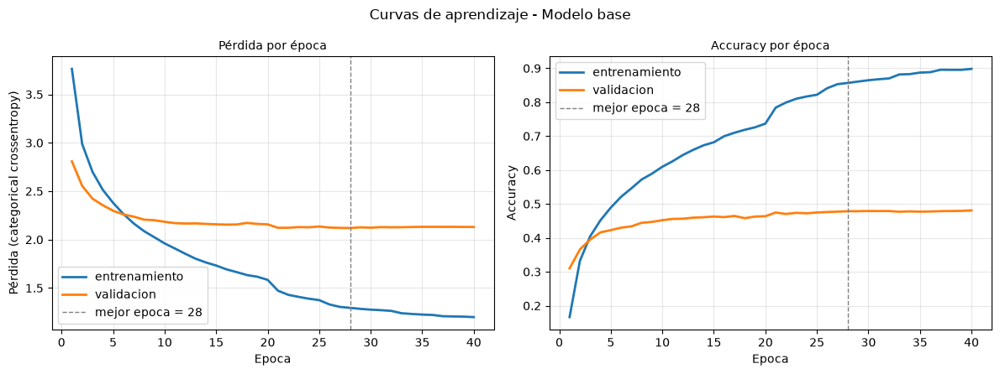

In [40]:
def graficar_curvas(historial, titulo="Modelo base"):
    """Dibuja pérdida y accuracy de entrenamiento y validación por época."""
    registro = historial.history if hasattr(historial, "history") else historial
    epocas = range(1, len(registro["loss"]) + 1)
    epoca_optima = int(np.argmin(registro["val_loss"])) + 1

    figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

    ejes[0].plot(epocas, registro["loss"], label="entrenamiento", linewidth=2)
    ejes[0].plot(epocas, registro["val_loss"], label="validacion", linewidth=2)
    ejes[0].set_ylabel("Pérdida (categorical crossentropy)")
    ejes[0].set_title("Pérdida por época", fontsize=10)

    ejes[1].plot(epocas, registro["accuracy"], label="entrenamiento", linewidth=2)
    ejes[1].plot(epocas, registro["val_accuracy"], label="validacion", linewidth=2)
    ejes[1].set_ylabel("Accuracy")
    ejes[1].set_title("Accuracy por época", fontsize=10)

    for eje in ejes:
        eje.axvline(
            epoca_optima,
            color="gray",
            linestyle="--",
            linewidth=1,
            label=f"mejor epoca = {epoca_optima}",
        )
        eje.set_xlabel("Epoca")
        eje.grid(alpha=0.3)
        eje.legend()

    figura.suptitle(f"Curvas de aprendizaje - {titulo}")
    plt.tight_layout()
    plt.show()


graficar_curvas(historial_base)

### Interpretación de las curvas

In [41]:
from sklearn.metrics import f1_score

registro = historial_base.history
indice_optimo = int(np.argmin(registro["val_loss"]))

# F1 macro en validación con los pesos restaurados de la mejor época
probabilidades_val = modelo_base.predict(X_val, batch_size=256, verbose=0)
predicciones_val = probabilidades_val.argmax(axis=1)
f1_macro_val = f1_score(y_val_idx, predicciones_val, average="macro")

diagnostico = pd.DataFrame(
    [
        ("Épocas ejecutadas", len(registro["loss"])),
        ("Mejor época (val_loss)", indice_optimo + 1),
        ("Pérdida entrenamiento", round(registro["loss"][indice_optimo], 4)),
        ("Pérdida validación", round(registro["val_loss"][indice_optimo], 4)),
        ("Accuracy entrenamiento", round(registro["accuracy"][indice_optimo], 4)),
        ("Accuracy validación", round(registro["val_accuracy"][indice_optimo], 4)),
        ("Top-3 accuracy validación", round(registro["val_top_3"][indice_optimo], 4)),
        ("F1 macro validación", round(float(f1_macro_val), 4)),
        (
            "Brecha train - val (accuracy)",
            round(registro["accuracy"][indice_optimo] - registro["val_accuracy"][indice_optimo], 4),
        ),
    ],
    columns=["Indicador", "Valor"],
)

display(diagnostico)

brecha = registro["accuracy"][indice_optimo] - registro["val_accuracy"][indice_optimo]
if brecha > 0.15:
    lectura = "sobreajuste claro: la red memoriza el entrenamiento y generaliza bastante peor"
elif brecha > 0.05:
    lectura = "sobreajuste moderado, contenido por el Dropout y la parada temprana"
else:
    lectura = "sin sobreajuste apreciable; las dos curvas evolucionan juntas"

print(f"Brecha train - val en accuracy: {brecha:.3f} -> {lectura}.")
print(
    f"Accuracy de validacion ({registro['val_accuracy'][indice_optimo]:.3f}) frente a los baselines:"
    f" azar {baseline_azar / 100:.3f} y clase mayoritaria {baseline_mayoritaria / 100:.3f}."
)

,Indicador,Valor
0,Épocas ejecutadas,40.0000
1,Mejor época (val_loss),28.0000
2,Pérdida entrenamiento,1.2950
3,Pérdida validación,2.1196
4,Accuracy entrenamiento,0.8568
5,Accuracy validación,0.4785
6,Top-3 accuracy validación,0.6729
7,F1 macro validación,0.4642
8,Brecha train - val (accuracy),0.3783


Brecha train - val en accuracy: 0.378 -> sobreajuste claro: la red memoriza el entrenamiento y generaliza bastante peor.
Accuracy de validacion (0.479) frente a los baselines: azar 0.016 y clase mayoritaria 0.055.


**Cómo se leen estas curvas**

Hay tres cosas que mirar en los gráficos anteriores:

1. **La separación entre las dos curvas de pérdida.** Mientras ambas bajan juntas, la red está
   aprendiendo estructura real del problema. En cuanto la pérdida de validación se aplana o sube
   mientras la de entrenamiento sigue bajando, lo que la red gana ya es memorización de las imágenes
   concretas del conjunto de entrenamiento: ese punto de cruce es el sobreajuste y es justo lo que
   detecta `EarlyStopping`.
2. **La época en que la validación deja de mejorar** (línea vertical punteada). Es la que se conserva,
   porque `restore_best_weights=True` devuelve los pesos de ese momento, y no los del final.
3. **El efecto de la regularización.** El Dropout hace que la curva de entrenamiento vaya *por debajo* de
   su potencial —parte de la red está apagada en cada paso— y por eso la brecha entre train y validación
   es menor de la que tendría el mismo MLP sin regularizar. El escalón que a veces se ve en las curvas
   corresponde a `ReduceLROnPlateau` bajando el learning rate.

La tabla de arriba resume el diagnóstico: la brecha entre entrenamiento y validación cuantifica el
sobreajuste, y la distancia frente a los baselines (azar y clase mayoritaria, impresos por la celda
anterior) confirma que el modelo efectivamente aprendió algo del problema.

**En la corrida del 09-11-2026** el diagnóstico fue de sobreajuste claro: en la mejor época, la accuracy de
entrenamiento del modelo base (0,857) quedó 0,378 por encima de la de validación (0,479), aunque la parada temprana conserve la mejor época. Con 1,4 millones de parámetros para unas 50.000 imágenes, la red
memoriza. Por eso la experimentación prueba más regularización (E6) y, sobre todo, entradas más pequeñas:
la de solo color (R2), que pasa al modelo final, usa una cuarta parte de los parámetros.

## Experimentación: comparación de configuraciones



### Diseño de los experimentos

La comparación sigue el principio de **un factor a la vez**: cada experimento cambia exactamente un
factor respecto del modelo base y deja el resto idéntico —misma semilla, misma partición, mismos pesos
por clase, mismos criterios de parada—. Así, cualquier diferencia en la métrica de validación es
atribuible al factor modificado y no a la interacción de varios cambios simultáneos.

| Exp. | Factor que cambia | Configuración | Qué pone a prueba |
|---|---|---|---|
| **Base** | — | Descriptores de color y textura de la imagen, 2 capas (512, 256), ReLU, lr 0,001, batch 128, dropout 0,3, pesos raíz, suavizado 0,1, con alteradas | Referencia |
| **R1** | Representación | Píxeles crudos (49.152 valores) | Si los descriptores aportan algo frente a la imagen aplanada |
| **R2** | Representación | Solo color (HSV + Lab) | Cuánto se puede reconocer solo por la paleta de color |
| **R3** | Representación | Solo textura (LBP + Gabor + HOG) | Cuánto aportan la textura y los bordes sin información de color |
| **E1** | Profundidad | 1 capa oculta (512) | Si una sola capa basta, o si la segunda aporta |
| **E2** | Profundidad y ancho | 3 capas (1024, 512, 256) | Si más capacidad mejora o solo sobreajusta |
| **E3** | Activación | 2 capas (512, 256) con tanh | El costo de una activación que se satura |
| **E4** | Tasa de aprendizaje | lr 0,0001 | Convergencia lenta pero estable frente al valor por defecto |
| **E5** | Tamaño de batch | batch 512 | Menos ruido por actualización y menos actualizaciones por época |
| **E6** | Regularización | Dropout 0,5 | Si más regularización reduce la brecha entre entrenamiento y validación |
| **P1** | Pesos por clase | Sin pesos | Cuánto aporta compensar el desbalance |
| **P2** | Pesos por clase | Balanceados completos | Si compensar del todo ayuda a los minoritarios o castiga demasiado a los frecuentes |
| **S1** | Suavizado | One-hot puro, sin suavizado | Si repartir el 10 % del objetivo ayuda con las etiquetas ambiguas |
| **A1** | Aumento de datos | Sin imágenes alteradas | Si las variantes de color y textura aportan |
| **C1** | Combinación | Los cambios que superaron a la base, juntos | Si las mejoras individuales se suman |

Las métricas registradas para cada configuración son la **accuracy** de validación —comparable con los
baselines— y el **F1 macro** de validación, que promedia sin ponderar los 64 personajes y es la métrica
que realmente refleja si el modelo atiende a los minoritarios. La selección final se hace por F1 macro,
por el desbalance ya documentado.

**Combinación final (C1).** Cambiar un factor a la vez dice qué ayuda por separado, pero no si las
mejoras se suman. Por eso, tras los experimentos individuales, C1 toma para cada factor el valor del
experimento que más superó a la base en F1 macro de validación y los aplica todos juntos. Si menos de dos
factores mejoraron, C1 no se entrena: coincidiría con un experimento ya medido.

Para acotar el costo, los experimentos usan un máximo de 35 épocas y una paciencia de 9 (el modelo
base se entrenó con 60 y paciencia 12); todos comparten exactamente ese presupuesto entre sí.

In [42]:
import time

EPOCAS_EXPERIMENTO = 35
PACIENCIA_EXPERIMENTO = 9

# Cada entrada cambia UN solo factor respecto del modelo base
experimentos = [
    {"nombre": "R1 - pixeles", "representacion": "pixeles"},
    {"nombre": "R2 - solo color", "representacion": "color"},
    {"nombre": "R3 - solo textura", "representacion": "textura"},
    {"nombre": "E1 - 1 capa (512)", "neuronas": (512,)},
    {"nombre": "E2 - 3 capas (1024,512,256)", "neuronas": (1024, 512, 256)},
    {"nombre": "E3 - activación tanh", "activacion": "tanh"},
    {"nombre": "E4 - learning rate 1e-4", "tasa_aprendizaje": 1e-4},
    {"nombre": "E5 - batch 512", "batch": 512},
    {"nombre": "E6 - dropout 0,5", "tasa_dropout": 0.5},
    {"nombre": "P1 - sin pesos por clase", "esquema_pesos": "ninguno"},
    {"nombre": "P2 - pesos balanceados", "esquema_pesos": "balanceado"},
    {"nombre": "S1 - sin suavizado", "suavizado": 0.0},
    {"nombre": "A1 - sin alteradas", "usar_alteradas": False},
]


def entrenar_configuracion(
    nombre,
    representacion=REPRESENTACION_BASE,
    neuronas=NEURONAS_OCULTAS,
    activacion=ACTIVACION,
    tasa_dropout=TASA_DROPOUT,
    tasa_aprendizaje=TASA_APRENDIZAJE,
    batch=TAMANO_BATCH,
    epocas=EPOCAS_EXPERIMENTO,
    paciencia=PACIENCIA_EXPERIMENTO,
    esquema_pesos=ESQUEMA_PESOS,
    suavizado=SUAVIZADO_ETIQUETAS,
    usar_alteradas=True,
):
    """Entrena una configuración y devuelve el modelo, su historial y sus métricas de validación."""
    keras.utils.set_random_seed(SEMILLA)  # misma inicialización para todas las configuraciones

    identificador = nombre.split(" - ")[0].strip().lower().replace(" ", "_")
    modelo = construir_mlp(
        neuronas_ocultas=neuronas,
        activacion=activacion,
        tasa_dropout=tasa_dropout,
        representacion=representacion,
        nombre=f"mlp_{identificador}",
    )
    modelo = modelo.to(DISPOSITIVO)
    compilar(modelo, tasa_aprendizaje=tasa_aprendizaje)  # solo para predict()

    matrices = matrices_gpu(representacion)
    X_entrena = matrices["train"]
    y_entrena = y_train
    if not usar_alteradas:
        X_entrena, y_entrena = X_entrena[filas_originales_train], y_entrena[filas_originales_train]

    inicio = time.perf_counter()
    historial = entrenar(
        modelo,
        X_entrena,
        y_entrena,
        matrices["val"],
        y_val,
        epocas=epocas,
        batch=batch,
        tasa_aprendizaje=tasa_aprendizaje,
        pesos_por_clase=PESOS_POR_ESQUEMA[esquema_pesos],
        suavizado=suavizado,
        paciencia=paciencia,
        ruta_modelo=DIRECTORIO_MODELOS / f"mlp_{identificador}.keras",
        verbose=0,
    )
    duracion = time.perf_counter() - inicio

    indice = int(np.argmin(historial.history["val_loss"]))
    predicciones = modelo.predict(matrices["val"], batch_size=256, verbose=0).argmax(axis=1)

    resultado = {
        "experimento": nombre,
        "representacion": representacion,
        "dimension_entrada": DIMENSIONES[representacion],
        "capas_ocultas": len(neuronas),
        "neuronas": " - ".join(str(n) for n in neuronas),
        "activacion": activacion,
        "dropout": tasa_dropout,
        "learning_rate": tasa_aprendizaje,
        "batch": batch,
        "pesos": esquema_pesos,
        "suavizado": suavizado,
        "alteradas": usar_alteradas,
        "epocas": len(historial.history["loss"]),
        "mejor_epoca": indice + 1,
        "parametros": int(modelo.count_params()),
        "val_loss": round(historial.history["val_loss"][indice], 4),
        "val_accuracy": round(historial.history["val_accuracy"][indice], 4),
        "val_f1_macro": round(float(f1_score(y_val_idx, predicciones, average="macro")), 4),
        "segundos": round(duracion, 1),
    }
    return modelo, historial, resultado


modelos = {}
historiales = {}
resultados = []

# El modelo base ya está entrenado: se incorpora a la comparación sin volver a entrenarlo
NOMBRE_BASE = "Base - color_textura (512,256)"
resultados.append(
    {
        "experimento": NOMBRE_BASE,
        "representacion": REPRESENTACION_BASE,
        "dimension_entrada": DIMENSION_ENTRADA,
        "capas_ocultas": len(NEURONAS_OCULTAS),
        "neuronas": " - ".join(str(n) for n in NEURONAS_OCULTAS),
        "activacion": ACTIVACION,
        "dropout": TASA_DROPOUT,
        "learning_rate": TASA_APRENDIZAJE,
        "batch": TAMANO_BATCH,
        "pesos": ESQUEMA_PESOS,
        "suavizado": SUAVIZADO_ETIQUETAS,
        "alteradas": True,
        "epocas": len(historial_base.history["loss"]),
        "mejor_epoca": indice_optimo + 1,
        "parametros": int(modelo_base.count_params()),
        "val_loss": round(registro["val_loss"][indice_optimo], 4),
        "val_accuracy": round(registro["val_accuracy"][indice_optimo], 4),
        "val_f1_macro": round(float(f1_macro_val), 4),
        "segundos": np.nan,
    }
)
modelos[NOMBRE_BASE] = modelo_base
historiales[NOMBRE_BASE] = historial_base.history


def registrar(nombre, factores):
    """Entrena una configuración y la añade a la comparación."""
    print(f"Entrenando {nombre} ...")
    modelo, historial, resultado = entrenar_configuracion(nombre, **factores)
    modelos[nombre] = modelo
    historiales[nombre] = historial.history
    resultados.append(resultado)
    print(
        f"   val_accuracy={resultado['val_accuracy']:.4f}"
        f"   val_f1_macro={resultado['val_f1_macro']:.4f}"
        f"   epocas={resultado['epocas']}   {resultado['segundos']:.0f} s"
    )


for configuracion in experimentos:
    registrar(
        configuracion["nombre"],
        {factor: valor for factor, valor in configuracion.items() if factor != "nombre"},
    )

# C1: para cada factor, el valor del experimento que más superó a la base en F1 macro
f1_macro_base = resultados[0]["val_f1_macro"]
mejor_por_factor = {}
for configuracion, resultado in zip(experimentos, resultados[1:]):
    if resultado["val_f1_macro"] <= f1_macro_base:
        continue
    for factor, valor in configuracion.items():
        if factor == "nombre":
            continue
        if factor not in mejor_por_factor or resultado["val_f1_macro"] > mejor_por_factor[factor][1]:
            mejor_por_factor[factor] = (valor, resultado["val_f1_macro"], configuracion["nombre"])

componentes_combinacion = sorted({origen for _, _, origen in mejor_por_factor.values()})
if len(mejor_por_factor) >= 2:
    print(f"\nC1 combina: {' + '.join(componentes_combinacion)}")
    registrar(
        "C1 - combinación de mejoras",
        {factor: valor for factor, (valor, _, _) in mejor_por_factor.items()},
    )
else:
    print(
        f"\nC1 no se entrena: solo {len(mejor_por_factor)} factor(es) superaron a la base"
        f" ({', '.join(componentes_combinacion) or 'ninguno'}), así que no hay nada que combinar."
    )

tabla_experimentos = pd.DataFrame(resultados)
display(tabla_experimentos)

Entrenando R1 - pixeles ...
   val_accuracy=0.2353   val_f1_macro=0.2078   epocas=34   121 s
Entrenando R2 - solo color ...
   val_accuracy=0.5065   val_f1_macro=0.5050   epocas=35   98 s
Entrenando R3 - solo textura ...
   val_accuracy=0.2976   val_f1_macro=0.2851   epocas=28   70 s
Entrenando E1 - 1 capa (512) ...
   val_accuracy=0.4518   val_f1_macro=0.4364   epocas=22   36 s
Entrenando E2 - 3 capas (1024,512,256) ...
   val_accuracy=0.4963   val_f1_macro=0.4846   epocas=35   121 s
Entrenando E3 - activación tanh ...
   val_accuracy=0.3991   val_f1_macro=0.3764   epocas=27   63 s
Entrenando E4 - learning rate 1e-4 ...
   val_accuracy=0.4371   val_f1_macro=0.4214   epocas=35   88 s
Entrenando E5 - batch 512 ...
   val_accuracy=0.4634   val_f1_macro=0.4464   epocas=35   23 s
Entrenando E6 - dropout 0,5 ...
   val_accuracy=0.4759   val_f1_macro=0.4599   epocas=35   93 s
Entrenando P1 - sin pesos por clase ...
   val_accuracy=0.4634   val_f1_macro=0.4395   epocas=26   60 s
Entrenando P2

,experimento,representacion,dimension_entrada,capas_ocultas,neuronas,activacion,dropout,learning_rate,batch,pesos,suavizado,alteradas,epocas,mejor_epoca,parametros,val_loss,val_accuracy,val_f1_macro,segundos
0,"Base - color_textura (512,256)",color_textura,2462,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,40,28,1411904,2.1196,0.4785,0.4642,NaN
1,R1 - pixeles,pixeles,49152,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,34,25,25317184,3.1801,0.2353,0.2078,121.0
2,R2 - solo color,color,370,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,35,35,340800,1.9890,0.5065,0.5050,98.5
3,R3 - solo textura,textura,2092,2,512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,28,19,1222464,2.8604,0.2976,0.2851,70.1
4,E1 - 1 capa (512),color_textura,2462,1,512,relu,0.3,0.0010,128,raiz,0.1,True,22,13,1295936,2.2249,0.4518,0.4364,36.5
5,"E2 - 3 capas (1024,512,256)",color_textura,2462,3,1024 - 512 - 256,relu,0.3,0.0010,128,raiz,0.1,True,35,27,3201856,2.0729,0.4963,0.4846,120.9
6,E3 - activación tanh,color_textura,2462,2,512 - 256,tanh,0.3,0.0010,128,raiz,0.1,True,27,18,1411904,2.4370,0.3991,0.3764,63.2
7,E4 - learning rate 1e-4,color_textura,2462,2,512 - 256,relu,0.3,0.0001,128,raiz,0.1,True,35,34,1411904,2.2602,0.4371,0.4214,87.5
8,E5 - batch 512,color_textura,2462,2,512 - 256,relu,0.3,0.0010,512,raiz,0.1,True,35,29,1411904,2.1731,0.4634,0.4464,23.1
9,"E6 - dropout 0,5",color_textura,2462,2,512 - 256,relu,0.5,0.0010,128,raiz,0.1,True,35,35,1411904,2.0705,0.4759,0.4599,93.4


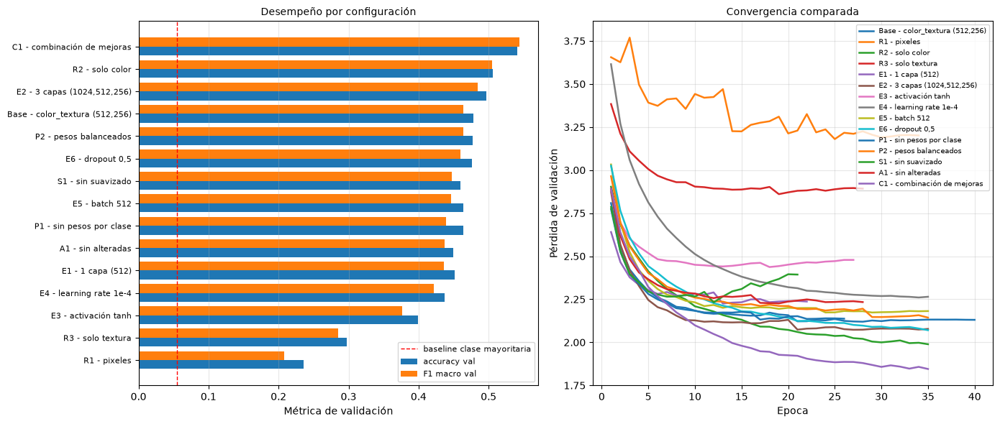

In [43]:
# Comparación visual de las configuraciones por accuracy y F1 macro de validación
orden_resultados = tabla_experimentos.sort_values("val_f1_macro", ascending=True)
posiciones = np.arange(len(orden_resultados))

figura, ejes = plt.subplots(1, 2, figsize=(14, 6))

ejes[0].barh(posiciones - 0.2, orden_resultados["val_accuracy"], height=0.4, label="accuracy val")
ejes[0].barh(posiciones + 0.2, orden_resultados["val_f1_macro"], height=0.4, label="F1 macro val")
ejes[0].set_yticks(posiciones)
ejes[0].set_yticklabels(orden_resultados["experimento"], fontsize=8)
ejes[0].axvline(baseline_mayoritaria / 100, color="red", linestyle="--", linewidth=1, label="baseline clase mayoritaria")
ejes[0].set_xlabel("Métrica de validación")
ejes[0].set_title("Desempeño por configuración", fontsize=10)
ejes[0].legend(fontsize=8)
ejes[0].grid(alpha=0.3, axis="x")

for nombre, registro_historial in historiales.items():
    ejes[1].plot(
        range(1, len(registro_historial["val_loss"]) + 1),
        registro_historial["val_loss"],
        label=nombre,
        linewidth=1.8,
    )
ejes[1].set_xlabel("Epoca")
ejes[1].set_ylabel("Pérdida de validación")
ejes[1].set_title("Convergencia comparada", fontsize=10)
ejes[1].grid(alpha=0.3)
ejes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

### Efecto de la representación de entrada

,experimento,representacion,dimension_entrada,parametros,val_accuracy,val_f1_macro,epocas,segundos
0,R2 - solo color,color,370,340800,0.5065,0.5050,35,98.5
1,"Base - color_textura (512,256)",color_textura,2462,1411904,0.4785,0.4642,40,NaN
2,R3 - solo textura,textura,2092,1222464,0.2976,0.2851,28,70.1
3,R1 - pixeles,pixeles,49152,25317184,0.2353,0.2078,34,121.0


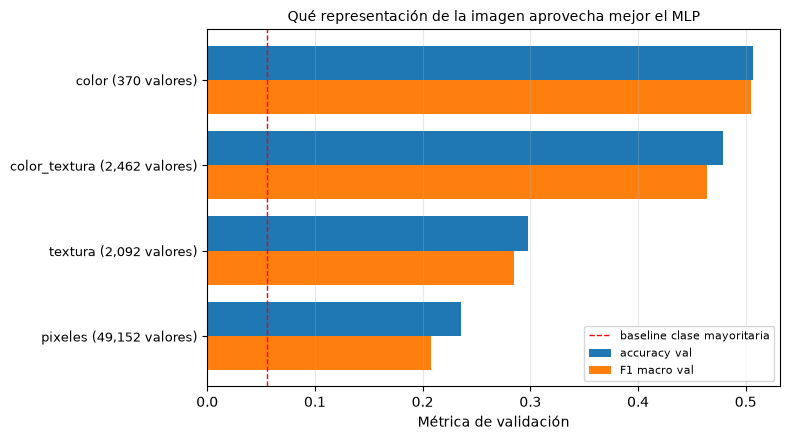

In [44]:
# Solo las configuraciones que cambian la representación (misma arquitectura que el base)
comparacion_representacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|R1|R2|R3")
][["experimento", "representacion", "dimension_entrada", "parametros", "val_accuracy", "val_f1_macro", "epocas", "segundos"]]
comparacion_representacion = comparacion_representacion.sort_values(
    "val_f1_macro", ascending=False
).reset_index(drop=True)

display(comparacion_representacion)

figura, eje = plt.subplots(figsize=(8, 4.5))
posiciones = np.arange(len(comparacion_representacion))
eje.barh(posiciones - 0.2, comparacion_representacion["val_accuracy"], height=0.4, label="accuracy val")
eje.barh(posiciones + 0.2, comparacion_representacion["val_f1_macro"], height=0.4, label="F1 macro val")
eje.set_yticks(posiciones)
eje.set_yticklabels(
    [
        f"{fila.representacion} ({fila.dimension_entrada:,} valores)"
        for fila in comparacion_representacion.itertuples()
    ],
    fontsize=9,
)
eje.invert_yaxis()
eje.axvline(
    baseline_mayoritaria / 100,
    color="red",
    linestyle="--",
    linewidth=1,
    label="baseline clase mayoritaria",
)
eje.set_xlabel("Métrica de validación")
eje.set_title("Qué representación de la imagen aprovecha mejor el MLP", fontsize=10)
eje.grid(alpha=0.3, axis="x")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.** La pregunta central del enfoque tiene una respuesta clara, aunque no la esperada: **el color
solo (R2) supera a la combinación de color y textura del modelo base**. En la corrida del 09-11-2026, con
la imagen completa, el modelo final usa solo color: gana la combinación C1, que solo toma la entrada de R2
si R2 superó a la base. La textura sola (R3) y los píxeles crudos (R1) quedan muy atrás.

Tres razones lo explican:

- **El color es lo que distingue a estos personajes.** Cada uno tiene una paleta fija —el pelo azul de
  Marge, el pelo verde de Krusty, la piel morena de Apu— y los histogramas HSV y Lab, calculados sobre la
  imagen completa y sobre sus cuatro cuadrantes, la capturan sin depender de dónde está el personaje.
- **La textura añade sobre todo ruido.** Los 2.092 valores de LBP, Gabor y HOG describen trazos y bordes,
  y en esta serie todos los personajes están dibujados con el mismo trazo. Al sumarlos a los 370 de color,
  el modelo base recibe casi seis valores de textura por cada uno de color y pasa de 340.800 a 1,4
  millones de parámetros: memoriza el entrenamiento y generaliza peor.
- **Los píxeles crudos son la peor entrada.** R1 tiene la primera capa más grande —25,2 millones de pesos
  a 128 × 128— y el peor resultado: sin los histogramas, el MLP tiene que aprender colores
  en posiciones fijas del encuadre, justo la limitación que los descriptores venían a resolver.

La importancia por permutación de la sección «En qué se apoya el modelo» confirma la lectura desde el
modelo final: barajar sus histogramas HSV deja el F1 macro de test en 0,08, y barajar los Lab, en 0,12.

### Efecto del número de capas ocultas y de neuronas

,experimento,capas_ocultas,neuronas,parametros,val_accuracy,val_f1_macro,epocas,segundos,parametros_millones
0,E1 - 1 capa (512),1,512,1295936,0.4518,0.4364,22,36.5,1.30
1,"Base - color_textura (512,256)",2,512 - 256,1411904,0.4785,0.4642,40,NaN,1.41
2,"E2 - 3 capas (1024,512,256)",3,1024 - 512 - 256,3201856,0.4963,0.4846,35,120.9,3.20


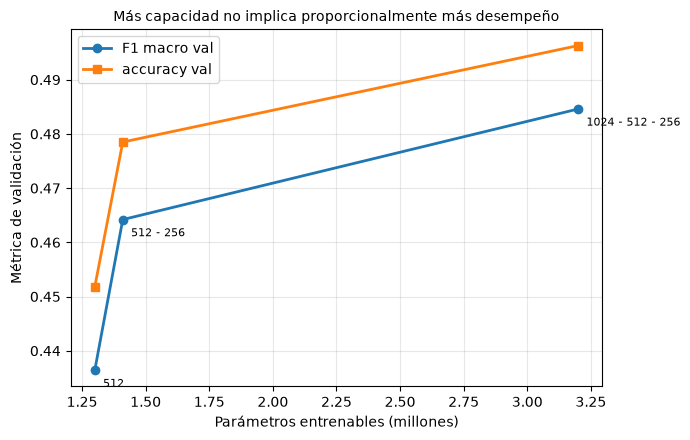

In [45]:
# Solo las configuraciones que cambian la arquitectura (misma activación, lr y batch que el base)
comparacion_arquitectura = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E1|E2")
][["experimento", "capas_ocultas", "neuronas", "parametros", "val_accuracy", "val_f1_macro", "epocas", "segundos"]]
comparacion_arquitectura = comparacion_arquitectura.sort_values("parametros").reset_index(drop=True)

comparacion_arquitectura["parametros_millones"] = (
    comparacion_arquitectura["parametros"] / 1e6
).round(2)

display(comparacion_arquitectura)

figura, eje = plt.subplots(figsize=(7, 4.5))
eje.plot(
    comparacion_arquitectura["parametros_millones"],
    comparacion_arquitectura["val_f1_macro"],
    marker="o",
    linewidth=2,
    label="F1 macro val",
)
eje.plot(
    comparacion_arquitectura["parametros_millones"],
    comparacion_arquitectura["val_accuracy"],
    marker="s",
    linewidth=2,
    label="accuracy val",
)
for _, fila in comparacion_arquitectura.iterrows():
    eje.annotate(
        fila["neuronas"],
        (fila["parametros_millones"], fila["val_f1_macro"]),
        textcoords="offset points",
        xytext=(6, -12),
        fontsize=8,
    )
eje.set_xlabel("Parámetros entrenables (millones)")
eje.set_ylabel("Métrica de validación")
eje.set_title("Más capacidad no implica proporcionalmente más desempeño", fontsize=10)
eje.grid(alpha=0.3)
eje.legend()
plt.tight_layout()
plt.show()

**Lectura.** Con descriptores, más profundidad ayuda, aunque poco. Las tres capas de E2 (1024, 512, 256)
superan a la base en F1 macro de validación y una sola capa (E1) queda por debajo de las dos. En la
corrida del 09-11-2026 ganó la combinación C1, y la arquitectura que heredó fue la de E2. A
diferencia de lo que pasaba con los píxeles, la entrada ya trae características con sentido —la
proporción de cada color en cada zona— y una capa más permite combinarlas en reglas más finas.

Pero el aumento tiene un costo alto y un techo bajo. E2 multiplica los parámetros por 2,3 (de 1,4 a 3,2
millones) para ganar poco F1 macro, mucho menos de lo que se gana al pasar a la entrada de solo color (R2)
sin tocar la arquitectura. La capacidad no es el cuello de botella: el modelo base ya llega a una accuracy
de entrenamiento muy por encima de la de validación, así que las neuronas extra se emplean sobre todo en
memorizar. Cada millón de parámetros adicional se paga además en tiempo por época
(columna `segundos`).

### Efecto de la función de activación

,experimento,activacion,val_loss,val_accuracy,val_f1_macro,epocas,mejor_epoca
0,"Base - color_textura (512,256)",relu,2.1196,0.4785,0.4642,40,28
1,E3 - activación tanh,tanh,2.4370,0.3991,0.3764,27,18


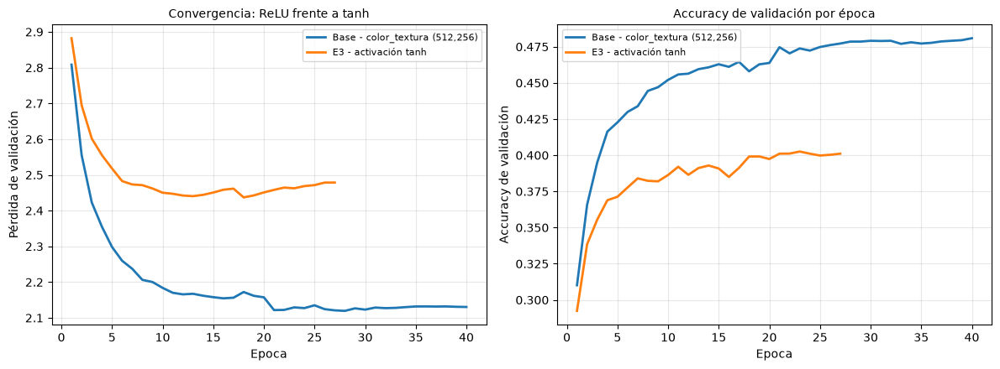

In [46]:
comparacion_activacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E3")
][["experimento", "activacion", "val_loss", "val_accuracy", "val_f1_macro", "epocas", "mejor_epoca"]]

display(comparacion_activacion.reset_index(drop=True))

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in comparacion_activacion["experimento"]:
    registro_historial = historiales[nombre]
    epocas_rango = range(1, len(registro_historial["loss"]) + 1)
    ejes[0].plot(epocas_rango, registro_historial["val_loss"], linewidth=2, label=nombre)
    ejes[1].plot(epocas_rango, registro_historial["val_accuracy"], linewidth=2, label=nombre)

ejes[0].set_ylabel("Pérdida de validación")
ejes[0].set_title("Convergencia: ReLU frente a tanh", fontsize=10)
ejes[1].set_ylabel("Accuracy de validación")
ejes[1].set_title("Accuracy de validación por época", fontsize=10)

for eje in ejes:
    eje.set_xlabel("Epoca")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Lectura.** ReLU gana con claridad. Con tanh (E3) el F1 macro de validación cae y la parada temprana
corta el entrenamiento mucho antes que en la base. Es lo descrito en «Funciones de activación»: la tanh está acotada en
(-1, 1) y su derivada cae hacia cero en los extremos, así que las neuronas saturadas dejan de aprender y la
validación se estanca pronto. ReLU no tiene ese techo —su derivada vale 1 para todo z > 0— y produce
activaciones dispersas: el recorrido de una imagen por la red entrenada (sección «El modelo en acción
sobre el conjunto de test») muestra qué parte de las neuronas de cada capa oculta queda en cero. El resultado confirma la elección de ReLU para el modelo base.

### Efecto del número de épocas, el tamaño de batch y la tasa de aprendizaje

,experimento,learning_rate,batch,epocas,mejor_epoca,val_loss,val_accuracy,val_f1_macro,segundos
0,"Base - color_textura (512,256)",0.0010,128,40,28,2.1196,0.4785,0.4642,NaN
1,E4 - learning rate 1e-4,0.0001,128,35,34,2.2602,0.4371,0.4214,87.5
2,E5 - batch 512,0.0010,512,35,29,2.1731,0.4634,0.4464,23.1


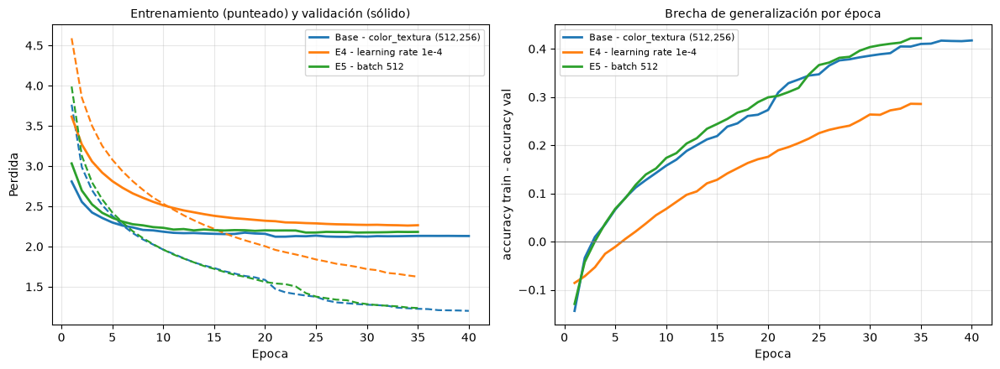

In [47]:
comparacion_optimizacion = tabla_experimentos[
    tabla_experimentos["experimento"].str.contains("Base|E4|E5")
][["experimento", "learning_rate", "batch", "epocas", "mejor_epoca", "val_loss", "val_accuracy", "val_f1_macro", "segundos"]]

display(comparacion_optimizacion.reset_index(drop=True))

figura, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for nombre in comparacion_optimizacion["experimento"]:
    registro_historial = historiales[nombre]
    epocas_rango = range(1, len(registro_historial["loss"]) + 1)
    ejes[0].plot(epocas_rango, registro_historial["loss"], linewidth=1.6, linestyle="--")
    ejes[0].plot(
        epocas_rango,
        registro_historial["val_loss"],
        linewidth=2,
        label=nombre,
        color=ejes[0].lines[-1].get_color(),
    )
    ejes[1].plot(
        epocas_rango,
        np.array(registro_historial["accuracy"]) - np.array(registro_historial["val_accuracy"]),
        linewidth=2,
        label=nombre,
    )

ejes[0].set_ylabel("Perdida")
ejes[0].set_title("Entrenamiento (punteado) y validación (sólido)", fontsize=10)
ejes[1].axhline(0, color="gray", linewidth=0.8)
ejes[1].set_ylabel("accuracy train - accuracy val")
ejes[1].set_title("Brecha de generalización por época", fontsize=10)

for eje in ejes:
    eje.set_xlabel("Epoca")
    eje.grid(alpha=0.3)
    eje.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Lectura.** Los tres hiperparámetros de optimización están acoplados y conviene leerlos juntos:

- **Tasa de aprendizaje.** Con 1e-4 (E4) el F1 macro de validación baja. El modelo no diverge: usa las 35
  épocas del presupuesto con su mejor época cerca del final, así que seguía mejorando cuando se acabó el
  tiempo. Un learning rate diez
  veces menor no llega a tiempo.
- **Tamaño de batch.** Con batch 512 (E5) cada época tiene cuatro veces menos actualizaciones de pesos y el
  F1 macro baja un poco. A cambio, es la configuración más barata (columna `segundos`), porque a batch
  128 la tarjeta pasa la mayor parte del tiempo esperando instrucciones (ver «Resumen de rendimiento de la
  corrida en la GPU»). Si el costo pesara más que el
  último punto de F1, lo siguiente a probar sería batch 512 con un learning rate mayor.
- **Número de épocas.** No se elige a mano: `mejor_epoca` muestra dónde la validación tocó su mínimo y
  `epocas` cuánto se entrenó antes de que la parada temprana cortara. La mitad de las configuraciones usa
  las 35 épocas del presupuesto con la mejor época cerca del final; las que se detienen antes —sin
  suavizado, una capa, sin pesos, tanh, solo textura y sin alteradas— son las que empiezan a sobreajustar o se estancan pronto.

El panel derecho muestra la brecha entre accuracy de entrenamiento y de validación época a época: cuando
crece de forma sostenida, cada época adicional se está invirtiendo en memorizar, no en generalizar.

### Efecto del tratamiento de los datos, la regularización y la combinación

Estos experimentos no tocan la arquitectura, sino lo que la red ve al entrenar: cuánto pesa cada
personaje (P1, P2), cuán duro es el objetivo (S1), si entran las variantes alteradas (A1) y cuánto se
regulariza (E6). La columna `delta_f1_vs_base` es la diferencia de F1 macro de validación frente al modelo
base: positiva si el cambio ayuda. C1, si se entrenó, junta los cambios que salieron positivos.

Al leer la tabla conviene mirar también la accuracy: un cambio que sube el F1 macro a costa de bajar mucho
la accuracy está desplazando aciertos de los personajes frecuentes a los escasos, no reconociendo mejor.

,experimento,pesos,suavizado,alteradas,dropout,val_accuracy,val_f1_macro,epocas,segundos,delta_accuracy_vs_base,delta_f1_vs_base
0,"Base - color_textura (512,256)",raiz,0.1,True,0.3,0.4785,0.4642,40,NaN,0.0000,0.0000
1,"E6 - dropout 0,5",raiz,0.1,True,0.5,0.4759,0.4599,35,93.4,-0.0026,-0.0043
2,P1 - sin pesos por clase,ninguno,0.1,True,0.3,0.4634,0.4395,26,60.4,-0.0151,-0.0247
3,P2 - pesos balanceados,balanceado,0.1,True,0.3,0.4773,0.4635,35,92.0,-0.0012,-0.0007
4,S1 - sin suavizado,raiz,0.0,True,0.3,0.4601,0.4475,21,57.6,-0.0184,-0.0167
5,A1 - sin alteradas,raiz,0.1,False,0.3,0.4495,0.4372,28,55.4,-0.0290,-0.0270
6,C1 - combinación de mejoras,raiz,0.1,True,0.3,0.5413,0.5440,35,114.9,0.0628,0.0798


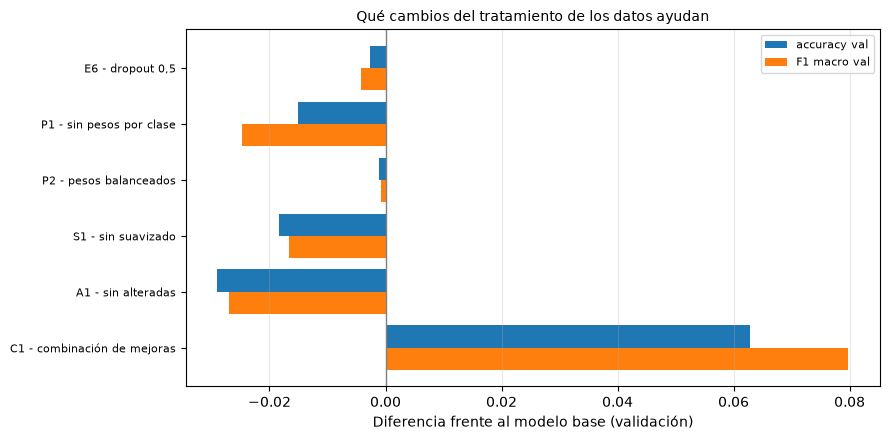

In [48]:
comparacion_datos = tabla_experimentos[
    tabla_experimentos["experimento"].str.match(r"Base|E6|P\d|S\d|A\d|C\d")
][
    ["experimento", "pesos", "suavizado", "alteradas", "dropout",
     "val_accuracy", "val_f1_macro", "epocas", "segundos"]
].reset_index(drop=True)
fila_base = comparacion_datos["experimento"].str.startswith("Base")
comparacion_datos["delta_accuracy_vs_base"] = (
    comparacion_datos["val_accuracy"] - float(comparacion_datos.loc[fila_base, "val_accuracy"].iloc[0])
).round(4)
comparacion_datos["delta_f1_vs_base"] = (
    comparacion_datos["val_f1_macro"] - float(comparacion_datos.loc[fila_base, "val_f1_macro"].iloc[0])
).round(4)
display(comparacion_datos)

figura, eje = plt.subplots(figsize=(9, 4.5))
otras = comparacion_datos[~fila_base].reset_index(drop=True)
posiciones = np.arange(len(otras))
eje.barh(posiciones - 0.2, otras["delta_accuracy_vs_base"], height=0.4, label="accuracy val")
eje.barh(posiciones + 0.2, otras["delta_f1_vs_base"], height=0.4, label="F1 macro val")
eje.set_yticks(posiciones)
eje.set_yticklabels(otras["experimento"], fontsize=8)
eje.invert_yaxis()
eje.axvline(0, color="gray", linewidth=1)
eje.set_xlabel("Diferencia frente al modelo base (validación)")
eje.set_title("Qué cambios del tratamiento de los datos ayudan", fontsize=10)
eje.grid(alpha=0.3, axis="x")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Selección del modelo final

In [49]:
import importlib.util
import inspect
import json

# El criterio de selección es el F1 macro de validación, no la accuracy:
# promedia todas las clases sin ponderar y penaliza ignorar a los personajes minoritarios
ranking = tabla_experimentos.sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
display(ranking[["experimento", "representacion", "val_accuracy", "val_f1_macro", "val_loss", "parametros", "epocas"]])

nombre_final = ranking.loc[0, "experimento"]
modelo_final = modelos[nombre_final]
representacion_final = ranking.loc[0, "representacion"]

print(f"Configuracion seleccionada: {nombre_final}")
print(f"  representacion      : {representacion_final} ({DIMENSIONES[representacion_final]} valores)")
print(f"  accuracy validacion : {ranking.loc[0, 'val_accuracy']:.4f}")
print(f"  F1 macro validacion : {ranking.loc[0, 'val_f1_macro']:.4f}")
print(f"  parametros          : {ranking.loc[0, 'parametros']:,}")
print(f"\nDiferencia en F1 macro frente a la segunda ({ranking.loc[1, 'experimento']}): {ranking.loc[0, 'val_f1_macro'] - ranking.loc[1, 'val_f1_macro']:+.4f}")

# --- El modelo final, listo para usarse fuera del notebook -----------------------------------------------
# Cuatro archivos con el mismo nombre base. Con ellos, scripts/newDataset/detectar_cajas.py encuentra después a
# cada personaje de una imagen y lo nombra con este modelo, sin volver a ejecutar el notebook. El notebook no
# usa ese script: el modelo se entrena y se evalúa solo con la imagen completa.
NOMBRE_MODELO_FINAL = "mlp_final"
ruta_modelo_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}.keras"
ruta_metadatos_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}.json"
ruta_entrada_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}_entrada.py"
ruta_particion_final = DIRECTORIO_MODELOS / f"{NOMBRE_MODELO_FINAL}_particion.csv"

# 1. La red entrenada
modelo_final.save(ruta_modelo_final)

# 2. Cómo se prepara su entrada. El archivo copia las funciones de «Descriptores de color y textura» con los
#    parámetros de esta corrida, así que fuera del notebook la entrada se calcula exactamente igual
FUNCIONES_ENTRADA = (
    regiones, frecuencias, cuantizar, histogramas_color, descriptor_lbp, descriptor_gabor, descriptor_hog,
    extraer_representacion,
)
CONSTANTES_ENTRADA = {
    "INTERVALOS_HSV": INTERVALOS_HSV,
    "INTERVALOS_LAB": INTERVALOS_LAB,
    "RANGOS_HSV": RANGOS_HSV,
    "RANGOS_LAB": RANGOS_LAB,
    "REJILLAS_COLOR": REJILLAS_COLOR,
    "CONFIGURACION_LBP": CONFIGURACION_LBP,
    "FRECUENCIAS_GABOR": FRECUENCIAS_GABOR,
    "ORIENTACIONES_HOG": ORIENTACIONES_HOG,
    "CELDAS_HOG": CELDAS_HOG,
    "BLOQUES_POR_REPRESENTACION": BLOQUES_POR_REPRESENTACION,
}
PREPARAR_ENTRADA = '''
def preparar(lote):
    """Entrada del modelo para un lote de imágenes RGB (n, ALTO, ANCHO, 3) en uint8, ya redimensionadas con
    interpolación bilineal: el vector de píxeles o los descriptores sin estandarizar (los estandariza la capa
    Normalization del modelo)."""
    lote = np.asarray(lote, dtype=np.uint8)
    if lote.ndim != 4 or lote.shape[1:] != (ALTO, ANCHO, 3):
        raise ValueError("Se esperaba un lote (n, %d, %d, 3) y llegó %s" % (ALTO, ANCHO, lote.shape))
    if REPRESENTACION == "pixeles":
        return lote.reshape(len(lote), -1)
    return np.stack([extraer_representacion(imagen, REPRESENTACION) for imagen in lote])
'''
codigo_entrada = "\n".join(
    [
        f'"""Entrada de {NOMBRE_MODELO_FINAL}.keras: de una imagen RGB redimensionada a lo que recibe la red.',
        "",
        f"Lo generó PMC/notebooks/LosSimpsons_GPU_4060M.ipynb el {datetime.now():%d-%m-%Y %H:%M}, copiando las",
        "funciones con que se entrenó el modelo. No se edita a mano: se vuelve a generar al ejecutar el notebook.",
        '"""',
        "",
        "import numpy as np",
        "from scipy.signal import fftconvolve",
        "from skimage.color import rgb2gray, rgb2hsv, rgb2lab",
        "from skimage.feature import hog, local_binary_pattern",
        "from skimage.filters import gabor_kernel",
        "",
        f"REPRESENTACION = {str(representacion_final)!r}",
        f"ALTO, ANCHO = {int(ALTO_OBJETIVO)}, {int(ANCHO_OBJETIVO)}",
        *(f"{nombre} = {valor!r}" for nombre, valor in CONSTANTES_ENTRADA.items()),
        f"ORIENTACIONES_GABOR = np.array({ORIENTACIONES_GABOR.tolist()!r})",
        "NUCLEOS_GABOR = [",
        "    np.real(gabor_kernel(frecuencia, theta=orientacion))",
        "    for frecuencia in FRECUENCIAS_GABOR",
        "    for orientacion in ORIENTACIONES_GABOR",
        "]",
        "",
        *("\n" + inspect.getsource(funcion) for funcion in FUNCIONES_ENTRADA),
        PREPARAR_ENTRADA,
    ]
)
ruta_entrada_final.write_text(codigo_entrada, encoding="utf-8")

# 3. Comprobación: el archivo generado tiene que dar exactamente la entrada con que se evaluó el modelo
especificacion_entrada = importlib.util.spec_from_file_location(ruta_entrada_final.stem, ruta_entrada_final)
entrada_generada = importlib.util.module_from_spec(especificacion_entrada)
especificacion_entrada.loader.exec_module(entrada_generada)
esperada = np.asarray(particion(representacion_final)["test"][:64])
obtenida = np.asarray(entrada_generada.preparar(imagenes_test[:64]))
diferencia_entrada = (
    float(np.abs(obtenida.astype(np.float64) - esperada.astype(np.float64)).max())
    if obtenida.shape == esperada.shape else float("inf")
)
if diferencia_entrada > 1e-5:
    raise ValueError(
        f"{ruta_entrada_final.name} no reproduce la entrada del modelo (diferencia máxima {diferencia_entrada})"
    )

# 4. A qué conjunto fue cada imagen original: el script de cajas usa por defecto solo las de test, que el
#    modelo no vio al entrenar
(
    datos.loc[~datos["alterada"], ["personaje", "origen", "conjunto"]]
    .rename(columns={"origen": "archivo"})
    .sort_values(["personaje", "archivo"])
    .to_csv(ruta_particion_final, index=False)
)

# 5. Lo que hace falta para repetir el pre-procesamiento sin volver a ejecutar el notebook: la representación,
#    la resolución, el orden de las clases (qué índice de salida es qué personaje) y los otros dos archivos
metadatos_final = {
    "modelo": "mlp",
    "configuracion": str(nombre_final),
    "representacion": str(representacion_final),
    "dimension_entrada": int(DIMENSIONES[representacion_final]),
    "entrada": "imagen completa en RGB, redimensionada con interpolación bilineal",
    "alto": int(ALTO_OBJETIVO),
    "ancho": int(ANCHO_OBJETIVO),
    "clases": [str(clase) for clase in clases],
    "preparacion": ruta_entrada_final.name,
    "particion": ruta_particion_final.name,
    "val_accuracy": round(float(ranking.loc[0, "val_accuracy"]), 4),
    "val_f1_macro": round(float(ranking.loc[0, "val_f1_macro"]), 4),
    "notebook": "PMC/notebooks/LosSimpsons_GPU_4060M.ipynb",
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
}
ruta_metadatos_final.write_text(json.dumps(metadatos_final, indent=2, ensure_ascii=False), encoding="utf-8")

display(
    pd.DataFrame(
        [
            (ruta_modelo_final.name, "la red entrenada"),
            (ruta_metadatos_final.name, "clases, resolución y representación de la entrada"),
            (ruta_entrada_final.name, f"preparación de la entrada (comprobada: diferencia {diferencia_entrada:.1e})"),
            (ruta_particion_final.name, "conjunto de cada imagen original"),
        ],
        columns=["Archivo", "Contenido"],
    )
)
print(f"Modelo final y sus archivos en: {DIRECTORIO_MODELOS.resolve()}")
print(
    "Para encontrar y nombrar a cada personaje con su caja, después del notebook y desde la raíz del repositorio:\n"
    "  .venv-gpu\\Scripts\\python.exe scripts\\newDataset\\detectar_cajas.py --modelo mlp ruta\\a\\imagen.jpg"
)


,experimento,representacion,val_accuracy,val_f1_macro,val_loss,parametros,epocas
0,C1 - combinación de mejoras,color,0.5413,0.5440,1.8451,1059648,35
1,R2 - solo color,color,0.5065,0.5050,1.9890,340800,35
2,"E2 - 3 capas (1024,512,256)",color_textura,0.4963,0.4846,2.0729,3201856,35
3,"Base - color_textura (512,256)",color_textura,0.4785,0.4642,2.1196,1411904,40
4,P2 - pesos balanceados,color_textura,0.4773,0.4635,2.1435,1411904,35
5,"E6 - dropout 0,5",color_textura,0.4759,0.4599,2.0705,1411904,35
6,S1 - sin suavizado,color_textura,0.4601,0.4475,2.2321,1411904,21
7,E5 - batch 512,color_textura,0.4634,0.4464,2.1731,1411904,35
8,P1 - sin pesos por clase,color_textura,0.4634,0.4395,2.1319,1411904,26
9,A1 - sin alteradas,color_textura,0.4495,0.4372,2.2259,1411904,28


Configuracion seleccionada: C1 - combinación de mejoras
  representacion      : color (370 valores)
  accuracy validacion : 0.5413
  F1 macro validacion : 0.5440
  parametros          : 1,059,648

Diferencia en F1 macro frente a la segunda (R2 - solo color): +0.0390


,Archivo,Contenido
0,mlp_final.keras,la red entrenada
1,mlp_final.json,"clases, resolución y representación de la entrada"
2,mlp_final_entrada.py,preparación de la entrada (comprobada: diferen...
3,mlp_final_particion.csv,conjunto de cada imagen original


Modelo final y sus archivos en: C:\Users\LaptopWin\Desktop\Trabajo\Duoc\3er-Anio\2do Semestre\TECNICAS_ML\Unidad 3\LosSimpsons_DeepLearning\PMC\models_gpu\newDataset
Para encontrar y nombrar a cada personaje con su caja, después del notebook y desde la raíz del repositorio:
  .venv-gpu\Scripts\python.exe scripts\newDataset\detectar_cajas.py --modelo mlp ruta\a\imagen.jpg


**Justificación de la decisión.** La configuración elegida es la que maximiza el **F1 macro de
validación**, y no la que maximiza la accuracy. Validación conserva la distribución real del dataset, con
una razón de desbalance de unos 21:1: la accuracy premia acertar en los personajes abundantes y apenas se
resiente si el modelo ignora a los escasos; el F1 macro, al promediar los 64 personajes sin ponderarlos,
sí lo penaliza. Como el objetivo declarado es reconocer personajes —los 64, no solo a Homero—, esa es la
métrica coherente con el problema.

La celda elige siempre la configuración de mayor F1 macro, sin margen de empate. En la corrida del
09-11-2026 ganó C1, con la entrada de solo color y las tres capas de E2 (1,06 millones de parámetros), por
delante de R2, con dos capas y 340.800 parámetros, por 3,9 puntos de F1 macro. Una diferencia de validación de alrededor de un punto
no distingue a dos configuraciones; en ese caso conviene preferir
la red más pequeña, por costo de entrenamiento y por menor riesgo de sobreajuste.

El modelo seleccionado, con su representación de entrada, es el que se evalúa en la sección siguiente
sobre el **conjunto de test**, que hasta este punto no se ha tocado ni para entrenar ni para elegir
hiperparámetros.

## Evaluación y métricas de desempeño

El conjunto de evaluación es el **test** reservado en la partición: el 10 % de las imágenes originales de
cada personaje, con la distribución real del dataset y en las mismas condiciones que el entrenamiento: las
imágenes casi idénticas a otra entran con su versión filtrada y un cuarto de las originales viene con su
variante alterada. El modelo nunca vio esas imágenes ni ninguna variante de ellas.

**Criterio de acierto.** Cada imagen de test entra completa, y una predicción es correcta solo si nombra al
personaje de su carpeta. Con ese criterio se calculan la accuracy, el top-3, el F1, el reporte por clase, la
matriz de confusión y los KPIs. Como referencia se informa la accuracy por escena, que también acepta a otro
personaje presente según la escena y las gemelas (sección «Escenas con varios personajes»). Las galerías usan
tres colores: verde si el modelo nombra al personaje de la carpeta, ámbar si se equivoca nombrando a otro
personaje de la escena y rojo en los demás errores.

Ya está cargado y procesado con **exactamente las mismas funciones** que el entrenamiento —el mismo
redimensionado a 128 x 128, los mismos descriptores y el mismo diccionario `clase_a_indice`—, porque las
tres particiones salieron del mismo índice. La celda siguiente toma la representación del modelo elegido,
que puede no ser la del modelo base, y comprueba que las matrices son coherentes con las del
entrenamiento.

In [50]:
# El test sale de la partición: se toma en la representación del modelo final, que
# puede no ser la del modelo base si la experimentación eligió otra entrada
print(f"Modelo final: {nombre_final}   |   representacion: {representacion_final}")

X_test = particion(representacion_final)["test"]

# Cada alterada de test acompaña a su original, que también está en test
originales_test = set(
    zip(datos_test.loc[~datos_test["alterada"], "personaje"], datos_test.loc[~datos_test["alterada"], "origen"])
)
alteradas_test = datos_test[datos_test["alterada"]]
alteradas_test_con_original = sum(
    (personaje, origen) in originales_test
    for personaje, origen in zip(alteradas_test["personaje"], alteradas_test["origen"])
)

comprobaciones_test = pd.DataFrame(
    [
        (
            "Todas las clases presentes",
            len(np.unique(y_test_idx)),
            NUMERO_CLASES,
            len(np.unique(y_test_idx)) == NUMERO_CLASES,
        ),
        (
            "Dimensión de entrada del modelo final",
            X_test.shape[1],
            DIMENSIONES[representacion_final],
            X_test.shape[1] == DIMENSIONES[representacion_final],
        ),
        (
            "Alteradas de test con su original en test",
            alteradas_test_con_original,
            len(alteradas_test),
            alteradas_test_con_original == len(alteradas_test),
        ),
        ("Etiquetas alineadas", len(y_test_idx), X_test.shape[0], len(y_test_idx) == X_test.shape[0]),
        ("Imágenes alineadas", len(imagenes_test), X_test.shape[0], len(imagenes_test) == X_test.shape[0]),
    ],
    columns=["Comprobacion", "Obtenido", "Esperado", "Correcto"],
)

display(comprobaciones_test)

if not comprobaciones_test["Correcto"].all():
    raise ValueError("El conjunto de test no cumple alguna de las comprobaciones.")

print(f"Conjunto de test: {len(datos_test)} imagenes")
print(f"X_test: {X_test.shape}   y_test: {y_test.shape}")

# A la VRAM, como el resto
X_test = matrices_gpu(representacion_final)["test"]
y_test = a_gpu(y_test)
print(f"X_test en {X_test.device}  |  VRAM total ocupada: "
      f"{torch.cuda.memory_allocated() / 1024 ** 3:.2f} GB")

Modelo final: C1 - combinación de mejoras   |   representacion: color


,Comprobacion,Obtenido,Esperado,Correcto
0,Todas las clases presentes,64,64,True
1,Dimensión de entrada del modelo final,370,370,True
2,Alteradas de test con su original en test,1390,1390,True
3,Etiquetas alineadas,7058,7058,True
4,Imágenes alineadas,7058,7058,True


Conjunto de test: 7058 imagenes
X_test: (7058, 370)   y_test: (7058, 64)
X_test en cuda:0  |  VRAM total ocupada: 4.92 GB


### Predicciones sobre las imágenes de test

El modelo final nombra el personaje de cada imagen de test. El criterio es uno solo: la predicción acierta si
nombra al personaje de la carpeta. La escena del episodio (±3 s) y las gemelas no cambian el acierto; quedan
para la accuracy por escena, de referencia.


In [51]:
# Predicciones del modelo final sobre las imágenes de test
probabilidades_test = modelo_final.predict(X_test, batch_size=256, verbose=0)
predicciones_test = probabilidades_test.argmax(axis=1)
confianza_test = probabilidades_test.max(axis=1)
# Personajes de la escena (±3 s y gemelas): no cambian el acierto, solo la accuracy por escena de referencia
acompanantes_test = [set(texto.split(", ")) if texto else set() for texto in datos_test["escena"]]

# Colores de las galerías de evaluación y de análisis de errores
COLOR_ACIERTO, COLOR_ESCENA, COLOR_ERROR = "#1b7f3b", "#d68910", "#c0392b"
TEXTO_RESULTADO = {
    COLOR_ACIERTO: "correcto",
    COLOR_ESCENA: "error: otro personaje de la escena",
    COLOR_ERROR: "incorrecto",
}

print(f"Imágenes de test: {len(predicciones_test)}   |   confianza media: {confianza_test.mean():.3f}")

Imágenes de test: 7058   |   confianza media: 0.562


### Accuracy global sobre el conjunto de prueba

In [52]:
perdida_test, accuracy_estricta_test, top3_estricto_test = modelo_final.evaluate(
    X_test, y_test, batch_size=256, verbose=0
)

# Criterio de acierto: la predicción es correcta si nombra al personaje de la carpeta, que es la etiqueta
# con la que se evalúa
acierto_estricto = predicciones_test == y_test_idx
acierto_test = acierto_estricto
y_test_eval = y_test_idx
accuracy_test = float(acierto_test.mean())
top3_por_imagen = (np.argsort(-probabilidades_test, axis=1)[:, :3] == y_test_idx[:, None]).any(axis=1)
top3_test = float(top3_por_imagen.mean())

# Referencia por escena: además acepta a otro personaje presente según la escena (±3 s) y las gemelas, que
# con la imagen completa también sale en el encuadre. No cambia el acierto
acierto_por_escena = np.array(
    [clases[predicho] in presentes for predicho, presentes in zip(predicciones_test, acompanantes_test)]
)
accuracy_por_escena_test = float((acierto_test | acierto_por_escena).mean())


def color_resultado(indice):
    """Verde si el modelo nombró al personaje de la carpeta, ámbar si se equivocó nombrando a otro personaje
    de la escena y rojo en los demás errores."""
    if acierto_estricto[indice]:
        return COLOR_ACIERTO
    return COLOR_ESCENA if acierto_por_escena[indice] else COLOR_ERROR


def rotulo_escena(indice):
    """Rótulo de un error que nombra a otro personaje de la escena."""
    return "error: otro personaje de la escena"


# Baselines definidos en "Definición del problema de clasificación"
conteos_test = np.bincount(y_test_idx, minlength=NUMERO_CLASES)
baseline_azar = 1 / NUMERO_CLASES
baseline_mayoritaria = conteos_test.max() / conteos_test.sum()
f1_macro_test = f1_score(y_test_idx, predicciones_test, average="macro")
f1_ponderado_test = f1_score(y_test_idx, predicciones_test, average="weighted")
f1_macro_estricto_test = f1_macro_test

comparacion_baselines = pd.DataFrame(
    [
        ("Clasificador aleatorio", baseline_azar, "-"),
        ("Clase mayoritaria siempre", baseline_mayoritaria, "-"),
        ("MLP final", accuracy_test, round(float(f1_macro_test), 4)),
    ],
    columns=["Modelo", "Accuracy test", "F1 macro test"],
)
comparacion_baselines["Accuracy test"] = comparacion_baselines["Accuracy test"].round(4)

display(comparacion_baselines)

print(f"Perdida en test      : {perdida_test:.4f}")
print(f"Accuracy en test     : {accuracy_test:.4f}   (nombra al personaje de la carpeta)")
print(f"Top-3 accuracy       : {top3_test:.4f}")
print(f"F1 macro en test     : {f1_macro_test:.4f}")
print(f"F1 ponderado en test : {f1_ponderado_test:.4f}")
print(f"Referencia           : accuracy por escena {accuracy_por_escena_test:.4f}")
print(
    f"\nMejora sobre el azar: x{accuracy_test / baseline_azar:.1f}   |   "
    f"sobre la clase mayoritaria: x{accuracy_test / baseline_mayoritaria:.1f}"
)

,Modelo,Accuracy test,F1 macro test
0,Clasificador aleatorio,0.0156,-
1,Clase mayoritaria siempre,0.0554,-
2,MLP final,0.5442,0.5507


Perdida en test      : 1.8402
Accuracy en test     : 0.5442   (nombra al personaje de la carpeta)
Top-3 accuracy       : 0.7358
F1 macro en test     : 0.5507
F1 ponderado en test : 0.5420
Referencia           : accuracy por escena 0.6319

Mejora sobre el azar: x34.8   |   sobre la clase mayoritaria: x9.8


### Precision, Recall y F1-Score por clase

In [53]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

# Con el criterio de acierto: la clase evaluada es la de la carpeta, o el personaje presente
# que nombró el modelo
reporte = classification_report(
    y_test_eval,
    predicciones_test,
    labels=range(NUMERO_CLASES),
    target_names=clases,
    digits=3,
    zero_division=0,
)
print(reporte)

precision, recall, f1, soporte = precision_recall_fscore_support(
    y_test_eval, predicciones_test, labels=range(NUMERO_CLASES), zero_division=0
)

metricas_por_clase = pd.DataFrame(
    {
        "personaje": clases,
        "n_test": soporte,
        "n_train": conteos_train,
        "precision": precision.round(3),
        "recall": recall.round(3),
        "f1": f1.round(3),
    }
).sort_values("f1", ascending=False, ignore_index=True)

display(metricas_por_clase)

correlacion = float(np.corrcoef(conteos_train, f1)[0, 1])
print(f"Correlacion entre imagenes de entrenamiento y F1 por clase: {correlacion:.3f}")

                             precision    recall  f1-score   support

     abraham_grampa_simpson      0.605     0.714     0.655       133
              agnes_skinner      0.590     0.486     0.533        74
     apu_nahasapeemapetilon      0.655     0.606     0.630        94
              barney_gumble      0.482     0.450     0.466       120
               bart_simpson      0.341     0.331     0.335       239
captain_horatio_mccallister      0.541     0.805     0.647        41
               carl_carlson      0.467     0.586     0.520       133
   charles_montgomery_burns      0.486     0.526     0.505       192
               chief_wiggum      0.542     0.557     0.549       185
            cletus_spuckler      0.696     0.676     0.686        71
             comic_book_guy      0.680     0.680     0.680       125
                  disco_stu      0.636     0.583     0.609        24
             dolph_starbeam      0.315     0.304     0.309        56
          dr_julius_hibbert      

,personaje,n_test,n_train,precision,recall,f1
0,sideshow_bob,112,846,0.712,0.839,0.770
1,dr_nick_riviera,37,275,0.725,0.784,0.753
2,kang_kodos,77,533,0.725,0.753,0.739
3,krusty_the_clown,157,1201,0.730,0.739,0.734
4,judge_snyder,26,179,0.889,0.615,0.727
...,...,...,...,...,...,...
59,bart_simpson,239,1696,0.341,0.331,0.335
60,todd_flanders,38,286,0.343,0.316,0.329
61,dolph_starbeam,56,371,0.315,0.304,0.309
62,rod_flanders,80,535,0.316,0.300,0.308


Correlacion entre imagenes de entrenamiento y F1 por clase: -0.119


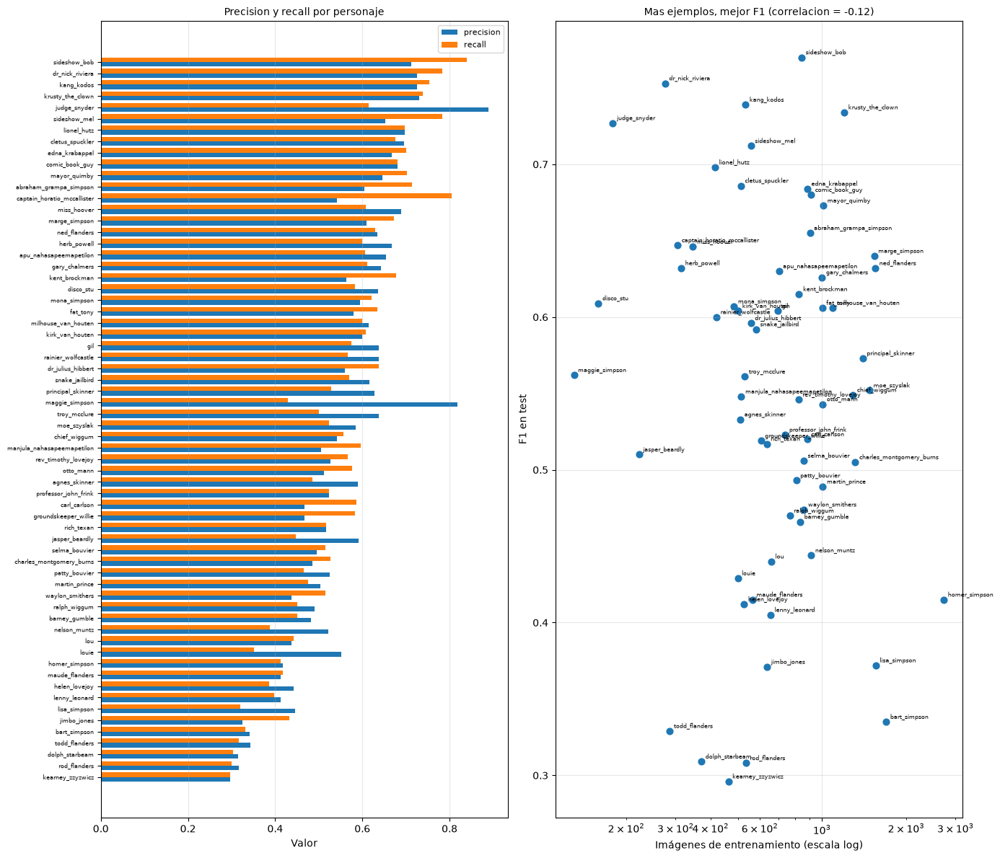

In [54]:
# Relación entre la cantidad de ejemplos de entrenamiento y el F1 alcanzado por cada clase
figura, ejes = plt.subplots(1, 2, figsize=(14, 12))

orden_f1 = metricas_por_clase.sort_values("f1")
posiciones = np.arange(len(orden_f1))
ejes[0].barh(posiciones - 0.2, orden_f1["precision"], height=0.4, label="precision")
ejes[0].barh(posiciones + 0.2, orden_f1["recall"], height=0.4, label="recall")
ejes[0].set_yticks(posiciones)
ejes[0].set_yticklabels(orden_f1["personaje"], fontsize=6)
ejes[0].set_xlabel("Valor")
ejes[0].set_title("Precision y recall por personaje", fontsize=10)
ejes[0].legend(fontsize=8)
ejes[0].grid(alpha=0.3, axis="x")

ejes[1].scatter(metricas_por_clase["n_train"], metricas_por_clase["f1"], s=40)
for _, fila in metricas_por_clase.iterrows():
    ejes[1].annotate(
        fila["personaje"],
        (fila["n_train"], fila["f1"]),
        textcoords="offset points",
        xytext=(4, 3),
        fontsize=6,
    )
ejes[1].set_xscale("log")
ejes[1].set_xlabel("Imágenes de entrenamiento (escala log)")
ejes[1].set_ylabel("F1 en test")
ejes[1].set_title(f"Mas ejemplos, mejor F1 (correlacion = {correlacion:.2f})", fontsize=10)
ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Lectura.** El reporte por clase muestra un patrón distinto del que haría esperar el desbalance. Tener
muchos ejemplos ayuda poco si el personaje no tiene una paleta propia. Los mejores F1 son de personajes con
colores inconfundibles y no necesariamente frecuentes —Sideshow Bob (0,77), Dr. Nick (0,75), Kang y Kodos
y Krusty (0,74 y 0,73)—, mientras que Bart, Lisa y Homero, con más de 1.500 imágenes de entrenamiento cada
uno, quedan en el cuarto inferior (0,34, 0,37 y 0,42): comparten la piel amarilla y salen juntos en las
mismas escenas, así que sus histogramas se parecen. Marge, con su pelo azul, es la excepción de la familia
(0,64).

Los pesos por clase suavizados cumplen su función: ningún personaje queda en cero, y el tamaño explica poco.
La correlación entre imágenes de entrenamiento y F1 es de −0,12, y entre los mejores hay personajes con
pocas imágenes, como Dr. Nick (275) y Judge Snyder (179). En el extremo inferior se juntan la familia y
secundarios sin paleta propia: Kearney (0,30), Rod Flanders, Dolph y Todd Flanders, con 286 a 535 imágenes
de entrenamiento.

Conviene distinguir las dos métricas: la **precisión** responde a "de todo lo que el modelo llamó Homero,
¿cuánto era Homero?", y el **recall**, a "de todos los Homeros que había, ¿cuántos encontró?". Homero tiene
una precisión baja porque el modelo lo usa como respuesta por defecto ante la
duda: la familia Simpson es el destino más frecuente de los errores de otras clases (ver «Confusiones más
frecuentes y posibles causas»).

### Matriz de confusión

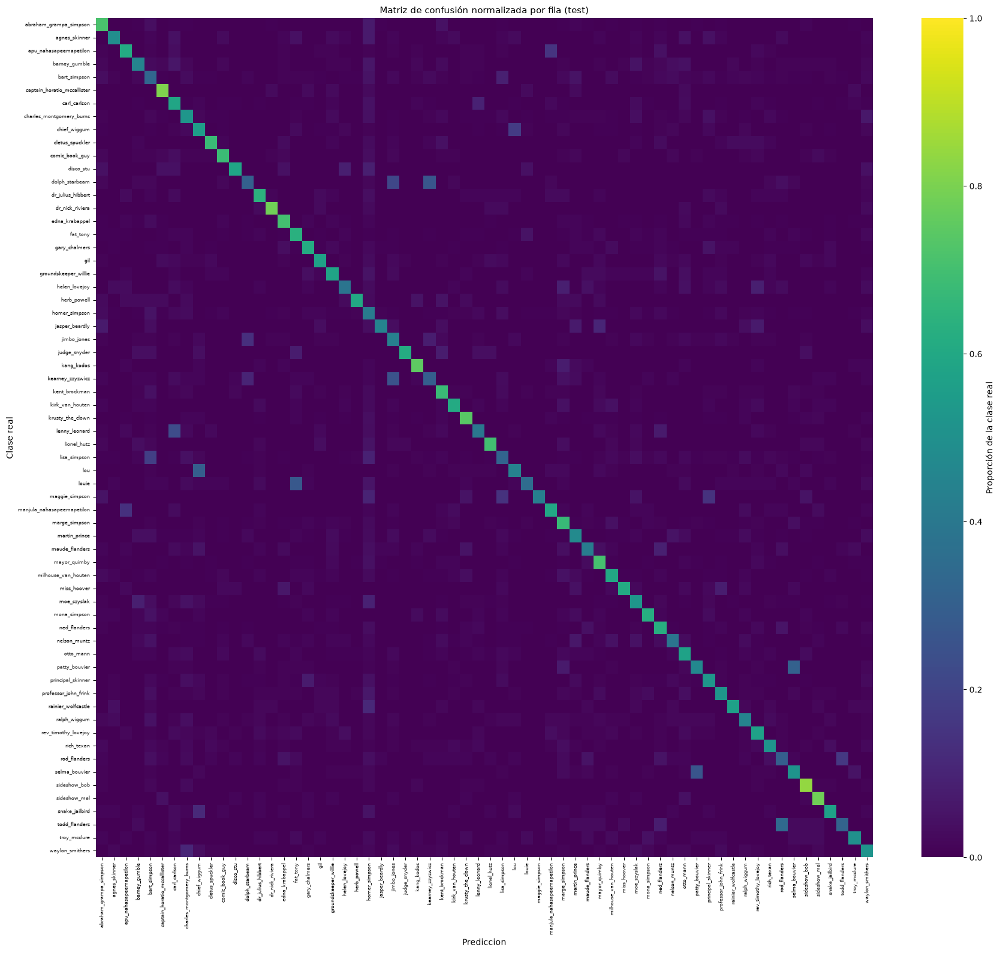

Recall medio (diagonal): 0.550
Clase mejor reconocida : sideshow_bob (0.839)
Clase peor reconocida  : kearney_zzyzwicz (0.296)


In [55]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Filas: la clase evaluada (la de la carpeta, o el personaje presente que nombró el modelo)
matriz = confusion_matrix(y_test_eval, predicciones_test, labels=range(NUMERO_CLASES))
# Normalizada por fila: cada fila suma 1, de modo que el desbalance no distorsione la lectura
totales_fila = matriz.sum(axis=1, keepdims=True)
matriz_normalizada = np.divide(matriz, totales_fila, out=np.zeros(matriz.shape), where=totales_fila > 0)

figura, eje = plt.subplots(figsize=(18, 16))
sns.heatmap(
    matriz_normalizada,
    annot=False,
    cmap="viridis",
    vmin=0,
    vmax=1,
    xticklabels=clases,
    yticklabels=clases,
    cbar_kws={"label": "Proporción de la clase real"},
    ax=eje,
)
eje.set_xlabel("Prediccion")
eje.set_ylabel("Clase real")
eje.set_title("Matriz de confusión normalizada por fila (test)", fontsize=11)
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.show()

aciertos_diagonal = np.diag(matriz_normalizada)
print(f"Recall medio (diagonal): {aciertos_diagonal.mean():.3f}")
print(f"Clase mejor reconocida : {clases[int(aciertos_diagonal.argmax())]} ({aciertos_diagonal.max():.3f})")
print(f"Clase peor reconocida  : {clases[int(aciertos_diagonal.argmin())]} ({aciertos_diagonal.min():.3f})")

### Interpretación crítica de las métricas

In [56]:
# Comparación de las tres lecturas globales y su distancia
resumen_metricas = pd.DataFrame(
    [
        ("Accuracy (test)", round(float(accuracy_test), 4), "Imágenes en que nombra al personaje de la carpeta; domina por las clases grandes"),
        ("Accuracy por escena (test)", round(float(accuracy_por_escena_test), 4), "También acepta a otro personaje presente, como con la imagen completa; referencia"),
        ("F1 ponderado (test)", round(float(f1_ponderado_test), 4), "Promedio de F1 pesado por el tamaño de cada clase"),
        ("F1 macro (test)", round(float(f1_macro_test), 4), "Promedio simple de todas las clases; cada personaje pesa igual"),
        ("Top-3 accuracy (test)", round(float(top3_test), 4), "El personaje de la carpeta está entre las 3 más probables"),
    ],
    columns=["Metrica", "Valor", "Que mide"],
)
display(resumen_metricas)

brecha_metricas = float(accuracy_test) - float(f1_macro_test)

# Clases que el modelo prácticamente no reconoce
clases_debiles = metricas_por_clase[metricas_por_clase["f1"] < 0.30]
clases_fuertes = metricas_por_clase[metricas_por_clase["f1"] >= 0.60]

print(f"Brecha accuracy - F1 macro: {brecha_metricas:.3f}")
print(f"Clases con F1 >= 0.60 : {len(clases_fuertes)} de {NUMERO_CLASES}")
print(f"Clases con F1 <  0.30 : {len(clases_debiles)} de {NUMERO_CLASES}")
if len(clases_debiles):
    print("  " + ", ".join(clases_debiles["personaje"].tolist()))
print(
    f"\nMediana de imagenes de entrenamiento en las clases fuertes: "
    f"{clases_fuertes['n_train'].median():.0f}"
)
if len(clases_debiles):
    print(
        f"Mediana de imagenes de entrenamiento en las clases debiles : "
        f"{clases_debiles['n_train'].median():.0f}"
    )

,Metrica,Valor,Que mide
0,Accuracy (test),0.5442,Imágenes en que nombra al personaje de la carp...
1,Accuracy por escena (test),0.6319,"También acepta a otro personaje presente, como..."
2,F1 ponderado (test),0.5420,Promedio de F1 pesado por el tamaño de cada clase
3,F1 macro (test),0.5507,Promedio simple de todas las clases; cada pers...
4,Top-3 accuracy (test),0.7358,El personaje de la carpeta está entre las 3 má...


Brecha accuracy - F1 macro: -0.006
Clases con F1 >= 0.60 : 27 de 64
Clases con F1 <  0.30 : 1 de 64
  kearney_zzyzwicz

Mediana de imagenes de entrenamiento en las clases fuertes: 695
Mediana de imagenes de entrenamiento en las clases debiles : 463


**Qué revela la distancia entre las métricas.** A diferencia del dataset anterior, la accuracy y el F1
macro quedan muy cerca: en la corrida del 09-11-2026 el F1 macro (0,551) queda incluso 0,6 puntos por
encima de la accuracy (0,544), y el F1 ponderado prácticamente coincide con ella (0,542). El desempeño está repartido de forma bastante pareja entre
personajes grandes y pequeños: los pesos por clase y la selección por F1 macro evitan que el modelo se
concentre en los frecuentes. Lo que queda es una cola de personajes con F1 bajo, que combinan pocas
imágenes con una paleta poco distintiva.

La **accuracy por escena**, de referencia, que acepta además a otro personaje presente, queda 8,8 puntos
por encima (0,632): esa diferencia son las 619 imágenes en las que el modelo nombró a otro personaje que sí
está en la escena (sección «Escenas con varios personajes: errores que nombran a otro personaje
(referencia)»).

La **top-3 accuracy** supera a la accuracy en 19,2 puntos: en buena parte de los errores, el personaje
correcto está entre las tres candidatas más probables. El modelo extrae señal real, pero no la suficiente
para decidir entre personajes de paleta parecida, algo que un catalogador resuelve de un vistazo si el
sistema le propone tres opciones.

### Cumplimiento de los KPIs definidos

Los cinco KPIs declarados al inicio se contrastan aqui con las cifras de la prueba
final. El umbral de cada uno se fijo antes de entrenar, de modo que la tabla es una
verificacion y no una justificacion a posteriori del resultado obtenido.

In [57]:
# Verificacion de los KPIs definidos al inicio del notebook: cada umbral se fijo
# antes de evaluar, y aqui se contrasta con las cifras obtenidas en la prueba final.
import time

# Costo de catalogación de extremo a extremo: calcular la entrada del modelo a partir de
# las imágenes ya redimensionadas (los descriptores, si el modelo los usa) y pasarla por
# la red. La lectura del disco no se incluye, igual que en la corrida del dataset anterior.
inicio_inferencia = time.perf_counter()
if representacion_final == "pixeles":
    entrada_inferencia = X_test
else:
    # Solo se calculan los bloques que usa el modelo final: si es "color", ni la textura
    # ni los bordes, que son la parte más cara de los descriptores
    descriptores_test = np.concatenate(
        Parallel(n_jobs=-1)(
            delayed(extraer_lote)(
                imagenes_test[inicio:inicio + TAMANO_LOTE_DESCRIPTORES], representacion_final
            )
            for inicio in range(0, len(imagenes_test), TAMANO_LOTE_DESCRIPTORES)
        )
    )
    entrada_inferencia = a_gpu(descriptores_test)
modelo_final.predict(entrada_inferencia, batch_size=256, verbose=0)
segundos_inferencia = time.perf_counter() - inicio_inferencia
imagenes_por_segundo = len(imagenes_test) / segundos_inferencia

# La extracción parcial debe dar exactamente las mismas columnas que se usaron al evaluar
if representacion_final != "pixeles" and not np.array_equal(
    descriptores_test, particion(representacion_final)["test"]
):
    raise ValueError("Los descriptores de la inferencia no coinciden con los de la evaluación.")

ventaja_mayoritaria = float(accuracy_test) / baseline_mayoritaria

kpis = [
    ("Cobertura de asistencia", "Top-3 accuracy", 0.70, float(top3_test), "{:.4f}"),
    ("Equidad entre personajes", "F1 macro", 0.45, float(f1_macro_test), "{:.4f}"),
    ("Automatizacion sin revision", "Accuracy", 0.50, float(accuracy_test), "{:.4f}"),
    ("Ventaja sobre criterio trivial", "Accuracy / mayoritaria", 4.0, ventaja_mayoritaria, "x{:.1f}"),
    ("Costo de catalogacion", "Imagenes por segundo (entrada + red)", 1000.0, imagenes_por_segundo, "{:,.0f}"),
]

tabla_kpis = pd.DataFrame(
    [
        {
            "KPI": nombre,
            "Metrica": metrica,
            "Umbral": formato.format(umbral),
            "Obtenido": formato.format(obtenido),
            "Cumple": "SI" if obtenido >= umbral else "NO",
        }
        for nombre, metrica, umbral, obtenido, formato in kpis
    ]
)

cumplidos = sum(1 for _, _, umbral, obtenido, _ in kpis if obtenido >= umbral)
print(f"KPIs cumplidos: {cumplidos} de {len(kpis)}\n")
display(tabla_kpis)

KPIs cumplidos: 4 de 5



,KPI,Metrica,Umbral,Obtenido,Cumple
0,Cobertura de asistencia,Top-3 accuracy,0.7000,0.7358,SI
1,Equidad entre personajes,F1 macro,0.4500,0.5507,SI
2,Automatizacion sin revision,Accuracy,0.5000,0.5442,SI
3,Ventaja sobre criterio trivial,Accuracy / mayoritaria,x4.0,x9.8,SI
4,Costo de catalogacion,Imagenes por segundo (entrada + red),"1,000",928,NO


## Análisis de resultados y de errores

### El modelo en acción sobre el conjunto de test

Las métricas anteriores resumen miles de decisiones en cuatro números. Esta sección hace lo contrario:
toma imágenes concretas del conjunto de test —las que el modelo nunca vio— y muestra el proceso completo,
desde el vector de entrada hasta la distribución de probabilidad de salida.

El primer gráfico recorre una imagen a través de la red **ya entrenada**. Es el mismo diagrama que se
mostró en los fundamentos con pesos aleatorios, pero ahora las activaciones son el resultado del
aprendizaje: se puede comparar directamente el reparto plano de entonces con la distribución concentrada
de ahora.

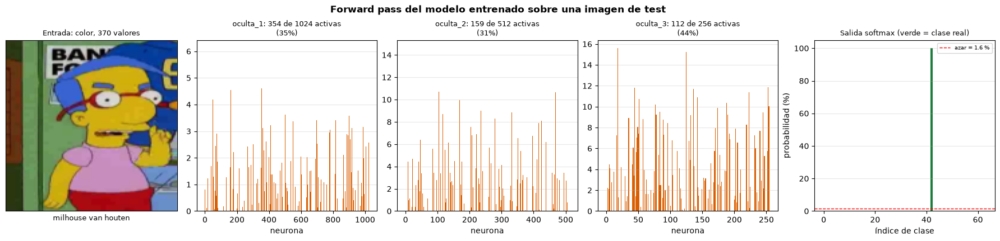

Prediccion: milhouse_van_houten con 100.0 % de confianza   |   clase real: milhouse_van_houten
Frente al 1.6 % que asignaria el azar: la red ya no reparte la probabilidad, la concentra.


In [58]:
# Recorrido de una imagen del conjunto de test por la red entrenada:
# del vector de entrada a las probabilidades de salida
demo_aciertos = np.flatnonzero(predicciones_test == y_test_idx)
demo_indice = int(demo_aciertos[np.argsort(-confianza_test[demo_aciertos])][0])

# Activaciones capa a capa: cada capa se aplica sobre la salida de la anterior.
# training=False apaga el Dropout y hace que BatchNormalization use sus estadísticas acumuladas.
# Los tensores viven en la VRAM: hay que traerlos a la RAM del equipo antes de
# convertirlos a NumPy para graficarlos.
activaciones = {}
tensor_demo = X_test[demo_indice : demo_indice + 1]
for capa in modelo_final.layers:
    tensor_demo = capa(tensor_demo, training=False)
    activaciones[capa.name] = tensor_demo.detach().cpu().numpy()[0]

nombres_ocultas = [
    capa.name
    for capa in modelo_final.layers
    if isinstance(capa, layers.Dense) and capa.name != "salida"
]
salida_demo = activaciones["salida"]
real_demo = int(y_test_idx[demo_indice])

figura = plt.figure(
    figsize=(4.2 + 3.2 * len(nombres_ocultas) + 4.0, 4.2), layout="constrained"
)
malla = figura.add_gridspec(1, len(nombres_ocultas) + 2)

# Entrada: la imagen de test. El modelo no recibe estos píxeles tal cual, sino su
# vector de entrada: píxeles aplanados o descriptores, según la representación.
eje_entrada = figura.add_subplot(malla[0, 0])
eje_entrada.imshow(imagenes_test[demo_indice])
eje_entrada.set_title(f"Entrada: {representacion_final}, {X_test.shape[1]:,} valores", fontsize=9)
eje_entrada.set_xlabel(clases[real_demo].replace("_", " "), fontsize=9)
eje_entrada.set_xticks([])
eje_entrada.set_yticks([])

# Capas ocultas: activación de cada neurona para esta imagen
for posicion, nombre_capa in enumerate(nombres_ocultas, start=1):
    valores = activaciones[nombre_capa]
    eje = figura.add_subplot(malla[0, posicion])
    eje.bar(
        range(len(valores)),
        valores,
        width=1.0,
        color=["#d95f02" if v > 0 else "#cccccc" for v in valores],
    )
    activas = int((valores > 0).sum())
    eje.set_title(
        f"{nombre_capa}: {activas} de {len(valores)} activas"
        f"\n({activas / len(valores):.0%})",
        fontsize=9,
    )
    eje.set_xlabel("neurona")
    eje.grid(alpha=0.3, axis="y")

# Salida: distribución softmax sobre todas las clases
eje_salida = figura.add_subplot(malla[0, -1])
eje_salida.bar(
    range(NUMERO_CLASES),
    salida_demo * 100,
    color=["#1b7f3b" if i == real_demo else "#8fb8de" for i in range(NUMERO_CLASES)],
)
eje_salida.axhline(
    100 / NUMERO_CLASES,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"azar = {100 / NUMERO_CLASES:.1f} %",
)
eje_salida.set_title("Salida softmax (verde = clase real)", fontsize=9)
eje_salida.set_xlabel("índice de clase")
eje_salida.set_ylabel("probabilidad (%)")
eje_salida.legend(fontsize=7)
eje_salida.grid(alpha=0.3, axis="y")

figura.suptitle(
    "Forward pass del modelo entrenado sobre una imagen de test",
    fontsize=12,
    fontweight="bold",
)
plt.show()

print(
    f"Prediccion: {clases[int(salida_demo.argmax())]} con {salida_demo.max() * 100:.1f} % de confianza"
    f"   |   clase real: {clases[real_demo]}"
)
print(
    f"Frente al {100 / NUMERO_CLASES:.1f} % que asignaria el azar: la red ya no reparte la"
    " probabilidad, la concentra."
)

**Qué muestra el recorrido.** Dos cosas cambian respecto de la red sin entrenar. En las capas ocultas solo
una parte de las neuronas se activa para esta imagen —el resto queda en cero por efecto de ReLU—: la representación es
**dispersa**, y qué subconjunto se enciende es lo que codifica al personaje. En la salida, la probabilidad
deja de repartirse entre las 64 clases y se concentra casi toda en una sola: el acierto más seguro del test
recibe casi toda la probabilidad, frente al 1,6 % que daría el azar.

Conviene recordar que la imagen de la izquierda no es lo que recibe el modelo. Con la entrada de solo
color, que eligió la experimentación en la corrida del 09-11-2026, la red ve 370 números: la proporción de cada
tono, saturación, brillo y color Lab en la imagen completa y en cada uno de sus cuatro cuadrantes. La forma
del personaje y su posición dentro de cada cuadrante no llegan a la red.

#### Predicciones individuales: las cinco clases más probables

En lugar de quedarse con la clase ganadora, aquí se abre la distribución completa. La barra de cada
candidata muestra cuánta probabilidad le asignó el modelo, lo que permite distinguir entre una decisión
tomada con holgura y una en la que dos personajes quedaron casi empatados.

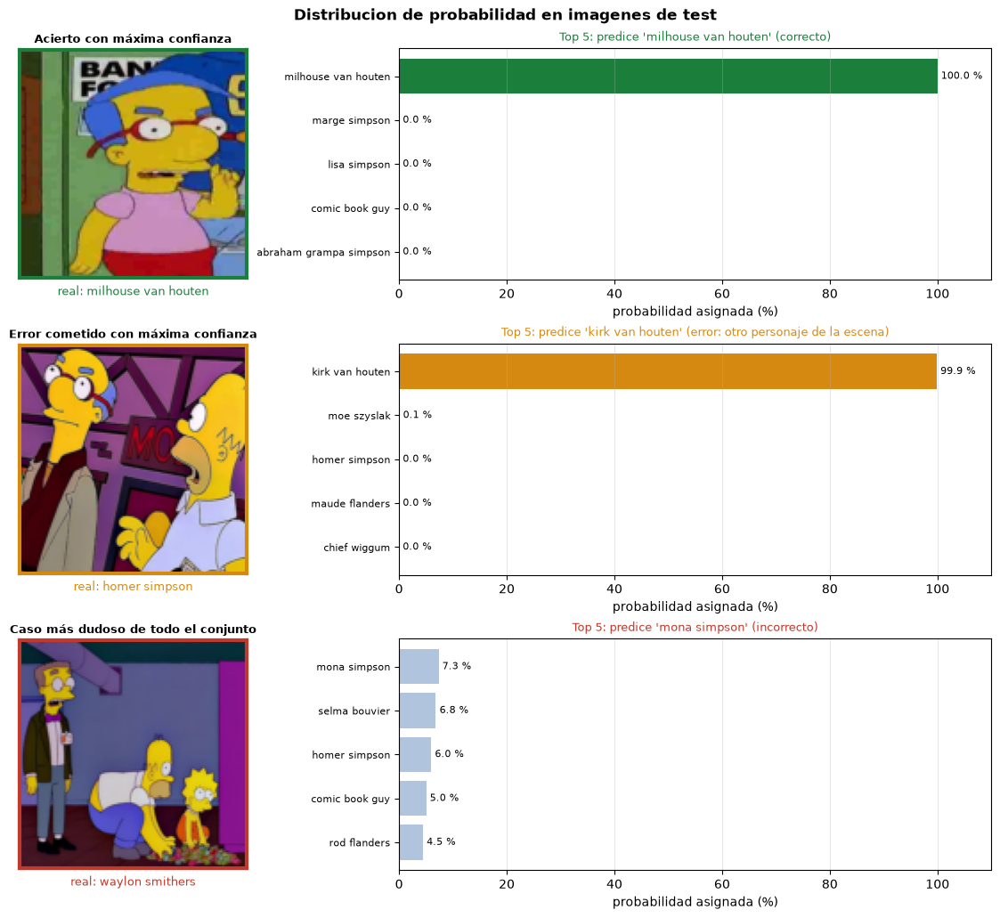

In [59]:
# Tres casos representativos: un acierto seguro, un error seguro y un caso donde el modelo dudó
# Errores según el criterio de acierto: nombrar a otro personaje es un error aunque esté en la escena
demo_errores = np.flatnonzero(~acierto_test)

casos = [
    (int(demo_aciertos[np.argmax(confianza_test[demo_aciertos])]), "Acierto con máxima confianza"),
    (int(demo_errores[np.argmax(confianza_test[demo_errores])]), "Error cometido con máxima confianza"),
    (int(np.argmin(confianza_test)), "Caso más dudoso de todo el conjunto"),
]

TOP_K = 5
figura, ejes = plt.subplots(
    len(casos),
    2,
    figsize=(11, 3.4 * len(casos)),
    layout="constrained",
    gridspec_kw={"width_ratios": [1, 2.6]},
)

for fila, (indice, descripcion) in enumerate(casos):
    real = int(y_test_idx[indice])
    predicho = int(predicciones_test[indice])
    color = color_resultado(indice)

    eje_imagen = ejes[fila, 0]
    eje_imagen.imshow(imagenes_test[indice])
    eje_imagen.set_xticks([])
    eje_imagen.set_yticks([])
    for lado in eje_imagen.spines.values():
        lado.set_edgecolor(color)
        lado.set_linewidth(3)
    eje_imagen.set_xlabel(
        f"real: {clases[real].replace('_', ' ')}", fontsize=9, labelpad=6, color=color
    )
    eje_imagen.set_title(descripcion, fontsize=9, fontweight="bold")

    # Las TOP_K clases con mayor probabilidad, dibujadas de mayor a menor
    mejores = np.argsort(-probabilidades_test[indice])[:TOP_K][::-1]
    etiquetas = [clases[i].replace("_", " ") for i in mejores]
    colores = [
        COLOR_ACIERTO if i == real else COLOR_ESCENA if clases[i] in acompanantes_test[indice] else "#b0c4de"
        for i in mejores
    ]

    eje_barras = ejes[fila, 1]
    barras = eje_barras.barh(etiquetas, probabilidades_test[indice][mejores] * 100, color=colores)
    eje_barras.bar_label(barras, fmt="%.1f %%", fontsize=8, padding=3)
    eje_barras.set_xlim(0, 110)
    eje_barras.set_xlabel("probabilidad asignada (%)")
    eje_barras.tick_params(axis="y", labelsize=8)
    eje_barras.grid(alpha=0.3, axis="x")
    eje_barras.set_title(
        f"Top {TOP_K}: predice '{clases[predicho].replace('_', ' ')}'"
        f" ({TEXTO_RESULTADO[color]})",
        fontsize=9,
        color=color,
    )

figura.suptitle(
    "Distribucion de probabilidad en imagenes de test",
    fontsize=12,
    fontweight="bold",
)
plt.show()

#### Muestra aleatoria: el modelo trabajando sin filtros

Los ejemplos anteriores están elegidos a propósito por ser extremos. La rejilla siguiente toma una
muestra **al azar** del conjunto de test, sin seleccionar nada: es la imagen más honesta del
comportamiento real del modelo, y la proporción de marcos verdes debería parecerse a la accuracy global.

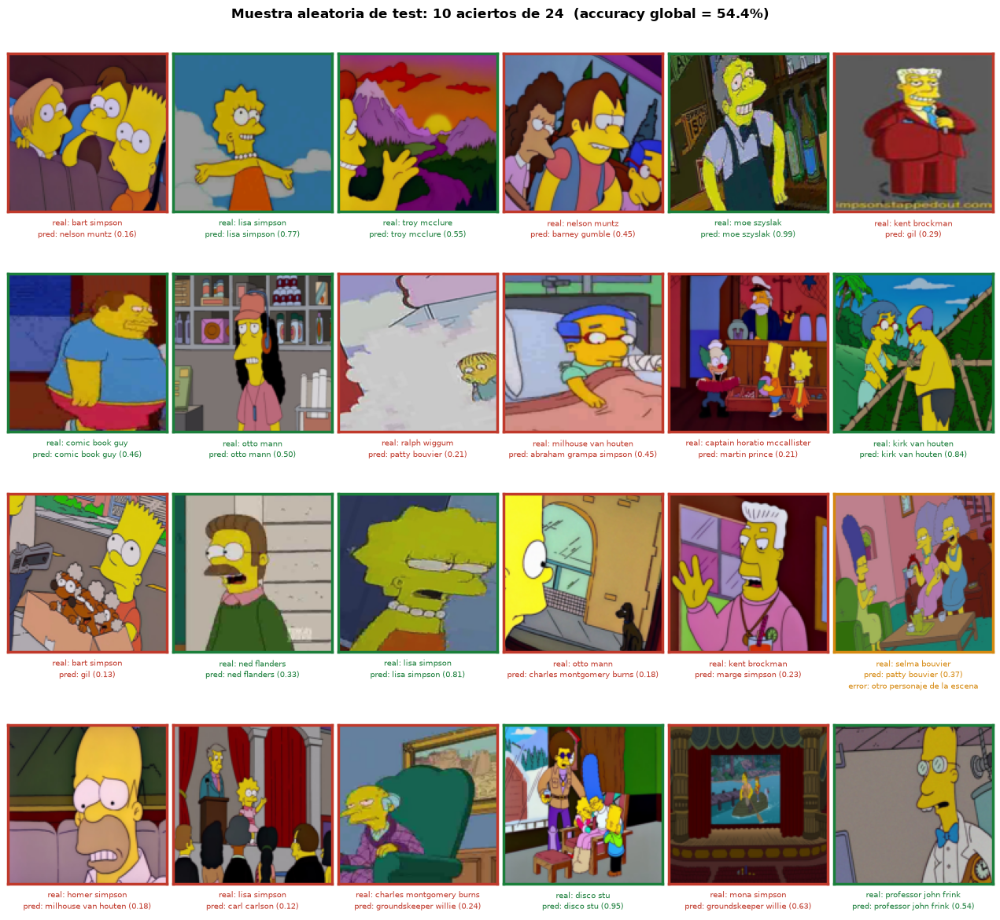

In [60]:
# Muestra aleatoria sin seleccionar: marco verde si acertó, ámbar si se equivocó nombrando a otro
# personaje de la escena y rojo en los demás errores
FILAS_MOSAICO, COLUMNAS_MOSAICO = 4, 6
generador_muestra = np.random.default_rng(SEMILLA)
muestra_aleatoria = generador_muestra.choice(
    len(y_test_idx), size=FILAS_MOSAICO * COLUMNAS_MOSAICO, replace=False
)

figura, ejes = plt.subplots(
    FILAS_MOSAICO,
    COLUMNAS_MOSAICO,
    figsize=(2.1 * COLUMNAS_MOSAICO, 2.9 * FILAS_MOSAICO),
    layout="constrained",
)

for eje, indice in zip(np.ravel(ejes), muestra_aleatoria):
    real = clases[y_test_idx[indice]].replace("_", " ")
    predicho = clases[predicciones_test[indice]].replace("_", " ")
    color = color_resultado(indice)

    eje.imshow(imagenes_test[indice])
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor(color)
        lado.set_linewidth(2.5)
    eje.set_xlabel(
        f"real: {real}\npred: {predicho} ({confianza_test[indice]:.2f})"
        + (f"\n{rotulo_escena(indice)}" if color == COLOR_ESCENA else ""),
        fontsize=7,
        color=color,
        labelpad=5,
        linespacing=1.5,
    )

aciertos_muestra = int(acierto_test[muestra_aleatoria].sum())
figura.suptitle(
    f"Muestra aleatoria de test: {aciertos_muestra} aciertos"
    f" de {len(muestra_aleatoria)}  (accuracy global = {accuracy_test:.1%})",
    fontsize=12,
    fontweight="bold",
)
plt.show()

#### Rendimiento por personaje, con una imagen de cada uno

La tabla de métricas por clase es precisa pero abstracta. Esta galería le pone cara: un ejemplo real de
cada uno de los 64 personajes, con el marco coloreado según el **recall** que el modelo alcanza en esa
clase —verde si la reconoce casi siempre, rojo si se le escapa casi siempre—. Se ve de un vistazo que
las clases en rojo son las minoritarias.

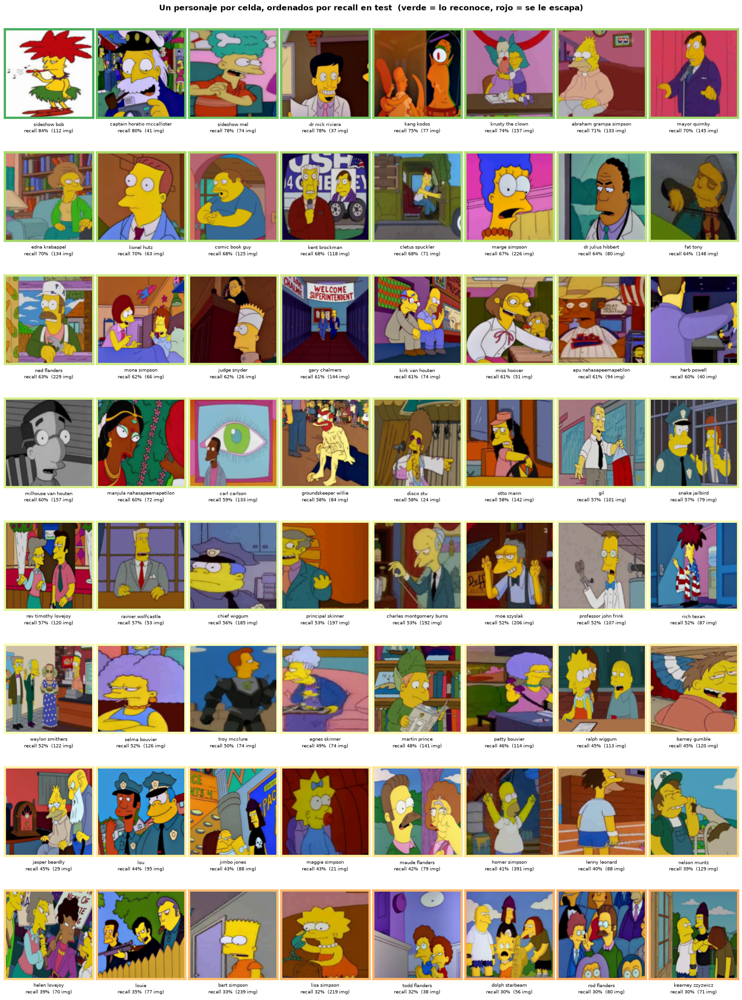

Recall medio sobre las 64 clases: 55.0%
Mejor: sideshow_bob (84%)   |   Peor: kearney_zzyzwicz (30%)


In [61]:
# Una imagen por personaje, con el marco coloreado según el recall de esa clase
recall_por_clase = np.diag(matriz_normalizada)
mapa_color = plt.get_cmap("RdYlGn")

FILAS_GALERIA = 8
COLUMNAS_GALERIA = int(np.ceil(NUMERO_CLASES / FILAS_GALERIA))

figura, ejes = plt.subplots(
    FILAS_GALERIA,
    COLUMNAS_GALERIA,
    figsize=(2.0 * COLUMNAS_GALERIA, 2.7 * FILAS_GALERIA),
    layout="constrained",
)
ejes = np.ravel(ejes)

# Se recorren las clases de mejor a peor recall, para que la degradación sea visible
orden_clases = np.argsort(-recall_por_clase)

for eje, clase in zip(ejes, orden_clases):
    indices_clase = np.flatnonzero(y_test_idx == clase)
    # Se prefiere una imagen acertada; si el modelo no acierta ninguna, se usa la primera disponible
    correctas = indices_clase[predicciones_test[indices_clase] == clase]
    indice = int(correctas[0]) if len(correctas) else int(indices_clase[0])

    eje.imshow(imagenes_test[indice])
    eje.set_xticks([])
    eje.set_yticks([])
    for lado in eje.spines.values():
        lado.set_edgecolor(mapa_color(recall_por_clase[clase]))
        lado.set_linewidth(3.5)
    eje.set_xlabel(
        f"{clases[clase].replace('_', ' ')}\nrecall {recall_por_clase[clase]:.0%}"
        f"  ({len(indices_clase)} img)",
        fontsize=7,
        labelpad=5,
        linespacing=1.5,
    )

for eje in ejes[NUMERO_CLASES:]:
    eje.axis("off")

figura.suptitle(
    "Un personaje por celda, ordenados por recall en test"
    "  (verde = lo reconoce, rojo = se le escapa)",
    fontsize=12,
    fontweight="bold",
)
plt.show()

print(f"Recall medio sobre las {NUMERO_CLASES} clases: {recall_por_clase.mean():.1%}")
print(
    f"Mejor: {clases[int(orden_clases[0])]} ({recall_por_clase[orden_clases[0]]:.0%})"
    f"   |   Peor: {clases[int(orden_clases[-1])]} ({recall_por_clase[orden_clases[-1]]:.0%})"
)

#### En qué se apoya el modelo

Hasta aquí se ha visto **qué** responde el modelo; este último análisis muestra **en qué se apoya** para
responderlo. Cómo se mide depende de la representación del modelo elegido:

- **Con píxeles**, se calcula el gradiente de la probabilidad de la clase predicha respecto de cada píxel
  de entrada: donde el gradiente es grande, un cambio pequeño en ese píxel alteraría mucho la decisión.
  El resultado es un *mapa de saliencia* dibujado sobre la imagen.
- **Con descriptores**, un gradiente por intervalo de histograma no se puede dibujar sobre la imagen. En
  su lugar se mide la **importancia por permutación de cada bloque**: se barajan entre las imágenes de
  test las columnas de un bloque (por ejemplo, todo el color HSV) y se observa cuánto cae el F1 macro. Si
  un bloque no aporta nada, barajarlo no cambia el resultado; si el modelo depende de él, el F1 se hunde.

,bloque,valores,caida_f1_macro,desviacion
0,color_hsv,170,0.4697,0.0009
1,color_lab,200,0.4296,0.0043


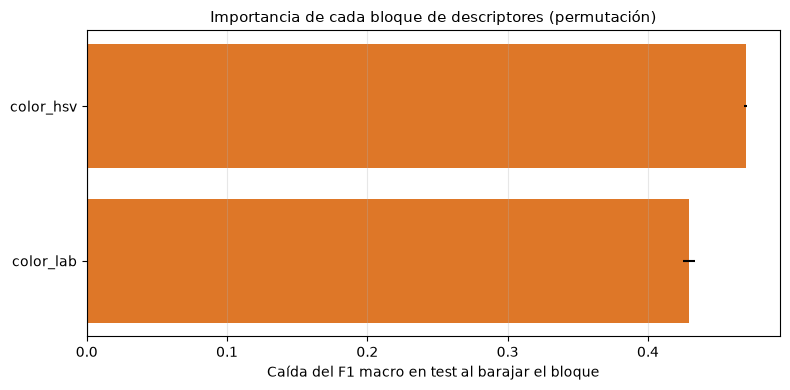

F1 macro de referencia en test: 0.5507
El bloque del que mas depende el modelo es color_hsv: barajarlo baja el F1 macro en 0.4697.


In [62]:
# Con píxeles: mapa de saliencia. Con descriptores: importancia por permutación
# de cada bloque, porque un gradiente por intervalo de histograma no se dibuja sobre la imagen.
if representacion_final == "pixeles":
    # Mapa de saliencia: cuánto cambia la probabilidad de la clase predicha al perturbar cada píxel
    indices_saliencia = list(demo_aciertos[np.argsort(-confianza_test[demo_aciertos])][:2]) + list(
        demo_errores[np.argsort(-confianza_test[demo_errores])][:2]
    )

    # El gradiente se toma respecto de la ENTRADA, no de los pesos: se pide a PyTorch
    # que rastree la entrada y se propaga hacia atras la probabilidad de la clase predicha.
    # Se parte del uint8 original y se pasa a float porque el gradiente necesita un tipo continuo;
    # la capa Rescaling del modelo divide despues por 255, asi que la escala es la de siempre.
    entrada_saliencia = X_test[indices_saliencia].float().requires_grad_(True)
    clases_predichas = torch.as_tensor(
        predicciones_test[indices_saliencia], dtype=torch.long, device=entrada_saliencia.device
    )

    salidas = modelo_final(entrada_saliencia, training=False)
    # Probabilidad que el modelo asignó a la clase que efectivamente predijo
    puntajes = salidas.gather(1, clases_predichas.unsqueeze(1)).sum()
    puntajes.backward()

    gradientes = entrada_saliencia.grad.detach().cpu().numpy()
    # Valor absoluto y resumen de los tres canales RGB en un único mapa por imagen
    saliencia = np.abs(gradientes).reshape(-1, ALTO_OBJETIVO, ANCHO_OBJETIVO, 3).max(axis=-1)


    def suavizar(mapas, radio=2):
        """Promedia cada píxel con sus vecinos. El gradiente píxel a píxel es muy ruidoso;
        suavizarlo deja ver si la importancia forma regiones o está repartida por todo el encuadre."""
        acumulado = np.zeros_like(mapas)
        for desplazamiento_y in range(-radio, radio + 1):
            for desplazamiento_x in range(-radio, radio + 1):
                acumulado += np.roll(
                    np.roll(mapas, desplazamiento_y, axis=1), desplazamiento_x, axis=2
                )
        return acumulado / (2 * radio + 1) ** 2


    saliencia_suave = suavizar(saliencia)

    figura, ejes = plt.subplots(
        2,
        len(indices_saliencia),
        figsize=(2.4 * len(indices_saliencia), 5.8),
        layout="constrained",
    )

    for columna, indice in enumerate(indices_saliencia):
        real = clases[y_test_idx[indice]].replace("_", " ")
        predicho = clases[predicciones_test[indice]].replace("_", " ")
        acierto = y_test_idx[indice] == predicciones_test[indice]
        color = "#1b7f3b" if acierto else "#c0392b"

        ejes[0, columna].imshow(imagenes_test[indice])
        ejes[1, columna].imshow(saliencia_suave[columna], cmap="inferno")

        ejes[0, columna].set_xlabel(
            f"real: {real}\npred: {predicho}",
            fontsize=8,
            color=color,
            labelpad=6,
            linespacing=1.5,
        )

        for eje in (ejes[0, columna], ejes[1, columna]):
            eje.set_xticks([])
            eje.set_yticks([])
            for lado in eje.spines.values():
                lado.set_edgecolor(color)
                lado.set_linewidth(2)

    ejes[0, 0].set_ylabel("Imagen", fontsize=10, fontweight="bold", labelpad=8)
    ejes[1, 0].set_ylabel("Saliencia", fontsize=10, fontweight="bold", labelpad=8)
    figura.suptitle(
        "Zonas que determinan la decisión (dos aciertos y dos errores confiados)",
        fontsize=12,
        fontweight="bold",
    )
    plt.show()

    # Que parte de la influencia total se concentra en el 10 % de píxeles más determinantes.
    # Si el modelo mirara una región concreta, ese 10 % acumularía la mayor parte de la influencia;
    # si la reparte por todo el encuadre, el valor se acerca al 10 % de un reparto uniforme.
    plano = saliencia.reshape(len(indices_saliencia), -1)
    umbral = np.quantile(plano, 0.90, axis=1, keepdims=True)
    concentracion = (plano * (plano >= umbral)).sum(axis=1) / plano.sum(axis=1)

    tabla_saliencia = pd.DataFrame(
        {
            "imagen": [f"{clases[y_test_idx[i]]} -> {clases[predicciones_test[i]]}" for i in indices_saliencia],
            "acierto": [bool(y_test_idx[i] == predicciones_test[i]) for i in indices_saliencia],
            "influencia_en_el_10%_top": [round(float(v), 3) for v in concentracion],
        }
    )
    display(tabla_saliencia)

    print(f"Reparto uniforme de referencia: 0.100   |   observado: {concentracion.mean():.3f} de media")
else:
    # Importancia por permutación de cada bloque de descriptores, medida en test: se
    # barajan entre imágenes las columnas de un bloque y se mide cuánto cae el F1 macro
    REPETICIONES_PERMUTACION = 3
    generador_permutacion = np.random.default_rng(SEMILLA)
    entrada_test = particion(representacion_final)["test"]
    f1_referencia = f1_score(y_test_idx, predicciones_test, average="macro")

    filas_importancia = []
    inicio_columna = 0
    for bloque in BLOQUES_POR_REPRESENTACION[representacion_final]:
        tamano = TAMANOS_BLOQUES[bloque]
        columnas = slice(inicio_columna, inicio_columna + tamano)
        inicio_columna += tamano
        caidas = []
        for _ in range(REPETICIONES_PERMUTACION):
            permutada = entrada_test.copy()
            permutada[:, columnas] = entrada_test[generador_permutacion.permutation(len(entrada_test)), columnas]
            predicciones_permutadas = modelo_final.predict(
                a_gpu(permutada), batch_size=256, verbose=0
            ).argmax(axis=1)
            caidas.append(f1_referencia - f1_score(y_test_idx, predicciones_permutadas, average="macro"))
        filas_importancia.append(
            {
                "bloque": bloque,
                "valores": tamano,
                "caida_f1_macro": round(float(np.mean(caidas)), 4),
                "desviacion": round(float(np.std(caidas)), 4),
            }
        )

    importancia_bloques = (
        pd.DataFrame(filas_importancia).sort_values("caida_f1_macro", ascending=False).reset_index(drop=True)
    )
    display(importancia_bloques)

    figura, eje = plt.subplots(figsize=(8, 4))
    orden_bloques = importancia_bloques.iloc[::-1]
    eje.barh(
        orden_bloques["bloque"],
        orden_bloques["caida_f1_macro"],
        xerr=orden_bloques["desviacion"],
        color="#d95f02",
        alpha=0.85,
    )
    eje.axvline(0, color="gray", linewidth=0.8)
    eje.set_xlabel("Caída del F1 macro en test al barajar el bloque")
    eje.set_title("Importancia de cada bloque de descriptores (permutación)", fontsize=11)
    eje.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()

    mas_importante = importancia_bloques.iloc[0]
    print(f"F1 macro de referencia en test: {f1_referencia:.4f}")
    print(
        f"El bloque del que mas depende el modelo es {mas_importante['bloque']}: barajarlo baja el"
        f" F1 macro en {mas_importante['caida_f1_macro']:.4f}."
    )

**Lectura de la importancia por bloques.** El modelo final depende por completo del color, y de los dos
espacios a la vez. Barajar los histogramas HSV entre las imágenes de test baja su F1 macro en 0,47, y
barajar los Lab, en 0,43: el F1 cae de 0,55 a 0,08 y a 0,12, aunque el otro bloque siga intacto. Los dos espacios describen el mismo color de dos formas —HSV separa el
tono del brillo; Lab se parece más a la percepción humana— y la red los combina en lugar de usar uno como
respaldo del otro.

La consecuencia práctica es que el modelo reconoce **paletas**, no personajes. Funciona cuando el
personaje tiene una combinación de colores propia y ocupa buena parte del encuadre, y falla cuando dos
personajes comparten paleta (Patty y Selma, Bart y Lisa) o cuando el fondo domina la imagen, porque los
histogramas cuentan los píxeles del fondo igual que los del personaje. Las variantes alteradas, que
cambian el tono y la saturación, son la prueba más dura para esa dependencia, y es donde más pierde: 8,7 puntos
frente a las originales (sección «Originales, parecidas y alteradas en test»). Aun así, lo que aprendió de
las alteradas de entrenamiento le da algo de robustez: sin ellas (A1), el F1 macro de validación cae 2,7
puntos.

### Ejemplos correctamente clasificados

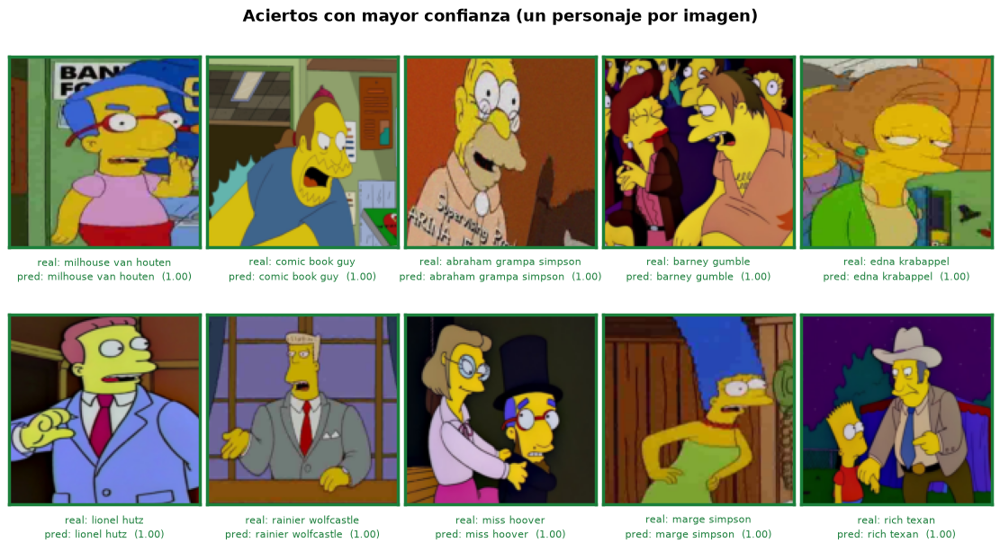

Aciertos totales: 3841 de 7058 (54.4%)
Confianza media en los aciertos: 0.696


In [63]:
def mostrar_ejemplos(indices, titulo, filas=2, columnas=5):
    """Dibuja una rejilla de imágenes de test con su etiqueta real, la predicha y la confianza."""
    indices = list(indices)
    figura, ejes = plt.subplots(
        filas,
        columnas,
        figsize=(2.2 * columnas, 3.0 * filas),
        layout="constrained",
    )
    ejes = np.ravel(ejes)

    for eje, indice in zip(ejes, indices):
        real = clases[y_test_idx[indice]].replace("_", " ")
        predicho = clases[predicciones_test[indice]].replace("_", " ")
        color = color_resultado(indice)

        eje.imshow(imagenes_test[indice])
        eje.set_xticks([])
        eje.set_yticks([])
        # Marco de color: verde si acertó, ámbar si nombró a otro personaje de la escena, rojo si falló
        for lado in eje.spines.values():
            lado.set_edgecolor(color)
            lado.set_linewidth(2.5)

        # Las etiquetas van debajo de la imagen para que no invadan la fila superior
        eje.set_xlabel(
            f"real: {real}\npred: {predicho}  ({confianza_test[indice]:.2f})"
            + (f"\n{rotulo_escena(indice)}" if color == COLOR_ESCENA else ""),
            fontsize=8,
            color=color,
            labelpad=6,
            linespacing=1.5,
        )

    for eje in ejes[len(indices):]:
        eje.axis("off")

    figura.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.show()


aciertos = np.flatnonzero(acierto_test)
# Aciertos con mayor confianza, sin repetir personaje, para ver variedad de clases
aciertos_ordenados = aciertos[np.argsort(-confianza_test[aciertos])]
vistos = set()
seleccion_aciertos = []
for indice in aciertos_ordenados:
    personaje = y_test_eval[indice]
    if personaje not in vistos:
        vistos.add(personaje)
        seleccion_aciertos.append(indice)
    if len(seleccion_aciertos) == 10:
        break

mostrar_ejemplos(seleccion_aciertos, "Aciertos con mayor confianza (un personaje por imagen)")

print(f"Aciertos totales: {len(aciertos)} de {len(y_test_idx)} ({len(aciertos) / len(y_test_idx):.1%})")
print(f"Confianza media en los aciertos: {confianza_test[aciertos].mean():.3f}")

**Qué está aprovechando el modelo.** Los aciertos más seguros tienen un patrón claro: el personaje ocupa
buena parte del encuadre, se ve de frente o de medio cuerpo y su paleta está completa. Es lo que se
espera de un modelo que solo recibe histogramas de color: no reconoce la forma de un peinado, sino la
proporción de cada color en la imagen y en cada cuadrante. Por eso acierta en los planos canónicos de un
personaje y pierde seguridad en cuanto el encuadre mezcla su paleta con la de otro personaje o con un fondo
grande.

### Ejemplos mal clasificados

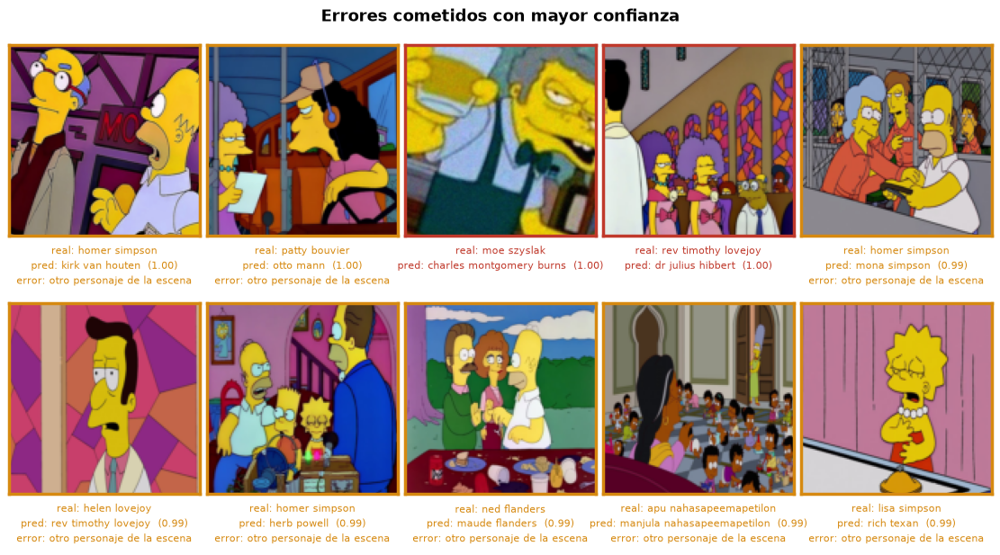

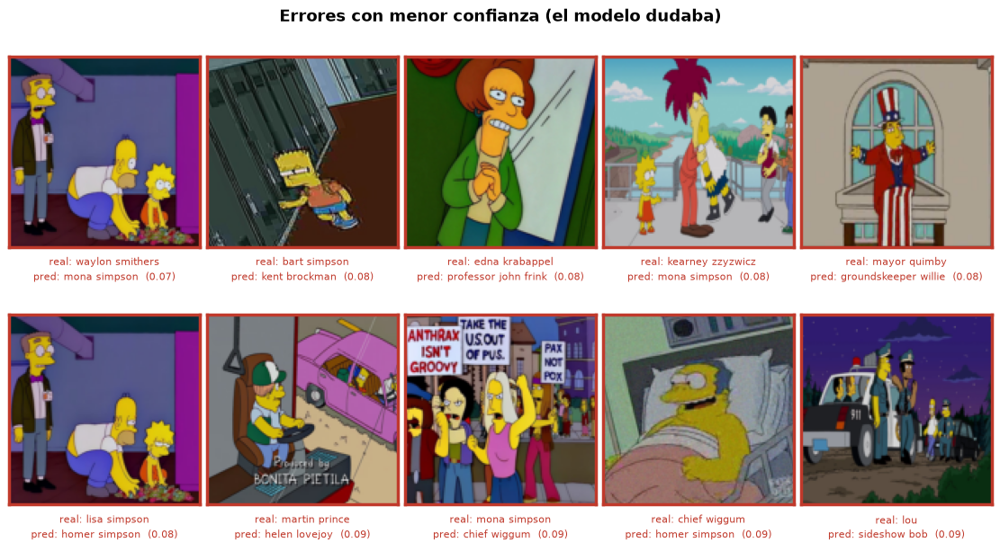

,Indicador,Valor,Detalle
0,Errores totales,3217.000,45.6% del test
1,Confianza media en aciertos,0.696,
2,Confianza media en errores,0.402,
3,Errores con confianza > 0.90,124.000,3.9% de los errores
4,Errores que nombran a otro personaje de la escena,619.000,19.2% de los errores (referencia)


In [64]:
# Errores según el criterio de acierto: el modelo no nombró al personaje de la carpeta
errores = np.flatnonzero(~acierto_test)

# Los errores más graves: equivocaciones cometidas con la mayor confianza
errores_confiados = errores[np.argsort(-confianza_test[errores])][:50]
mostrar_ejemplos(errores_confiados, "Errores cometidos con mayor confianza")

# Errores con baja confianza: el modelo tampoco sabía
errores_dudosos = errores[np.argsort(confianza_test[errores])][:10]
mostrar_ejemplos(errores_dudosos, "Errores con menor confianza (el modelo dudaba)")

resumen_errores = pd.DataFrame(
    [
        ("Errores totales", len(errores), f"{len(errores) / len(y_test_idx):.1%} del test"),
        ("Confianza media en aciertos", round(float(confianza_test[aciertos].mean()), 3), ""),
        ("Confianza media en errores", round(float(confianza_test[errores].mean()), 3), ""),
        (
            "Errores con confianza > 0.90",
            int((confianza_test[errores] > 0.90).sum()),
            f"{(confianza_test[errores] > 0.90).mean():.1%} de los errores",
        ),
        (
            "Errores que nombran a otro personaje de la escena",
            int(acierto_por_escena[errores].sum()),
            f"{acierto_por_escena[errores].mean():.1%} de los errores (referencia)" if len(errores) else "",
        ),
    ],
    columns=["Indicador", "Valor", "Detalle"],
)
display(resumen_errores)

**Dos tipos de error muy distintos.** La confianza separa bien aciertos de errores. Cuando el modelo duda suele tener motivos, y esa señal sirve en el escenario de uso:
las predicciones con confianza baja son las que conviene mandar a revisión humana.

Los **errores con confianza alta** son pocos —261 con confianza mayor que 0,80 en la corrida del 09-11-2026,
el 3,7 % del test— y responden a tres causas:

- **El personaje predicho sí está en la imagen.** Con el criterio de la carpeta cuenta como error; la escena
  y las gemelas recuperan una parte en la accuracy por escena, pero no todos: un personaje que aparece sin
  un fotograma cercano ni una gemela no se detecta, así que también la accuracy por escena es una cota
  inferior.
- **Personajes de paleta casi idéntica**, como las gemelas Patty y Selma.
- **Un disfraz o una iluminación que cambia la paleta** y la acerca a la de otro personaje.

Los errores con baja confianza, en cambio, son imágenes difíciles de verdad: planos generales con el
personaje pequeño, escenas con varios personajes a la vez o encuadres donde casi no se ve a nadie, como un
estacionamiento lleno de autos.

### Confusiones más frecuentes y posibles causas

,real,predicho,casos,% de la clase real,n_train_real,n_train_predicho
0,lisa_simpson,bart_simpson,41,18.7,1557,1696
1,patty_bouvier,selma_bouvier,35,30.7,809,860
2,selma_bouvier,patty_bouvier,33,26.2,860,809
3,chief_wiggum,lou,32,17.3,1291,659
4,lou,chief_wiggum,28,29.5,659,1291
5,bart_simpson,lisa_simpson,21,8.8,1696,1557
6,louie,fat_tony,21,27.3,500,1002
7,lenny_leonard,carl_carlson,20,22.7,655,884
8,lisa_simpson,homer_simpson,20,9.1,1557,2725
9,moe_szyslak,homer_simpson,19,9.2,1477,2725


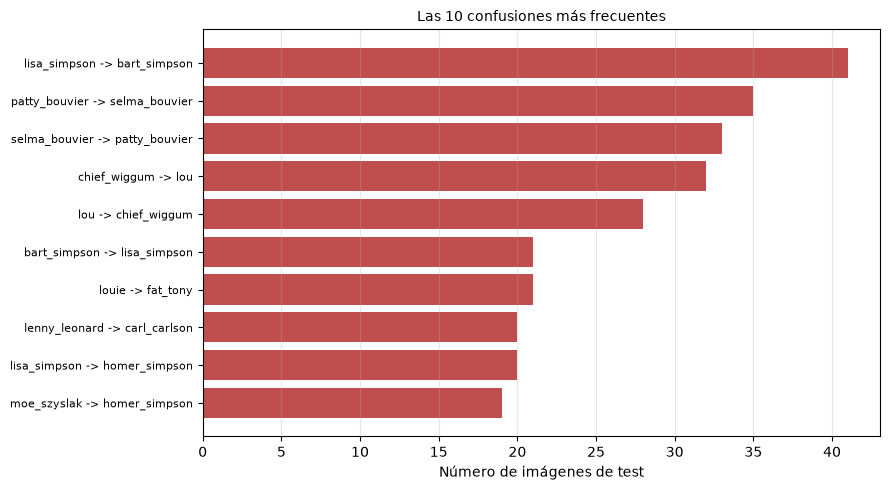

Clases que más absorben errores de otras (el modelo las usa como respuesta por defecto):
  bart_simpson: 60 imagenes de otras clases predichas como esta
  homer_simpson: 39 imagenes de otras clases predichas como esta
  selma_bouvier: 35 imagenes de otras clases predichas como esta
  patty_bouvier: 33 imagenes de otras clases predichas como esta
  lou: 32 imagenes de otras clases predichas como esta


In [65]:
# Pares (clase real, clase predicha) más frecuentes, excluyendo la diagonal
pares = []
for real in range(NUMERO_CLASES):
    for predicho in range(NUMERO_CLASES):
        if real != predicho and matriz[real, predicho] > 0:
            pares.append(
                {
                    "real": clases[real],
                    "predicho": clases[predicho],
                    "casos": int(matriz[real, predicho]),
                    "% de la clase real": round(float(matriz_normalizada[real, predicho]) * 100, 1),
                    "n_train_real": int(conteos_train[real]),
                    "n_train_predicho": int(conteos_train[predicho]),
                }
            )

confusiones = pd.DataFrame(pares).sort_values("casos", ascending=False, ignore_index=True).head(15)
display(confusiones)

figura, eje = plt.subplots(figsize=(9, 5))
etiquetas_pares = confusiones.head(10).apply(
    lambda fila: f"{fila['real']} -> {fila['predicho']}", axis=1
)
eje.barh(etiquetas_pares[::-1], confusiones.head(10)["casos"][::-1], color="firebrick", alpha=0.8)
eje.set_xlabel("Número de imágenes de test")
eje.set_title("Las 10 confusiones más frecuentes", fontsize=10)
eje.tick_params(axis="y", labelsize=8)
eje.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

destino_frecuente = confusiones.groupby("predicho")["casos"].sum().sort_values(ascending=False)
print("Clases que más absorben errores de otras (el modelo las usa como respuesta por defecto):")
for personaje, casos in destino_frecuente.head(5).items():
    print(f"  {personaje}: {casos} imagenes de otras clases predichas como esta")

**Causas detrás de las confusiones.** Los pares que encabezan la tabla
responden a causas identificables:

- **Paleta compartida dentro de la familia.** Lisa y Bart se confunden entre sí 62 veces, casi tanto
  como Patty y Selma (68), y los dos con Homero: los tres tienen la misma piel amarilla, y los
  histogramas de color, que no ven la forma del pelo, apenas los distinguen.
- **Personajes dibujados casi iguales.** Patty y Selma son gemelas, con el mismo diseño y colores muy
  parecidos: una parte importante de cada una se predice como la otra.
- **La familia como respuesta por defecto.** Homero, Bart y Lisa son el destino más frecuente de los
  errores de otras clases. No es efecto del desbalance —los pesos por clase reducen el de Homero a la mitad
  del promedio—, sino de que su paleta amarilla es la más genérica de la serie.
- **Escenarios compartidos.** Moe se confunde con Homero y con Barney, que coinciden con él en la taberna.
  Como los histogramas cuentan el fondo igual que al personaje, es probable que el escenario pese en esas
  confusiones.
- **Escenas con varios personajes.** Wiggum y Lou (60 casos entre los dos sentidos), Louie y Fat Tony
  o Lenny y Carl salen juntos a menudo y por eso están en la tabla: el modelo ve la imagen completa y puede
  nombrar al acompañante, que con el criterio de la carpeta es un error (sección siguiente).

### Escenas con varios personajes: errores que nombran a otro personaje (referencia)

Con el criterio de la carpeta, nombrar a otro personaje es un error aunque ese personaje esté en la escena.
Esta sección separa esos errores de los demás, como referencia: la imagen completa puede mostrar a varios
personajes, y la escena (±3 s) o las gemelas dicen si el personaje que nombró el modelo estaba en el fotograma.
La accuracy por escena suma estos casos a los aciertos.

La escena se estima con una ventana de tiempo y no con una anotación manual: un corte de cámara dentro de la
ventana puede dar por presente a alguien que no sale en el encuadre. Las gemelas son más seguras, porque son la
misma imagen guardada en dos carpetas. La galería permite comprobarlo a ojo.

,Indicador,Valor,Detalle
0,Imágenes de test,7058.0000,
1,con otro personaje presente (escena o gemela),1674.0000,23.7% del test
2,Errores: no nombra al personaje de la carpeta,3217.0000,45.6% del test
3,que nombran a otro personaje presente,619.0000,19.2% de los errores
4,Accuracy (personaje de la carpeta),0.5442,
5,Accuracy por escena (referencia),0.6319,+0.0877
6,Accuracy en imágenes con otro personaje presente,0.3632,
7,Accuracy en el resto del test,0.6005,


,carpeta,predicho,casos
0,chief_wiggum,lou,28
1,selma_bouvier,patty_bouvier,23
2,kearney_zzyzwicz,jimbo_jones,16
3,lou,chief_wiggum,16
4,louie,fat_tony,16
5,patty_bouvier,selma_bouvier,16
6,apu_nahasapeemapetilon,manjula_nahasapeemapetilon,12
7,ned_flanders,rod_flanders,12
8,dolph_starbeam,kearney_zzyzwicz,11
9,lenny_leonard,carl_carlson,11


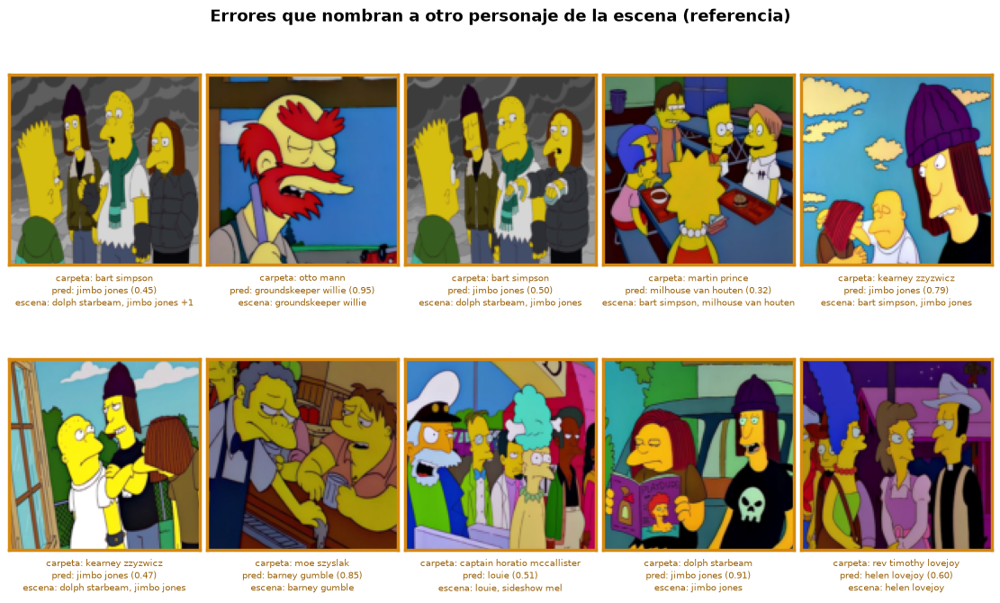

In [66]:
# Errores que nombran a otro personaje de la escena (referencia): el criterio de acierto ya se aplicó en la
# evaluación (acierto_estricto); aquí solo se separan esos errores de los demás
nombres_predichos = [clases[indice] for indice in predicciones_test]
con_escena_test = np.array([bool(presentes) for presentes in acompanantes_test])
errores_escena = np.flatnonzero(acierto_por_escena)
distintos_de_carpeta = int((~acierto_estricto).sum())


def proporcion(valores):
    return round(float(valores.mean()), 4) if len(valores) else np.nan


resumen_escena_test = pd.DataFrame(
    [
        ("Imágenes de test", len(y_test_idx), ""),
        (
            "   con otro personaje presente (escena o gemela)",
            int(con_escena_test.sum()),
            f"{con_escena_test.mean():.1%} del test",
        ),
        (
            "Errores: no nombra al personaje de la carpeta",
            distintos_de_carpeta,
            f"{distintos_de_carpeta / len(y_test_idx):.1%} del test",
        ),
        (
            "   que nombran a otro personaje presente",
            len(errores_escena),
            f"{len(errores_escena) / max(distintos_de_carpeta, 1):.1%} de los errores",
        ),
        ("Accuracy (personaje de la carpeta)", round(accuracy_test, 4), ""),
        (
            "Accuracy por escena (referencia)",
            round(accuracy_por_escena_test, 4),
            f"{accuracy_por_escena_test - accuracy_test:+.4f}",
        ),
        ("Accuracy en imágenes con otro personaje presente", proporcion(acierto_estricto[con_escena_test]), ""),
        ("Accuracy en el resto del test", proporcion(acierto_estricto[~con_escena_test]), ""),
    ],
    columns=["Indicador", "Valor", "Detalle"],
)
display(resumen_escena_test)

pares_en_escena = (
    pd.DataFrame(
        {
            "carpeta": [clases[y_test_idx[indice]] for indice in errores_escena],
            "predicho": [nombres_predichos[indice] for indice in errores_escena],
        }
    )
    .value_counts()
    .head(10)
    .reset_index(name="casos")
)
display(pares_en_escena)

if len(errores_escena):
    generador = np.random.default_rng(SEMILLA)
    muestra_escena = generador.choice(errores_escena, size=min(10, len(errores_escena)), replace=False)
    figura, ejes = plt.subplots(2, 5, figsize=(11, 6.6), layout="constrained")
    ejes = np.ravel(ejes)
    for eje, indice in zip(ejes, muestra_escena):
        eje.imshow(imagenes_test[indice])
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(COLOR_ESCENA)
            lado.set_linewidth(2.5)
        escena_visible = sorted(acompanantes_test[indice])
        resto = f" +{len(escena_visible) - 2}" if len(escena_visible) > 2 else ""
        eje.set_xlabel(
            f"carpeta: {clases[y_test_idx[indice]].replace('_', ' ')}\n"
            f"pred: {nombres_predichos[indice].replace('_', ' ')} ({confianza_test[indice]:.2f})\n"
            f"escena: {', '.join(n.replace('_', ' ') for n in escena_visible[:2])}{resto}",
            fontsize=7,
            color="#9c640c",
            labelpad=6,
            linespacing=1.4,
        )
    for eje in ejes[len(muestra_escena):]:
        eje.axis("off")
    figura.suptitle(
        "Errores que nombran a otro personaje de la escena (referencia)", fontsize=13, fontweight="bold"
    )
    plt.show()

**Lectura.** Con la imagen completa, una parte de los errores son el otro personaje de la escena: el fotograma
muestra a varios y la etiqueta solo nombra a uno. La tabla dice cuántos son; suelen ser personajes que salen
pegados en el mismo plano —Patty y Selma, Lou y Wiggum—. Es lo que resuelve el script de cajas después del
entrenamiento, al nombrar a cada personaje en su propia caja.


### Originales, parecidas y alteradas en test

El test tiene las mismas condiciones que el entrenamiento: originales sin transformar, versiones filtradas
de las imágenes casi idénticas a otra (parecidas) y variantes alteradas de un cuarto de las originales.
Esta tabla mide el modelo por separado en cada tipo:

- **Originales.** Las imágenes tal como están en el dataset. Es la fila comparable con las corridas
  anteriores, cuyo test no tenía alteradas.
- **Parecidas.** Antes del filtro, las imágenes de test con una gemela casi idéntica en entrenamiento se
  acertaban en torno al 95 % de las veces, frente a un 53 % del resto. Si las versiones filtradas se siguen
  acertando mucho más que las originales, el modelo reconoce la escena a pesar del filtro.
- **Alteradas.** Miden si el modelo resiste el giro, el cambio de color y el filtro de textura con los
  que aprendió.

In [67]:
es_alterada_test = datos_test["alterada"].to_numpy()
es_parecida_test = datos_test["parecida"].to_numpy()
es_original_test = ~es_alterada_test & ~es_parecida_test

resumen_tipos_test = pd.DataFrame(
    [
        (
            nombre,
            int(mascara.sum()),
            proporcion(acierto_test[mascara]),
            proporcion((acierto_test | acierto_por_escena)[mascara]),
            proporcion(top3_por_imagen[mascara]),
        )
        for nombre, mascara in (
            ("Original, sin transformar", es_original_test),
            ("Parecida: versión filtrada de una casi idéntica a otra", es_parecida_test),
            ("Alterada: variante de una original de test", es_alterada_test),
        )
    ],
    columns=["Imágenes de test", "n", "accuracy", "accuracy por escena (referencia)", "top-3"],
)
display(resumen_tipos_test)
accuracy_originales_test, accuracy_parecidas_test, accuracy_alteradas_test = resumen_tipos_test["accuracy"]

,Imágenes de test,n,accuracy,accuracy por escena (referencia),top-3
0,"Original, sin transformar",4803,0.5536,0.6467,0.7412
1,Parecida: versión filtrada de una casi idéntic...,865,0.6162,0.7075,0.8173
2,Alterada: variante de una original de test,1390,0.4669,0.5338,0.6662


**Lectura.** En la corrida del 09-11-2026, las parecidas se aciertan más que
las originales, y las alteradas, bastante menos.

- **Alteradas: 8,7 puntos por debajo de las originales.** El giro, el cambio de color y el filtro de
  textura cuestan caro porque el modelo depende del color: un cambio de tono o de saturación le cambia
  justo lo que mira. Aun así, haber visto alteradas al entrenar le da algo de robustez (sin ellas, en A1,
  el F1 macro de validación cae 2,7 puntos).
- **Parecidas: 6,3 puntos por encima de las originales.** Antes del filtro, la diferencia era de
  unos 40 puntos (95 % frente a 53 %): el filtro la redujo mucho, pero no la eliminó. La versión filtrada
  cambia la miniatura, no la escena, y lo más probable es que, cuando otra imagen del mismo grupo quedó en
  entrenamiento, el modelo reconozca la paleta de esa toma. Como las parecidas son el 12 % del test, esa
  ventaja sube la accuracy global en menos de 1 punto.

La fila de **originales** es, por eso, la medida más limpia del modelo. Una partición que mantenga cada
grupo de imágenes casi idénticas en un solo conjunto eliminaría la ventaja (ver «Propuestas de mejora para
futuras iteraciones»).

### Fortalezas y debilidades del modelo

In [68]:
sintesis = pd.DataFrame(
    [
        (
            "Fortaleza",
            "Supera con holgura los baselines",
            f"accuracy {accuracy_test:.3f} frente a {baseline_azar:.3f} (azar) y {baseline_mayoritaria:.3f} (clase mayoritaria)",
        ),
        (
            "Fortaleza",
            "Buena señal en el top-3",
            f"top-3 accuracy {top3_test:.3f}: la clase correcta suele estar entre las candidatas",
        ),
        (
            "Fortaleza",
            "Reconoce con solidez a los personajes principales",
            f"{len(clases_fuertes)} clases con F1 >= 0.60",
        ),
        (
            "Fortaleza",
            "La confianza es informativa",
            f"confianza media {confianza_test[aciertos].mean():.2f} en aciertos y "
            f"{confianza_test[errores].mean():.2f} en errores",
        ),
        (
            "Debilidad",
            "Desempeño muy desigual entre clases",
            f"brecha accuracy - F1 macro = {brecha_metricas:.3f}; {len(clases_debiles)} clases con F1 < 0.30",
        ),
        (
            "Debilidad",
            "Depende del volumen de datos por clase",
            f"correlacion entre n_train y F1 por clase = {correlacion:.2f}",
        ),
        (
            "Debilidad",
            "Sin invarianza a traslación ni a escala"
            if representacion_final == "pixeles"
            else "Descriptores elegidos a mano",
            "el mismo personaje en otra posición del encuadre es otro vector de entrada"
            if representacion_final == "pixeles"
            else "la red combina histogramas de color y textura fijos; no aprende sus propias características",
        ),
        (
            "Debilidad",
            "Sensible al fondo",
            "los píxeles de fondo entran al modelo con el mismo peso que los del personaje"
            if representacion_final == "pixeles"
            else "los histogramas se calculan sobre la imagen completa: el fondo y los demás personajes también cuentan",
        ),
        (
            "Debilidad",
            "Costo en parámetros",
            f"{modelo_final.count_params():,} parametros para {len(X_train):,} imagenes de entrenamiento",
        ),
    ],
    columns=["Tipo", "Aspecto", "Evidencia"],
)

display(sintesis)

,Tipo,Aspecto,Evidencia
0,Fortaleza,Supera con holgura los baselines,accuracy 0.544 frente a 0.016 (azar) y 0.055 (...
1,Fortaleza,Buena señal en el top-3,top-3 accuracy 0.736: la clase correcta suele ...
2,Fortaleza,Reconoce con solidez a los personajes principales,27 clases con F1 >= 0.60
3,Fortaleza,La confianza es informativa,confianza media 0.70 en aciertos y 0.40 en err...
4,Debilidad,Desempeño muy desigual entre clases,brecha accuracy - F1 macro = -0.006; 1 clases ...
5,Debilidad,Depende del volumen de datos por clase,correlacion entre n_train y F1 por clase = -0.12
6,Debilidad,Descriptores elegidos a mano,la red combina histogramas de color y textura ...
7,Debilidad,Sensible al fondo,los histogramas se calculan sobre la imagen co...
8,Debilidad,Costo en parámetros,"1,059,648 parametros para 49,625 imagenes de e..."


**Síntesis.** El MLP demuestra que el problema tiene señal aprendible: su accuracy es casi diez veces
la de la clase mayoritaria, cumple los cuatro KPIs de calidad y reparte el desempeño de forma bastante pareja entre
personajes grandes y pequeños. Su límite no está en los hiperparámetros —ni más capas, ni otra tasa de
aprendizaje, ni otro tamaño de batch, ni otro esquema de pesos lo mejoran en más de 2 o 3 puntos—, sino en
la representación de la entrada. Los histogramas de color le permiten reconocer paletas sin depender de
dónde está el personaje, pero no formas: por eso falla entre personajes que comparten colores y en las
imágenes donde el fondo domina. Ir más lejos requiere que la red aprenda sus propias características a
partir de la forma, que es lo que hacen las redes convolucionales.

## Limitaciones del MLP en imágenes y propuestas de mejora

### Limitaciones estructurales del MLP

> **Con descriptores.** Las limitaciones que siguen se escribieron para el MLP sobre píxeles aplanados,
> que en este notebook es el experimento R1. Los descriptores atenúan algunas: un histograma no cambia si
> el personaje se desplaza dentro de su zona (2), y la primera capa del modelo final, que en la
> corrida del 09-11-2026 usa solo los 370 histogramas de color, es unas 66 veces menor que con los
> píxeles a 128 x 128 (3). Pero no las eliminan, y suman una propia: los descriptores se eligen a mano, de
> modo que la red no aprende a extraer los suyos; el fondo y los demás personajes del encuadre cuentan en los histogramas igual que el personaje (5); y al
> quedarse solo con el color, el modelo no ve la forma, por eso confunde a personajes de paleta parecida,
> como Bart y Lisa o Patty y Selma.

Las limitaciones que siguen no son defectos de esta implementación en particular, sino consecuencias de
usar una red totalmente conectada sobre imágenes. Ningún ajuste de hiperparámetros las resuelve.

**1. Pérdida de la información espacial.** El aplanado convierte la imagen en una lista de 49 152
números en la que se olvida qué píxel estaba junto a cuál. Para la red, dos píxeles vecinos y dos píxeles
en esquinas opuestas son igual de "cercanos": ninguno. Si se permutaran todas las columnas de `X` con una
permutación fija, el modelo aprendería exactamente igual de bien —algo que sería impensable para un ojo
humano y que revela cuánta estructura se está descartando.

**2. Ausencia de invarianza a la traslación y a la escala.** Cada peso de la primera capa está atado a una
posición concreta del encuadre. Si Homero aparece centrado, se activan unas neuronas; desplazado unos
píxeles a la derecha, otras completamente distintas. El modelo tiene que aprender por separado "Homero
arriba a la izquierda", "Homero en el centro" y "Homero de lejos", como si fueran conceptos sin relación.
Lo mismo ocurre con el tamaño: un primer plano y un plano general del mismo personaje no comparten
representación.

**3. Explosión del número de parámetros.** El número de pesos de la primera capa es
`alto x ancho x 3 x neuronas`, es decir, crece de forma cuadrática con el lado de la imagen. En la
configuración ejecutada, 128 x 128 requiere aproximadamente 25,2 millones de pesos solo en la primera
capa de 512 neuronas. Esta razón parámetros/ejemplos eleva el costo y el riesgo de sobreajuste.

**4. Imposibilidad de reutilizar patrones locales.** Un filtro convolucional aprende una vez a detectar
un borde, una esquina o una mancha de color y lo aplica en **toda** la imagen, compartiendo los mismos
pesos. El MLP no tiene ese mecanismo: si un patrón útil aparece en dos posiciones distintas, debe
aprenderlo dos veces, con dos conjuntos de pesos independientes y usando ejemplos distintos para cada uno.
Es un uso enormemente ineficiente tanto de los parámetros como de los datos.

**5. Sensibilidad al fondo y al encuadre.** Todos los píxeles entran al modelo con el mismo estatus. En
una escena donde el personaje ocupa un tercio del encuadre, dos tercios de la entrada son ruido desde el
punto de vista de la tarea —y pueden contener regularidades engañosas: si cierto personaje aparece a
menudo en cierto escenario, el modelo aprenderá el escenario, y fallará en cuanto ese personaje aparezca
en otro lugar.

### Propuestas de mejora para futuras iteraciones

| Propuesta | En qué consiste | Qué limitación ataca |
|---|---|---|
| **Redes convolucionales (CNN)** | Sustituir las primeras capas densas por capas convolucionales y de *pooling*, que operan sobre vecindades de píxeles y comparten los pesos de cada filtro en toda la imagen | Es la mejora principal: recupera la estructura espacial (1), da invarianza aproximada a la traslación (2), reduce drásticamente los parámetros (3), permite reutilizar patrones locales (4) y aprende sus propios filtros en lugar de recibirlos hechos |
| **Más aumento de datos** | El script ya genera, para un cuarto de las imágenes, una variante con un giro de 10 a 20°, un cambio de color y un filtro de textura; se puede ampliar con espejo horizontal y recortes, o generar variantes nuevas en cada época en lugar de una sola vez | Multiplica aún más la variedad efectiva del conjunto, sobre todo en los personajes con menos imágenes |
| **Transfer learning** | Usar una red preentrenada en un corpus grande (MobileNet, ResNet, EfficientNet) como extractor de características y entrenar solo la cabeza clasificadora | Sustituye los descriptores elegidos a mano por representaciones aprendidas sobre millones de imágenes; suele ser la vía más rápida a un salto grande de desempeño con pocos datos propios |
| **Mejor tratamiento del desbalance** | Además de los pesos por clase suavizados, generar más variantes para los personajes pequeños, o usar *focal loss*, que concentra la pérdida en los ejemplos difíciles | Reduce la brecha entre accuracy y F1 macro en los personajes con menos imágenes |
| **Validación cruzada** | Repetir el entrenamiento con varias particiones y varias semillas, reportando media y desviación | Da una estimación más robusta que una única partición 70/20/10 y permite saber si las diferencias entre configuraciones son reales o ruido. |
| **Partición por grupo o por episodio** | Repartir en un mismo conjunto cada grupo de imágenes casi idénticas, o todos los fotogramas de un episodio, en lugar de imagen a imagen | Evita que tomas de una misma escena caigan a la vez en entrenamiento y test. Con el filtro actual, las parecidas de test todavía se aciertan 6 puntos más que las originales en la corrida del 09-11-2026 |
| **Batch mayor en la GPU** | Entrenar con batch 512 o más, subiendo el learning rate en proporción | No ataca una limitación del MLP, sino el costo: a batch 128 la GPU trabaja solo el 29,5 % del tiempo, y de batch 128 a 2.048 su rendimiento se multiplica por 15,6 |

## Conclusiones

In [69]:
# Cifras finales del trabajo, tomadas de las secciones anteriores
conclusiones = pd.DataFrame(
    [
        ("Personajes (clases)", NUMERO_CLASES),
        ("Imágenes de entrenamiento", len(X_train)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["train"], "alterada"].sum())),
        ("Imágenes de validación", len(X_val)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["val"], "alterada"].sum())),
        ("Imágenes de test", len(X_test)),
        ("   de ellas, alteradas", int(datos.loc[MASCARAS["test"], "alterada"].sum())),
        ("Imágenes parecidas, con filtro (todos los conjuntos)", int(datos["parecida"].sum())),
        ("Pares de gemelas entre personajes", n_pares_gemelas),
        ("Reparto de las originales", " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS)),
        ("Resolución de trabajo", f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"),
        ("Entrada", "descriptores de la imagen completa"),
        (
            "Representación del modelo final",
            f"{representacion_final} ({DIMENSIONES[representacion_final]:,} valores)",
        ),
        ("Configuración final", nombre_final),
        ("Parámetros del modelo final", f"{modelo_final.count_params():,}"),
        ("Accuracy en test (personaje de la carpeta)", round(float(accuracy_test), 4)),
        ("Accuracy por escena en test (referencia)", round(accuracy_por_escena_test, 4)),
        (
            "   en originales / parecidas / alteradas",
            " / ".join(
                f"{valor:.4f}"
                for valor in (accuracy_originales_test, accuracy_parecidas_test, accuracy_alteradas_test)
            ),
        ),
        ("Top-3 accuracy en test", round(float(top3_test), 4)),
        ("F1 macro en test", round(float(f1_macro_test), 4)),
        ("F1 ponderado en test", round(float(f1_ponderado_test), 4)),
        ("Baseline azar", round(baseline_azar, 4)),
        ("Baseline clase mayoritaria", round(float(baseline_mayoritaria), 4)),
    ],
    columns=["Concepto", "Valor"],
)

display(conclusiones)

,Concepto,Valor
0,Personajes (clases),64
1,Imágenes de entrenamiento,49625
2,"de ellas, alteradas",9952
3,Imágenes de validación,14172
4,"de ellas, alteradas",2837
5,Imágenes de test,7058
6,"de ellas, alteradas",1390
7,"Imágenes parecidas, con filtro (todos los conj...",9042
8,Pares de gemelas entre personajes,6222
9,Reparto de las originales,70% / 20% / 10%


**Sobre los resultados.** El Perceptrón Multicapa aprende el problema. En la corrida del 09-11-2026 en
la GPU a 128 × 128, con la imagen completa y el criterio de la carpeta, la accuracy de test es de 0,544,
la top-3 de 0,736 y el F1 macro de 0,551: 34,8 veces el azar y 9,8 veces la clase mayoritaria. Los cuatro
KPIs de calidad se cumplen; el de costo de catalogación no: con el cálculo de los descriptores, el sistema
procesa 928 imágenes por segundo, por debajo de las 1.000 del umbral. Que el F1 macro quede 0,6 puntos por
encima de la accuracy indica que el desempeño está repartido entre personajes grandes y pequeños.

**Sobre los objetivos planteados.** Se cumplieron los seis objetivos específicos: indexar el dataset con la
etiqueta de cada carpeta; repartirlo 70/20/10 de forma estratificada, con cada alterada en el mismo
conjunto que su original; preparar las entradas (redimensionado, descriptores, normalización y one-hot);
entrenar el modelo base y catorce variantes controladas; seleccionar por F1 macro de validación y medir una
sola vez en test; y auditar el resultado por clase, por tipo de imagen y por escena.

**Sobre las decisiones técnicas.** Las más determinantes fueron: describir cada imagen con histogramas de
color en lugar de píxeles —la experimentación eligió el color solo, 370 valores—;
usar todo el dataset y compensar el desbalance con pesos suavizados en lugar de un tope por personaje;
filtrar las imágenes casi idénticas y llevar cada alterada al mismo conjunto que su original, para que el
test mida en las mismas condiciones que el entrenamiento; contar como acierto solo al personaje de la
carpeta, con la accuracy por escena como referencia; y seleccionar por F1 macro, por coherencia con el
objetivo de reconocer a los 64 personajes y no solo a los frecuentes.

**Sobre lo que aprendimos.**

1. **Una cifra más baja puede ser una medida mejor.** La corrida del 15-10-2026 llegaba a 0,64 de accuracy
   estricta, pero su test tenía imágenes casi idénticas a otras de entrenamiento, que se acertaban en torno
   al 95 % de las veces; el resto, en torno al 53 %. Al filtrar esas imágenes y llevar las alteradas también
   al test, la accuracy estricta quedó en 0,54 (0,544 en la corrida del 09-11-2026, con el dataset ampliado), en
   línea con aquel 53 %: la caída mide sobre todo
   la fuga que se eliminó. Aun así, las parecidas de test se aciertan 6 puntos más que las
   originales, señal de que el filtro reduce la fuga pero no la elimina.
2. **La representación de la entrada pesa más que la capacidad del modelo.** Pasar de color y textura a
   solo color sube el F1 macro de validación mucho más que añadir una tercera capa, que además más que
   duplica los parámetros.
3. **Las diferencias pequeñas no son significativas.** Una sola corrida, con una sola semilla y una sola
   partición, no basta para afirmar que una configuración es mejor que otra cuando las separa un punto:
   hacen falta varias semillas o particiones.
4. **Por qué existen las CNN.** El MLP con descriptores reconoce paletas, no personajes: confunde a Bart con
   Lisa y a Patty con Selma porque comparten colores, y cuenta el fondo igual que al personaje. Chocar con
   esos límites es la mejor manera de entender qué problema vinieron a resolver la convolución y el pooling,
   que aprenden sus propias características a partir de la forma.

## Probar el modelo con una imagen cualquiera

Esta sección empaqueta todo lo anterior en una función de uso directo. Recibe la ruta de una imagen —del
dataset o de cualquier otro origen— y la clasifica **igual que en el entrenamiento**: la imagen completa se convierte a RGB, se redimensiona a
128 x 128 y se describe con la representación del modelo elegido (el vector de píxeles o los descriptores de
color y textura; la estandarización va dentro del modelo). Devuelve el
personaje más probable con su confianza, `Personaje · 92 %`, y las otras candidatas.

Si el modelo ya está en memoria se reutiliza; si no, se carga desde `models_gpu/newDataset/mlp_final.keras`,
junto con `mlp_final.json`, que guarda la resolución y el orden de las clases, y `mlp_final_entrada.py`, que repite
la preparación de la entrada. Los escribe la celda «Selección del modelo final».

**Cada personaje en su caja, después del notebook.** Para encontrar a cada personaje de un fotograma y nombrarlo
por separado se usa el script de cajas con el modelo guardado, desde la raíz del repositorio:

```powershell
.\.venv-gpu\Scripts\python.exe scripts\newDataset\detectar_cajas.py --modelo mlp ruta\a\imagen.jpg
.\.venv-gpu\Scripts\python.exe scripts\newDataset\detectar_cajas.py --modelo mlp --dataset --muestra 5
```

Un detector preentrenado (Grounding DINO) encuentra las cajas y este modelo nombra cada una con su confianza. El
script lee los archivos del modelo; el notebook no depende de él.


In [70]:
# Utilidad de predicción: clasifica una imagen cualquiera con el modelo final, igual que en el entrenamiento.
# Autosuficiente: reutiliza lo que ya esté en memoria y carga lo que falte
import importlib.util
import json
import os
from pathlib import Path

os.environ.setdefault("KERAS_BACKEND", "torch")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
import keras

DIRECTORIO_MODELO_FINAL = Path("../models_gpu/newDataset")
NOMBRE_MODELO = "mlp_final"

# 1. El modelo: si no se ejecutó el notebook completo, se carga el archivo guardado
if "modelo_final" not in globals():
    ruta_guardada = DIRECTORIO_MODELO_FINAL / f"{NOMBRE_MODELO}.keras"
    if not ruta_guardada.exists():
        raise FileNotFoundError(
            f"No hay modelo en memoria ni en {ruta_guardada}. "
            "Ejecuta antes la selección del modelo final o entrena el notebook completo."
        )
    # compile=False: esta celda solo predice. El entrenamiento usa un optimizador
    # de PyTorch, asi que el optimizador de Keras guardado en el archivo esta vacio
    # y cargarlo solo produciria un aviso sin utilidad.
    modelo_final = keras.models.load_model(ruta_guardada, compile=False)
    if torch.cuda.is_available():
        modelo_final = modelo_final.to("cuda")
    print(f"Modelo cargado desde {ruta_guardada}")

# 2. El pre-procesamiento con el que se entrenó: la resolución, el orden de las clases, que define qué índice de
#    salida corresponde a qué personaje, y la preparación de la entrada que escribió «Selección del modelo final»
metadatos_modelo = json.loads((DIRECTORIO_MODELO_FINAL / f"{NOMBRE_MODELO}.json").read_text(encoding="utf-8"))
clases = metadatos_modelo["clases"]
ALTO_OBJETIVO, ANCHO_OBJETIVO = metadatos_modelo["alto"], metadatos_modelo["ancho"]
ruta_preparacion = DIRECTORIO_MODELO_FINAL / metadatos_modelo.get("preparacion", f"{NOMBRE_MODELO}_entrada.py")
if ruta_preparacion.is_file():
    especificacion_preparacion = importlib.util.spec_from_file_location(ruta_preparacion.stem, ruta_preparacion)
    modulo_preparacion = importlib.util.module_from_spec(especificacion_preparacion)
    especificacion_preparacion.loader.exec_module(modulo_preparacion)
    preparar_entrada = modulo_preparacion.preparar
elif metadatos_modelo.get("representacion", "rgb") in ("rgb", "gris"):
    preparar_entrada = lambda lote: lote  # noqa: E731 - la imagen RGB entra tal cual
else:
    raise FileNotFoundError(
        f"Falta {ruta_preparacion}: ejecuta antes la celda «Selección del modelo final», que lo genera."
    )

# Nombres que no salen bien de la carpeta con title()
NOMBRES_ESPECIALES = {
    "kang_kodos": "Kang y Kodos",
    "krusty_the_clown": "Krusty the Clown",
    "captain_horatio_mccallister": "Captain Horatio McCallister",
    "dr_julius_hibbert": "Dr. Julius Hibbert",
    "dr_nick_riviera": "Dr. Nick Riviera",
    "rev_timothy_lovejoy": "Rev. Timothy Lovejoy",
}


def nombre_legible(personaje):
    """'jasper_beardly' -> 'Jasper Beardly'."""
    return NOMBRES_ESPECIALES.get(personaje, personaje.replace("_", " ").title())


def rotulo(personaje, confianza):
    """El personaje y la confianza del modelo: 'Jasper Beardly · 92 %'."""
    return f"{nombre_legible(personaje)} · {round(100 * float(confianza))} %"


def predecir_imagen(ruta_imagen, top_k=3, mostrar=True):
    """Clasifica una imagen completa con el modelo final.

    ruta_imagen : ruta a un archivo de imagen (jpg, png, ...).
    top_k       : cuántas candidatas devolver, de mayor a menor probabilidad.
    Devuelve un DataFrame con una fila por candidata: el personaje, su confianza y su rótulo."""
    ruta_imagen = Path(str(ruta_imagen).strip().strip('"').strip("'"))
    if not ruta_imagen.is_file():
        raise FileNotFoundError(f"No se encontro la imagen: {ruta_imagen}")
    with Image.open(ruta_imagen) as archivo:
        imagen = archivo.convert("RGB")

    # --- Mismo pre-procesamiento que en el entrenamiento: la imagen completa, redimensionada con bilineal ---
    reducida = np.array(imagen.resize((ANCHO_OBJETIVO, ALTO_OBJETIVO), Image.Resampling.BILINEAR), dtype=np.uint8)
    entrada = np.ascontiguousarray(preparar_entrada(reducida[np.newaxis]))
    dispositivo = next(modelo_final.parameters()).device
    probabilidades = modelo_final.predict(torch.as_tensor(entrada).to(dispositivo), verbose=0)[0]
    mejores = np.argsort(-probabilidades)[:top_k]
    resultado = pd.DataFrame(
        [
            {
                "puesto": puesto,
                "personaje": nombre_legible(clases[indice]),
                "confianza": round(float(probabilidades[indice]), 4),
                "rotulo": rotulo(clases[indice], probabilidades[indice]),
            }
            for puesto, indice in enumerate(mejores, start=1)
        ]
    )

    if mostrar:
        carpeta = ruta_imagen.parent.name if ruta_imagen.parent.name in clases else None
        prediccion = clases[int(mejores[0])]
        color = "#1f77b4" if carpeta is None else ("#1b7f3b" if prediccion == carpeta else "#c0392b")
        figura, eje = plt.subplots(figsize=(9, 6.5))
        eje.imshow(imagen)
        eje.set_xticks([])
        eje.set_yticks([])
        for lado in eje.spines.values():
            lado.set_edgecolor(color)
            lado.set_linewidth(4)
        titulo = f"{resultado.loc[0, 'rotulo']}   |   {ruta_imagen.name}"
        if carpeta is not None:
            titulo += f"   |   carpeta: {nombre_legible(carpeta)} ({'acierto' if prediccion == carpeta else 'error'})"
        eje.set_title(titulo, fontsize=11, fontweight="bold")
        eje.set_xlabel("Otras candidatas: " + ", ".join(resultado["rotulo"].iloc[1:]), fontsize=10)
        plt.show()

    return resultado


print(f"Listo ({metadatos_modelo.get('representacion', 'rgb')}). Usa predecir_imagen(<ruta>) en la celda siguiente.")


Listo (color). Usa predecir_imagen(<ruta>) en la celda siguiente.


**Cómo usarla.** Basta con reemplazar la ruta de `RUTA_IMAGEN` por la de cualquier imagen del disco y
ejecutar la celda; se puede repetir tantas veces como se quiera sin volver a cargar el modelo. La `r`
delante de las comillas indica a Python que no interprete las barras invertidas de las rutas de Windows,
así que la ruta se puede pegar tal cual.

Cuando la imagen proviene de una carpeta con nombre de personaje —como ocurre en el dataset—, la función
lo detecta y compara la predicción con esa etiqueta. Si la imagen viene de cualquier otro lugar,
simplemente muestra la respuesta del modelo.

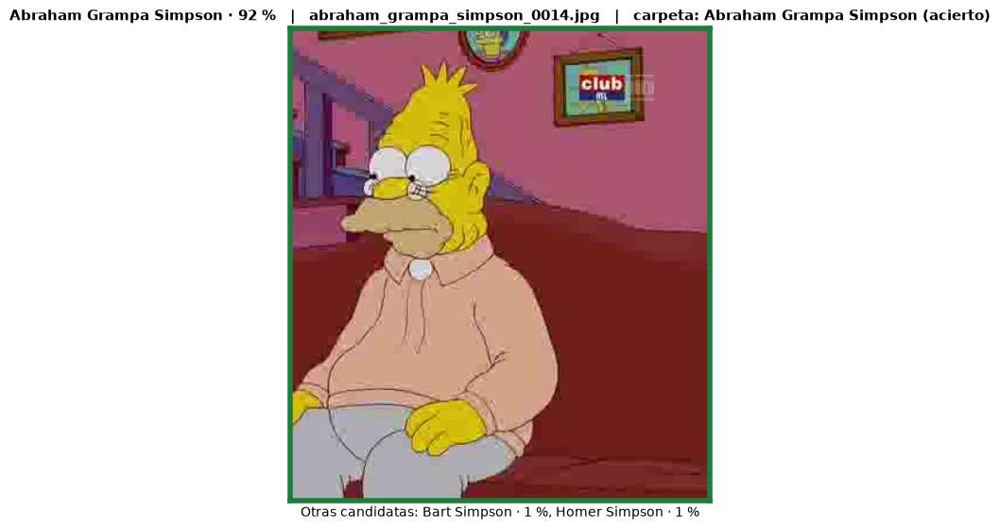

,puesto,personaje,confianza,rotulo
0,1,Abraham Grampa Simpson,0.917,Abraham Grampa Simpson · 92 %
1,2,Bart Simpson,0.010,Bart Simpson · 1 %
2,3,Homer Simpson,0.008,Homer Simpson · 1 %


In [71]:
# Cambia esta ruta por la de la imagen que quieras clasificar y vuelve a ejecutar la celda.
# Por defecto se usa una imagen original de test, que el modelo no vio al entrenar.
if "datos_test" in globals():
    RUTA_IMAGEN = datos_test.loc[~datos_test["alterada"], "ruta"].iloc[0]
else:
    RUTA_IMAGEN = r"C:\ruta\a\una\imagen.jpg"

candidatas_imagen = predecir_imagen(RUTA_IMAGEN)
display(candidatas_imagen)


**Advertencia sobre la interpretación.** La red siempre responde algo: el softmax reparte
probabilidad entre los 64 personajes conocidos y devuelve la mayor, aunque la imagen no contenga a ningún
personaje de Los Simpson. No existe una opción "ninguno de los anteriores". Por eso la confianza es tan
informativa como el nombre: un valor cercano al 100 % indica una decisión clara, mientras que una
ganadora con 15 % frente a candidatas de 12 % significa que el modelo no tiene criterio para decidir.

Conviene recordar también los límites vistos en la evaluación: el modelo reconoce con solidez a los
personajes con muchas imágenes de entrenamiento y falla con frecuencia en los minoritarios, y es sensible
al encuadre y al fondo. Una foto con el personaje pequeño dentro de una escena cargada tiene bastantes
menos probabilidades de clasificarse bien que un primer plano.

## Referencias

**Dataset**

- Alfaro, A. (s. f.). *Los Simpson* [conjunto de datos]. Kaggle.
  https://www.kaggle.com/datasets/alfaro96/los-simpson. Es la base del dataset de este
  notebook, que el equipo amplió a 64 personajes.

**Artículos**

- Simonyan, K., Vedaldi, A. y Zisserman, A. (2014). Deep inside convolutional networks: Visualising image
  classification models and saliency maps. *ICLR 2014, Workshop Track*. https://arxiv.org/abs/1312.6034. Las
  imágenes que maximizan una clase y los mapas de saliencia.
- Yin, H., Molchanov, P., Alvarez, J. M., Li, Z., Mallya, A., Hoiem, D., Jha, N. K. y Kautz, J. (2020). Dreaming
  to distill: Data-free knowledge transfer via DeepInversion. *CVPR 2020*. https://arxiv.org/abs/1912.08795. La
  recreación de cada personaje desde las estadísticas de BatchNorm del modelo.

**Documentación de las librerías utilizadas**

- TensorFlow / Keras — *Keras API reference*. https://keras.io/api/
- TensorFlow / Keras — *The Sequential model*. https://keras.io/guides/sequential_model/
- scikit-learn — *Metrics and scoring*. https://scikit-learn.org/stable/modules/model_evaluation.html
- scikit-learn — `train_test_split`. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- scikit-learn — `compute_class_weight`. https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html
- NumPy — *NumPy documentation*. https://numpy.org/doc/stable/
- pandas — *pandas documentation*. https://pandas.pydata.org/docs/
- Matplotlib — *Matplotlib documentation*. https://matplotlib.org/stable/index.html
- seaborn — *seaborn documentation*. https://seaborn.pydata.org/
- Pillow — *Pillow (PIL Fork) documentation*. https://pillow.readthedocs.io/en/stable/
- scikit-image — *API reference* (`skimage.color`, `skimage.feature`, `skimage.filters`). https://scikit-image.org/docs/stable/api/api.html
- joblib — *Embarrassingly parallel for loops*. https://joblib.readthedocs.io/en/stable/parallel.html

**Material del curso**

- Jerez Salazar, F. J. *1.1.1 El Perceptrón*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.2.1 Redes Fully Connected*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.2.2 Backpropagation*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.3.1 Descenso del Gradiente*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.3.2 Optimizadores*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.4.1 Diseño y Evaluación de Modelos*. Machine Learning, TLY1102.
- Jerez Salazar, F. J. *1.4.2 Implementación con Keras*. Machine Learning, TLY1102.

## Resumen de rendimiento de la corrida en la GPU

Esta última sección no añade nada al modelo: mide **cuánto costó obtenerlo** en la RTX 4060 Laptop. Las
secciones anteriores responden qué tan bien clasifica la red; esta responde cuánto tardó cada etapa y cuánto
de la tarjeta se aprovechó.

Se reportan tres cosas:

1. **El entorno y las marcas de tiempo.** El dispositivo que ejecutó realmente las operaciones, con su
   nombre, el sistema operativo y la versión del framework, además de la resolución de entrada, la **fecha y
   hora de inicio** de la corrida (la fija la primera celda del notebook), la **hora de término** y la
   duración total. Es el dato que da sentido a todos los tiempos.
2. **Los tiempos de la corrida.** Segundos y segundos por época de cada configuración entrenada, más un
   *benchmark* corto de tres épocas sobre la arquitectura base y una medición de inferencia sobre el
   conjunto de test. El benchmark existe porque los tiempos de las secciones anteriores no son
   comparables entre sí: la parada temprana hace que cada configuración corra un número distinto de
   épocas. Entrenar unas pocas épocas con la misma arquitectura, el mismo batch y sin *callbacks* sí da
   una cifra homogénea. De esas épocas se descarta la primera, que incluye la compilación del grafo y el
   traslado inicial de los datos a la tarjeta. Un barrido de tamaño de lote mide además cuánto margen
   queda en la GPU a batch 128.
3. **El resumen de la corrida.** Se guarda en
   `../resultados/newDataset/GPU/rendimiento_gpu_128x128.json`, con las mismas claves que el de la
   CNN, para comparar las dos redes cifra a cifra. Cada corrida reemplaza el archivo de la anterior: la
   del 16-10-2026 queda en el historial de Git, y el final del notebook compara con ella la del 09-11-2026.

Conviene recordar al leer las cifras que un MLP es, capa a capa, una multiplicación de matrices densas:
exactamente el tipo de operación que una GPU paraleliza bien. Con los descriptores, sin embargo, la red es
pequeña para la tarjeta, y buena parte de la corrida se va en cargar las imágenes y calcular los
descriptores, que corre en la CPU antes de llegar a la GPU.

In [72]:
# Resumen de rendimiento de la corrida en la GPU: entorno de ejecución, marcas de tiempo,
# tiempos y métricas finales. Se guarda en
# ../resultados/newDataset/GPU/rendimiento_gpu_128x128.json.
import json
import platform
import subprocess
import threading
import time
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import keras

DIRECTORIO_RESULTADOS = Path("../resultados/newDataset")
DIRECTORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)

# La resolución de entrada forma parte del nombre del archivo.
RESOLUCION = f"{ALTO_OBJETIVO}x{ANCHO_OBJETIVO}"

# La marca de inicio la fija la primera celda del notebook; si esa celda no se
# ejecutó en esta sesión, se toma el arranque de esta sección como referencia.
INICIO_CORRIDA = globals().get("INICIO_CORRIDA") or datetime.now()

# Re-entrena unas pocas épocas para medir un tiempo por época comparable entre
# corridas (misma arquitectura, mismo batch, sin parada temprana). False para omitirlo.
EJECUTAR_BENCHMARK = True
EPOCAS_BENCHMARK = 3

# Barrido de tamaño de lote: evidencia de cuánta GPU queda sin usar a batch 128.
# No cambia la configuración del estudio, solo la mide.
MEDIR_ESCALADO_BATCH = True
BATCHES_A_MEDIR = (128, 256, 512, 1024, 2048)

# --- 1. Entorno de ejecución -------------------------------------------------
def describir_cpu():
    """Nombre del procesador, en Windows y en Linux."""
    if platform.system() == "Windows":
        try:
            nombre = subprocess.run(
                ["wmic", "cpu", "get", "name"], capture_output=True, text=True, timeout=10
            ).stdout.strip().splitlines()
            if len(nombre) > 1 and nombre[1].strip():
                return nombre[1].strip()
        except (OSError, subprocess.SubprocessError):
            pass
        return platform.processor() or platform.machine()
    try:
        for linea in Path("/proc/cpuinfo").read_text().splitlines():
            if linea.startswith("model name"):
                return linea.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()


def describir_gpu():
    """Nombre comercial y capacidad de cómputo de la GPU que ve PyTorch."""
    mayor, menor = torch.cuda.get_device_capability(0)
    return f"{torch.cuda.get_device_name(0)} (CC {mayor}.{menor})"


usa_gpu = torch.cuda.is_available()
ENTORNO = "GPU" if usa_gpu else "CPU"
dispositivo = describir_gpu() if usa_gpu else describir_cpu()

entorno = pd.DataFrame(
    [
        ("Entorno", ENTORNO),
        ("Dispositivo de cómputo", dispositivo),
        ("CPU del equipo", describir_cpu()),
        ("GPUs visibles para PyTorch", torch.cuda.device_count()),
        ("Sistema operativo", f"{platform.system()} {platform.release()}"),
        ("Python", platform.python_version()),
        ("Framework", f"Keras {keras.__version__} sobre PyTorch {torch.__version__}"),
        ("Resolución de trabajo", RESOLUCION),
        ("Entrada del modelo base", f"{REPRESENTACION_BASE} ({DIMENSION_ENTRADA} valores)"),
        ("Entrada del modelo final", f"{representacion_final} ({DIMENSIONES[representacion_final]} valores)"),
        ("Inicio de la corrida", INICIO_CORRIDA.strftime("%Y-%m-%d %H:%M:%S")),
    ],
    columns=["Concepto", "Valor"],
)
display(entorno)


# --- 2. Tiempos de entrenamiento --------------------------------------------
# El tiempo del modelo base lo mide la celda de entrenamiento; si esa celda no se
# volvió a ejecutar, queda como desconocido en lugar de inventar un valor.
segundos_base = float(globals().get("segundos_entrenamiento_base", np.nan))
epocas_base = len(historial_base.history["loss"])

tiempos = tabla_experimentos[["experimento", "epocas", "parametros", "segundos"]].copy()
# El modelo base entra en la tabla de experimentos sin tiempo: se completa aquí
tiempos.loc[tiempos["experimento"].str.startswith("Base"), "segundos"] = segundos_base
tiempos["segundos_por_epoca"] = (tiempos["segundos"] / tiempos["epocas"]).round(2)
tiempos["imagenes_por_segundo"] = (
    len(X_train) * tiempos["epocas"] / tiempos["segundos"]
).round(0)

display(tiempos)

segundos_experimentos = float(
    tabla_experimentos.loc[
        ~tabla_experimentos["experimento"].str.startswith("Base"), "segundos"
    ].sum()
)
segundos_totales = float(np.nansum([segundos_base, segundos_experimentos]))
segundos_por_epoca_medio = float(tiempos["segundos_por_epoca"].mean(skipna=True))
epocas_totales = int(tiempos["epocas"].sum())


# --- 3. Benchmark comparable: entrenamiento e inferencia ---------------------
# Ventana mínima de muestreo. Una época puede durar 0,2 s: medir la utilización
# sobre una sola es leer ruido, así que se repiten épocas hasta cubrir este tiempo.
SEGUNDOS_MINIMOS_MUESTREO = 4.0
INTERVALO_MUESTREO = 0.05


class MuestreadorGPU(threading.Thread):
    """Lee nvidia-smi en paralelo para saber cuánto de la tarjeta se está usando.

    La utilización responde a "¿la GPU está ocupada o esperando?". Ojo: no mide
    potencia entregada. Una tarjeta limitada por consumo puede marcar 100 % y
    rendir la mitad, y dos implementaciones con la misma utilización pueden
    diferir en velocidad si una desperdicia más tiempo dentro de cada paso.
    """

    def __init__(self, intervalo=INTERVALO_MUESTREO):
        super().__init__(daemon=True)
        self.parar = threading.Event()
        self.intervalo = intervalo
        self.muestras = []

    def run(self):
        while not self.parar.is_set():
            try:
                salida = subprocess.run(
                    ["nvidia-smi",
                     "--query-gpu=utilization.gpu,power.draw,clocks.sm",
                     "--format=csv,noheader,nounits"],
                    capture_output=True, text=True, timeout=5,
                ).stdout.strip()
                self.muestras.append(tuple(float(v) for v in salida.split(",")))
            except Exception:
                pass
            time.sleep(self.intervalo)

    def resumen(self):
        """Media sobre la ventana muestreada, con el número de muestras.

        No se descartan lecturas bajas: filtrar por "utilizacion > 5" sesgaría la
        media justo en los casos que interesan, los de tarjeta infrautilizada.
        """
        if len(self.muestras) < 5:
            return {"muestras_utilizacion": len(self.muestras)}
        util, potencia, reloj = (np.array(v) for v in zip(*self.muestras))
        return {
            "utilizacion_gpu_media": round(float(util.mean()), 1),
            "potencia_media_w": round(float(potencia.mean()), 1),
            "reloj_medio_mhz": round(float(reloj.mean())),
            "muestras_utilizacion": len(util),
        }


def cronometrar_epocas(modelo, X, y, batch, epocas, muestrear=False):
    """Entrena `epocas` épocas seguidas y devuelve el tiempo medio por época.

    Se descarta la primera: incluye la reserva de memoria y el calentamiento de
    los kernels, que no se repiten en las siguientes.
    """
    optimizador = torch.optim.Adam(modelo.parameters(), lr=TASA_APRENDIZAJE,
                                   fused=(X.device.type == "cuda"))
    generador = torch.Generator(device=X.device)
    generador.manual_seed(SEMILLA)

    # Fase 1: cronometrar. Se descarta la primera epoca, que incluye la reserva
    # de memoria y el calentamiento de los kernels.
    duraciones = []
    for _ in range(epocas):
        inicio = time.perf_counter()
        _pasada(modelo, X, y, batch, True, optimizador, None, generador)
        if X.device.type == "cuda":
            torch.cuda.synchronize()
        duraciones.append(time.perf_counter() - inicio)
    utiles = duraciones[1:] or duraciones
    segundos_epoca = float(np.mean(utiles))

    # Fase 2: medir la utilizacion en una ventana aparte, lo bastante larga para
    # que el muestreo tenga sentido. Mezclarla con la fase 1 daba medias de dos o
    # tres lecturas cuando la epoca duraba decimas de segundo.
    estado = {}
    if muestrear:
        repeticiones = max(2, int(np.ceil(SEGUNDOS_MINIMOS_MUESTREO / max(segundos_epoca, 1e-6))))
        muestreador = MuestreadorGPU()
        muestreador.start()
        for _ in range(repeticiones):
            _pasada(modelo, X, y, batch, True, optimizador, None, generador)
        if X.device.type == "cuda":
            torch.cuda.synchronize()
        muestreador.parar.set()
        muestreador.join(timeout=2)
        estado = muestreador.resumen()

    return segundos_epoca, estado


benchmark_segundos_epoca = np.nan
estado_gpu = {}
if EJECUTAR_BENCHMARK:
    keras.utils.set_random_seed(SEMILLA)
    modelo_benchmark = construir_mlp(nombre="mlp_benchmark").to(DISPOSITIVO)
    benchmark_segundos_epoca, estado_gpu = cronometrar_epocas(
        modelo_benchmark, X_train, y_train, TAMANO_BATCH, EPOCAS_BENCHMARK, muestrear=True
    )
    del modelo_benchmark
    torch.cuda.empty_cache()

# Inferencia sobre el conjunto de evaluación completo, tras una pasada de calentamiento
modelo_final.predict(X_test[:256], batch_size=256, verbose=0)
inicio_inferencia = time.perf_counter()
modelo_final.predict(X_test, batch_size=256, verbose=0)
segundos_inferencia = time.perf_counter() - inicio_inferencia

filas_benchmark = [
    (
        f"Entrenamiento: segundos por epoca (arquitectura base, batch {TAMANO_BATCH})",
        round(benchmark_segundos_epoca, 2) if EJECUTAR_BENCHMARK else "no ejecutado",
    ),
    (
        "Entrenamiento: imágenes por segundo",
        round(len(X_train) / benchmark_segundos_epoca) if EJECUTAR_BENCHMARK else "-",
    ),
    (
        f"Inferencia: segundos para las {len(X_test):,} imagenes de test",
        round(segundos_inferencia, 2),
    ),
    ("Inferencia: imágenes por segundo", round(len(X_test) / segundos_inferencia)),
]
for clave, etiqueta in (
    ("utilizacion_gpu_media", "GPU: utilización media durante el entrenamiento (%)"),
    ("potencia_media_w", "GPU: potencia media (W)"),
    ("reloj_medio_mhz", "GPU: reloj medio (MHz)"),
):
    if clave in estado_gpu:
        filas_benchmark.append((etiqueta, estado_gpu[clave]))

display(pd.DataFrame(filas_benchmark, columns=["Medicion", "Valor"]))


# --- 3b. Escalado del tamaño de lote ----------------------------------------
# A batch pequeño la GPU pasa más tiempo esperando instrucciones que calculando.
# Esta tabla lo cuantifica sin tocar la configuración con la que se entrenó.
escalado_batch = {}
if MEDIR_ESCALADO_BATCH:
    filas_escalado = []
    for tamano in BATCHES_A_MEDIR:
        keras.utils.set_random_seed(SEMILLA)
        modelo_escalado = construir_mlp(nombre=f"mlp_batch_{tamano}").to(DISPOSITIVO)
        try:
            segundos, estado = cronometrar_epocas(
                modelo_escalado, X_train, y_train, tamano, 3, muestrear=True
            )
            escalado_batch[tamano] = round(len(X_train) / segundos, 1)
            filas_escalado.append({
                "batch": tamano,
                "segundos_por_epoca": round(segundos, 3),
                "imagenes_por_segundo": round(len(X_train) / segundos),
                "utilizacion_gpu_%": estado.get("utilizacion_gpu_media", "-"),
                "potencia_W": estado.get("potencia_media_w", "-"),
            })
        except torch.cuda.OutOfMemoryError:
            filas_escalado.append({"batch": tamano, "segundos_por_epoca": "sin VRAM"})
        del modelo_escalado
        torch.cuda.empty_cache()

    tabla_escalado = pd.DataFrame(filas_escalado)
    display(tabla_escalado)
    if len(escalado_batch) > 1:
        menor, mayor = min(escalado_batch), max(escalado_batch)
        print(
            f"De batch {menor} a batch {mayor} el rendimiento pasa de "
            f"{escalado_batch[menor]:,.0f} a {escalado_batch[mayor]:,.0f} imagenes/s "
            f"(x{escalado_batch[mayor] / escalado_batch[menor]:.1f}). El estudio se hace a "
            f"batch {TAMANO_BATCH} porque es el valor con el que se comparan las corridas; "
            f"esta tabla solo mide cuanto margen queda en la tarjeta."
        )


# --- 4. Resumen de la corrida ------------------------------------------------
# El término se marca aquí, después del benchmark y de la medición de inferencia:
# es el último trabajo real de la corrida.
FIN_CORRIDA = datetime.now()
duracion_corrida_segundos = (FIN_CORRIDA - INICIO_CORRIDA).total_seconds()
duracion_corrida = str(timedelta(seconds=round(duracion_corrida_segundos)))

def cuatro_decimales(valor):
    """Métrica redondeada; la de un subconjunto vacío queda como None (null en el JSON)."""
    return None if np.isnan(valor) else round(float(valor), 4)


resumen_corrida = {
    "entorno": ENTORNO,
    "dispositivo": dispositivo,
    "cpu": describir_cpu(),
    "sistema_operativo": f"{platform.system()} {platform.release()}",
    "framework": "PyTorch",
    "framework_version": torch.__version__,
    "keras": keras.__version__,
    "inicio_corrida": INICIO_CORRIDA.strftime("%Y-%m-%d %H:%M:%S"),
    "fin_corrida": FIN_CORRIDA.strftime("%Y-%m-%d %H:%M:%S"),
    "duracion_corrida": duracion_corrida,
    "duracion_corrida_segundos": round(duracion_corrida_segundos, 1),
    "resolucion": RESOLUCION,
    "dimension_entrada": int(DIMENSION_ENTRADA),
    "representacion_base": REPRESENTACION_BASE,
    "representacion_final": representacion_final,
    "dimension_entrada_final": int(DIMENSIONES[representacion_final]),
    "personajes": int(NUMERO_CLASES),
    "proporciones_train_val_test": " / ".join(f"{PROPORCIONES[nombre]:.0%}" for nombre in CONJUNTOS),
    "esquema_pesos": ESQUEMA_PESOS,
    "suavizado_etiquetas": SUAVIZADO_ETIQUETAS,
    "entrada": "descriptores de la imagen completa",
    "imagenes_train_alteradas": int(datos.loc[MASCARAS["train"], "alterada"].sum()),
    "imagenes_val_alteradas": int(datos.loc[MASCARAS["val"], "alterada"].sum()),
    "imagenes_test_alteradas": int(datos.loc[MASCARAS["test"], "alterada"].sum()),
    "imagenes_parecidas": int(datos["parecida"].sum()),
    "pares_gemelas": int(n_pares_gemelas),
    "segundos_carga_imagenes": round(segundos_carga, 1),
    "segundos_descriptores": round(segundos_descriptores, 1),
    "imagenes_train": int(len(X_train)),
    "imagenes_val": int(len(X_val)),
    "imagenes_test": int(len(X_test)),
    "batch": int(TAMANO_BATCH),
    "configuracion_final": nombre_final,
    "parametros_modelo_final": int(modelo_final.count_params()),
    "epocas_modelo_base": int(epocas_base),
    "segundos_modelo_base": None if np.isnan(segundos_base) else round(segundos_base, 1),
    "segundos_experimentos": round(segundos_experimentos, 1),
    "segundos_entrenamiento_total": round(segundos_totales, 1),
    "epocas_totales": epocas_totales,
    "segundos_por_epoca_medio": round(segundos_por_epoca_medio, 2),
    "benchmark_segundos_por_epoca": (
        None if np.isnan(benchmark_segundos_epoca) else round(benchmark_segundos_epoca, 2)
    ),
    "escalado_batch_imagenes_por_segundo": escalado_batch,
    "segundos_inferencia_test": round(segundos_inferencia, 2),
    "inferencia_imagenes_por_segundo": round(len(X_test) / segundos_inferencia, 1),
    "criterio_acierto": "personaje de la carpeta",
    "errores_confiados_test": int(((predicciones_test != y_test_idx) & (confianza_test > 0.80)).sum()),
    "accuracy_test": round(float(accuracy_test), 4),
    "accuracy_estricta_test": round(float(accuracy_estricta_test), 4),
    "top3_test": round(float(top3_test), 4),
    "accuracy_por_escena_test": round(accuracy_por_escena_test, 4),
    "accuracy_originales_test": cuatro_decimales(accuracy_originales_test),
    "accuracy_parecidas_test": cuatro_decimales(accuracy_parecidas_test),
    "accuracy_alteradas_test": cuatro_decimales(accuracy_alteradas_test),
    "f1_macro_test": round(float(f1_macro_test), 4),
    "f1_macro_estricto_test": round(float(f1_macro_estricto_test), 4),
    "f1_ponderado_test": round(float(f1_ponderado_test), 4),
    "perdida_test": round(float(perdida_test), 4),
    **estado_gpu,
}

# Una carpeta por entorno y un archivo por resolución:
# ../resultados/newDataset/GPU/rendimiento_gpu_128x128.json
directorio_entorno = DIRECTORIO_RESULTADOS / ENTORNO
directorio_entorno.mkdir(parents=True, exist_ok=True)
ruta_resumen = directorio_entorno / f"rendimiento_{ENTORNO.lower()}_{RESOLUCION}.json"
ruta_resumen.write_text(json.dumps(resumen_corrida, indent=2, ensure_ascii=False), encoding="utf-8")

display(
    pd.DataFrame(
        [
            (clave, valor if valor is not None else "desconocido")
            for clave, valor in resumen_corrida.items()
        ],
        columns=["Concepto", "Valor"],
    )
)
print(f"Resumen guardado en: {ruta_resumen.resolve()}")

,Concepto,Valor
0,Entorno,GPU
1,Dispositivo de cómputo,NVIDIA GeForce RTX 4060 Laptop GPU (CC 8.9)
2,CPU del equipo,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
3,GPUs visibles para PyTorch,1
4,Sistema operativo,Windows 11
5,Python,3.13.15
6,Framework,Keras 3.15.1 sobre PyTorch 2.14.0+cu130
7,Resolución de trabajo,128x128
8,Entrada del modelo base,color_textura (2462 valores)
9,Entrada del modelo final,color (370 valores)


,experimento,epocas,parametros,segundos,segundos_por_epoca,imagenes_por_segundo
0,"Base - color_textura (512,256)",40,1411904,105.039118,2.63,18898.0
1,R1 - pixeles,34,25317184,121.000000,3.56,13944.0
2,R2 - solo color,35,340800,98.500000,2.81,17633.0
3,R3 - solo textura,28,1222464,70.100000,2.50,19822.0
4,E1 - 1 capa (512),22,1295936,36.500000,1.66,29911.0
5,"E2 - 3 capas (1024,512,256)",35,3201856,120.900000,3.45,14366.0
6,E3 - activación tanh,27,1411904,63.200000,2.34,21201.0
7,E4 - learning rate 1e-4,35,1411904,87.500000,2.50,19850.0
8,E5 - batch 512,35,1411904,23.100000,0.66,75189.0
9,"E6 - dropout 0,5",35,1411904,93.400000,2.67,18596.0


,Medicion,Valor
0,Entrenamiento: segundos por epoca (arquitectur...,2.1
1,Entrenamiento: imágenes por segundo,23616.0
2,"Inferencia: segundos para las 7,058 imagenes d...",0.1
3,Inferencia: imágenes por segundo,74193.0
4,GPU: utilización media durante el entrenamient...,29.5
5,GPU: potencia media (W),10.6
6,GPU: reloj medio (MHz),813.0


,batch,segundos_por_epoca,imagenes_por_segundo,utilizacion_gpu_%,potencia_W
0,128,2.341,21197,26.3,12.1
1,256,1.149,43203,37.4,10.4
2,512,0.558,88942,36.0,13.7
3,1024,0.298,166716,36.6,18.1
4,2048,0.150,330635,41.1,40.0


De batch 128 a batch 2048 el rendimiento pasa de 21,197 a 330,635 imagenes/s (x15.6). El estudio se hace a batch 128 porque es el valor con el que se comparan las corridas; esta tabla solo mide cuanto margen queda en la tarjeta.


,Concepto,Valor
0,entorno,GPU
1,dispositivo,NVIDIA GeForce RTX 4060 Laptop GPU (CC 8.9)
2,cpu,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
3,sistema_operativo,Windows 11
4,framework,PyTorch
...,...,...
56,perdida_test,1.8402
57,utilizacion_gpu_media,29.5
58,potencia_media_w,10.6
59,reloj_medio_mhz,813


Resumen guardado en: C:\Users\LaptopWin\Desktop\Trabajo\Duoc\3er-Anio\2do Semestre\TECNICAS_ML\Unidad 3\LosSimpsons_DeepLearning\PMC\resultados\newDataset\GPU\rendimiento_gpu_128x128.json


### Corrida con la imagen completa del 09-11-2026

El notebook se ejecutó completo el 09-11-2026 en la GPU a 128 × 128, con la imagen completa, sobre el dataset
ampliado: 64 personajes y 56.676 originales, 16.553 más que en la corrida anterior, del 16-10-2026. La
partición, el framework y el bucle de entrenamiento son los mismos. Cambia el criterio de acierto: el del
16-10-2026 aceptaba además nombrar a otro personaje presente en la escena y usaba la escena en el objetivo de
entrenamiento (con peso 0,15); el actual solo acepta al personaje de la carpeta. Para comparar, la columna del
16-10-2026 usa su accuracy y su F1 macro estrictos. Las cifras salen de
`resultados/newDataset/GPU/rendimiento_gpu_128x128.json`; la versión del 16-10-2026 queda en el historial de Git.

| | 09-11-2026 | 16-10-2026 |
|---|---:|---:|
| Imágenes originales | 56.676 | 40.123 |
| Imágenes de entrenamiento / validación / test | 49.625 / 14.172 / 7.058 | 35.023 / 10.080 / 5.063 |
| Configuración final | C1 - combinación de mejoras | C1 - combinación de mejoras |
| Parámetros del modelo final | 1.059.648 | 1.059.648 |
| Accuracy en test, personaje de la carpeta | 0,544 | 0,539 |
| F1 macro en test, personaje de la carpeta | 0,551 | 0,490 |
| Top-3 en test | 0,736 | 0,751 ¹ |
| Accuracy que acepta a otro personaje presente | 0,632 (por escena, referencia) | 0,586 (criterio de entonces) |
| Accuracy en originales / parecidas / alteradas | 0,55 / 0,62 / 0,47 | 0,57 / 0,71 / 0,53 ¹ |
| Errores con confianza > 0,80 | 261 | 88 ¹ |
| Carga de imágenes + descriptores (min) | 16,1 | 11,0 |
| Entrenamiento total (min) | 20,0 | 15,9 |
| Segundos por época (benchmark) | 2,10 | 1,50 |
| Utilización media de la GPU | 29,5 % | 33,7 % |
| Duración de la corrida | 37 min 34 s | 28 min 14 s |

¹ Con el criterio de entonces, que aceptaba a otro personaje presente: no se compara directamente.

**Conclusiones**

1. **Los KPIs de calidad se cumplen** con el criterio de la carpeta: top-3 de 0,736 (umbral 0,70), F1 macro
   de 0,551 (umbral 0,45), accuracy de 0,544 (umbral 0,50) y 9,8 veces la clase mayoritaria (umbral 4). El de
   costo no: con el cálculo de los descriptores, el sistema procesa 928 imágenes por segundo, por debajo de las
   1.000 del umbral.
2. **Gana la combinación de mejoras**, como el 16-10-2026. C1 toma la entrada de solo color de R2 (370
   histogramas) y las tres capas de E2, con 1.059.648 parámetros, y supera a R2 por 3,9 puntos de F1 macro de
   validación. Comete 261 errores con confianza mayor que 0,80, el 3,7 % del test.
3. **La red es pequeña para la tarjeta.** Con 370 descriptores y batch 128, cada paso es tan corto que la
   GPU pasa la mayor parte del tiempo esperando instrucciones: su utilización media fue del 29,5 % y su
   consumo, de unos 10,6 W. El barrido de tamaño de lote lo confirma: de batch 128 a 2.048, el rendimiento de
   la misma tarjeta se multiplica por 15,6.
4. **El pre-procesamiento pesa casi tanto como el entrenamiento.** Cargar las imágenes y calcular los
   descriptores corre en la CPU y toma 16,1 minutos, el 43 % de la corrida; entrenar el modelo base y sus
   catorce variantes, 20,0.
5. **La inferencia no es un cuello de botella.** La red clasifica las 7.058 imágenes de test en 0,1 s, unas
   74.000 por segundo. El costo real de catalogar una imagen nueva está en calcular sus descriptores: por eso
   el sistema completo se queda en 928 por segundo.
6. **Frente a la corrida del 16-10-2026.** Con el dataset ampliado y el mismo modelo, la accuracy con el
   criterio de la carpeta casi no cambia (de 0,539 a 0,544), y el F1 macro sube 6,1 puntos (de 0,490 a
   0,551): el desempeño se reparte mejor entre los personajes. Con el criterio de cada corrida, la ventaja de
   las parecidas sobre las originales baja de 14,2 a 6,3 puntos, y las alteradas pasan de 3,3 a 8,7 puntos por
   debajo. La corrida tardó 9 minutos más: 5,1 en cargar y describir un 41 % más de imágenes y 4,1 en entrenar
   con ellas.

## Recreación de cada personaje desde el MLP

Las secciones anteriores explican decisiones sobre imágenes de test. Esta hace la pregunta al revés: **¿qué
aprendió la red de cada personaje?** Para responderla se genera una imagen de cada uno de los 64 **solo desde el
modelo**, sin leer ni promediar imágenes del dataset, con la técnica DeepInversion (Yin et al., 2020): se parte de
ruido y se optimizan los píxeles de un lote de 64 imágenes, una por personaje, con tres objetivos:

1. **La clase.** Que cada imagen maximice la clase de su personaje: entropía cruzada sobre los logits de la capa
   `salida`, antes del softmax.
2. **Lo que la red vio al entrenar.** Que la media y la varianza de la entrada de cada BatchNorm, medidas en el
   lote, coincidan con las que esa capa guardó al entrenar (`moving_mean` y `moving_variance`): el promedio del
   entrenamiento que quedó dentro del modelo.
3. **Suavidad.** Variación total y norma L2, más un desplazamiento de hasta 16 píxeles y un volteo al azar en
   cada paso.

Los pesos no cambian: solo se optimizan los píxeles. Después, cada recreación se cuantiza a `uint8` y la
clasifican todas las redes guardadas. Se espera que una red reconozca lo que generó; lo que demuestra el entrenamiento es
que **otra** red, que nunca vio esos gradientes, nombre al mismo personaje. Al azar acertaría 1 de 64 (1,6 %).

**Qué MLP se puede recrear.** El modelo final recibe histogramas de color calculados fuera de la red, sin
gradiente hacia los píxeles, así que no se puede recrear: el script rechaza todo modelo con capa
`Normalization`. El experimento R1 sí recibe los píxeles, aplanados en el mismo orden que `imagenes.reshape(N, -1)`,
y tiene una BatchNorm después de cada capa oculta (`norm_1` y `norm_2`), así que la técnica se aplica igual. Sin
convoluciones, lo esperable es una plantilla de color borrosa: por contraste, muestra lo que la CNN aprendió de la
forma.

**Qué modelos se usan.** Los que ya están en disco, sin reentrenar ninguno. **Solo el MLP genera imágenes**: este
notebook no recrea con el modelo de la CNN, que tiene su propia recreación en el notebook de la CNN. Las dos CNN
solo juzgan lo que generó el MLP y, como no comparten su arquitectura, hacen una prueba cruzada independiente:

| Red | Papel | Modelo | Entrada |
|---|---|---|---|
| MLP, píxeles (R1) | genera y juzga | `PMC/models_gpu/newDataset/mlp_r1.keras`, o `mlp_final.keras` si recibe píxeles | píxeles aplanados |
| CNN, fotograma completo | solo juzga | `CNN/models_gpu/newDataset/cnn_final.keras` | imagen 128 × 128 × 3 |
| CNN, recortes | solo juzga | `CNN/models_gpu/newDataset/cajas/maestra_recortes.keras` | imagen 128 × 128 × 3 |

Si el modelo del MLP no está, la celda se detiene con un aviso, sin mostrar la recreación de otra red. El código
está en `scripts/newDataset/recrear_personajes.py`. Todas las salidas de esta sección quedan en
`PMC/resultados/newDataset/recreaciones/`: un PNG por personaje, la lámina, un JSON con el modelo, su sha256, los
hiperparámetros y la matriz, y las figuras `comparacion.png` y `evolucion.png`, solo con el MLP.

> Celda agregada el 09-11-2026. Carga del disco los modelos guardados, sin reentrenar ninguno y sin leer el
> dataset. No depende de ninguna variable del notebook y se puede ejecutar sola.

Redes: cnn (CNN/models_gpu/newDataset/cnn_final.keras), cnn_recortes (CNN/models_gpu/newDataset/cajas/maestra_recortes.keras), mlp (PMC/models_gpu/newDataset/mlp_r1.keras) | cuda
Generan: mlp | solo juzgan: cnn, cnn_recortes
64 personajes, 2000 pasos, semilla 42


  mlp           desde la caché (PMC/models_gpu/newDataset/recreaciones/mlp_r1_7680a5548dbeec5b.npz)



RECREACION_MODELO generador=mlp sha256=a332f78306840270f79ffada4047ec473966bf05bd34cb129bafef29023e1bf6 segundos=14.6 semilla=42 pasos=2000 personajes=64
RECREACION generador=mlp juez=cnn top1=1/64 top3=2/64 confianza=0.022
RECREACION generador=mlp juez=cnn_recortes top1=2/64 top3=3/64 confianza=0.020
RECREACION generador=mlp juez=mlp top1=30/64 top3=39/64 confianza=0.181
RECREACION_PASO generador=mlp paso=0 top1=1/64 confianza=0.015 mas_nombrado=professor_john_frink:22 confianza_prediccion=0.099
RECREACION_PASO generador=mlp paso=50 top1=5/64 confianza=0.053 mas_nombrado=homer_simpson:11 confianza_prediccion=0.222
RECREACION_PASO generador=mlp paso=200 top1=4/64 confianza=0.051 mas_nombrado=comic_book_guy:8 confianza_prediccion=0.205
RECREACION_PASO generador=mlp paso=500 top1=8/64 confianza=0.058 mas_nombrado=chief_wiggum:5 confianza_prediccion=0.214
RECREACION_PASO generador=mlp paso=2000 top1=30/64 confianza=0.181 mas_nombrado=homer_simpson:5 confianza_prediccion=0.246
RECREACION_

,genera,juzga,prueba,top-1,top-3,probabilidad media del personaje
0,"MLP, píxeles","CNN, fotograma completo",cruzada,1 de 64,2 de 64,0.0223
1,"MLP, píxeles","CNN, recortes",cruzada,2 de 64,3 de 64,0.0202
2,"MLP, píxeles","MLP, píxeles",propia,30 de 64,39 de 64,0.1807


Al azar: top-1 de 1 en 64 (1.6%).
CNN, fotograma completo y CNN, recortes no comparten la arquitectura del MLP: no hay pesos que comparar y la prueba cruzada es independiente.


,red,paso,reconocidas,probabilidad media del personaje,confianza media de su respuesta,personaje que más nombra
0,"MLP, píxeles",0,1 de 64,0.0150,0.0994,professor_john_frink (22 de 64)
1,"MLP, píxeles",50,5 de 64,0.0526,0.2215,homer_simpson (11 de 64)
2,"MLP, píxeles",200,4 de 64,0.0507,0.2047,comic_book_guy (8 de 64)
3,"MLP, píxeles",500,8 de 64,0.0580,0.2137,chief_wiggum (5 de 64)
4,"MLP, píxeles",2000,30 de 64,0.1807,0.2463,homer_simpson (5 de 64)


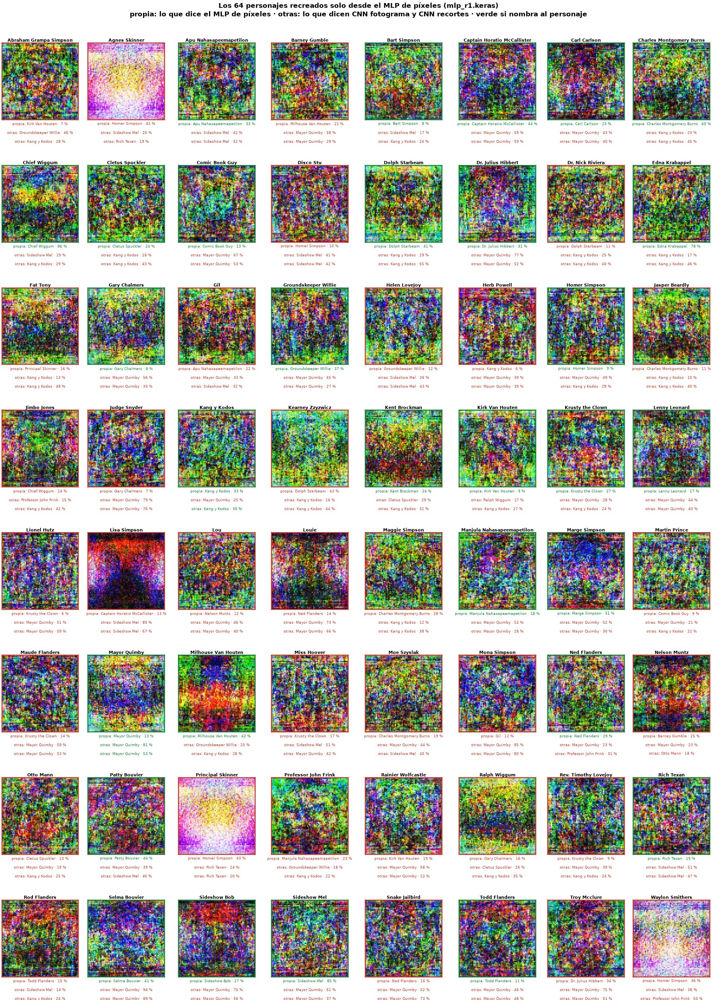

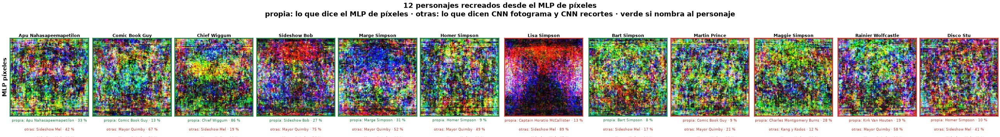

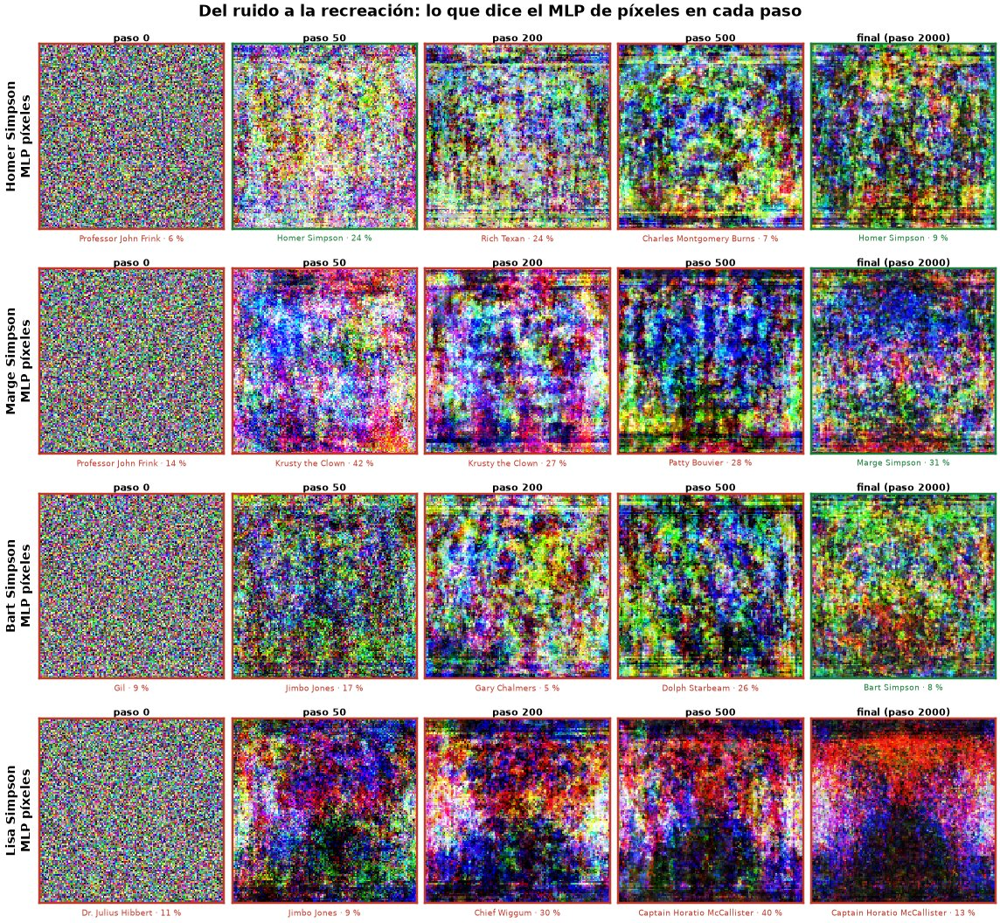

In [74]:
# Recreación de cada personaje solo desde el modelo del MLP guardado (DeepInversion), sin leer el dataset y sin
# reentrenar nada. Celda autocontenida: no usa variables del notebook y se puede ejecutar sola.
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ_REPOSITORIO = next(
    carpeta for carpeta in (Path.cwd(), *Path.cwd().parents)
    if (carpeta / "scripts" / "newDataset" / "recrear_personajes.py").is_file()
)
if str(RAIZ_REPOSITORIO / "scripts" / "newDataset") not in sys.path:
    sys.path.insert(0, str(RAIZ_REPOSITORIO / "scripts" / "newDataset"))
import recrear_personajes

# Solo el MLP de píxeles genera imágenes: este notebook no recrea con el modelo de la CNN, que tiene su propia
# sección en el notebook de la CNN. Las dos CNN guardadas, si están en disco, solo juzgan lo que generó el MLP: son
# la prueba cruzada. Si el MLP no está guardado, la celda se detiene con un aviso en vez de mostrar otra red. Con la
# semilla fija, la recreación sale de la caché si ya se calculó con todo igual
recreacion = recrear_personajes.main(["--generadores", "mlp", "--semilla", "42"])

nombres_redes = {red["id"]: red["nombre"] for red in recreacion["redes"]}
matriz_recreacion = pd.DataFrame(
    [
        {
            "genera": nombres_redes[generador],
            "juzga": nombres_redes[juez],
            "prueba": "propia" if generador == juez else "cruzada",
            "top-1": f"{fila['top1']} de {fila['n']}",
            "top-3": f"{fila['top3']} de {fila['n']}",
            "probabilidad media del personaje": fila["confianza"],
        }
        for generador, jueces in recreacion["matriz"].items()
        for juez, fila in jueces.items()
    ]
)
display(matriz_recreacion)
print(f"Al azar: top-1 de 1 en {round(1 / recreacion['azar'])} ({recreacion['azar']:.1%}).")
jueces_externos = [nombres_redes[r["id"]] for r in recreacion["redes"] if r["id"] not in recreacion["generadores"]]
if jueces_externos and not recreacion["correlaciones"]:
    print(f"{' y '.join(jueces_externos)} no comparten la arquitectura del MLP: no hay pesos que comparar y la "
          "prueba cruzada es independiente.")
for par in recreacion["correlaciones"]:
    print(
        f"Correlación de pesos entre {nombres_redes[par['a']]} y {nombres_redes[par['b']]}: {par['correlacion']:.3f}"
        + (" -> redes independientes" if par["independientes"]
           else " -> una salió de la otra: la prueba cruzada entre ellas no es independiente")
    )

# Del ruido a la recreación: cuántas reconoce como su personaje el MLP en cada instantánea
avance_recreacion = pd.DataFrame(
    [
        {
            "red": nombres_redes[generador],
            "paso": fila["paso"],
            "reconocidas": f"{fila['top1']} de {fila['n']}",
            "probabilidad media del personaje": fila["confianza"],
            "confianza media de su respuesta": fila["confianza_prediccion"],
            "personaje que más nombra": (
                f"{fila['mas_nombrado']} ({fila['veces_mas_nombrado']} de {fila['n']})"
                if fila["veces_mas_nombrado"] > 1 else "ninguno se repite"
            ),
        }
        for generador, filas in recreacion["instantaneas"].items()
        for fila in filas
    ]
)
display(avance_recreacion)


def mostrar(ruta):
    """Muestra una figura del script en JPEG, a su resolución: el notebook pesa un tercio que con el PNG, que
    queda intacto en la carpeta de resultados."""
    import io

    from PIL import Image as ImagenPIL

    memoria = io.BytesIO()
    with ImagenPIL.open(ruta) as figura:
        figura.convert("RGB").save(memoria, "JPEG", quality=85, optimize=True)
    display(Image(data=memoria.getvalue(), format="jpeg"))


# Las tres figuras son solo del MLP y quedan en PMC/resultados/newDataset/recreaciones/
mostrar(recreacion["salidas"]["mlp"]["lamina"])
mostrar(recreacion["comparacion"])
mostrar(recreacion["evolucion"])

**Lectura.** El MLP de píxeles (R1, `mlp_r1.keras`, guardado en la corrida del 09-11-2026) reconoce 30 de las 64
recreaciones que generó (39 de 64 en el top-3), con una probabilidad media de 0,18 para el personaje. Es mucho más
que el azar (1 de 64), pero queda lejos de la CNN, que reconoce las 64 que genera con 0,999: aun optimizando los
píxeles contra sus propios pesos, el MLP no lleva cada imagen con claridad a su personaje.

- **Del ruido a la recreación.** Con ruido puro (paso 0), el MLP nombra a Professor John Frink en 22 de las 64
  imágenes, con una confianza media de 0,10. Avanza despacio: 5 de 64 a los 50 pasos, 4 a los 200, 8 a los 500 y
  30 al final. La CNN ya reconocía 63 de 64 a los 50 pasos.
- **Qué aprendió.** No aparecen formas ni contornos: cada recreación es ruido de alta frecuencia con el color
  repartido por zonas. En algunos personajes la distribución se ve clara: Lisa Simpson, una franja roja arriba
  sobre un centro azul oscuro, y Sideshow Bob, también rojo arriba; Chief Wiggum, una franja amarilla al centro;
  Milhouse, rojo y naranjo en la mitad de abajo con azul encima; en Marge predomina el azul. Agnes Skinner,
  Principal Skinner y Waylon Smithers salen casi iguales, en rosa y blanco con amarillo al centro, y el MLP llama
  Homer Simpson a las tres. Es lo esperable en una red densa: cada neurona de la primera capa tiene un peso por
  píxel y por canal, sin noción de vecindad, así que lo que más la activa es el color correcto en la posición
  correcta, no un borde ni una forma.
- **La prueba cruzada da lo mismo que el azar.** Las dos CNN, que no comparten la arquitectura del MLP, reconocen
  1 y 2 de las 64 recreaciones, y esos aciertos no cuentan: la CNN de fotograma completo llama Mayor Quimby a 36
  de las 64, y la de recortes reparte casi todas entre Mayor Quimby (26) y Kang y Kodos (25). Las CNN responden a
  estas imágenes como a ruido. Sugiere que lo que el MLP usa para separar a los personajes, color en posiciones
  fijas, no es lo que usa la CNN, que se apoya en rasgos con forma.
- **Los hiperparámetros son los de la CNN.** Son el punto de partida de DeepInversion con la variación total
  ajustada en el piloto de la CNN, y se aplicaron al MLP sin cambios. En el MLP, al final de los 2.000 pasos, el
  término de BatchNorm aporta 39,4 de los 43,8 de la pérdida total y la entropía cruzada sigue en 2,76; en la CNN,
  la pérdida total termina en 0,35. Un α_bn más bajo para el MLP podría subir los 30 de 64, pero no se probó.